In [1]:
import pandas as pd
import numpy as np
import torch

import re
import os
import matplotlib.pyplot as plt
import pickle 
from typing import Dict, List, Tuple, Union

from sklearn.decomposition import FactorAnalysis

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path
import torch
from typing import Dict, List, Optional, Tuple, Union
import logging

logger = logging.getLogger(__name__)
# from lightning_pose.data.cameras import CameraGroup
from aniposelib.cameras import CameraGroup

from lightning_pose.utils.pca import  NaNPCA, format_multiview_data_for_pca # maybe want NanFA later on 
from lp3d_analysis.post_process import process_predictions 
from lp3d_analysis.plot import generate_paths_with_models_and_ensembles
from lp3d_analysis.io import load_cfgs

INFO:2026-03-04 21:52:51,098:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:2026-03-04 21:52:51,104:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


In [2]:
# Set up the dataset you want to work with 
cfg_pipe , cfg_lp = load_cfgs('/teamspace/studios/this_studio/lp3d-analysis/configs/pipeline.yaml')
dataset_name = 'fly-anipose'
views = ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E', 'Cam-F']

# dataset_name = 'mirror-mouse-separate'
# views =['bot','top']

seed_dirs = ['0', '1', '2']
ensemble_seed = '0-2'
ensemble_methods = ['eks_multiview_varinf', 'non_linear_eks_varinf', 'ensemble_median', 'non_linear_eks','eks_multiview']
video_dir = 'videos_new'
results_dirs = [
    'test_200_MVT_3d_loss_patch_masking',
    'test_200_SV_vits_dino', 
    'test_200_multiview_resnet50'
]
model_type = 'mvt_3d_loss'
n_hand_labels = '200'

results_configs = {
    'test_200_MVT_3d_loss_patch_masking': {
        'model_type': 'mvt_3d_loss', 
        'n_hand_labels': '200'
    },
    'test_200_SV_vits_dino': {
        'model_type': 'supervised',  # or whatever the correct model_type is
        'n_hand_labels': '200'
    },
    'test_200_multiview_resnet50': {
        'model_type': 'supervised',  # or whatever the correct model_type is
        'n_hand_labels': '200'
    },
    # 'test_200_MVT_3d_aug': {
    #     'model_type': 'multiview_transformer',   # or whatever the correct model_type is
    #     'n_hand_labels': '200'
    # }
}

skeleton = cfg_lp.data.skeleton 
camera_params_dir = f'/teamspace/studios/data/{dataset_name}/calibrations'

In [3]:
def find_prediction_files(base_dir: str, view: str) -> List[str]:
    """
    Find all prediction files for a given view in a directory.
    
    Parameters:
    -----------
    base_dir : str
        Base directory to search in
    view : str
        View name to match
        
    Returns:
    --------
    List[str]
        List of matching file paths
    """
    if not os.path.exists(base_dir):
        return []
    
    matching_files = []
    
    # Look for files that contain the view name
    for file in os.listdir(base_dir):
        if file.endswith('.csv') and view in file:
            matching_files.append(os.path.join(base_dir, file))
    
    return sorted(matching_files)  # Sort for consistent ordering

In [4]:
def extract_session_info(filename: str, views: List[str]) -> Tuple[str, str]:
    """
    Extract session name and view from filename.
    """
    name = filename.replace('.csv', '')
    
    # Find matching view name
    view_name = next((view for view in views if view in name), name.split('_')[-1])
    
    # Remove view name to get session name
    session_name = name.replace(f'_{view_name}', '')
    
    return session_name, view_name

def generate_comprehensive_paths_multi_results(
    dataset_name: str,
    views: List[str],
    results_configs: Union[List[str], Dict[str, Dict]],  # Now accepts configs per results dir
    video_dir: str,
    seed_dirs: List[str],
    ensemble_seed: str = None,
    ensemble_methods: List[str] = None,
    n_hand_labels: str = "200",
    include_seeds: bool = True,
    include_ensembles: bool = True,
    base_path: str = "/teamspace/studios",
    data_dir: str = "data",
    studio_dir: str = "this_studio",
    output_dir: str = "outputs",
):
    """
    Generate comprehensive paths for multiple results directories with different model types.
    
    Parameters:
    -----------
    results_configs : Union[List[str], Dict[str, Dict]]
        Either a list of results directory names (uses default model_type),
        or a dict mapping results_dir -> {'model_type': str, 'n_hand_labels': str}
    """
    
    # Convert simple list to config dict if needed
    if isinstance(results_configs, list):
        # Default model_type - you'll need to specify the correct one
        default_model_type = "mvt_3d_loss"  
        results_configs = {
            results_dir: {'model_type': default_model_type, 'n_hand_labels': n_hand_labels}
            for results_dir in results_configs
        }
    
    # Ground truth paths (unchanged)
    In_Dist_paths = {
        view: os.path.join(base_path, data_dir, dataset_name, f'remapped_CollectedData_{view}.csv')
        for view in views
    }
    
    if not Path(In_Dist_paths[views[0]]).is_file():
        In_Dist_paths = {
            view: os.path.join(base_path, data_dir, dataset_name, f'CollectedData_{view}.csv')
            for view in views
        }
    
    Out_Dist_paths = {
        view: os.path.join(base_path, data_dir, dataset_name, f'remapped_CollectedData_{view}_new.csv')
        for view in views
    }
    
    if not Path(Out_Dist_paths[views[0]]).is_file():
        Out_Dist_paths = {
            view: os.path.join(base_path, data_dir, dataset_name, f'CollectedData_{view}_new.csv')
            for view in views
        }
    
    # Initialize combined file paths structure
    all_file_paths_combined = {}
    
    # Process each results directory with its specific config
    for results_dir, config in results_configs.items():
        model_type = config['model_type']
        n_labels = config['n_hand_labels']
        
        print(f"\n=== Processing results directory: {results_dir} ===")
        print(f"    Model type: {model_type}, Labels: {n_labels}")
        
        # Collect all prediction directories for this results_dir
        all_prediction_dirs = []
        
        # Individual seed predictions (if requested)
        if include_seeds and seed_dirs:
            for seed in seed_dirs:
                pred_dir = os.path.join(
                    base_path, studio_dir, output_dir, dataset_name, results_dir,
                    f"{model_type}_{n_labels}_{seed}", video_dir
                )
                print(f"  Checking seed dir: {pred_dir}")
                if os.path.exists(pred_dir):
                    model_name = f"{results_dir}_seed_{seed}"
                    all_prediction_dirs.append((model_name, pred_dir))
                    print(f"    EXISTS: Added {model_name}")
                else:
                    print(f"    NOT FOUND: {pred_dir}")
        
        # Ensemble predictions (if requested)
        if include_ensembles and ensemble_methods and ensemble_seed:
            for method in ensemble_methods:
                pred_dir = os.path.join(
                    base_path, studio_dir, output_dir, dataset_name, results_dir,
                    f"{model_type}_{n_labels}_{ensemble_seed}", method, video_dir
                )
                print(f"  Checking ensemble dir: {pred_dir}")
                if os.path.exists(pred_dir):
                    model_name = f"{results_dir}_{method}"
                    all_prediction_dirs.append((model_name, pred_dir))
                    print(f"    EXISTS: Added {model_name}")
                else:
                    print(f"    NOT FOUND: {pred_dir}")
        
        print(f"  Total directories found for {results_dir}: {len(all_prediction_dirs)}")
        
        if len(all_prediction_dirs) == 0:
            print(f"  WARNING: No directories found for {results_dir}!")
            continue
        
        # Process files from each prediction directory
        for model_name, pred_dir in all_prediction_dirs:
            print(f"  Processing {model_name}: {pred_dir}")
            
            # Find all CSV files
            all_csvs = []
            if os.path.exists(pred_dir):
                all_csvs = [f for f in os.listdir(pred_dir) if f.endswith('.csv')]
            
            print(f"    Found {len(all_csvs)} CSV files")
            
            # Group files by session
            for csv_file in all_csvs:
                # Skip uncropped files
                if '_uncropped' in csv_file:
                    continue
                    
                full_path = os.path.join(pred_dir, csv_file)
                
                # Extract session name and view
                session_name, view_name = extract_session_info(csv_file, views)
                
                # Verify this view is expected
                if view_name not in views:
                    continue
                
                if session_name and view_name:
                    # Initialize nested dictionaries
                    if session_name not in all_file_paths_combined:
                        all_file_paths_combined[session_name] = {view: {} for view in views}
                    
                    # Store the file path
                    all_file_paths_combined[session_name][view_name][model_name] = full_path
                    print(f"      Added {session_name} -> {view_name} -> {model_name}")
    
    print(f"Total sessions found: {len(all_file_paths_combined)}")
    
    # Filter sessions with sufficient views
    filtered_sessions = {}
    for session_name, session_data in all_file_paths_combined.items():
        valid_views = [v for v in views if session_data[v]]
        if len(valid_views) >= 2:
            filtered_sessions[session_name] = session_data
            print(f"Keeping session '{session_name}' with {len(valid_views)} views")
    
    print(f"Final result: {len(filtered_sessions)} sessions with sufficient data")
    
    return In_Dist_paths, Out_Dist_paths, filtered_sessions

In [5]:
In_Dist_paths, Out_Dist_paths, all_file_paths = generate_comprehensive_paths_multi_results(
    dataset_name, views, results_configs, video_dir, 
    seed_dirs, ensemble_seed=ensemble_seed, ensemble_methods=ensemble_methods,
    include_seeds=True, include_ensembles=True
)


=== Processing results directory: test_200_MVT_3d_loss_patch_masking ===
    Model type: mvt_3d_loss, Labels: 200
  Checking seed dir: /teamspace/studios/this_studio/outputs/fly-anipose/test_200_MVT_3d_loss_patch_masking/mvt_3d_loss_200_0/videos_new
    EXISTS: Added test_200_MVT_3d_loss_patch_masking_seed_0
  Checking seed dir: /teamspace/studios/this_studio/outputs/fly-anipose/test_200_MVT_3d_loss_patch_masking/mvt_3d_loss_200_1/videos_new
    EXISTS: Added test_200_MVT_3d_loss_patch_masking_seed_1
  Checking seed dir: /teamspace/studios/this_studio/outputs/fly-anipose/test_200_MVT_3d_loss_patch_masking/mvt_3d_loss_200_2/videos_new
    EXISTS: Added test_200_MVT_3d_loss_patch_masking_seed_2
  Checking ensemble dir: /teamspace/studios/this_studio/outputs/fly-anipose/test_200_MVT_3d_loss_patch_masking/mvt_3d_loss_200_0-2/eks_multiview_varinf/videos_new
    EXISTS: Added test_200_MVT_3d_loss_patch_masking_eks_multiview_varinf
  Checking ensemble dir: /teamspace/studios/this_studio/outp

In [6]:
def load_camera_parameters(session_name: str, camera_params_dir: str) -> Optional[object]:
    """
    Load camera parameters for a session.
    
    Parameters:
    -----------
    session_name : str
        Name of the session
    camera_params_dir : str
        Directory containing camera parameter files
        
    Returns:
    --------
    camera_group : CameraGroup or similar object
        Camera parameters for triangulation
    """
    # Remove .short from session name for calibration files
    base_session_name = session_name.replace('.short', '')
    camera_params_file = Path(camera_params_dir) / f"{base_session_name}.toml"
    
    try:
        # Assuming you have a CameraGroup.load method - adjust import as needed
        camera_group = CameraGroup.load(str(camera_params_file))
        logger.info(f"Loaded camera parameters for session: {base_session_name}")
        return camera_group
    except Exception as e:
        logger.error(f"Failed to load camera parameters for {base_session_name}: {e}")
        return None


In [7]:
def organize_multiview_data(
    file_paths: Dict[str, str], 
    include_likelihood: bool = False, 
    include_variance: bool = False,
    include_posterior_variance: bool = False,
) -> Union[Tuple[torch.Tensor, List[List[int]], int, List[str]], Tuple[torch.Tensor, torch.Tensor, List[List[int]], int, List[str]]]:
    """
    Organize multiview data into format required for triangulation.
    
    Args:
        file_paths: Dictionary mapping view names to file paths
        include_likelihood: Whether to include likelihood scores
        include_variance: Whether to include variance scores
    
    Returns:
        If `include_variance` is False:
            - Tensor of shape (n_labeled_frames, n_keypoints * n_views, 2) for (x, y) coordinates
            - mirrored_column_matches list of lists for indexing
            - Number of frames
            - List of keypoint names
        If `include_variance` is True:
            - Additionally returns a tensor of shape (n_labeled_frames, n_keypoints * n_views, 2) for (x_ens_var, y_ens_var) ensemble variances
    """
    views_position_data = {}
    views_variance_data = {} 
    keypoint_names = None
    n_frames = None 

    # Process each view's data
    for view, filepath in file_paths.items():
        col_struct, array_data, numeric_cols, kp_names, df_index = process_predictions(
            filepath, 
            include_likelihood=include_likelihood,
            include_variance=include_variance,
            include_posterior_variance=include_posterior_variance,
        )

        if array_data is None:
            raise ValueError(f"Could not process data for view {view}")
        
        # Separate position data (x, y) and variance data if needed
        position_cols = numeric_cols.loc[:, numeric_cols.columns.get_level_values(2).isin(['x', 'y'])]
        position_array = position_cols.to_numpy()
        views_position_data[view] = position_array

        if include_variance:
            variance_cols = numeric_cols.loc[:, numeric_cols.columns.get_level_values(2).isin(['x_ens_var', 'y_ens_var'])]
            variance_array = variance_cols.to_numpy()
            views_variance_data[view] = variance_array
        elif include_posterior_variance:
            variance_cols = numeric_cols.loc[:, numeric_cols.columns.get_level_values(2).isin(['x_posterior_var', 'y_posterior_var'])]
            variance_array = variance_cols.to_numpy()
            views_variance_data[view] = variance_array

        # Verify consistent keypoints across views 
        if keypoint_names is None:
            keypoint_names = kp_names
            n_frames = len(df_index)
        else:
            if kp_names != keypoint_names:
                raise ValueError(f"Inconsistent keypoint names in view {view}")
            if len(df_index) != n_frames:
                raise ValueError(f"Inconsistent number of frames in view {view}")

    n_keypoints = len(keypoint_names)
    n_views = len(file_paths)

    # Initialize output tensors
    output_tensor = torch.zeros((n_frames, n_keypoints * n_views, 2))
    variance_tensor = torch.zeros((n_frames, n_keypoints * n_views, 2)) if (include_variance or include_posterior_variance) else None

    # Create mirrored_column_matches
    mirrored_column_matches = []
    for view_idx in range(n_views):
        view_indices = list(range(view_idx * n_keypoints, (view_idx + 1) * n_keypoints))
        mirrored_column_matches.append(view_indices)

    # Fill output tensors
    for view_idx, (view, position_data) in enumerate(views_position_data.items()):
        # Reshape data to (n_frames, n_keypoints, 2) for (x, y)
        position_view_data = position_data.reshape(n_frames, n_keypoints, -1)[:, :, :2]
        output_tensor[:, view_idx * n_keypoints:(view_idx + 1) * n_keypoints, :] = torch.tensor(position_view_data)

        # Only try to process variance data if the tensor exists and we have data for this view
        if variance_tensor is not None and view in views_variance_data:
            variance_view_data = views_variance_data[view].reshape(n_frames, n_keypoints, -1)[:, :, :2]
            variance_tensor[:, view_idx * n_keypoints:(view_idx + 1) * n_keypoints, :] = torch.tensor(variance_view_data)

    if include_variance or include_posterior_variance:
        return output_tensor, variance_tensor, mirrored_column_matches, n_frames, keypoint_names
    else:
        return output_tensor, mirrored_column_matches, n_frames, keypoint_names

In [8]:
def load_session_data(file_paths: Dict[str, str], session_name: str, camera_params_dir: str) -> Tuple[torch.Tensor, Optional[object], int, List[str]]:
    """
    Load 2D prediction data and camera parameters for a session.
    
    Parameters:
    -----------
    file_paths : Dict[str, str]
        Dictionary mapping view names to file paths for this session
    session_name : str
        Name of the session
    camera_params_dir : str
        Directory containing camera parameter files
        
    Returns:
    --------
    data_tensor : torch.Tensor
        2D keypoint predictions tensor of shape (n_frames, n_keypoints * n_views, 2)
    camera_group : object
        Camera parameters for triangulation
    n_frames : int
        Number of frames
    keypoint_names : List[str]
        List of keypoint names
    """
    # Load 2D predictions
    data_tensor, mirrored_column_matches, n_frames, keypoint_names = organize_multiview_data(
        file_paths, 
        include_likelihood=False,  # We don't need likelihood for triangulation
        include_variance=False
    )
    
    # Load camera parameters
    camera_group = load_camera_parameters(session_name, camera_params_dir)
    
    return data_tensor, camera_group, n_frames, keypoint_names

In [9]:
def triangulate_keypoints(data_tensor: torch.Tensor, camera_group: object, 
                        keypoint_names: List[str], views: List[str]) -> np.ndarray:
    """
    Triangulate 2D keypoints to 3D coordinates.
    
    Parameters:
    -----------
    data_tensor : torch.Tensor
        2D keypoint data of shape (n_frames, n_keypoints * n_views, 2)
    camera_group : object
        Camera parameters for triangulation
    keypoint_names : List[str]
        List of keypoint names
    views : List[str]
        List of view names
        
    Returns:
    --------
    points_3d : np.ndarray
        3D triangulated points of shape (n_frames, n_keypoints, 3)
    """
    n_frames, n_keypoints_views, _ = data_tensor.shape
    n_keypoints = len(keypoint_names)
    n_views = len(views)
    
    # Initialize 3D points array
    points_3d = np.full((n_frames, n_keypoints, 3), np.nan)
    
    # Reshape data for easier access: (n_frames, n_keypoints, n_views, 2)
    reshaped_data = data_tensor.view(n_frames, n_keypoints, n_views, 2).numpy()
    
    # Process each frame
    for frame_idx in range(n_frames):
        # Collect valid 2D points for all keypoints across views
        keypoints_2d_all_views = []
        valid_view_indices = []
        
        # Check which views have valid data for this frame
        for view_idx, view_name in enumerate(views):
            frame_keypoints = reshaped_data[frame_idx, :, view_idx, :]  # All keypoints for this view
            
            # Check if this view has valid keypoints (not all NaN)
            if not np.all(np.isnan(frame_keypoints)):
                keypoints_2d_all_views.append(frame_keypoints)
                valid_view_indices.append(view_idx)
        
        # Triangulate if we have at least 2 valid views
        if len(keypoints_2d_all_views) >= 2:
            try:
                # Stack the 2D keypoints: shape (n_valid_views, n_keypoints, 2)
                keypoints_2d_stacked = np.stack(keypoints_2d_all_views)
                
                # Use your triangulate_fast method
                # keypoints_3d = camera_group.triangulate_fast(keypoints_2d_stacked, undistort=True)
                keypoints_3d = camera_group.triangulate(keypoints_2d_stacked, fast=True)
                
                # Store the 3D points
                points_3d[frame_idx, :, :] = keypoints_3d
                
            except Exception as e:
                logger.warning(f"Triangulation failed for frame {frame_idx}: {e}")
                continue
    
    return points_3d

In [10]:
def calculate_limb_lengths_3d(points_3d: np.ndarray, keypoint_names: List[str], 
                            skeleton: List[Tuple[str, str]]) -> Dict[str, np.ndarray]:
    """
    Calculate limb lengths from 3D triangulated points.
    
    Parameters:
    -----------
    points_3d : np.ndarray
        3D points of shape (n_frames, n_keypoints, 3)
    keypoint_names : List[str]
        List of keypoint names
    skeleton : List[Tuple[str, str]]
        List of limb connections
        
    Returns:
    --------
    limb_lengths : Dict[str, np.ndarray]
        Dictionary mapping limb names to length arrays
    """
    n_frames, n_keypoints, _ = points_3d.shape
    
    # Create keypoint name to index mapping
    keypoint_to_idx = {name: idx for idx, name in enumerate(keypoint_names)}
    
    limb_lengths = {}
    
    for start_kp, end_kp in skeleton:
        if start_kp not in keypoint_to_idx or end_kp not in keypoint_to_idx:
            logger.warning(f"Keypoint {start_kp} or {end_kp} not found in data. Skipping.")
            continue
            
        start_idx = keypoint_to_idx[start_kp]
        end_idx = keypoint_to_idx[end_kp]
        
        # Calculate distances for all frames
        start_points = points_3d[:, start_idx, :]  # (n_frames, 3)
        end_points = points_3d[:, end_idx, :]      # (n_frames, 3)
        
        # Calculate Euclidean distances
        distances = np.full(n_frames, np.nan)
        
        for frame_idx in range(n_frames):
            if not (np.any(np.isnan(start_points[frame_idx])) or np.any(np.isnan(end_points[frame_idx]))):
                distances[frame_idx] = np.linalg.norm(end_points[frame_idx] - start_points[frame_idx])
        
        limb_name = f"{start_kp}-{end_kp}"
        limb_lengths[limb_name] = distances
    
    return limb_lengths

In [11]:
def analyze_limb_motion(limb_lengths: Dict[str, np.ndarray]) -> Dict[str, Dict]:
    """
    Calculate comprehensive statistics for limb motion.
    
    Parameters:
    -----------
    limb_lengths : Dict[str, np.ndarray]
        Dictionary mapping limb names to length arrays
        
    Returns:
    --------
    stats : Dict[str, Dict]
        Statistics for each limb
    """
    stats = {}
    
    for limb_name, lengths in limb_lengths.items():
        valid_lengths = lengths[~np.isnan(lengths)]
        n_valid = len(valid_lengths)
        
        if n_valid == 0:
            stats[limb_name] = {
                'mean': np.nan, 'std': np.nan, 'min': np.nan, 'max': np.nan,
                'range': np.nan, 'coefficient_of_variation': np.nan,
                'n_frames': len(lengths), 'n_valid_frames': 0,
                'variance': np.nan, 'standard_error': np.nan, 'frequency': np.nan
            }
            continue
        
        mean_val = np.mean(valid_lengths)
        std_val = np.std(valid_lengths)
        
        stats[limb_name] = {
            'mean': mean_val,
            'std': std_val,
            'min': np.min(valid_lengths),
            'max': np.max(valid_lengths),
            'range': np.max(valid_lengths) - np.min(valid_lengths),
            'coefficient_of_variation': std_val / mean_val if mean_val != 0 else np.nan,
            'n_frames': len(lengths),
            'n_valid_frames': n_valid,
            'variance': std_val**2,
            'standard_error': std_val / np.sqrt(n_valid) if n_valid > 0 else np.nan
        }
        
        # Calculate dominant frequency using FFT
        if n_valid > 20:
            detrended = valid_lengths - mean_val
            windowed = detrended * np.hanning(len(detrended))
            fft = np.fft.fft(windowed)
            freqs = np.fft.fftfreq(len(windowed))
            
            power = np.abs(fft[1:len(fft)//2])
            if len(power) > 0:
                dominant_freq_idx = np.argmax(power) + 1
                stats[limb_name]['frequency'] = freqs[dominant_freq_idx]
            else:
                stats[limb_name]['frequency'] = 0
        else:
            stats[limb_name]['frequency'] = np.nan
    
    return stats

In [12]:
def process_session(file_paths: Dict[str, str], session_name: str, 
                   camera_params_dir: str, skeleton: List[Tuple[str, str]], 
                   views: List[str]) -> Tuple[Dict[str, np.ndarray], np.ndarray]:
    """
    Process a complete session: load data, triangulate, calculate limb lengths.
    
    Parameters:
    -----------
    file_paths : Dict[str, str]
        Dictionary mapping view names to file paths
    session_name : str
        Name of the session
    camera_params_dir : str
        Directory containing camera parameter files
    skeleton : List[Tuple[str, str]]
        List of limb connections
    views : List[str]
        List of view names
        
    Returns:
    --------
    limb_lengths : Dict[str, np.ndarray]
        Dictionary of limb lengths over time
    points_3d : np.ndarray
        3D triangulated keypoints
    """
    # Load 2D data and camera parameters
    data_tensor, camera_group, n_frames, keypoint_names = load_session_data(
        file_paths, session_name, camera_params_dir
    )
    
    if camera_group is None:
        raise ValueError(f"Could not load camera parameters for session {session_name}")
    
    # Triangulate to 3D
    points_3d = triangulate_keypoints(data_tensor, camera_group, keypoint_names, views)
    
    # Calculate limb lengths
    limb_lengths = calculate_limb_lengths_3d(points_3d, keypoint_names, skeleton)
    
    return limb_lengths, points_3d

In [13]:
def plot_limb_analysis_dashboard(limb_lengths: Dict[str, np.ndarray], 
                               session_name: str = "", output_path: str = None, 
                               figsize: Tuple[int, int] = (18, 10)):
    """
    Create dashboard plot for limb analysis results.
    
    Parameters:
    -----------
    limb_lengths : Dict[str, np.ndarray]
        Dictionary of limb lengths
    session_name : str
        Name of session for title
    output_path : str, optional
        Path to save figure
    figsize : Tuple[int, int]
        Figure size
        
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object
    """
    n_limbs = len(limb_lengths)
    stats_data = analyze_limb_motion(limb_lengths)
    
    # Create subplot layout
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(3, min(n_limbs, 4), figure=fig, hspace=0.4, wspace=0.3)
    
    # Main time series plot (top row)
    ax_main = fig.add_subplot(gs[0, :])
    
    colors = plt.cm.tab10(np.linspace(0, 1, n_limbs))
    for i, (limb_name, lengths) in enumerate(limb_lengths.items()):
        frames = np.arange(len(lengths))
        valid_mask = ~np.isnan(lengths)
        
        if np.any(valid_mask):
            ax_main.plot(frames[valid_mask], lengths[valid_mask], 
                       label=limb_name, color=colors[i], linewidth=1.5, alpha=0.8)
    
    ax_main.set_xlabel('Frame')
    ax_main.set_ylabel('Limb Length (3D units)')
    ax_main.set_title(f'3D Triangulated Limb Length Traces - {session_name}')
    ax_main.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    ax_main.grid(True, alpha=0.3)
    
    # Individual limb plots
    limb_items = list(limb_lengths.items())
    max_plots_per_row = min(n_limbs, 4)
    
    # First row of individual plots
    for i in range(min(max_plots_per_row, n_limbs)):
        limb_name, lengths = limb_items[i]
        ax_individual = fig.add_subplot(gs[1, i])
        
        frames = np.arange(len(lengths))
        valid_mask = ~np.isnan(lengths)
        
        if np.any(valid_mask):
            ax_individual.plot(frames[valid_mask], lengths[valid_mask], 
                             color=colors[i], linewidth=1.5)
            
            stats = stats_data[limb_name]
            mean_val = stats['mean']
            std_val = stats['std']
            
            if not np.isnan(mean_val):
                ax_individual.axhline(mean_val, color='red', linestyle='--', 
                                    linewidth=1, alpha=0.8, label=f'Mean: {mean_val:.3f}')
                
                if not np.isnan(std_val):
                    ax_individual.fill_between(frames, mean_val - std_val, mean_val + std_val,
                                             color='red', alpha=0.2, label=f'±1σ: {std_val:.3f}')
        
        ax_individual.set_xlabel('Frame')
        ax_individual.set_ylabel('Length')
        ax_individual.set_title(f'{limb_name}')
        ax_individual.grid(True, alpha=0.3)
        ax_individual.legend(fontsize=8)
    
    # Second row if needed
    if n_limbs > max_plots_per_row:
        for i in range(max_plots_per_row, min(2 * max_plots_per_row, n_limbs)):
            limb_name, lengths = limb_items[i]
            ax_individual = fig.add_subplot(gs[2, i - max_plots_per_row])
            
            frames = np.arange(len(lengths))
            valid_mask = ~np.isnan(lengths)
            
            if np.any(valid_mask):
                ax_individual.plot(frames[valid_mask], lengths[valid_mask], 
                                 color=colors[i], linewidth=1.5)
                
                stats = stats_data[limb_name]
                mean_val = stats['mean']
                std_val = stats['std']
                
                if not np.isnan(mean_val):
                    ax_individual.axhline(mean_val, color='red', linestyle='--', 
                                        linewidth=1, alpha=0.8, label=f'Mean: {mean_val:.3f}')
                    
                    if not np.isnan(std_val):
                        ax_individual.fill_between(frames, mean_val - std_val, mean_val + std_val,
                                                 color='red', alpha=0.2, label=f'±1σ: {std_val:.3f}')
            
            ax_individual.set_xlabel('Frame')
            ax_individual.set_ylabel('Length')
            ax_individual.set_title(f'{limb_name}')
            ax_individual.grid(True, alpha=0.3)
            ax_individual.legend(fontsize=8)
    
    plt.tight_layout()
    
    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
    
    return fig

In [14]:
def plot_model_cv_comparison(all_file_paths: Dict, cfg_lp, views: List[str], 
                           models_to_compare: List[str], camera_params_dir: str,
                           session_name: str = None, figsize: Tuple[int, int] = (15, 6)):
    """
    Clean comparison of coefficient of variation across models.
    """
    skeleton = cfg_lp.data.skeleton
    
    # Select session
    if session_name is None:
        session_name = next(iter(all_file_paths.keys()))
    
    if session_name not in all_file_paths:
        raise ValueError(f"Session {session_name} not found in file paths")
    
    session_data = all_file_paths[session_name]
    
    # Process each model
    model_results = {}
    
    for model_name in models_to_compare:
        model_file_paths = {}
        for view in views:
            if view in session_data and model_name in session_data[view]:
                model_file_paths[view] = session_data[view][model_name]
        
        if len(model_file_paths) < 2:
            print(f"Skipping model {model_name} - insufficient views")
            continue
        
        try:
            limb_lengths, points_3d = process_session(
                model_file_paths, session_name, camera_params_dir, skeleton, views
            )
            stats = analyze_limb_motion(limb_lengths)
            model_results[model_name] = {
                'limb_lengths': limb_lengths,
                'stats': stats
            }
        except Exception as e:
            print(f"Error processing model {model_name}: {e}")
            continue
    
    if not model_results:
        print("No models could be processed")
        return {}
    
    limb_names = list(next(iter(model_results.values()))['limb_lengths'].keys())
    
    # Create simple comparison plots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    
    # 1. Average CV per model (left panel)
    model_avg_cvs = {}
    for model_name, results in model_results.items():
        cvs = [results['stats'][limb]['coefficient_of_variation'] for limb in limb_names]
        valid_cvs = [cv for cv in cvs if not np.isnan(cv)]
        model_avg_cvs[model_name] = np.mean(valid_cvs) if valid_cvs else np.nan
    
    # Shorten model names for display
    display_names = [name.split('_')[-2] + '_' + name.split('_')[-1] for name in model_avg_cvs.keys()]
    avg_cvs = list(model_avg_cvs.values())
    
    colors = plt.cm.Set2(np.linspace(0, 1, len(model_avg_cvs)))
    bars1 = ax1.bar(range(len(model_avg_cvs)), avg_cvs, color=colors, alpha=0.8)
    
    ax1.set_xlabel('Model')
    ax1.set_ylabel('Average Coefficient of Variation')
    ax1.set_title('Average CV Across All Limbs\n(Lower = Better)')
    ax1.set_xticks(range(len(model_avg_cvs)))
    ax1.set_xticklabels(display_names, rotation=45, ha='right')
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bar, cv in zip(bars1, avg_cvs):
        if not np.isnan(cv):
            ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.001,
                    f'{cv:.3f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    # 2. CV per limb comparison (right panel)
    limb_positions = np.arange(len(limb_names))
    bar_width = 0.35
    
    for j, (model_name, results) in enumerate(model_results.items()):
        cvs = [results['stats'][limb]['coefficient_of_variation'] for limb in limb_names]
        cvs_clean = [cv if not np.isnan(cv) else 0 for cv in cvs]
        
        ax2.bar(limb_positions + j*bar_width, cvs_clean, bar_width,
               label=display_names[j], color=colors[j], alpha=0.8)
    
    ax2.set_xlabel('Limb')
    ax2.set_ylabel('Coefficient of Variation')
    ax2.set_title('CV by Individual Limb')
    ax2.set_xticks(limb_positions + bar_width/2)
    ax2.set_xticklabels([limb[:6] for limb in limb_names], rotation=90, fontsize=8)
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    # Print simple ranking
    print(f"\nMODEL RANKING BY AVERAGE CV (Lower = Better):")
    cv_ranking = sorted(model_avg_cvs.items(), key=lambda x: x[1] if not np.isnan(x[1]) else float('inf'))
    for i, (model, avg_cv) in enumerate(cv_ranking, 1):
        if not np.isnan(avg_cv):
            print(f"{i}. {model}: {avg_cv:.4f}")
    
    return model_results

In [15]:
# # For clean CV-focused comparison
# model_results = plot_model_cv_comparison(
#     all_file_paths, cfg_lp, views,
#     models_to_compare=['test_200_MVT_3d_loss_patch_masking_ensemble_median', 'test_200_MVT_3d_loss_patch_masking_eks_multiview_varinf', 'test_200_SV_vits_dino_ensemble_median', 'test_200_multiview_resnet50_ensemble_median'],
#     camera_params_dir=camera_params_dir
# )

# We start from here

In [16]:

# ============================================================================
# Fly Dataset Configuration
# ============================================================================

FLY_VIEWS = ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E', 'Cam-F']
# FLY_VIEWS = ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E']

FLY_KEYPOINTS = [
    'L1A', 'L1B', 'L1C', 'L1D', 'L1E',
    'L2A', 'L2B', 'L2C', 'L2D', 'L2E',
    'L3A', 'L3B', 'L3C', 'L3D', 'L3E',
    'R1A', 'R1B', 'R1C', 'R1D', 'R1E',
    'R2A', 'R2B', 'R2C', 'R2D', 'R2E',
    'R3A', 'R3B', 'R3C', 'R3D', 'R3E',
]

FLY_SKELETON = [
    ('L1A', 'L1B'), ('L1B', 'L1C'), ('L1C', 'L1D'), ('L1D', 'L1E'),
    ('L2A', 'L2B'), ('L2B', 'L2C'), ('L2C', 'L2D'), ('L2D', 'L2E'),
    ('L3A', 'L3B'), ('L3B', 'L3C'), ('L3C', 'L3D'), ('L3D', 'L3E'),
    ('R1A', 'R1B'), ('R1B', 'R1C'), ('R1C', 'R1D'), ('R1D', 'R1E'),
    ('R2A', 'R2B'), ('R2B', 'R2C'), ('R2C', 'R2D'), ('R2D', 'R2E'),
    ('R3A', 'R3B'), ('R3B', 'R3C'), ('R3C', 'R3D'), ('R3D', 'R3E'),
]

# Data paths
FLY_DATA_DIR = "/teamspace/studios/data/fly-anipose"
FLY_CALIB_DIR = "/teamspace/studios/data/fly-anipose/calibrations"
FLY_CALIB_DIR_OPTIMIZED = "/teamspace/studios/this_studio/outputs/fly-anipose/calibrations_ba_fixed_intrinsics"

# OOD labeled data paths
FLY_OOD_PATHS = {view: f"{FLY_DATA_DIR}/CollectedData_{view}_new.csv" for view in FLY_VIEWS}

# Keypoints to analyze (the "D" joints - tarsal segments)
# KEYPOINTS_TO_ANALYZE = ['L1D', 'L2D', 'L3D', 'R1D', 'R2D', 'R3D']
# KEYPOINTS_TO_ANALYZE = ['L1E', 'L2E', 'L3E', 'R1E', 'R2E', 'R3E']

In [17]:
# ============================================================================
# FLY-ANIPOSE: COMPARE MODEL OOD PREDICTIONS vs GROUND TRUTH CV
# ============================================================================

# Model configuration
MODEL_CONFIGS = {
    'test_200_multiview_resnet50_ensemble_median': {
        'results_dir': 'test_200_multiview_resnet50',
        'model_type': 'supervised',
        'ensemble_method': 'ensemble_median',
        'display_name': 'ResNet50'
    },
    'test_200_MVT_3d_loss_patch_masking_ensemble_median': {
        'results_dir': 'test_200_MVT_3d_loss_patch_masking',
        'model_type': 'mvt_3d_loss',
        'ensemble_method': 'ensemble_median',
        'display_name': 'MVT++'
    },
    'test_200_MVT_3d_loss_patch_masking_eks_multiview': {
        'results_dir': 'test_200_MVT_3d_loss_patch_masking',
        'model_type': 'mvt_3d_loss',
        'ensemble_method': 'eks_multiview_varinf',
        'display_name': 'MVT++ + linear EKS VI'
    },
    'test_200_MVT_3d_loss_patch_masking_non_linear_eks_varinf': {
        'results_dir': 'test_200_MVT_3d_loss_patch_masking',
        'model_type': 'mvt_3d_loss',
        'ensemble_method': 'non_linear_eks_varinf',
        'display_name': 'MVT++ + NL EKS VI'
    },
}

In [18]:
# ============================================================================
# Data Loading Functions (Fly-specific)
# ============================================================================

def extract_session_from_fly_index(index_str: str, views: List[str]) -> str:
    """
    Extract session name from fly image path.
    E.g., 'labeled-data/05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec/img00000014.png'
    Returns: '05272019_fly4_0_R2C26_rot-ccw-0.18_sec'
    """
    parts = index_str.split('/')
    if len(parts) >= 2:
        folder_name = parts[1] if parts[0] == 'labeled-data' else parts[0]
        # Remove camera view from folder name
        for view in views:
            folder_name = folder_name.replace(f'_{view}', '').replace(f'{view}_', '')
        return folder_name
    return None


def create_frame_key_fly(index_str: str, views: List[str]) -> str:
    """Create a view-agnostic frame identifier."""
    session = extract_session_from_fly_index(index_str, views)
    # Extract frame number
    match = re.search(r'img(\d+)', index_str)
    if match and session:
        return f"{session}_frame{match.group(1)}"
    return None


def load_fly_ood_data(
    ood_paths: Dict[str, str],
    views: List[str]
) -> Dict[str, Dict[str, Dict]]:
    """
    Load fly OOD labeled data and organize by session.
    
    Returns:
    --------
    Dict[session_id, Dict[view, {'df': DataFrame, 'frame_keys': List}]]
    """
    session_data = {}
    
    for view in views:
        csv_path = ood_paths.get(view)
        if not csv_path or not Path(csv_path).exists():
            print(f"Warning: {csv_path} not found")
            continue
        
        print(f"Loading {csv_path}...")
        df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
        
        for idx in df.index:
            session_id = extract_session_from_fly_index(idx, views)
            frame_key = create_frame_key_fly(idx, views)
            
            if session_id is None or frame_key is None:
                continue
            
            if session_id not in session_data:
                session_data[session_id] = {}
            
            if view not in session_data[session_id]:
                session_data[session_id][view] = {'indices': [], 'frame_keys': []}
            
            session_data[session_id][view]['indices'].append(idx)
            session_data[session_id][view]['frame_keys'].append(frame_key)
        
        # Convert to DataFrames per session
        for session_id in list(session_data.keys()):
            if view in session_data[session_id]:
                indices = session_data[session_id][view]['indices']
                session_data[session_id][view] = {
                    'df': df.loc[indices],
                    'frame_keys': session_data[session_id][view]['frame_keys']
                }
    
    print(f"\nFound {len(session_data)} sessions in OOD data")
    return session_data


def load_camera_params_fly(session_id: str, calib_dir: str) -> Optional[CameraGroup]:
    """Load camera calibration for a fly session."""
    calib_file = Path(calib_dir) / f"{session_id}.toml"
    
    if not calib_file.exists():
        print(f"  Calibration not found: {calib_file}")
        return None
    
    try:
        camera_group = CameraGroup.load(str(calib_file))
        return camera_group
    except Exception as e:
        print(f"  Error loading calibration for {session_id}: {e}")
        return None


def prepare_multiview_tensor_fly(
    session_view_data: Dict[str, Dict],
    views: List[str],
    keypoints: List[str]
) -> Tuple[np.ndarray, List[str]]:
    """
    Prepare multiview tensor for triangulation from fly session data.
    
    Returns:
    --------
    tensor : np.ndarray of shape (n_frames, n_keypoints, n_views, 2)
    common_frame_keys : List[str] of matched frame keys
    """
    # Find common frames across all views
    common_frames = None
    for view in views:
        if view not in session_view_data:
            return None, []
        frame_keys = set(session_view_data[view]['frame_keys'])
        if common_frames is None:
            common_frames = frame_keys
        else:
            common_frames = common_frames.intersection(frame_keys)
    
    if not common_frames:
        return None, []
    
    common_frames = sorted(list(common_frames))
    n_frames = len(common_frames)
    n_keypoints = len(keypoints)
    n_views = len(views)
    
    # Create tensor: (n_frames, n_keypoints, n_views, 2)
    tensor = np.full((n_frames, n_keypoints, n_views, 2), np.nan)
    
    for view_idx, view in enumerate(views):
        df = session_view_data[view]['df']
        frame_keys = session_view_data[view]['frame_keys']
        
        # Get the scorer name from the DataFrame columns (it's the first level)
        scorer_name = df.columns.get_level_values(0)[0]
        
        # Create frame_key -> row index mapping
        frame_to_idx = {fk: i for i, fk in enumerate(frame_keys)}
        
        for frame_out_idx, frame_key in enumerate(common_frames):
            if frame_key not in frame_to_idx:
                continue
            
            row_idx = frame_to_idx[frame_key]
            row = df.iloc[row_idx]
            
            for kp_idx, kp in enumerate(keypoints):
                try:
                    # Use the actual scorer name from the DataFrame
                    x = row[(scorer_name, kp, 'x')]
                    y = row[(scorer_name, kp, 'y')]
                    if not np.isnan(x) and not np.isnan(y):
                        tensor[frame_out_idx, kp_idx, view_idx, 0] = x
                        tensor[frame_out_idx, kp_idx, view_idx, 1] = y
                except Exception as e:
                    pass
    
    # Debug: print how much data we got
    valid_per_view = []
    for v_idx in range(n_views):
        valid_count = np.sum(~np.isnan(tensor[:, :, v_idx, 0]))
        valid_per_view.append(valid_count)
    print(f"  Data loaded per view: {dict(zip(views, valid_per_view))}")
    
    return tensor, common_frames


def triangulate_session_fly(
    tensor: np.ndarray,
    camera_group: CameraGroup,
    keypoints: List[str],
    views: List[str]
) -> np.ndarray:
    """
    Triangulate 2D points to 3D for fly session.
    
    Parameters:
    -----------
    tensor : np.ndarray of shape (n_frames, n_keypoints, n_views, 2)
    
    Returns:
    --------
    points_3d : np.ndarray of shape (n_frames, n_keypoints, 3)
    """
    n_frames, n_keypoints, n_views, _ = tensor.shape
    points_3d = np.full((n_frames, n_keypoints, 3), np.nan)
    
    # Get camera names from the camera group
    camera_names_in_calib = [cam.name for cam in camera_group.cameras]
    n_cams = len(camera_group.cameras)
    
    # Create mapping from our view order to calibration camera order
    view_to_calib_idx = {}
    for v_idx, view in enumerate(views):
        if view in camera_names_in_calib:
            view_to_calib_idx[v_idx] = camera_names_in_calib.index(view)
    
    if len(view_to_calib_idx) < 2:
        print(f"  ERROR: Less than 2 views matched to calibration!")
        return points_3d
    
    for frame_idx in range(n_frames):
        frame_2d = tensor[frame_idx]  # (n_keypoints, n_views, 2)
        
        # Reorder to match calibration camera order: (n_cameras, n_keypoints, 2)
        points_for_triang = np.full((n_cams, n_keypoints, 2), np.nan)
        
        for v_idx, calib_idx in view_to_calib_idx.items():
            points_for_triang[calib_idx] = frame_2d[:, v_idx, :]
        
        # Check if we have valid data in at least 2 cameras
        valid_per_cam = ~np.all(np.isnan(points_for_triang), axis=(1, 2))
        if np.sum(valid_per_cam) < 2:
            continue
        
        try:
            # keypoints_3d = camera_group.triangulate_fast(points_for_triang, undistort=True)
            keypoints_3d = camera_group.triangulate(points_for_triang, fast=True)
            points_3d[frame_idx] = keypoints_3d
        except Exception as e:
            continue
    
    return points_3d

In [19]:


def get_model_ood_prediction_paths(
    model_config: Dict,
    views: List[str],
    base_path: str = "/teamspace/studios/this_studio/outputs/fly-anipose",
    n_hand_labels: str = "200",
    ensemble_seed: str = "0-2"
) -> Dict[str, str]:
    """
    Get paths to model OOD prediction files.
    """
    results_dir = model_config['results_dir']
    model_type = model_config['model_type']
    ensemble_method = model_config['ensemble_method']
    
    pred_dir = Path(base_path) / results_dir / f"{model_type}_{n_hand_labels}_{ensemble_seed}" / ensemble_method / "videos-for-each-labeled-frame"
    
    paths = {}
    for view in views:
        pred_file = pred_dir / f"predictions_{view}_new.csv"
        if pred_file.exists():
            paths[view] = str(pred_file)
    
    return paths


def load_model_ood_predictions(
    pred_paths: Dict[str, str],
    views: List[str]
) -> Dict[str, Dict[str, Dict]]:
    """
    Load model OOD predictions and organize by session (same structure as GT).
    """
    session_data = {}
    
    for view in views:
        csv_path = pred_paths.get(view)
        if not csv_path or not Path(csv_path).exists():
            continue
        
        df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
        
        for idx in df.index:
            session_id = extract_session_from_fly_index(idx, views)
            frame_key = create_frame_key_fly(idx, views)
            
            if session_id is None or frame_key is None:
                continue
            
            if session_id not in session_data:
                session_data[session_id] = {}
            
            if view not in session_data[session_id]:
                session_data[session_id][view] = {'indices': [], 'frame_keys': []}
            
            session_data[session_id][view]['indices'].append(idx)
            session_data[session_id][view]['frame_keys'].append(frame_key)
        
        # Convert to DataFrames per session
        for session_id in list(session_data.keys()):
            if view in session_data[session_id]:
                indices = session_data[session_id][view]['indices']
                session_data[session_id][view] = {
                    'df': df.loc[indices],
                    'frame_keys': session_data[session_id][view]['frame_keys']
                }
    
    return session_data

def triangulate_model_all_sessions(
    model_config: Dict,
    views: List[str] = FLY_VIEWS,
    keypoints: List[str] = FLY_KEYPOINTS,
    calib_dir: str = FLY_CALIB_DIR
) -> Dict[str, Dict]:
    """
    Triangulate model OOD predictions for all sessions.
    """
    display_name = model_config['display_name']
    print(f"\n{'─'*60}")
    print(f"Processing model: {display_name}")
    print(f"{'─'*60}")
    
    # Get prediction paths
    pred_paths = get_model_ood_prediction_paths(model_config, views)
    
    if not pred_paths:
        print(f"  No prediction files found!")
        return {}
    
    print(f"  Found predictions for views: {list(pred_paths.keys())}")
    
    # Load predictions
    session_data = load_model_ood_predictions(pred_paths, views)
    print(f"  Found {len(session_data)} sessions")
    
    results = {}
    
    for session_id, view_data in session_data.items():
        available_views = [v for v in views if v in view_data]
        if len(available_views) < 2:
            continue
        
        # Load camera parameters
        camera_group = load_camera_params_fly(session_id, calib_dir)
        if camera_group is None:
            continue
        
        # Prepare multiview tensor
        tensor, frame_keys = prepare_multiview_tensor_fly(view_data, views, keypoints)
        if tensor is None or len(frame_keys) == 0:
            continue
        
        # Triangulate
        points_3d = triangulate_session_fly(tensor, camera_group, keypoints, views)
        
        # Count valid frames
        valid_frames = ~np.all(np.isnan(points_3d), axis=(1, 2))
        n_valid = np.sum(valid_frames)
        
        results[session_id] = {
            'points_3d': points_3d,
            'n_frames': len(frame_keys),
            'n_valid_frames': n_valid,
            'frame_keys': frame_keys
        }
    
    total_valid = sum(r['n_valid_frames'] for r in results.values())
    total_frames = sum(r['n_frames'] for r in results.values())
    print(f"  Total: {total_valid}/{total_frames} valid frames across {len(results)} sessions")
    
    return results

def triangulate_all_sessions_fly(
    ood_paths: Dict[str, str] = FLY_OOD_PATHS,
    calib_dir: str = FLY_CALIB_DIR,
    views: List[str] = FLY_VIEWS,
    keypoints: List[str] = FLY_KEYPOINTS
) -> Dict[str, Dict]:
    """
    Triangulate 3D poses for all fly sessions from OOD data.
    """
    print("="*80)
    print("FLY-ANIPOSE: Triangulating OOD Ground Truth Data")
    print("="*80)
    
    session_data = load_fly_ood_data(ood_paths, views)
    
    results = {}
    
    for session_id, view_data in session_data.items():
        print(f"\nProcessing session: {session_id}")
        
        # Check all views present
        available_views = [v for v in views if v in view_data]
        if len(available_views) < 2:
            print(f"  Skipping - only {len(available_views)} views available")
            continue
        
        # Load camera parameters
        camera_group = load_camera_params_fly(session_id, calib_dir)
        if camera_group is None:
            continue
        
        # Prepare multiview tensor
        tensor, frame_keys = prepare_multiview_tensor_fly(view_data, views, keypoints)
        if tensor is None or len(frame_keys) == 0:
            print(f"  Skipping - no common frames")
            continue
        
        print(f"  Found {len(frame_keys)} common frames across views")
        
        # Triangulate
        points_3d = triangulate_session_fly(tensor, camera_group, keypoints, views)
        
        # Count valid frames
        valid_frames = ~np.all(np.isnan(points_3d), axis=(1, 2))
        n_valid = np.sum(valid_frames)
        
        print(f"  Triangulated: {n_valid}/{len(frame_keys)} valid frames")
        
        results[session_id] = {
            'points_3d': points_3d,
            'n_frames': len(frame_keys),
            'n_valid_frames': n_valid,
            'frame_keys': frame_keys
        }
    
    print(f"\n{'='*80}")
    print(f"Successfully processed {len(results)} sessions")
    print("="*80)
    
    return results



In [20]:
def compute_2d_errors_per_session(
    gt_session_data: Dict[str, Dict],
    model_session_data: Dict[str, Dict],
    views: List[str],
    keypoints: List[str]
) -> Dict[str, Dict]:
    """
    Compute 2D position errors between model predictions and ground truth.
    
    Returns:
    --------
    Dict[session_id, Dict] with:
        - 'per_view': Dict[view, Dict[keypoint, np.array of errors]]
        - 'avg_across_views': Dict[keypoint, np.array of errors]
    """
    errors_per_session = {}
    
    common_sessions = set(gt_session_data.keys()) & set(model_session_data.keys())
    
    for session_id in common_sessions:
        gt_views = gt_session_data[session_id]
        model_views = model_session_data[session_id]
        
        session_errors = {'per_view': {}, 'avg_across_views': {}}
        kp_errors_all_views = {kp: [] for kp in keypoints}
        
        for view in views:
            if view not in gt_views or view not in model_views:
                continue
            
            gt_df = gt_views[view]['df']
            model_df = model_views[view]['df']
            gt_frame_keys = gt_views[view]['frame_keys']
            model_frame_keys = model_views[view]['frame_keys']
            
            # Get scorer names
            gt_scorer = gt_df.columns.get_level_values(0)[0]
            model_scorer = model_df.columns.get_level_values(0)[0]
            
            # Find common frames
            common_frames = set(gt_frame_keys) & set(model_frame_keys)
            
            gt_fk_to_idx = {fk: i for i, fk in enumerate(gt_frame_keys)}
            model_fk_to_idx = {fk: i for i, fk in enumerate(model_frame_keys)}
            
            view_errors = {kp: [] for kp in keypoints}
            
            for frame_key in common_frames:
                gt_row = gt_df.iloc[gt_fk_to_idx[frame_key]]
                model_row = model_df.iloc[model_fk_to_idx[frame_key]]
                
                for kp in keypoints:
                    try:
                        gt_x = gt_row[(gt_scorer, kp, 'x')]
                        gt_y = gt_row[(gt_scorer, kp, 'y')]
                        model_x = model_row[(model_scorer, kp, 'x')]
                        model_y = model_row[(model_scorer, kp, 'y')]
                        
                        if not any(np.isnan([gt_x, gt_y, model_x, model_y])):
                            error = np.sqrt((gt_x - model_x)**2 + (gt_y - model_y)**2)
                            view_errors[kp].append(error)
                            kp_errors_all_views[kp].append(error)
                    except:
                        pass
            
            session_errors['per_view'][view] = {kp: np.array(v) for kp, v in view_errors.items()}
        
        # Average across views (pool all errors)
        session_errors['avg_across_views'] = {kp: np.array(v) for kp, v in kp_errors_all_views.items()}
        errors_per_session[session_id] = session_errors
    
    return errors_per_session


def compute_3d_errors_per_session(
    gt_all_session_3d: Dict[str, Dict],
    model_all_session_3d: Dict[str, Dict],
    keypoints: List[str],
    keypoints_to_analyze: List[str]
) -> Dict[str, Dict]:
    """
    Compute 3D position errors between model and ground truth triangulated points.
    
    Returns:
    --------
    Dict[session_id, Dict[keypoint, np.array of 3D Euclidean errors]]
    """
    errors_per_session = {}
    
    common_sessions = set(gt_all_session_3d.keys()) & set(model_all_session_3d.keys())
    
    for session_id in common_sessions:
        gt_data = gt_all_session_3d[session_id]
        model_data = model_all_session_3d[session_id]
        
        gt_3d = gt_data['points_3d']  # (n_frames, n_keypoints, 3)
        model_3d = model_data['points_3d']
        
        # Match frames by index (assuming same frame order)
        n_frames = min(gt_3d.shape[0], model_3d.shape[0])
        
        session_errors = {}
        
        for kp in keypoints_to_analyze:
            if kp not in keypoints:
                continue
            kp_idx = keypoints.index(kp)
            
            errors = []
            for frame_idx in range(n_frames):
                gt_pos = gt_3d[frame_idx, kp_idx, :]
                model_pos = model_3d[frame_idx, kp_idx, :]
                
                if not np.any(np.isnan(gt_pos)) and not np.any(np.isnan(model_pos)):
                    error = np.linalg.norm(gt_pos - model_pos)
                    errors.append(error)
            
            session_errors[kp] = np.array(errors)
        
        errors_per_session[session_id] = session_errors
    
    return errors_per_session


def aggregate_errors_across_sessions(
    errors_per_session: Dict[str, Dict],
    keypoints: List[str],
    error_type: str = '3d'  # '3d' or '2d_avg'
) -> Dict[str, Dict]:
    """
    Aggregate errors across all sessions.
    
    Returns:
    --------
    Dict[keypoint, {'all_errors': np.array, 'mean': float, 'std': float, 'median': float, ...}]
    """
    aggregated = {}
    
    for kp in keypoints:
        all_errors = []
        per_session_means = []
        
        for session_id, session_errors in errors_per_session.items():
            if error_type == '2d_avg':
                errors = session_errors.get('avg_across_views', {}).get(kp, np.array([]))
            else:  # 3d
                errors = session_errors.get(kp, np.array([]))
            
            if len(errors) > 0:
                all_errors.extend(errors.tolist())
                per_session_means.append(np.mean(errors))
        
        if all_errors:
            all_errors = np.array(all_errors)
            aggregated[kp] = {
                'all_errors': all_errors,
                'mean': np.mean(all_errors),
                'std': np.std(all_errors),
                'median': np.median(all_errors),
                'p90': np.percentile(all_errors, 90),
                'n_samples': len(all_errors),
                'cross_session_mean': np.mean(per_session_means),
                'cross_session_std': np.std(per_session_means)
            }
    
    return aggregated


def plot_position_error_dashboard(
    gt_session_data_2d: Dict,
    gt_all_session_3d: Dict,
    model_configs: Dict,
    keypoints_to_analyze: List[str],
    views: List[str] = FLY_VIEWS,
    all_keypoints: List[str] = FLY_KEYPOINTS,
    calib_dir: str = FLY_CALIB_DIR,
    figsize: Tuple[int, int] = (22, 20)
):
    """
    Comprehensive dashboard for 2D and 3D position errors.
    """
    n_kps = len(keypoints_to_analyze)
    n_models = len(model_configs)
    
    # Collect all model errors
    model_2d_errors = {}
    model_3d_errors = {}
    
    print("Computing errors for each model...")
    
    for model_name, config in model_configs.items():
        display_name = config['display_name']
        print(f"  Processing: {display_name}")
        
        # Get model prediction paths
        pred_paths = get_model_ood_prediction_paths(config, views)
        if not pred_paths:
            print(f"    No predictions found!")
            continue
        
        # Load model 2D predictions
        model_session_data_2d = load_model_ood_predictions(pred_paths, views)
        
        # Compute 2D errors
        errors_2d = compute_2d_errors_per_session(
            gt_session_data_2d, model_session_data_2d, views, keypoints_to_analyze
        )
        model_2d_errors[model_name] = {
            'display_name': display_name,
            'errors_per_session': errors_2d,
            'aggregated': aggregate_errors_across_sessions(errors_2d, keypoints_to_analyze, '2d_avg')
        }
        
        # Triangulate model for 3D errors
        model_all_session_3d = triangulate_model_all_sessions(config, views, all_keypoints, calib_dir)
        
        if model_all_session_3d:
            errors_3d = compute_3d_errors_per_session(
                gt_all_session_3d, model_all_session_3d, all_keypoints, keypoints_to_analyze
            )
            model_3d_errors[model_name] = {
                'display_name': display_name,
                'errors_per_session': errors_3d,
                'aggregated': aggregate_errors_across_sessions(errors_3d, keypoints_to_analyze, '3d')
            }
    
    # ===== Create Dashboard =====
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(4, 2, figure=fig, hspace=0.35, wspace=0.25)
    
    colors = plt.cm.tab10(np.linspace(0, 1, n_models))
    model_names = list(model_2d_errors.keys())
    display_names = [model_2d_errors[m]['display_name'] for m in model_names]
    
    # ===== Plot 1: Mean 2D Error per Keypoint (bar chart) =====
    ax1 = fig.add_subplot(gs[0, 0])
    
    x = np.arange(n_kps)
    width = 0.8 / n_models
    
    for m_idx, m_name in enumerate(model_names):
        means = [model_2d_errors[m_name]['aggregated'].get(kp, {}).get('mean', np.nan) 
                for kp in keypoints_to_analyze]
        ax1.bar(x + m_idx * width, means, width, label=display_names[m_idx], 
               color=colors[m_idx], alpha=0.8)
    
    ax1.set_xticks(x + width * (n_models - 1) / 2)
    ax1.set_xticklabels(keypoints_to_analyze)
    ax1.set_ylabel('Mean 2D Error (pixels)')
    ax1.set_title('2D Position Error (Avg Across Views)\nMean per Keypoint', fontsize=12, fontweight='bold')
    ax1.legend(fontsize=9)
    ax1.grid(axis='y', alpha=0.3)
    
    # ===== Plot 2: Mean 3D Error per Keypoint (bar chart) =====
    ax2 = fig.add_subplot(gs[0, 1])
    
    for m_idx, m_name in enumerate(model_names):
        if m_name not in model_3d_errors:
            continue
        means = [model_3d_errors[m_name]['aggregated'].get(kp, {}).get('mean', np.nan) 
                for kp in keypoints_to_analyze]
        ax2.bar(x + m_idx * width, means, width, label=display_names[m_idx], 
               color=colors[m_idx], alpha=0.8)
    
    ax2.set_xticks(x + width * (n_models - 1) / 2)
    ax2.set_xticklabels(keypoints_to_analyze)
    ax2.set_ylabel('Mean 3D Error (units)')
    ax2.set_title('3D Position Error\nMean per Keypoint', fontsize=12, fontweight='bold')
    ax2.legend(fontsize=9)
    ax2.grid(axis='y', alpha=0.3)
    
    # ===== Plot 3: 2D Error Box Plots =====
    ax3 = fig.add_subplot(gs[1, 0])
    
    bp_data_2d = []
    bp_labels_2d = []
    bp_colors_2d = []
    
    for kp in keypoints_to_analyze:
        for m_idx, m_name in enumerate(model_names):
            errors = model_2d_errors[m_name]['aggregated'].get(kp, {}).get('all_errors', np.array([]))
            if len(errors) > 0:
                bp_data_2d.append(errors)
                bp_labels_2d.append(f"{kp}\n{display_names[m_idx][:6]}")
                bp_colors_2d.append(colors[m_idx])
    
    if bp_data_2d:
        bp = ax3.boxplot(bp_data_2d, showfliers=False, patch_artist=True)
        for patch, color in zip(bp['boxes'], bp_colors_2d):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        ax3.set_xticklabels(bp_labels_2d, rotation=90, fontsize=7)
        ax3.set_ylabel('2D Error (pixels)')
        ax3.set_title('2D Error Distribution per Keypoint/Model', fontsize=11, fontweight='bold')
        ax3.grid(axis='y', alpha=0.3)
    
    # ===== Plot 4: 3D Error Box Plots =====
    ax4 = fig.add_subplot(gs[1, 1])
    
    bp_data_3d = []
    bp_labels_3d = []
    bp_colors_3d = []
    
    for kp in keypoints_to_analyze:
        for m_idx, m_name in enumerate(model_names):
            if m_name not in model_3d_errors:
                continue
            errors = model_3d_errors[m_name]['aggregated'].get(kp, {}).get('all_errors', np.array([]))
            if len(errors) > 0:
                bp_data_3d.append(errors)
                bp_labels_3d.append(f"{kp}\n{display_names[m_idx][:6]}")
                bp_colors_3d.append(colors[m_idx])
    
    if bp_data_3d:
        bp = ax4.boxplot(bp_data_3d, showfliers=False, patch_artist=True)
        for patch, color in zip(bp['boxes'], bp_colors_3d):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        ax4.set_xticklabels(bp_labels_3d, rotation=90, fontsize=7)
        ax4.set_ylabel('3D Error (units)')
        ax4.set_title('3D Error Distribution per Keypoint/Model', fontsize=11, fontweight='bold')
        ax4.grid(axis='y', alpha=0.3)
    
    # ===== Plot 5: Overall 2D Error per Model =====
    ax5 = fig.add_subplot(gs[2, 0])
    
    overall_2d = []
    for m_name in model_names:
        all_errors = []
        for kp in keypoints_to_analyze:
            errors = model_2d_errors[m_name]['aggregated'].get(kp, {}).get('all_errors', np.array([]))
            all_errors.extend(errors.tolist())
        overall_2d.append(np.mean(all_errors) if all_errors else np.nan)
    
    bars = ax5.bar(display_names, overall_2d, color=colors[:n_models], alpha=0.8)
    ax5.set_ylabel('Mean 2D Error (pixels)')
    ax5.set_title(f'Overall 2D Error (All {n_kps} Keypoints)\n(Lower = Better)', fontsize=11, fontweight='bold')
    ax5.tick_params(axis='x', rotation=45)
    ax5.grid(axis='y', alpha=0.3)
    
    for bar, err in zip(bars, overall_2d):
        if not np.isnan(err):
            ax5.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
                    f'{err:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # ===== Plot 6: Overall 3D Error per Model =====
    ax6 = fig.add_subplot(gs[2, 1])
    
    overall_3d = []
    for m_idx, m_name in enumerate(model_names):
        if m_name not in model_3d_errors:
            overall_3d.append(np.nan)
            continue
        all_errors = []
        for kp in keypoints_to_analyze:
            errors = model_3d_errors[m_name]['aggregated'].get(kp, {}).get('all_errors', np.array([]))
            all_errors.extend(errors.tolist())
        overall_3d.append(np.mean(all_errors) if all_errors else np.nan)
    
    bars = ax6.bar(display_names, overall_3d, color=colors[:n_models], alpha=0.8)
    ax6.set_ylabel('Mean 3D Error (units)')
    ax6.set_title(f'Overall 3D Error (All {n_kps} Keypoints)\n(Lower = Better)', fontsize=11, fontweight='bold')
    ax6.tick_params(axis='x', rotation=45)
    ax6.grid(axis='y', alpha=0.3)
    
    for bar, err in zip(bars, overall_3d):
        if not np.isnan(err):
            ax6.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.05,
                    f'{err:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # ===== Plot 7: Summary Table =====
    ax7 = fig.add_subplot(gs[3, :])
    ax7.axis('off')
    
    # Create summary table
    table_data = [['Model', 'Mean 2D', 'Median 2D', 'P90 2D', 'Mean 3D', 'Median 3D', 'P90 3D']]
    
    for m_idx, m_name in enumerate(model_names):
        row = [display_names[m_idx]]
        
        # 2D stats (pooled across keypoints)
        all_2d = []
        for kp in keypoints_to_analyze:
            errors = model_2d_errors[m_name]['aggregated'].get(kp, {}).get('all_errors', np.array([]))
            all_2d.extend(errors.tolist())
        
        if all_2d:
            row.extend([f'{np.mean(all_2d):.2f}', f'{np.median(all_2d):.2f}', f'{np.percentile(all_2d, 90):.2f}'])
        else:
            row.extend(['-', '-', '-'])
        
        # 3D stats
        if m_name in model_3d_errors:
            all_3d = []
            for kp in keypoints_to_analyze:
                errors = model_3d_errors[m_name]['aggregated'].get(kp, {}).get('all_errors', np.array([]))
                all_3d.extend(errors.tolist())
            
            if all_3d:
                row.extend([f'{np.mean(all_3d):.4f}', f'{np.median(all_3d):.4f}', f'{np.percentile(all_3d, 90):.4f}'])
            else:
                row.extend(['-', '-', '-'])
        else:
            row.extend(['-', '-', '-'])
        
        table_data.append(row)
    
    table = ax7.table(cellText=table_data[1:], colLabels=table_data[0],
                      loc='center', cellLoc='center',
                      colColours=['lightgray'] * 7)
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1.3, 2.0)
    
    plt.suptitle(f'Position Error Analysis: Models vs OOD Ground Truth\n'
                 f'Keypoints: {", ".join(keypoints_to_analyze)}', 
                 fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    
    return model_2d_errors, model_3d_errors


In [21]:
# ============================================================================
# 2D AND 3D POSITION ERROR ANALYSIS: MODEL PREDICTIONS vs OOD GROUND TRUTH
# ============================================================================

# Keypoints to analyze (the "D" joints - tarsal segments)
# KEYPOINTS_TO_ANALYZE = ['L1A', 'L2A', 'L3A', 'R1A', 'R2A', 'R3A']
# KEYPOINTS_TO_ANALYZE = ['L1B', 'L2B', 'L3B', 'R1B', 'R2B', 'R3B']
KEYPOINTS_TO_ANALYZE = ['L1C', 'L2C', 'L3C', 'R1C', 'R2C', 'R3C']
# KEYPOINTS_TO_ANALYZE = ['L1D', 'L2D', 'L3D', 'R1D', 'R2D', 'R3D']
# KEYPOINTS_TO_ANALYZE = ['L1E', 'L2E', 'L3E', 'R1E', 'R2E', 'R3E']

SELECTED_SESSIONS = [
    "05272019_fly4_0_R1C24_rot-ccw-0.06_sec",
    "05272019_fly4_0_R2C14_str-ccw-0.72_sec",
    "05272019_fly4_0_R2C18_rot-cw-0.09_sec",
    "05272019_fly4_0_R2C26_rot-ccw-0.18_sec",
    "05272019_fly4_0_R3C16_rot-cw-0.03_sec",
    "05272019_fly4_0_R3C26_rot-ccw-0.18_sec",
    "05272019_fly5_0_R1C12_str-ccw-0.18_sec",
    "05272019_fly5_0_R1C5_str-cw-0.18_sec",
    "05272019_fly5_0_R2C16_rot-cw-0.03_sec",
    "05272019_fly5_0_R2C5_str-cw-0.18_sec",
    "05272019_fly5_0_R3C15_rot-cw-0_sec",
    "05272019_fly5_0_R3C19_rot-cw-0.18_sec",
]

In [35]:

# KEYPOINTS_TO_ANALYZE = ['L1A', 'L2A', 'L3A', 'R1A', 'R2A', 'R3A']
# KEYPOINTS_TO_ANALYZE = ['L1B', 'L2B', 'L3B', 'R1B', 'R2B', 'R3B']
# KEYPOINTS_TO_ANALYZE = ['L1C', 'L2C', 'L3C', 'R1C', 'R2C', 'R3C']
# KEYPOINTS_TO_ANALYZE = ['L1D', 'L2D', 'L3D', 'R1D', 'R2D', 'R3D']
KEYPOINTS_TO_ANALYZE = ['L1E', 'L2E', 'L3E', 'R1E', 'R2E', 'R3E']

# Load OOD Ground Truth 2D data
print("Loading OOD Ground Truth 2D data...")
gt_session_data_2d_all = load_fly_ood_data(FLY_OOD_PATHS, FLY_VIEWS)

# Filter to selected sessions only
gt_session_data_2d = {s: gt_session_data_2d_all[s] for s in SELECTED_SESSIONS if s in gt_session_data_2d_all}
print(f"Using {len(gt_session_data_2d)} sessions: {list(gt_session_data_2d.keys())}")

# Triangulate with ORIGINAL calibrations
print("\n" + "="*60)
print("Triangulating with ORIGINAL calibrations")
print("="*60)

all_session_3d_original = {}
for session_id, view_data in gt_session_data_2d.items():
    print(f"\nProcessing session: {session_id}")
    
    # Load camera parameters
    camera_group = load_camera_params_fly(session_id, FLY_CALIB_DIR)
    if camera_group is None:
        continue
    
    # Prepare multiview tensor
    tensor, frame_keys = prepare_multiview_tensor_fly(view_data, FLY_VIEWS, FLY_KEYPOINTS)
    if tensor is None or len(frame_keys) == 0:
        print(f"  Skipping - no common frames")
        continue
    
    print(f"  Found {len(frame_keys)} common frames across views")
    
    # Triangulate
    points_3d = triangulate_session_fly(tensor, camera_group, FLY_KEYPOINTS, FLY_VIEWS)
    
    # Count valid frames
    valid_frames = ~np.all(np.isnan(points_3d), axis=(1, 2))
    n_valid = np.sum(valid_frames)
    print(f"  Triangulated: {n_valid}/{len(frame_keys)} valid frames")
    
    all_session_3d_original[session_id] = {
        'points_3d': points_3d,
        'n_frames': len(frame_keys),
        'n_valid': n_valid,
        'frame_keys': frame_keys
    }

# Triangulate with NEW calibrations
print("\n" + "="*60)
print("Triangulating with NEW (limb-regularized) calibrations")
print("="*60)

all_session_3d_new = {}
for session_id, view_data in gt_session_data_2d.items():
    print(f"\nProcessing session: {session_id}")
    
    # Load camera parameters from NEW calibration dir
    camera_group = load_camera_params_fly(session_id, FLY_CALIB_DIR_OPTIMIZED)
    if camera_group is None:
        continue
    
    # Prepare multiview tensor
    tensor, frame_keys = prepare_multiview_tensor_fly(view_data, FLY_VIEWS, FLY_KEYPOINTS)
    if tensor is None or len(frame_keys) == 0:
        print(f"  Skipping - no common frames")
        continue
    
    print(f"  Found {len(frame_keys)} common frames across views")
    
    # Triangulate
    points_3d = triangulate_session_fly(tensor, camera_group, FLY_KEYPOINTS, FLY_VIEWS)
    
    # Count valid frames
    valid_frames = ~np.all(np.isnan(points_3d), axis=(1, 2))
    n_valid = np.sum(valid_frames)
    print(f"  Triangulated: {n_valid}/{len(frame_keys)} valid frames")
    
    all_session_3d_new[session_id] = {
        'points_3d': points_3d,
        'n_frames': len(frame_keys),
        'n_valid': n_valid,
        'frame_keys': frame_keys
    }

# # Run position error analysis with ORIGINAL calibrations
# print("\n" + "="*60)
# print("Position Error: ORIGINAL calibrations")
# print("="*60)
# model_2d_orig, model_3d_orig = plot_position_error_dashboard(
#     gt_session_data_2d=gt_session_data_2d,
#     gt_all_session_3d=all_session_3d_original,
#     model_configs=MODEL_CONFIGS,
#     keypoints_to_analyze=KEYPOINTS_TO_ANALYZE,
#     views=FLY_VIEWS,
#     all_keypoints=FLY_KEYPOINTS,
#     calib_dir=FLY_CALIB_DIR
# )




# # Run position error analysis with NEW calibrations
# print("\n" + "="*60)
# print("Position Error: NEW (limb-regularized) calibrations")
# print("="*60)
# model_2d_new, model_3d_new = plot_position_error_dashboard(
#     gt_session_data_2d=gt_session_data_2d,
#     gt_all_session_3d=all_session_3d_new,
#     model_configs=MODEL_CONFIGS,
#     keypoints_to_analyze=KEYPOINTS_TO_ANALYZE,
#     views=FLY_VIEWS,
#     all_keypoints=FLY_KEYPOINTS,
#     calib_dir=FLY_CALIB_DIR_OPTIMIZED
# )

Loading OOD Ground Truth 2D data...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-A_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-B_new.csv...


Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-C_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-D_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-E_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-F_new.csv...

Found 12 sessions in OOD data
Using 12 sessions: ['05272019_fly4_0_R1C24_rot-ccw-0.06_sec', '05272019_fly4_0_R2C14_str-ccw-0.72_sec', '05272019_fly4_0_R2C18_rot-cw-0.09_sec', '05272019_fly4_0_R2C26_rot-ccw-0.18_sec', '05272019_fly4_0_R3C16_rot-cw-0.03_sec', '05272019_fly4_0_R3C26_rot-ccw-0.18_sec', '05272019_fly5_0_R1C12_str-ccw-0.18_sec', '05272019_fly5_0_R1C5_str-cw-0.18_sec', '05272019_fly5_0_R2C16_rot-cw-0.03_sec', '05272019_fly5_0_R2C5_str-cw-0.18_sec', '05272019_fly5_0_R3C15_rot-cw-0_sec', '05272019_fly5_0_R3C19_rot-cw-0.18_sec']

Triangulating with ORIGINAL calibrations

Processing session: 05272019_fly4_0_R1C24_rot-ccw-0.06_sec
  Data loaded per view: {'Cam-A': np.int64(750), 'Cam-B

# Publication ready Function

In [36]:
def plot_position_error_dashboard(
    gt_session_data_2d: Dict,
    gt_all_session_3d: Dict,
    model_configs: Dict,
    keypoints_to_analyze: List[str],
    views: List[str] = FLY_VIEWS,
    all_keypoints: List[str] = FLY_KEYPOINTS,
    calib_dir: str = FLY_CALIB_DIR,
    figsize: Tuple[int, int] = (14, 8),
    model_colors: Optional[Dict[str, str]] = None,
    save_path: Optional[str] = None,
):
    """
    Publication-quality dashboard for 2D and 3D position errors.

    Parameters
    ----------
    gt_session_data_2d : Dict
        Ground truth 2D session data.
    gt_all_session_3d : Dict
        Ground truth 3D session data.
    model_configs : Dict
        Model configuration dict (model_name -> config with 'display_name').
    keypoints_to_analyze : List[str]
        Keypoints to include.
    views, all_keypoints, calib_dir : defaults for the fly dataset.
    figsize : Tuple[int, int]
        Figure size in inches.
    model_colors : Optional[Dict[str, str]]
        Mapping from model_name (key in model_configs) to a color string,
        e.g. {'model_a': '#E64B35', 'model_b': '#4DBBD5'}.
        If None, defaults to a qualitative colormap.
    save_path : Optional[str]
        If provided, saves the figure as a PDF at this path.
    """
    n_kps = len(keypoints_to_analyze)
    n_models = len(model_configs)

    # ── Compute errors ──────────────────────────────────────────
    model_2d_errors = {}
    model_3d_errors = {}

    print("Computing errors for each model...")

    for model_name, config in model_configs.items():
        display_name = config['display_name']
        print(f"  Processing: {display_name}")

        pred_paths = get_model_ood_prediction_paths(config, views)
        if not pred_paths:
            print(f"    No predictions found!")
            continue

        model_session_data_2d = load_model_ood_predictions(pred_paths, views)

        errors_2d = compute_2d_errors_per_session(
            gt_session_data_2d, model_session_data_2d, views, keypoints_to_analyze
        )
        model_2d_errors[model_name] = {
            'display_name': display_name,
            'errors_per_session': errors_2d,
            'aggregated': aggregate_errors_across_sessions(
                errors_2d, keypoints_to_analyze, '2d_avg'
            ),
        }

        model_all_session_3d = triangulate_model_all_sessions(
            config, views, all_keypoints, calib_dir
        )

        if model_all_session_3d:
            errors_3d = compute_3d_errors_per_session(
                gt_all_session_3d, model_all_session_3d, all_keypoints, keypoints_to_analyze
            )
            model_3d_errors[model_name] = {
                'display_name': display_name,
                'errors_per_session': errors_3d,
                'aggregated': aggregate_errors_across_sessions(
                    errors_3d, keypoints_to_analyze, '3d'
                ),
            }

    # ── Resolve colours ─────────────────────────────────────────
    model_names = list(model_2d_errors.keys())
    display_names = [model_2d_errors[m]['display_name'] for m in model_names]

    if model_colors is not None:
        colors = [model_colors[m] for m in model_names]
    else:
        cmap = plt.cm.get_cmap('tab10', n_models)
        colors = [cmap(i) for i in range(n_models)]

    # ── Figure: 2 rows x 2 cols ─────────────────────────────────
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    ax_2d_kp, ax_3d_kp = axes[0, 0], axes[0, 1]
    ax_2d_ov, ax_3d_ov = axes[1, 0], axes[1, 1]

    x = np.arange(n_kps)
    bar_width = 0.35 / n_models

    # ── Row 0, Col 0: Mean 2D error per keypoint ────────────────
    for m_idx, m_name in enumerate(model_names):
        means = [
            model_2d_errors[m_name]['aggregated'].get(kp, {}).get('mean', np.nan)
            for kp in keypoints_to_analyze
        ]
        ax_2d_kp.bar(
            x + m_idx * bar_width, means, bar_width,
            label=display_names[m_idx], color=colors[m_idx],
            edgecolor='black', linewidth=0.4,
        )

    ax_2d_kp.set_xticks(x + bar_width * (n_models - 1) / 2)
    ax_2d_kp.set_xticklabels(keypoints_to_analyze, fontsize=8)
    ax_2d_kp.set_ylabel('Mean 2D error (px)', fontsize=9)
    ax_2d_kp.set_title('2D position error per keypoint', fontsize=10)
    ax_2d_kp.legend(fontsize=7, frameon=False)
    ax_2d_kp.spines[['top', 'right']].set_visible(False)
    ax_2d_kp.grid(axis='y', alpha=0.25, linewidth=0.5)

    # ── Row 0, Col 1: Mean 3D error per keypoint ────────────────
    for m_idx, m_name in enumerate(model_names):
        if m_name not in model_3d_errors:
            continue
        means = [
            model_3d_errors[m_name]['aggregated'].get(kp, {}).get('mean', np.nan)
            for kp in keypoints_to_analyze
        ]
        ax_3d_kp.bar(
            x + m_idx * bar_width, means, bar_width,
            label=display_names[m_idx], color=colors[m_idx],
            edgecolor='black', linewidth=0.4,
        )

    ax_3d_kp.set_xticks(x + bar_width * (n_models - 1) / 2)
    ax_3d_kp.set_xticklabels(keypoints_to_analyze, fontsize=8)
    ax_3d_kp.set_ylabel('Mean 3D error (units)', fontsize=9)
    ax_3d_kp.set_title('3D position error per keypoint', fontsize=10)
    ax_3d_kp.legend(fontsize=7, frameon=False)
    ax_3d_kp.spines[['top', 'right']].set_visible(False)
    ax_3d_kp.grid(axis='y', alpha=0.25, linewidth=0.5)

    # ── Row 1, Col 0: Overall 2D error per model ────────────────
    overall_2d = []
    for m_name in model_names:
        all_errors = []
        for kp in keypoints_to_analyze:
            errors = model_2d_errors[m_name]['aggregated'].get(kp, {}).get('all_errors', np.array([]))
            all_errors.extend(errors.tolist())
        overall_2d.append(np.mean(all_errors) if all_errors else np.nan)

    bars = ax_2d_ov.bar(
        display_names, overall_2d, width=0.45,
        color=colors[:n_models], edgecolor='black', linewidth=0.4,
    )
    ax_2d_ov.set_ylabel('Mean 2D error (px)', fontsize=9)
    ax_2d_ov.set_title('Overall 2D error', fontsize=10)
    ax_2d_ov.tick_params(axis='x', rotation=30, labelsize=8)
    ax_2d_ov.spines[['top', 'right']].set_visible(False)
    ax_2d_ov.grid(axis='y', alpha=0.25, linewidth=0.5)

    for bar, err in zip(bars, overall_2d):
        if not np.isnan(err):
            ax_2d_ov.text(
                bar.get_x() + bar.get_width() / 2., bar.get_height(),
                f'{err:.2f}', ha='center', va='bottom', fontsize=7, fontweight='bold',
            )

    valid_2d = [(name, val) for name, val in zip(display_names, overall_2d) if not np.isnan(val)]
    if len(valid_2d) >= 2:
        worst_name, worst_val = max(valid_2d, key=lambda x: x[1])
        best_name, best_val = min(valid_2d, key=lambda x: x[1])
        pct_improvement_2d = (worst_val - best_val) / worst_val * 100
        ax_2d_ov.annotate(
            f'{pct_improvement_2d:.1f}% reduction\n({worst_name} \u2192 {best_name})',
            xy=(0.95, 0.95), xycoords='axes fraction',
            ha='right', va='top', fontsize=7,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='wheat', alpha=0.5),
        )

    # ── Row 1, Col 1: Overall 3D error per model ────────────────
    overall_3d = []
    for m_idx, m_name in enumerate(model_names):
        if m_name not in model_3d_errors:
            overall_3d.append(np.nan)
            continue
        all_errors = []
        for kp in keypoints_to_analyze:
            errors = model_3d_errors[m_name]['aggregated'].get(kp, {}).get('all_errors', np.array([]))
            all_errors.extend(errors.tolist())
        overall_3d.append(np.mean(all_errors) if all_errors else np.nan)

    bars = ax_3d_ov.bar(
        display_names, overall_3d, width=0.45,
        color=colors[:n_models], edgecolor='black', linewidth=0.4,
    )
    ax_3d_ov.set_ylabel('Mean 3D error (units)', fontsize=9)
    ax_3d_ov.set_title('Overall 3D error', fontsize=10)
    ax_3d_ov.tick_params(axis='x', rotation=30, labelsize=8)
    ax_3d_ov.spines[['top', 'right']].set_visible(False)
    ax_3d_ov.grid(axis='y', alpha=0.25, linewidth=0.5)

    for bar, err in zip(bars, overall_3d):
        if not np.isnan(err):
            ax_3d_ov.text(
                bar.get_x() + bar.get_width() / 2., bar.get_height(),
                f'{err:.3f}', ha='center', va='bottom', fontsize=7, fontweight='bold',
            )

    valid_3d = [(name, val) for name, val in zip(display_names, overall_3d) if not np.isnan(val)]
    if len(valid_3d) >= 2:
        worst_name, worst_val = max(valid_3d, key=lambda x: x[1])
        best_name, best_val = min(valid_3d, key=lambda x: x[1])
        pct_improvement_3d = (worst_val - best_val) / worst_val * 100
        ax_3d_ov.annotate(
            f'{pct_improvement_3d:.1f}% reduction\n({worst_name} \u2192 {best_name})',
            xy=(0.95, 0.95), xycoords='axes fraction',
            ha='right', va='top', fontsize=7,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='wheat', alpha=0.5),
        )

    # ── Final layout & save ─────────────────────────────────────
    fig.tight_layout()

    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, format='pdf', bbox_inches='tight', dpi=300)
        print(f"Saved to {save_path}")

    plt.show()

    return model_2d_errors, model_3d_errors

Computing errors for each model...
  Processing: ResNet50

────────────────────────────────────────────────────────────
Processing model: ResNet50
────────────────────────────────────────────────────────────
  Found predictions for views: ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E', 'Cam-F']
  Found 12 sessions
  Data loaded per view: {'Cam-A': np.int64(750), 'Cam-B': np.int64(750), 'Cam-C': np.int64(750), 'Cam-D': np.int64(750), 'Cam-E': np.int64(750), 'Cam-F': np.int64(750)}
  Data loaded per view: {'Cam-A': np.int64(750), 'Cam-B': np.int64(750), 'Cam-C': np.int64(750), 'Cam-D': np.int64(750), 'Cam-E': np.int64(750), 'Cam-F': np.int64(750)}
  Data loaded per view: {'Cam-A': np.int64(750), 'Cam-B': np.int64(750), 'Cam-C': np.int64(750), 'Cam-D': np.int64(750), 'Cam-E': np.int64(750), 'Cam-F': np.int64(750)}
  Data loaded per view: {'Cam-A': np.int64(750), 'Cam-B': np.int64(750), 'Cam-C': np.int64(750), 'Cam-D': np.int64(750), 'Cam-E': np.int64(750), 'Cam-F': np.int64(750)}
  Data loa

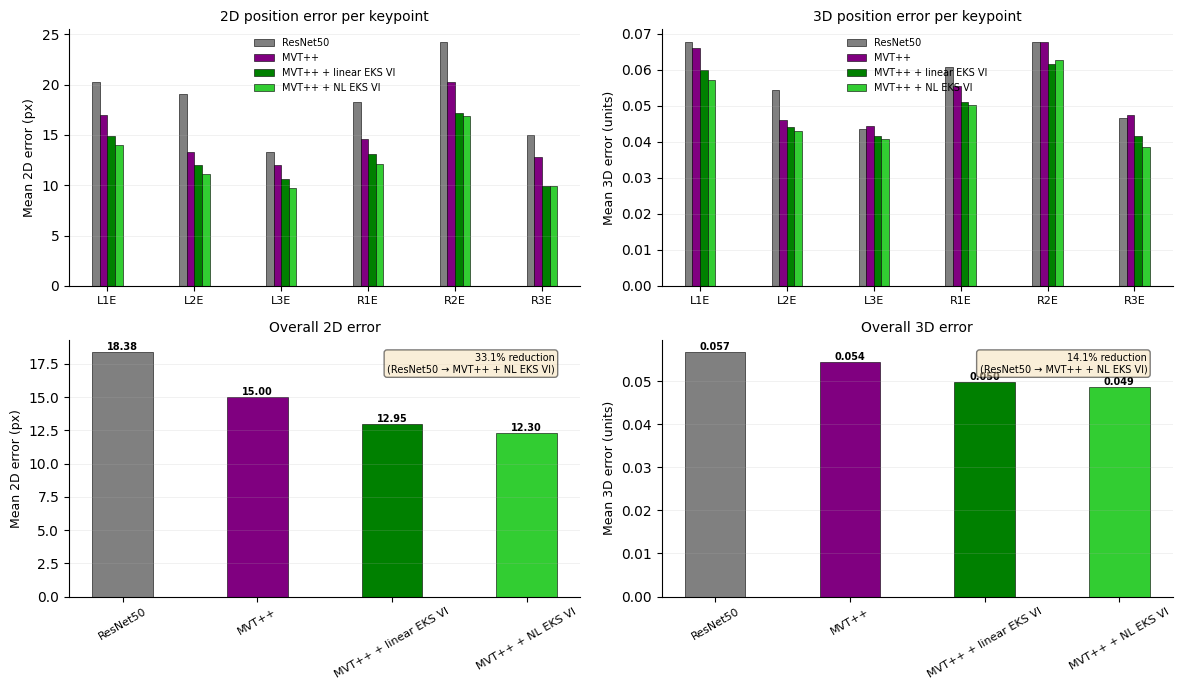

In [37]:
model_colors = {
    'test_200_multiview_resnet50_ensemble_median': 'gray',   # red
    'test_200_MVT_3d_loss_patch_masking_ensemble_median':        'purple',   # cyan
    'test_200_MVT_3d_loss_patch_masking_eks_multiview':     'green',   # teal
    'test_200_MVT_3d_loss_patch_masking_non_linear_eks_varinf':  'limegreen',   # navy
}

save_path = '/teamspace/studios/this_studio/outputs/fly-anipose/plots/postion_error_dashbord/position_error_dashboard_E_kp.pdf'


model_2d_errors, model_3d_errors = plot_position_error_dashboard(
    gt_session_data_2d=gt_session_data_2d,
    gt_all_session_3d=all_session_3d_new,
    model_configs=MODEL_CONFIGS,
    keypoints_to_analyze=KEYPOINTS_TO_ANALYZE,
    views=FLY_VIEWS,
    calib_dir=FLY_CALIB_DIR_OPTIMIZED,
    model_colors=model_colors,
    save_path=save_path,
    figsize=(12, 7),
)

Chat recommendation of limb length and things like that.

# Working on limb length Analysis here and coefficient of variation

CV across sessions

In [22]:
def compute_cv_per_limb_across_sessions(
    all_session_3d: Dict[str, Dict],
    keypoints: List[str] = FLY_KEYPOINTS,
    skeleton: List[Tuple[str, str]] = FLY_SKELETON
) -> Dict[str, Dict]:
    """
    Compute coefficient of variation for each limb across all sessions (pooled).
    """
    limb_results = {}
    
    for (kp1, kp2) in skeleton:
        limb_name = f"{kp1}-{kp2}"
        
        if kp1 not in keypoints or kp2 not in keypoints:
            continue
        
        idx1, idx2 = keypoints.index(kp1), keypoints.index(kp2)
        
        all_lengths = []
        per_session = {}
        
        for session_id, data in all_session_3d.items():
            points_3d = data['points_3d']
            
            diff = points_3d[:, idx1, :] - points_3d[:, idx2, :]
            lengths = np.linalg.norm(diff, axis=1)
            valid_lengths = lengths[~np.isnan(lengths)]
            
            if len(valid_lengths) > 0:
                all_lengths.extend(valid_lengths.tolist())
                
                per_session[session_id] = {
                    'lengths': valid_lengths,
                    'mean': np.mean(valid_lengths),
                    'std': np.std(valid_lengths),
                    'cv': np.std(valid_lengths) / np.mean(valid_lengths) if np.mean(valid_lengths) > 0 else np.nan,
                    'n_samples': len(valid_lengths)
                }
        
        if all_lengths:
            all_lengths = np.array(all_lengths)
            limb_results[limb_name] = {
                'all_lengths': all_lengths,
                'mean': np.mean(all_lengths),
                'std': np.std(all_lengths),
                'cv': np.std(all_lengths) / np.mean(all_lengths) if np.mean(all_lengths) > 0 else np.nan,
                'n_samples': len(all_lengths),
                'per_session': per_session
            }
    
    return limb_results


def print_cv_summary(cv_results: Dict[str, Dict], title: str = "CV Summary"):
    """Print a clean CV summary table."""
    print("\n" + "="*70)
    print(title)
    print("="*70)
    print(f"\n{'Limb':<12} {'Mean':>12} {'Std':>12} {'CV':>12} {'N':>10}")
    print("-"*60)
    
    for limb, stats in cv_results.items():
        print(f"{limb:<12} {stats['mean']:>12.4f} {stats['std']:>12.4f} "
              f"{stats['cv']:>12.4f} {stats['n_samples']:>10}")
    
    all_cvs = [stats['cv'] for stats in cv_results.values()]
    print("-"*60)
    print(f"{'AVERAGE CV':<12} {'':>12} {'':>12} {np.nanmean(all_cvs):>12.4f}")
    print("="*70)


def plot_fly_cv_dashboard(
    ood_gt_cv_results: Dict[str, Dict],
    figsize: Tuple[int, int] = (20, 16)
):
    """
    Plot cross-session CV analysis for fly dataset (24 limbs).
    """
    limb_names = list(ood_gt_cv_results.keys())
    n_limbs = len(limb_names)
    sessions = list(ood_gt_cv_results[limb_names[0]]['per_session'].keys()) if limb_names else []
    n_sessions = len(sessions)
    
    # Group limbs by leg
    leg_groups = {
        'L1': [l for l in limb_names if l.startswith('L1')],
        'L2': [l for l in limb_names if l.startswith('L2')],
        'L3': [l for l in limb_names if l.startswith('L3')],
        'R1': [l for l in limb_names if l.startswith('R1')],
        'R2': [l for l in limb_names if l.startswith('R2')],
        'R3': [l for l in limb_names if l.startswith('R3')],
    }
    
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(3, 2, figure=fig, hspace=0.35, wspace=0.25)
    
    # ===== Plot 1: CV per limb (bar chart) =====
    ax1 = fig.add_subplot(gs[0, :])
    
    gt_cvs = [ood_gt_cv_results[limb]['cv'] for limb in limb_names]
    
    # Color by leg
    colors = []
    leg_colors = {'L1': 'tab:blue', 'L2': 'tab:orange', 'L3': 'tab:green',
                  'R1': 'tab:red', 'R2': 'tab:purple', 'R3': 'tab:brown'}
    for limb in limb_names:
        for leg, color in leg_colors.items():
            if limb.startswith(leg):
                colors.append(color)
                break
    
    bars = ax1.bar(range(n_limbs), gt_cvs, color=colors, alpha=0.8)
    ax1.set_xticks(range(n_limbs))
    ax1.set_xticklabels(limb_names, rotation=90, fontsize=8)
    ax1.set_ylabel('Coefficient of Variation')
    ax1.set_title('Cross-Session CV per Limb (OOD Ground Truth)\n(Colors = different legs)', 
                  fontsize=12, fontweight='bold')
    ax1.axhline(np.nanmean(gt_cvs), color='red', linestyle='--', label=f'Mean CV: {np.nanmean(gt_cvs):.4f}')
    ax1.legend()
    ax1.grid(axis='y', alpha=0.3)
    
    # ===== Plot 2: CV heatmap (session x limb) =====
    ax2 = fig.add_subplot(gs[1, 0])
    
    cv_matrix = np.full((n_sessions, n_limbs), np.nan)
    for l_idx, limb in enumerate(limb_names):
        for s_idx, session in enumerate(sessions):
            if session in ood_gt_cv_results[limb]['per_session']:
                cv_matrix[s_idx, l_idx] = ood_gt_cv_results[limb]['per_session'][session]['cv']
    
    im = ax2.imshow(cv_matrix, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=0.3)
    ax2.set_xticks(range(n_limbs))
    ax2.set_xticklabels(limb_names, rotation=90, fontsize=6)
    ax2.set_yticks(range(n_sessions))
    ax2.set_yticklabels([s[:20] + '...' for s in sessions], fontsize=7)
    ax2.set_title('CV per Session per Limb\n(Green=consistent, Red=variable)', fontsize=11, fontweight='bold')
    plt.colorbar(im, ax=ax2, label='CV')
    
    # ===== Plot 3: Mean limb length heatmap =====
    ax3 = fig.add_subplot(gs[1, 1])
    
    mean_matrix = np.full((n_sessions, n_limbs), np.nan)
    for l_idx, limb in enumerate(limb_names):
        for s_idx, session in enumerate(sessions):
            if session in ood_gt_cv_results[limb]['per_session']:
                mean_matrix[s_idx, l_idx] = ood_gt_cv_results[limb]['per_session'][session]['mean']
    
    im3 = ax3.imshow(mean_matrix, aspect='auto', cmap='viridis')
    ax3.set_xticks(range(n_limbs))
    ax3.set_xticklabels(limb_names, rotation=90, fontsize=6)
    ax3.set_yticks(range(n_sessions))
    ax3.set_yticklabels([s[:20] + '...' for s in sessions], fontsize=7)
    ax3.set_title('Mean Limb Length per Session', fontsize=11, fontweight='bold')
    plt.colorbar(im3, ax=ax3, label='Length')
    
    # ===== Plot 4: CV by leg (grouped bar) =====
    ax4 = fig.add_subplot(gs[2, 0])
    
    leg_names = list(leg_groups.keys())
    leg_avg_cvs = []
    for leg in leg_names:
        limbs = leg_groups[leg]
        cvs = [ood_gt_cv_results[l]['cv'] for l in limbs if l in ood_gt_cv_results]
        leg_avg_cvs.append(np.nanmean(cvs) if cvs else np.nan)
    
    bars4 = ax4.bar(leg_names, leg_avg_cvs, color=[leg_colors[l] for l in leg_names], alpha=0.8)
    ax4.set_ylabel('Average CV')
    ax4.set_title('Average CV by Leg', fontsize=11, fontweight='bold')
    ax4.grid(axis='y', alpha=0.3)
    
    for bar, cv in zip(bars4, leg_avg_cvs):
        if not np.isnan(cv):
            ax4.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.002,
                    f'{cv:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # ===== Plot 5: Summary statistics =====
    ax5 = fig.add_subplot(gs[2, 1])
    ax5.axis('off')
    
    # Create summary
    summary_text = []
    summary_text.append(f"CROSS-SESSION CV SUMMARY (OOD Ground Truth)")
    summary_text.append(f"{'─'*45}")
    summary_text.append(f"Sessions analyzed: {n_sessions}")
    summary_text.append(f"Limbs analyzed: {n_limbs}")
    summary_text.append(f"")
    summary_text.append(f"Overall average CV: {np.nanmean(gt_cvs):.4f}")
    summary_text.append(f"")
    
    # Best and worst limbs
    best_limb = min(limb_names, key=lambda l: ood_gt_cv_results[l]['cv'])
    worst_limb = max(limb_names, key=lambda l: ood_gt_cv_results[l]['cv'])
    summary_text.append(f"Most consistent: {best_limb} (CV={ood_gt_cv_results[best_limb]['cv']:.4f})")
    summary_text.append(f"Most variable: {worst_limb} (CV={ood_gt_cv_results[worst_limb]['cv']:.4f})")
    summary_text.append(f"")
    
    # Per-leg summary
    summary_text.append(f"{'Leg':<6} {'Avg CV':>10}")
    summary_text.append(f"{'─'*20}")
    for leg, avg_cv in zip(leg_names, leg_avg_cvs):
        summary_text.append(f"{leg:<6} {avg_cv:>10.4f}")
    
    ax5.text(0.1, 0.95, '\n'.join(summary_text), transform=ax5.transAxes,
            fontsize=11, verticalalignment='top', family='monospace',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    
    plt.suptitle('Fly-Anipose: Cross-Session Coefficient of Variation Analysis', 
                 fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    
    return ood_gt_cv_results


STEP 1: Triangulating OOD Ground Truth
FLY-ANIPOSE: Triangulating OOD Ground Truth Data
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-A_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-B_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-C_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-D_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-E_new.csv...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-F_new.csv...

Found 12 sessions in OOD data

Processing session: 05272019_fly4_0_R2C26_rot-ccw-0.18_sec
  Data loaded per view: {'Cam-A': np.int64(750), 'Cam-B': np.int64(750), 'Cam-C': np.int64(750), 'Cam-D': np.int64(750), 'Cam-E': np.int64(750), 'Cam-F': np.int64(750)}
  Found 25 common frames across views
  Triangulated: 25/25 valid frames

Processing session: 05272019_fly4_0_R2C18_rot-cw-0.09_sec
  Data loaded per view: {'Cam-A': np.int64(750), 'Cam-B': np.int64(750

/tmp/ipykernel_1060302/2814624163.py:182: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


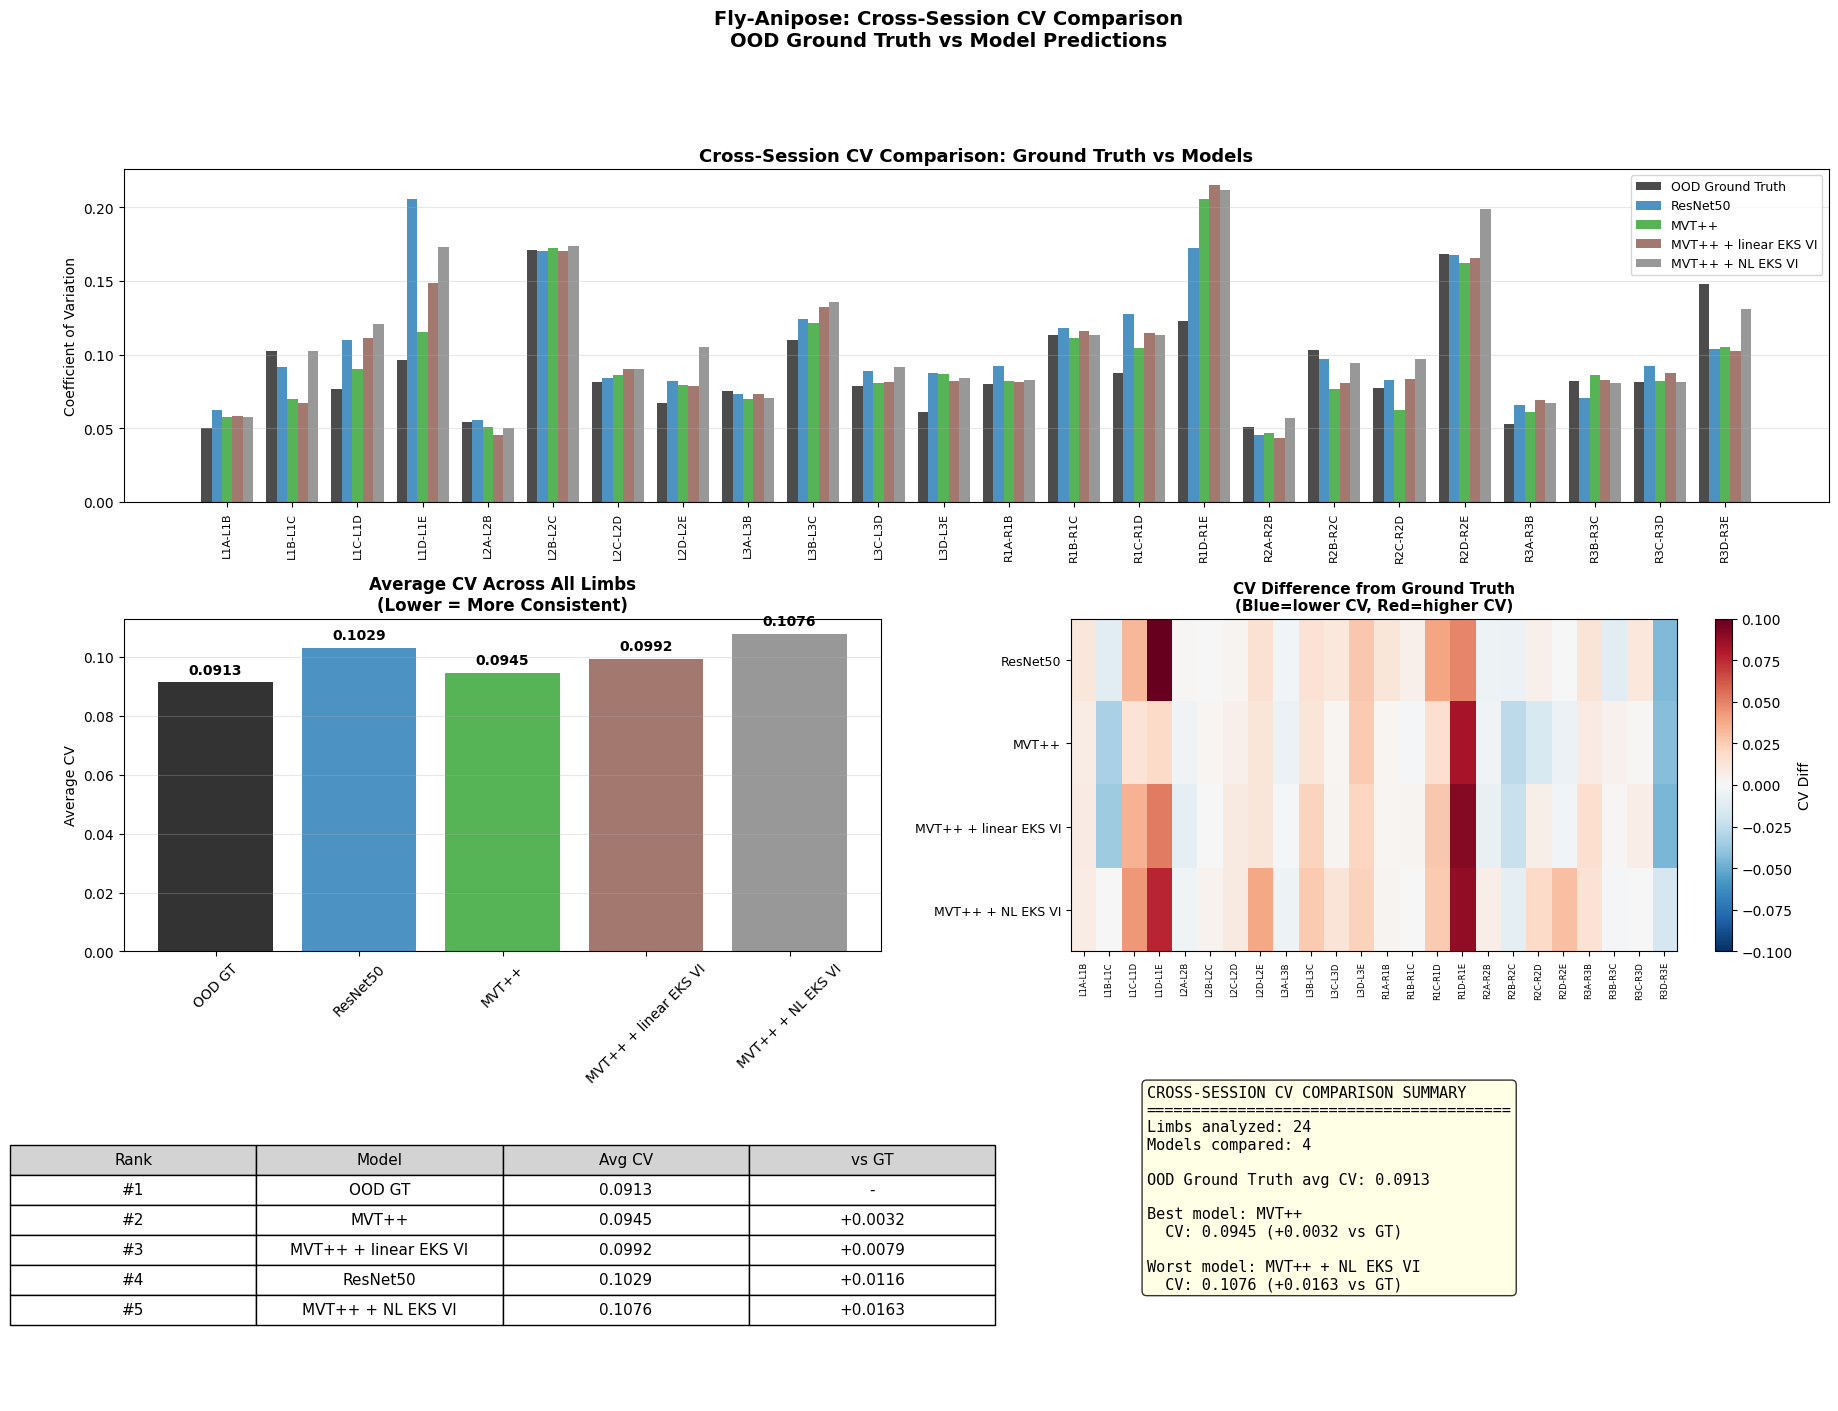


DETAILED CV COMPARISON TABLE
Limb                 GT     ResNet50        MVT++ MVT++ + line MVT++ + NL E
----------------------------------------------------------------------------
L1A-L1B          0.0504       0.0621       0.0580       0.0583       0.0575
L1B-L1C          0.1024       0.0913       0.0698       0.0672       0.1022
L1C-L1D          0.0770       0.1100       0.0905       0.1115       0.1205
L1D-L1E          0.0963       0.2055       0.1153       0.1484       0.1727
L2A-L2B          0.0546       0.0555       0.0508       0.0454       0.0500
L2B-L2C          0.1707       0.1704       0.1726       0.1701       0.1740
L2C-L2D          0.0812       0.0841       0.0860       0.0905       0.0901
L2D-L2E          0.0670       0.0820       0.0792       0.0788       0.1054
L3A-L3B          0.0755       0.0730       0.0700       0.0734       0.0703
L3B-L3C          0.1097       0.1240       0.1214       0.1322       0.1360
L3C-L3D          0.0785       0.0892       0.0807       0

In [23]:



def compute_all_model_cvs(
    model_configs: Dict[str, Dict],
    keypoints: List[str] = FLY_KEYPOINTS,
    skeleton: List[Tuple[str, str]] = FLY_SKELETON,
    calib_dir: str = FLY_CALIB_DIR,
    views: List[str] = FLY_VIEWS
) -> Dict[str, Dict[str, Dict]]:
    """
    Compute CV for all models.
    
    Returns:
    --------
    Dict[model_name, Dict[limb_name, cv_stats]]
    """
    model_cv_results = {}
    
    for model_name, config in model_configs.items():
        # Triangulate this model's predictions
        all_session_3d = triangulate_model_all_sessions(config, views, keypoints, calib_dir)
        
        if not all_session_3d:
            print(f"  No valid data for {config['display_name']}")
            continue
        
        # Compute CV
        cv_results = compute_cv_per_limb_across_sessions(all_session_3d, keypoints, skeleton)
        
        # Store with display name
        model_cv_results[model_name] = {
            'display_name': config['display_name'],
            'cv_per_limb': cv_results
        }
    
    return model_cv_results


def plot_cv_comparison_dashboard(
    ood_gt_cv_results: Dict[str, Dict],
    model_cv_results: Dict[str, Dict],
    figsize: Tuple[int, int] = (22, 16)
):
    """
    Plot comprehensive CV comparison: OOD Ground Truth vs Models.
    """
    limb_names = list(ood_gt_cv_results.keys())
    n_limbs = len(limb_names)
    n_models = len(model_cv_results)
    
    # Extract data
    gt_cvs = [ood_gt_cv_results[l]['cv'] for l in limb_names]
    
    model_names = list(model_cv_results.keys())
    display_names = [model_cv_results[m]['display_name'] for m in model_names]
    
    # Colors
    colors = plt.cm.tab10(np.linspace(0, 1, n_models + 1))
    gt_color = 'black'
    
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(3, 2, figure=fig, hspace=0.35, wspace=0.25)
    
    # ===== Plot 1: CV per limb - all models vs GT =====
    ax1 = fig.add_subplot(gs[0, :])
    
    x = np.arange(n_limbs)
    width = 0.8 / (n_models + 1)
    
    # Ground truth
    ax1.bar(x, gt_cvs, width, label='OOD Ground Truth', color=gt_color, alpha=0.7)
    
    # Models
    for m_idx, m_name in enumerate(model_names):
        model_cvs = [model_cv_results[m_name]['cv_per_limb'].get(l, {}).get('cv', np.nan) 
                    for l in limb_names]
        ax1.bar(x + (m_idx + 1) * width, model_cvs, width, 
               label=display_names[m_idx], color=colors[m_idx], alpha=0.8)
    
    ax1.set_xticks(x + width * n_models / 2)
    ax1.set_xticklabels(limb_names, rotation=90, fontsize=8)
    ax1.set_ylabel('Coefficient of Variation')
    ax1.set_title('Cross-Session CV Comparison: Ground Truth vs Models', fontsize=13, fontweight='bold')
    ax1.legend(loc='upper right', fontsize=9)
    ax1.grid(axis='y', alpha=0.3)
    
    # ===== Plot 2: Average CV per model (bar chart) =====
    ax2 = fig.add_subplot(gs[1, 0])
    
    avg_cvs = [np.nanmean(gt_cvs)]  # GT first
    avg_names = ['OOD GT']
    bar_colors = [gt_color]
    
    for m_idx, m_name in enumerate(model_names):
        model_cvs = [model_cv_results[m_name]['cv_per_limb'].get(l, {}).get('cv', np.nan) 
                    for l in limb_names]
        avg_cvs.append(np.nanmean(model_cvs))
        avg_names.append(display_names[m_idx])
        bar_colors.append(colors[m_idx])
    
    bars = ax2.bar(avg_names, avg_cvs, color=bar_colors, alpha=0.8)
    ax2.set_ylabel('Average CV')
    ax2.set_title('Average CV Across All Limbs\n(Lower = More Consistent)', fontsize=12, fontweight='bold')
    ax2.tick_params(axis='x', rotation=45)
    ax2.grid(axis='y', alpha=0.3)
    
    # Add value labels
    for bar, cv in zip(bars, avg_cvs):
        if not np.isnan(cv):
            ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.002,
                    f'{cv:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # ===== Plot 3: CV difference from GT (heatmap) =====
    ax3 = fig.add_subplot(gs[1, 1])
    
    diff_matrix = np.full((n_models, n_limbs), np.nan)
    for m_idx, m_name in enumerate(model_names):
        for l_idx, limb in enumerate(limb_names):
            model_cv = model_cv_results[m_name]['cv_per_limb'].get(limb, {}).get('cv', np.nan)
            gt_cv = gt_cvs[l_idx]
            if not np.isnan(model_cv) and not np.isnan(gt_cv):
                diff_matrix[m_idx, l_idx] = model_cv - gt_cv
    
    im = ax3.imshow(diff_matrix, aspect='auto', cmap='RdBu_r', vmin=-0.1, vmax=0.1)
    ax3.set_xticks(range(n_limbs))
    ax3.set_xticklabels(limb_names, rotation=90, fontsize=6)
    ax3.set_yticks(range(n_models))
    ax3.set_yticklabels(display_names, fontsize=9)
    ax3.set_title('CV Difference from Ground Truth\n(Blue=lower CV, Red=higher CV)', fontsize=11, fontweight='bold')
    plt.colorbar(im, ax=ax3, label='CV Diff')
    
    # ===== Plot 4: Ranking table =====
    ax4 = fig.add_subplot(gs[2, 0])
    ax4.axis('off')
    
    # Create ranking by average CV
    ranking_data = [(name, cv) for name, cv in zip(avg_names, avg_cvs)]
    ranking_data.sort(key=lambda x: x[1])
    
    table_data = [['Rank', 'Model', 'Avg CV', 'vs GT']]
    gt_avg = avg_cvs[0]
    for rank, (name, cv) in enumerate(ranking_data, 1):
        diff = cv - gt_avg if name != 'OOD GT' else '-'
        diff_str = f"{diff:+.4f}" if isinstance(diff, float) else diff
        table_data.append([f"#{rank}", name, f"{cv:.4f}", diff_str])
    
    table = ax4.table(cellText=table_data[1:], colLabels=table_data[0],
                      loc='center', cellLoc='center',
                      colColours=['lightgray'] * 4)
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1.3, 1.8)
    
    # ===== Plot 5: Summary statistics =====
    ax5 = fig.add_subplot(gs[2, 1])
    ax5.axis('off')
    
    summary = []
    summary.append("CROSS-SESSION CV COMPARISON SUMMARY")
    summary.append("="*40)
    summary.append(f"Limbs analyzed: {n_limbs}")
    summary.append(f"Models compared: {n_models}")
    summary.append("")
    summary.append(f"OOD Ground Truth avg CV: {avg_cvs[0]:.4f}")
    summary.append("")
    
    # Find best model
    model_avg_cvs = {name: cv for name, cv in zip(avg_names[1:], avg_cvs[1:])}
    best_model = min(model_avg_cvs.items(), key=lambda x: x[1])
    worst_model = max(model_avg_cvs.items(), key=lambda x: x[1])
    
    summary.append(f"Best model: {best_model[0]}")
    summary.append(f"  CV: {best_model[1]:.4f} ({best_model[1] - gt_avg:+.4f} vs GT)")
    summary.append("")
    summary.append(f"Worst model: {worst_model[0]}")
    summary.append(f"  CV: {worst_model[1]:.4f} ({worst_model[1] - gt_avg:+.4f} vs GT)")
    
    ax5.text(0.1, 0.95, '\n'.join(summary), transform=ax5.transAxes,
            fontsize=11, verticalalignment='top', family='monospace',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    
    plt.suptitle('Fly-Anipose: Cross-Session CV Comparison\nOOD Ground Truth vs Model Predictions', 
                 fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    
    return avg_cvs, ranking_data


# ============================================================================
# RUN THE COMPLETE ANALYSIS
# ============================================================================

# Step 1: Triangulate OOD Ground Truth (if not already done)
print("="*80)
print("STEP 1: Triangulating OOD Ground Truth")
print("="*80)
all_session_3d_fly = triangulate_all_sessions_fly(
    FLY_OOD_PATHS,
    FLY_CALIB_DIR_OPTIMIZED,
    FLY_VIEWS,
    FLY_KEYPOINTS
)

# Step 2: Compute OOD Ground Truth CV
print("\n" + "="*80)
print("STEP 2: Computing OOD Ground Truth CV")
print("="*80)
ood_gt_cv_results = compute_cv_per_limb_across_sessions(
    all_session_3d_fly,
    # all_session_3d_new,
    keypoints=FLY_KEYPOINTS,
    skeleton=FLY_SKELETON
)
print_cv_summary(ood_gt_cv_results, "OOD Ground Truth CV Summary")

# Step 3: Triangulate and compute CV for all models
print("\n" + "="*80)
print("STEP 3: Processing Model Predictions")
print("="*80)
model_cv_results = compute_all_model_cvs(
    MODEL_CONFIGS,
    FLY_KEYPOINTS,
    FLY_SKELETON,
    FLY_CALIB_DIR_OPTIMIZED,
    FLY_VIEWS    
)

# Step 4: Plot comparison dashboard
print("\n" + "="*80)
print("STEP 4: Generating Comparison Dashboard")
print("="*80)
avg_cvs, ranking = plot_cv_comparison_dashboard(ood_gt_cv_results, model_cv_results)

# Step 5: Print detailed comparison
print("\n" + "="*80)
print("DETAILED CV COMPARISON TABLE")
print("="*80)

limb_names = list(ood_gt_cv_results.keys())
header = f"{'Limb':<12} {'GT':>10}"
for m_name, m_data in model_cv_results.items():
    header += f" {m_data['display_name'][:12]:>12}"
print(header)
print("-" * (24 + 13 * len(model_cv_results)))

for limb in limb_names:
    row = f"{limb:<12} {ood_gt_cv_results[limb]['cv']:>10.4f}"
    for m_name, m_data in model_cv_results.items():
        m_cv = m_data['cv_per_limb'].get(limb, {}).get('cv', np.nan)
        row += f" {m_cv:>12.4f}"
    print(row)

limb lengths

Across Sessions Limb length

In [25]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np
import scipy.stats as stats
from scipy.spatial.distance import jensenshannon
from scipy.stats import wasserstein_distance, ks_2samp

def compute_distribution_metrics(pred_lengths: np.ndarray, gt_lengths: np.ndarray) -> dict:
    """
    Compute metrics comparing predicted distribution to ground truth distribution.
    
    Returns dict with:
        - wasserstein: Wasserstein (Earth Mover's) distance
        - ks_stat: Kolmogorov-Smirnov statistic (0-1, lower = closer)
        - ks_pval: KS test p-value
        - js_div: Jensen-Shannon divergence (0-1, lower = closer)
        - mean_diff: Absolute difference in means
        - std_diff: Absolute difference in standard deviations
    """
    pred_valid = pred_lengths[~np.isnan(pred_lengths)]
    gt_valid = gt_lengths[~np.isnan(gt_lengths)]
    
    if len(pred_valid) < 2 or len(gt_valid) < 2:
        return {'wasserstein': np.nan, 'ks_stat': np.nan, 'ks_pval': np.nan, 
                'js_div': np.nan, 'mean_diff': np.nan, 'std_diff': np.nan}
    
    # Wasserstein distance (in original units)
    wass_dist = wasserstein_distance(pred_valid, gt_valid)
    
    # KS test
    ks_stat, ks_pval = ks_2samp(pred_valid, gt_valid)
    
    # Jensen-Shannon divergence (need to bin data for discrete comparison)
    # Create common bins
    all_data = np.concatenate([pred_valid, gt_valid])
    bins = np.linspace(np.min(all_data), np.max(all_data), 50)
    
    pred_hist, _ = np.histogram(pred_valid, bins=bins, density=True)
    gt_hist, _ = np.histogram(gt_valid, bins=bins, density=True)
    
    # Add small epsilon to avoid division by zero
    eps = 1e-10
    pred_hist = pred_hist + eps
    gt_hist = gt_hist + eps
    
    # Normalize
    pred_hist = pred_hist / pred_hist.sum()
    gt_hist = gt_hist / gt_hist.sum()
    
    js_div = jensenshannon(pred_hist, gt_hist)
    
    # Simple statistics comparison
    mean_diff = np.abs(np.mean(pred_valid) - np.mean(gt_valid))
    std_diff = np.abs(np.std(pred_valid) - np.std(gt_valid))
    
    return {
        'wasserstein': wass_dist,
        'ks_stat': ks_stat,
        'ks_pval': ks_pval,
        'js_div': js_div,
        'mean_diff': mean_diff,
        'std_diff': std_diff
    }


In [26]:
# Cell: Fixed code to load OOD labeled data and compute limb length distributions per session

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple
from collections import defaultdict
import re

def load_labeled_data(csv_path: str) -> pd.DataFrame:
    """
    Load labeled data from a DeepLabCut-style CSV file.
    """
    df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
    return df

def extract_session_from_index(index_str: str, views: List[str]) -> str:
    """
    Extract session name from the image path in the index.
    E.g., 'labeled-data/05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec/img00000014.png'
    Returns: '05272019_fly4_0_R2C26_rot-ccw-0.18_sec'
    """
    parts = index_str.split('/')
    if len(parts) >= 2:
        folder_name = parts[1]  # e.g., '05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec'
        
        # Remove the camera view part (e.g., '_Cam-A')
        for view in views:
            folder_name = folder_name.replace(f'_{view}', '')
        
        return folder_name
    return None

def create_frame_key(index_str: str, views: List[str]) -> str:
    """
    Create a common key for matching frames across views.
    E.g., 'labeled-data/05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec/img00000014.png'
    Returns: '05272019_fly4_0_R2C26_rot-ccw-0.18_sec/img00000014.png'
    """
    parts = index_str.split('/')
    if len(parts) >= 3:
        folder_name = parts[1]
        img_name = parts[2]
        
        # Remove the camera view part from folder name
        for view in views:
            folder_name = folder_name.replace(f'_{view}', '')
        
        return f"{folder_name}/{img_name}"
    return index_str






In [27]:
# ============================================================================
# STEP 1: Function to load model predictions on OOD labeled frames
# ============================================================================

def get_ood_prediction_paths(
    dataset_name: str,
    results_configs: Dict[str, Dict],
    views: List[str],
    seed_dirs: List[str] = None,
    ensemble_seed: str = None,
    ensemble_methods: List[str] = None,
    base_path: str = "/teamspace/studios",
    studio_dir: str = "this_studio",
    output_dir: str = "outputs",
) -> Dict[str, Dict[str, str]]:
    """
    Get paths to model predictions on OOD labeled frames.
    
    Returns:
        Dict mapping model_name -> {view: prediction_file_path}
    """
    model_pred_paths = {}
    
    for results_dir, config in results_configs.items():
        model_type = config['model_type']
        n_labels = config['n_hand_labels']
        
        # Check ensemble methods
        if ensemble_methods and ensemble_seed:
            for method in ensemble_methods:
                pred_dir = os.path.join(
                    base_path, studio_dir, output_dir, dataset_name, results_dir,
                    f"{model_type}_{n_labels}_{ensemble_seed}", method, "videos-for-each-labeled-frame"
                )
                
                if os.path.exists(pred_dir):
                    model_name = f"{results_dir}_{method}"
                    view_paths = {}
                    
                    for view in views:
                        pred_file = os.path.join(pred_dir, f"predictions_{view}_new.csv")
                        if os.path.exists(pred_file):
                            view_paths[view] = pred_file
                    
                    if len(view_paths) >= 2:
                        model_pred_paths[model_name] = view_paths
                        print(f"Found predictions for {model_name}: {len(view_paths)} views")
        
        # Check individual seeds
        if seed_dirs:
            for seed in seed_dirs:
                pred_dir = os.path.join(
                    base_path, studio_dir, output_dir, dataset_name, results_dir,
                    f"{model_type}_{n_labels}_{seed}", "videos-for-each-labeled-frame"
                )
                
                if os.path.exists(pred_dir):
                    model_name = f"{results_dir}_seed_{seed}"
                    view_paths = {}
                    
                    for view in views:
                        pred_file = os.path.join(pred_dir, f"predictions_{view}_new.csv")
                        if os.path.exists(pred_file):
                            view_paths[view] = pred_file
                    
                    if len(view_paths) >= 2:
                        model_pred_paths[model_name] = view_paths
                        print(f"Found predictions for {model_name}: {len(view_paths)} views")
    
    return model_pred_paths

# ============================================================================
# OPTIMIZED: Fast loading of labeled data organized by session
# ============================================================================

def organize_labeled_data_by_session_fast(
    data_paths: Dict[str, str],
    views: List[str]
) -> Dict[str, Dict[str, pd.DataFrame]]:
    """
    FAST version: Load labeled data and organize by session using vectorized operations.
    """
    from collections import defaultdict
    
    session_data = defaultdict(lambda: {view: None for view in views})
    
    for view in views:
        csv_path = data_paths[view]
        print(f"Loading {csv_path}")
        
        try:
            df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
            
            # Extract session names from all indices at once (vectorized)
            indices = df.index.tolist()
            
            # Parse session names in one pass
            session_names = []
            for idx in indices:
                parts = idx.split('/')
                if len(parts) >= 2:
                    folder_name = parts[1]
                    for v in views:
                        folder_name = folder_name.replace(f'_{v}', '')
                    session_names.append(folder_name)
                else:
                    session_names.append(None)
            
            # Add session column temporarily
            df['_session'] = session_names
            
            # Group by session (FAST - uses pandas groupby)
            for session_name, group_df in df.groupby('_session'):
                if session_name is not None:
                    # Drop the temp column and store
                    group_df = group_df.drop(columns=['_session'])
                    session_data[session_name][view] = group_df
            
        except Exception as e:
            print(f"Error loading {csv_path}: {e}")
            continue
    
    return dict(session_data)


def prepare_multiview_tensor_fast(
    session_views_data: Dict[str, pd.DataFrame],
    views: List[str]
) -> Tuple[torch.Tensor, List[str], int]:
    """
    FAST version: Convert labeled data to tensor using vectorized operations.
    """
    
    # Helper to create frame key from index
    def make_frame_key(idx, views):
        parts = idx.split('/')
        if len(parts) >= 3:
            folder = parts[1]
            img = parts[2]
            for v in views:
                folder = folder.replace(f'_{v}', '')
            return f"{folder}/{img}"
        return idx
    
    # Build frame key mappings for each view
    view_frame_data = {}
    all_frame_keys = None
    
    for view in views:
        if session_views_data[view] is not None and len(session_views_data[view]) > 0:
            df = session_views_data[view]
            # Create frame keys for all rows at once
            frame_keys = [make_frame_key(idx, views) for idx in df.index]
            view_frame_data[view] = {
                'df': df,
                'frame_keys': frame_keys,
                'key_to_row': {k: i for i, k in enumerate(frame_keys)}
            }
            
            if all_frame_keys is None:
                all_frame_keys = set(frame_keys)
            else:
                all_frame_keys = all_frame_keys.intersection(frame_keys)
    
    if not all_frame_keys:
        return None, None, 0
    
    all_frame_keys = sorted(list(all_frame_keys))
    n_frames = len(all_frame_keys)
    
    # Get keypoint names
    first_view = next(v for v in views if v in view_frame_data)
    df = view_frame_data[first_view]['df']
    keypoint_names = list(df.columns.get_level_values(1).unique())
    
    n_keypoints = len(keypoint_names)
    n_views = len(views)
    
    # Pre-allocate tensor
    output_tensor = torch.full((n_frames, n_keypoints * n_views, 2), float('nan'))
    
    # Extract data using numpy for speed
    for view_idx, view in enumerate(views):
        if view not in view_frame_data:
            continue
        
        vd = view_frame_data[view]
        df = vd['df']
        key_to_row = vd['key_to_row']
        
        # Get row indices for common frames
        row_indices = [key_to_row[k] for k in all_frame_keys if k in key_to_row]
        
        if not row_indices:
            continue
        
        # Extract x and y columns for all keypoints at once
        for kp_idx, kp_name in enumerate(keypoint_names):
            try:
                # Get column indices for this keypoint's x and y
                x_col = df.xs((kp_name, 'x'), axis=1, level=(1, 2))
                y_col = df.xs((kp_name, 'y'), axis=1, level=(1, 2))
                
                # Extract values for the matching rows (using iloc for speed)
                x_vals = x_col.iloc[row_indices].values.flatten()
                y_vals = y_col.iloc[row_indices].values.flatten()
                
                col_idx = view_idx * n_keypoints + kp_idx
                output_tensor[:len(row_indices), col_idx, 0] = torch.tensor(x_vals, dtype=torch.float32)
                output_tensor[:len(row_indices), col_idx, 1] = torch.tensor(y_vals, dtype=torch.float32)
            except:
                continue
    
    return output_tensor, keypoint_names, n_frames


def compute_ood_limb_lengths_per_session_fast(
    ood_paths: Dict[str, str],
    views: List[str],
    camera_params_dir: str,
    skeleton: List[Tuple[str, str]]
) -> Dict[str, Dict[str, np.ndarray]]:
    """
    FAST version: Compute 3D limb lengths for OOD labeled data.
    """
    print("Organizing labeled data by session (fast)...")
    session_data = organize_labeled_data_by_session_fast(ood_paths, views)
    
    print(f"Found {len(session_data)} sessions")
    
    all_limb_lengths = {}
    
    for session_name, views_data in session_data.items():
        valid_views = [v for v in views if views_data[v] is not None and len(views_data[v]) > 0]
        
        if len(valid_views) < 2:
            continue
        
        camera_group = load_camera_parameters(session_name, camera_params_dir)
        if camera_group is None:
            continue
        
        data_tensor, keypoint_names, n_frames = prepare_multiview_tensor_fast(views_data, views)
        
        if data_tensor is None or n_frames == 0:
            continue
        
        print(f"  {session_name}: {n_frames} frames, {len(valid_views)} views")
        
        try:
            points_3d = triangulate_keypoints(data_tensor, camera_group, keypoint_names, views)
            limb_lengths = calculate_limb_lengths_3d(points_3d, keypoint_names, skeleton)
            all_limb_lengths[session_name] = limb_lengths
        except Exception as e:
            print(f"  {session_name}: Failed - {e}")
            continue
    
    return all_limb_lengths


def compute_model_ood_limb_lengths_fast(
    model_pred_paths: Dict[str, Dict[str, str]],
    views: List[str],
    camera_params_dir: str,
    skeleton: List[Tuple[str, str]]
) -> Dict[str, Dict[str, Dict[str, np.ndarray]]]:
    """
    FAST version: Compute limb lengths from model predictions.
    """
    all_model_results = {}
    
    for model_name, view_paths in model_pred_paths.items():
        print(f"\nProcessing: {model_name}")
        
        session_data = organize_labeled_data_by_session_fast(view_paths, views)
        model_limb_lengths = {}
        
        for session_name, views_data in session_data.items():
            valid_views = [v for v in views if views_data[v] is not None and len(views_data[v]) > 0]
            
            if len(valid_views) < 2:
                continue
            
            camera_group = load_camera_parameters(session_name, camera_params_dir)
            if camera_group is None:
                continue
            
            data_tensor, keypoint_names, n_frames = prepare_multiview_tensor_fast(views_data, views)
            
            if data_tensor is None or n_frames == 0:
                continue
            
            try:
                points_3d = triangulate_keypoints(data_tensor, camera_group, keypoint_names, views)
                limb_lengths = calculate_limb_lengths_3d(points_3d, keypoint_names, skeleton)
                model_limb_lengths[session_name] = limb_lengths
                print(f"  {session_name}: {n_frames} frames OK")
            except Exception as e:
                continue
        
        all_model_results[model_name] = model_limb_lengths
    
    return all_model_results



In [28]:
# Load OOD ground truth (FAST)
print("Loading OOD Ground Truth...")
ood_limb_lengths_by_session = compute_ood_limb_lengths_per_session_fast(
    Out_Dist_paths,
    FLY_VIEWS,
    # FLY_CALIB_DIR,
    FLY_CALIB_DIR_OPTIMIZED,
    skeleton
)

# Get model prediction paths
model_ood_pred_paths = get_ood_prediction_paths(
    dataset_name=dataset_name,
    results_configs=results_configs,
    views=FLY_VIEWS,
    seed_dirs=seed_dirs,
    ensemble_seed=ensemble_seed,
    ensemble_methods=ensemble_methods
)

# Load model predictions (FAST)
print("\nLoading Model Predictions...")
model_ood_limb_lengths = compute_model_ood_limb_lengths_fast(
    model_ood_pred_paths,
    FLY_VIEWS,
    # FLY_CALIB_DIR,
    FLY_CALIB_DIR_OPTIMIZED,
    skeleton
)

Loading OOD Ground Truth...
Organizing labeled data by session (fast)...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-A_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-B_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-C_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-D_new.csv


INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R1C24_rot-ccw-0.06_sec


Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-E_new.csv
Found 12 sessions
  05272019_fly4_0_R1C24_rot-ccw-0.06_sec: 25 frames, 5 views


INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R2C14_str-ccw-0.72_sec
INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R2C18_rot-cw-0.09_sec
INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R2C26_rot-ccw-0.18_sec


  05272019_fly4_0_R2C14_str-ccw-0.72_sec: 25 frames, 5 views
  05272019_fly4_0_R2C18_rot-cw-0.09_sec: 25 frames, 5 views


INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec
INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C26_rot-ccw-0.18_sec


... (40 outputs left out)

  05272019_fly4_0_R2C18_rot-cw-0.09_sec: 25 frames OK
  05272019_fly4_0_R2C26_rot-ccw-0.18_sec: 25 frames OK


INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C26_rot-ccw-0.18_sec


  05272019_fly4_0_R3C16_rot-cw-0.03_sec: 25 frames OK


KeyboardInterrupt: 

/tmp/ipykernel_18711/857667715.py:202: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(box_data, labels=box_labels, patch_artist=True)
/tmp/ipykernel_18711/857667715.py:287: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 0.96])


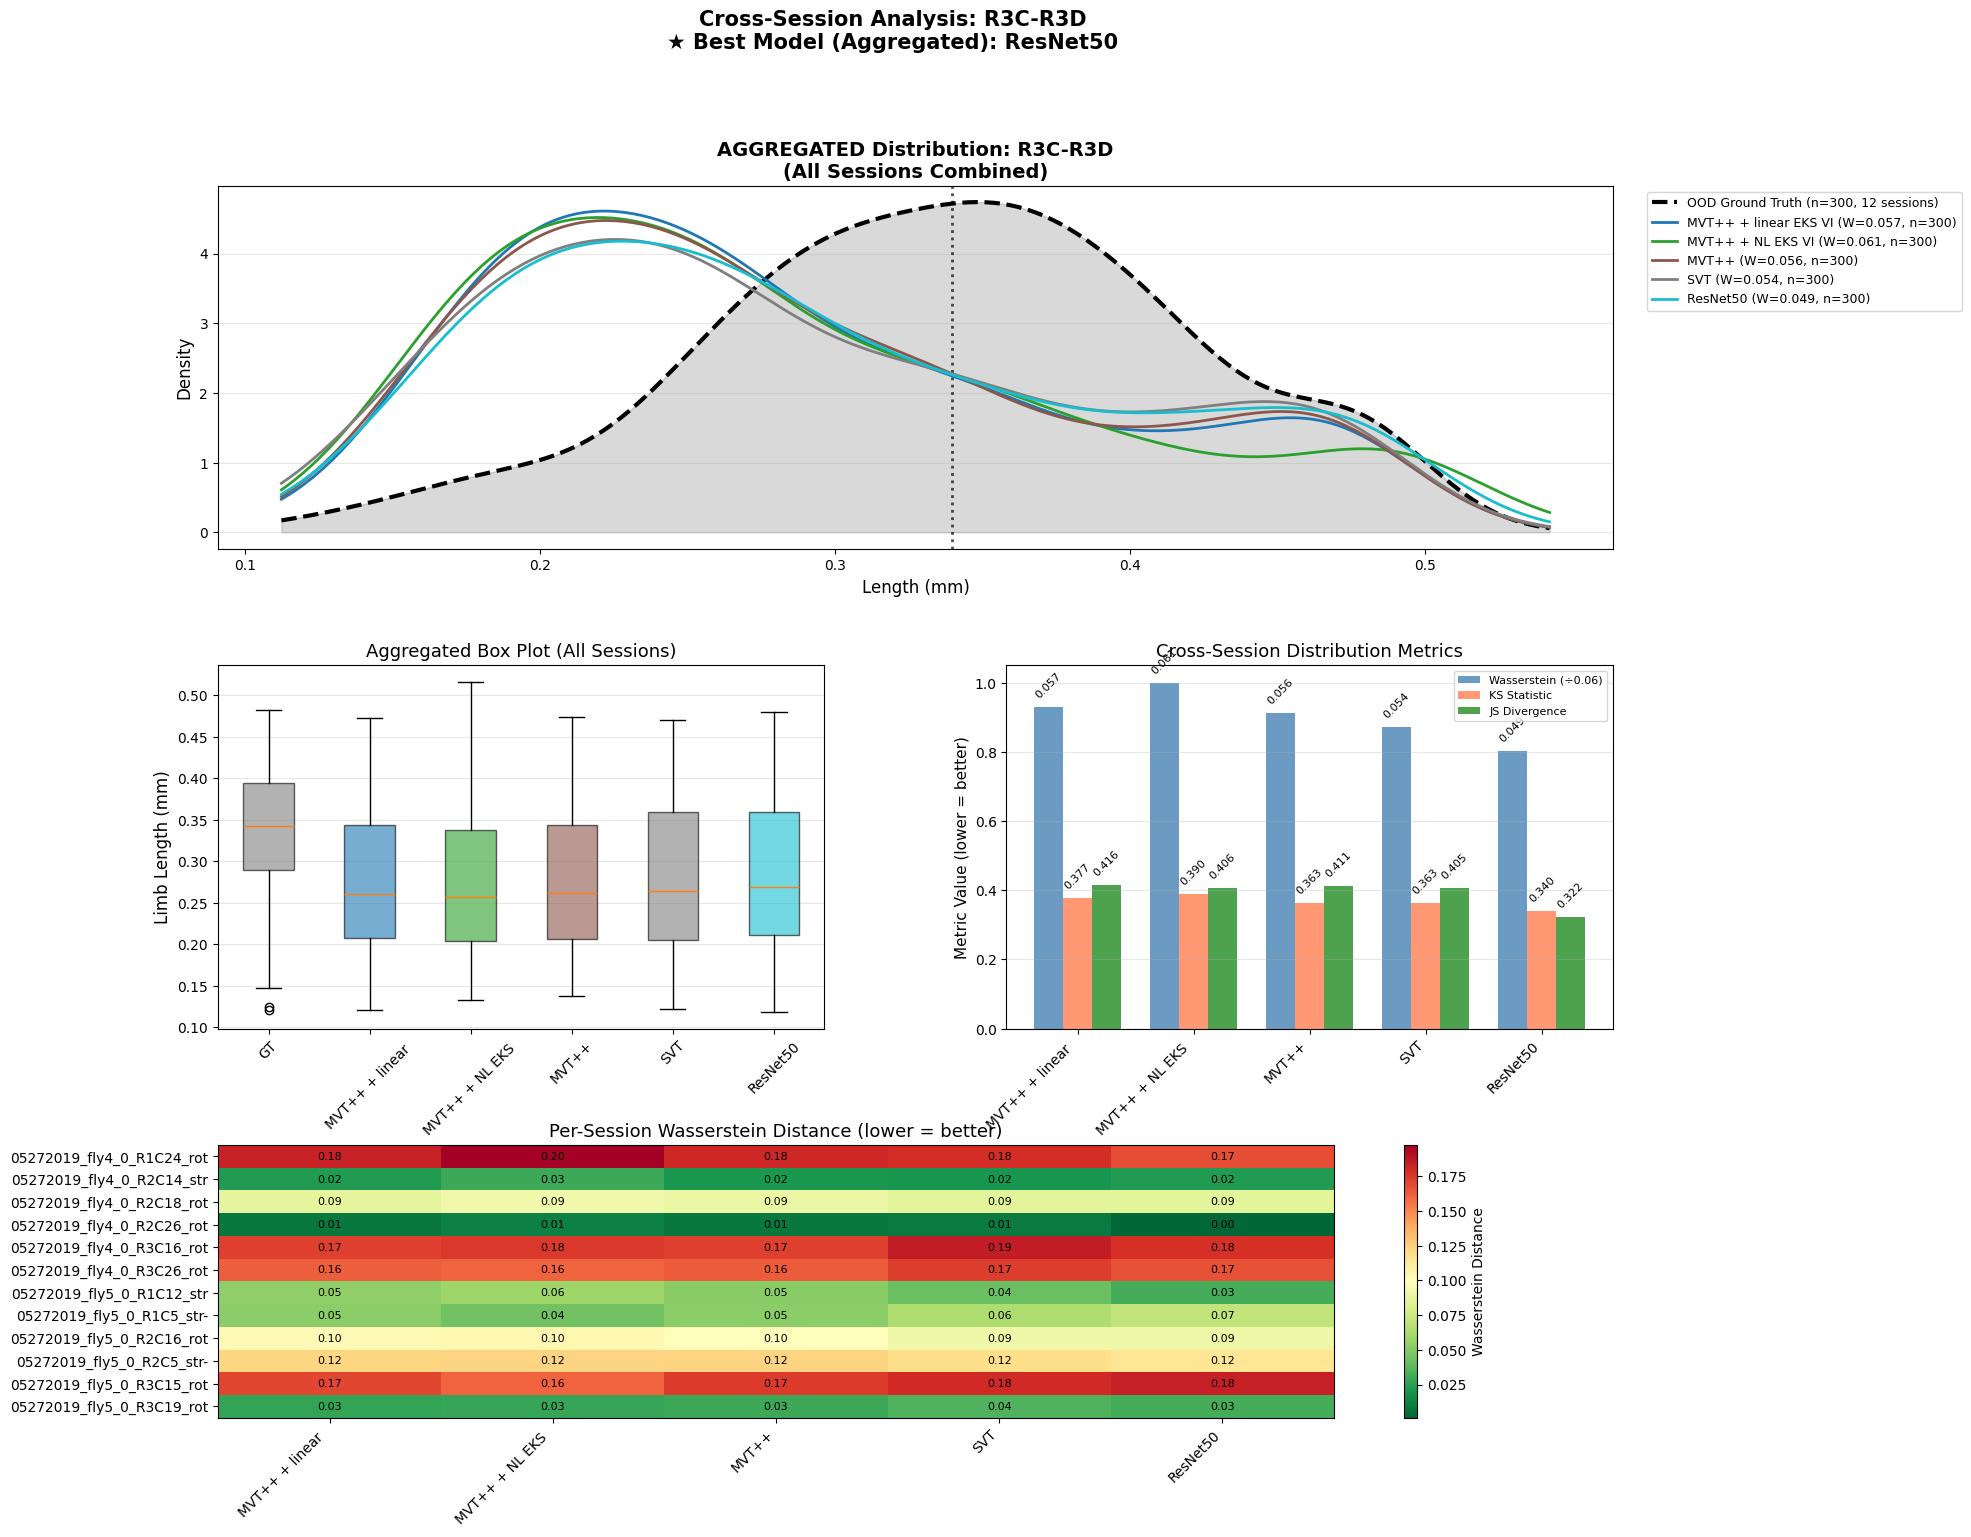


CROSS-SESSION METRICS SUMMARY


,Model,N_Sessions,N_Frames,Mean,Std,CV,Wasserstein,KS_Stat,JS_Div,Mean_Diff,Rank
0,OOD Ground Truth,12,300,0.339735,0.079066,0.232730,0.000000,0.000000,0.000000,0.000000,-
1,MVT++ + linear EKS VI,12,300,0.282870,0.094477,0.333995,0.057071,0.376667,0.416165,0.056864,4.0
2,MVT++ + NL EKS VI,12,300,0.280372,0.097607,0.348135,0.061406,0.390000,0.405589,0.059363,5.0
3,MVT++,12,300,0.284054,0.095337,0.335632,0.055955,0.363333,0.411174,0.055681,3.0
4,SVT,12,300,0.286477,0.098443,0.343632,0.053575,0.363333,0.405358,0.053258,2.0
5,ResNet50,12,300,0.291143,0.098721,0.339081,0.049314,0.340000,0.321977,0.048592,1.0


In [42]:
# ============================================================================
# Aggregate analysis across all sessions
# ============================================================================

def aggregate_limb_lengths_across_sessions(
    limb_lengths_by_session: Dict[str, Dict[str, np.ndarray]],
    limb_name: str
) -> Tuple[np.ndarray, Dict[str, np.ndarray]]:
    """
    Pool limb length data across all sessions.
    
    Returns:
        - all_lengths: concatenated array of all valid lengths
        - per_session: dict of session_name -> valid lengths (for reference)
    """
    all_lengths = []
    per_session = {}
    
    for session_name, limb_data in limb_lengths_by_session.items():
        if limb_name in limb_data:
            lengths = limb_data[limb_name]
            valid = lengths[~np.isnan(lengths)]
            if len(valid) > 0:
                all_lengths.extend(valid)
                per_session[session_name] = valid
    
    return np.array(all_lengths), per_session


def compute_cross_session_metrics(
    ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
    model_ood_limb_lengths: Dict[str, Dict[str, Dict[str, np.ndarray]]],
    limb_name: str,
    model_names_map: Dict[str, str] = None
) -> pd.DataFrame:
    """
    Compute metrics comparing each model to ground truth across ALL sessions.
    """
    # Aggregate ground truth
    gt_all, gt_per_session = aggregate_limb_lengths_across_sessions(
        ood_gt_limb_lengths, limb_name
    )
    
    if len(gt_all) == 0:
        print(f"No ground truth data for limb: {limb_name}")
        return None
    
    gt_mean = np.mean(gt_all)
    gt_std = np.std(gt_all)
    gt_cv = gt_std / gt_mean if gt_mean > 0 else np.nan
    
    results = []
    
    # Ground truth row
    results.append({
        'Model': 'OOD Ground Truth',
        'N_Sessions': len(gt_per_session),
        'N_Frames': len(gt_all),
        'Mean': gt_mean,
        'Std': gt_std,
        'CV': gt_cv,
        'Wasserstein': 0.0,
        'KS_Stat': 0.0,
        'JS_Div': 0.0,
        'Mean_Diff': 0.0,
    })
    
    # Each model
    for model_name, session_data in model_ood_limb_lengths.items():
        model_all, model_per_session = aggregate_limb_lengths_across_sessions(
            session_data, limb_name
        )
        
        if len(model_all) == 0:
            continue
        
        display_name = model_names_map.get(model_name, model_name) if model_names_map else model_name
        
        # Compute metrics vs ground truth
        metrics = compute_distribution_metrics(model_all, gt_all)
        
        results.append({
            'Model': display_name,
            'N_Sessions': len(model_per_session),
            'N_Frames': len(model_all),
            'Mean': np.mean(model_all),
            'Std': np.std(model_all),
            'CV': np.std(model_all) / np.mean(model_all) if np.mean(model_all) > 0 else np.nan,
            'Wasserstein': metrics['wasserstein'],
            'KS_Stat': metrics['ks_stat'],
            'JS_Div': metrics['js_div'],
            'Mean_Diff': metrics['mean_diff'],
        })
    
    df = pd.DataFrame(results)
    
    # Add ranking (exclude ground truth row)
    model_rows = df[df['Model'] != 'OOD Ground Truth'].copy()
    model_rows['Rank'] = model_rows['Wasserstein'].rank().astype(int)
    df = pd.concat([df[df['Model'] == 'OOD Ground Truth'], model_rows])
    df['Rank'] = df['Rank'].fillna('-')
    
    return df


def plot_cross_session_comparison(
    ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
    model_ood_limb_lengths: Dict[str, Dict[str, Dict[str, np.ndarray]]],
    limb_name: str,
    model_names_map: Dict[str, str] = None,
    models_to_compare: List[str] = None,
    figsize: Tuple[int, int] = (18, 16)
):
    """
    Compare models to ground truth across ALL sessions combined.
    """
    # Filter models if specified
    if models_to_compare:
        filtered_models = {k: v for k, v in model_ood_limb_lengths.items() if k in models_to_compare}
    else:
        filtered_models = model_ood_limb_lengths
    
    # Aggregate ground truth
    gt_all, gt_per_session = aggregate_limb_lengths_across_sessions(
        ood_gt_limb_lengths, limb_name
    )
    
    if len(gt_all) == 0:
        print(f"No ground truth data for limb: {limb_name}")
        return
    
    gt_mean = np.mean(gt_all)
    gt_std = np.std(gt_all)
    gt_cv = gt_std / gt_mean
    
    # Aggregate each model
    model_data = {}
    for model_name, session_data in filtered_models.items():
        model_all, model_per_session = aggregate_limb_lengths_across_sessions(
            session_data, limb_name
        )
        if len(model_all) > 0:
            display_name = model_names_map.get(model_name, model_name) if model_names_map else model_name
            metrics = compute_distribution_metrics(model_all, gt_all)
            model_data[model_name] = {
                'all': model_all,
                'per_session': model_per_session,
                'display_name': display_name,
                'metrics': metrics,
                'cv': np.std(model_all) / np.mean(model_all)
            }
    
    if not model_data:
        print("No model data available")
        return
    
    n_models = len(model_data)
    colors = plt.cm.tab10(np.linspace(0, 1, n_models))
    model_ids = list(model_data.keys())
    
    # Create figure
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(3, 2, figure=fig, hspace=0.35, wspace=0.3, height_ratios=[2, 2, 1.5])
    
    # ===== Plot 1: Aggregated PDF comparison =====
    ax1 = fig.add_subplot(gs[0, :])
    
    kde_gt = stats.gaussian_kde(gt_all)
    x_min = min(np.min(gt_all), min(np.min(model_data[m]['all']) for m in model_ids))
    x_max = max(np.max(gt_all), max(np.max(model_data[m]['all']) for m in model_ids))
    x_range = np.linspace(x_min * 0.95, x_max * 1.05, 300)
    
    ax1.plot(x_range, kde_gt(x_range), color='black', linewidth=3, linestyle='--',
             label=f'OOD Ground Truth (n={len(gt_all)}, {len(gt_per_session)} sessions)')
    ax1.fill_between(x_range, kde_gt(x_range), alpha=0.15, color='black')
    ax1.axvline(gt_mean, color='black', linestyle=':', linewidth=2, alpha=0.7)
    
    for i, m_id in enumerate(model_ids):
        m = model_data[m_id]
        kde = stats.gaussian_kde(m['all'])
        wass = m['metrics']['wasserstein']
        ax1.plot(x_range, kde(x_range), color=colors[i], linewidth=2,
                 label=f"{m['display_name']} (W={wass:.3f}, n={len(m['all'])})")
    
    ax1.set_title(f"AGGREGATED Distribution: {limb_name}\n(All Sessions Combined)", fontsize=14, fontweight='bold')
    ax1.set_xlabel("Length (mm)", fontsize=12)
    ax1.set_ylabel("Density", fontsize=12)
    ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
    ax1.grid(axis='y', alpha=0.3)
    
    # ===== Plot 2: Per-session box plots =====
    ax2 = fig.add_subplot(gs[1, 0])
    
    # Collect data for box plot: GT + each model, grouped by session
    all_sessions = sorted(gt_per_session.keys())
    
    # For simplicity, show aggregated box plot
    box_data = [gt_all] + [model_data[m]['all'] for m in model_ids]
    box_labels = ['GT'] + [model_data[m]['display_name'][:15] for m in model_ids]
    box_colors = ['gray'] + list(colors)
    
    bp = ax2.boxplot(box_data, labels=box_labels, patch_artist=True)
    for patch, color in zip(bp['boxes'], box_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    
    ax2.set_ylabel("Limb Length (mm)", fontsize=12)
    ax2.set_title("Aggregated Box Plot (All Sessions)", fontsize=13)
    ax2.tick_params(axis='x', rotation=45)
    ax2.grid(axis='y', alpha=0.3)
    
    # ===== Plot 3: Metrics comparison =====
    ax3 = fig.add_subplot(gs[1, 1])
    
    x = np.arange(n_models)
    width = 0.25
    
    wass_vals = [model_data[m]['metrics']['wasserstein'] for m in model_ids]
    ks_vals = [model_data[m]['metrics']['ks_stat'] for m in model_ids]
    js_vals = [model_data[m]['metrics']['js_div'] for m in model_ids]
    
    wass_max = max(wass_vals) if max(wass_vals) > 0 else 1
    wass_norm = [w / wass_max for w in wass_vals]
    
    bars1 = ax3.bar(x - width, wass_norm, width, label=f'Wasserstein (÷{wass_max:.2f})', color='steelblue', alpha=0.8)
    bars2 = ax3.bar(x, ks_vals, width, label='KS Statistic', color='coral', alpha=0.8)
    bars3 = ax3.bar(x + width, js_vals, width, label='JS Divergence', color='forestgreen', alpha=0.8)
    
    for bars, vals in [(bars1, wass_vals), (bars2, ks_vals), (bars3, js_vals)]:
        for bar, val in zip(bars, vals):
            height = bar.get_height()
            ax3.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=8, rotation=45)
    
    ax3.set_ylabel('Metric Value (lower = better)', fontsize=11)
    ax3.set_title('Cross-Session Distribution Metrics', fontsize=13)
    ax3.set_xticks(x)
    ax3.set_xticklabels([model_data[m]['display_name'][:15] for m in model_ids], rotation=45, ha='right')
    ax3.legend(loc='upper right', fontsize=8)
    ax3.grid(axis='y', alpha=0.3)
    
    # ===== Plot 4: Per-session Wasserstein heatmap =====
    ax4 = fig.add_subplot(gs[2, :])
    
    # Compute per-session metrics
    session_metrics = []
    for session in all_sessions:
        if session in gt_per_session:
            gt_sess = gt_per_session[session]
            row = {'Session': session[:25]}
            for m_id in model_ids:
                if session in model_data[m_id]['per_session']:
                    pred_sess = model_data[m_id]['per_session'][session]
                    wass = wasserstein_distance(pred_sess, gt_sess)
                    row[model_data[m_id]['display_name'][:15]] = wass
                else:
                    row[model_data[m_id]['display_name'][:15]] = np.nan
            session_metrics.append(row)
    
    if session_metrics:
        df_heatmap = pd.DataFrame(session_metrics).set_index('Session')
        
        # Create heatmap
        im = ax4.imshow(df_heatmap.values, cmap='RdYlGn_r', aspect='auto')
        
        ax4.set_xticks(np.arange(len(df_heatmap.columns)))
        ax4.set_yticks(np.arange(len(df_heatmap.index)))
        ax4.set_xticklabels(df_heatmap.columns, rotation=45, ha='right')
        ax4.set_yticklabels(df_heatmap.index)
        
        # Add values
        for i in range(len(df_heatmap.index)):
            for j in range(len(df_heatmap.columns)):
                val = df_heatmap.iloc[i, j]
                if not np.isnan(val):
                    ax4.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8)
        
        plt.colorbar(im, ax=ax4, label='Wasserstein Distance')
        ax4.set_title('Per-Session Wasserstein Distance (lower = better)', fontsize=13)
    
    # Best model
    best_idx = np.argmin(wass_vals)
    best_model = model_data[model_ids[best_idx]]['display_name']
    
    plt.suptitle(f"Cross-Session Analysis: {limb_name}\n★ Best Model (Aggregated): {best_model}", 
                 fontsize=15, fontweight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0, 0.95, 0.96])
    plt.show()
    
    # Return metrics dataframe
    return compute_cross_session_metrics(
        ood_gt_limb_lengths, filtered_models, limb_name, model_names_map
    )

# Define which models to compare
model_names_map = {
    'test_200_multiview_resnet50_ensemble_median': 'ResNet50',
    'test_200_SV_vits_dino_ensemble_median': 'SVT',
    'test_200_MVT_3d_loss_patch_masking_ensemble_median': 'MVT++',
    'test_200_MVT_3d_loss_patch_masking_non_linear_eks_varinf': 'MVT++ + NL EKS VI',
    'test_200_MVT_3d_loss_patch_masking_eks_multiview_varinf': 'MVT++ + linear EKS VI',
}

models_to_compare = list(model_names_map.keys())
limb_to_plot = 'R3C-R3D'

# Run cross-session comparison
metrics_df = plot_cross_session_comparison(
    ood_gt_limb_lengths=ood_limb_lengths_by_session,
    model_ood_limb_lengths=model_ood_limb_lengths,
    limb_name=limb_to_plot,
    model_names_map=model_names_map,
    models_to_compare=models_to_compare
)

# Display metrics table
print("\n" + "="*80)
print("CROSS-SESSION METRICS SUMMARY")
print("="*80)
display(metrics_df)


Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    heatmap_tracker                                                  \
bodyparts             L1A                     L1B                     L1C   
coords                  x           y           x           y           x   
0              192.163498  159.607727  209.222961  198.956619  159.877899   
1              192.618958  159.649796  208.664093  198.841446  157.546570   
2              192.818390  159.314774  207.079269  199.412216  155.419464   
3              194.173080  159.709442  205.001068  200.642822  151.826416   
4              195.443039  160.341568  202.406662  201.862259  148.332458   
..                    ...         ...         ...         ...         ...   
596            192.135056  162.416306  207.782166  202.70509

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec
INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec


Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    heatmap_tracker                                                  \
bodyparts             L1A                     L1B                     L1C   
coords                  x           y           x           y           x   
0              190.714890  162.196213  206.967072  201.658569  159.209244   
1              190.447205  162.150299  205.333435  201.127335  157.119492   
2              190.236221  162.335464  203.987579  201.124939  155.414734   
3              190.723892  162.122299  200.455200  200.841705  152.106827   
4              191.534027  162.595306  197.728165  200.980484  147.351059   
..                    ...         ...         ...         ...         ...   
596            191.511978  162.739044  208.698853  202.60743

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec


Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    heatmap_multiview_transformer_tracker                          \
bodyparts                                   L1A                     L1B   
coords                                        x           y           x   
0                                    194.659622  161.858521  208.931259   
1                                    194.364914  161.702637  207.243515   
2                                    194.021652  161.870987  204.975388   
3                                    194.010498  162.082169  203.052704   
4                                    194.123932  162.484924  200.381393   
..                                          ...         ...         ...   
596                                  192.571594  162.737610  206.961288   
597

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec


... (2 outputs left out)

Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    ensemble-kalman_tracker                                      \
bodyparts                     L1A                     L1B               
coords                          x           y           x           y   
0                      194.286450  162.370802  207.065778  200.710478   
1                      193.951880  162.311181  206.810470  200.787713   
2                      193.961654  162.440906  205.782398  200.853834   
3                      193.919149  162.305291  203.697747  200.834779   
4                      193.591955  162.859407  201.439741  201.270781   
..                            ...         ...         ...         ...   
596                    192.595037  162.752149  206.947498  202.976619   
597                    

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec


Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    ensemble-kalman_tracker                                      \
bodyparts                     L1A                     L1B               
coords                          x           y           x           y   
0                      195.903137  162.581848  209.359650  200.943787   
1                      195.547638  162.906647  208.582031  201.203629   
2                      195.582153  162.925079  206.810730  201.461823   
3                      195.431885  162.203857  204.115738  201.040939   
4                      194.764221  162.820816  202.105911  200.820404   
..                            ...         ...         ...         ...   
596                    193.202103  162.743469  208.241287  202.816269   
597                    

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec
/tmp/ipykernel_17080/2241945047.py:115: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.97]) # Make room for legend


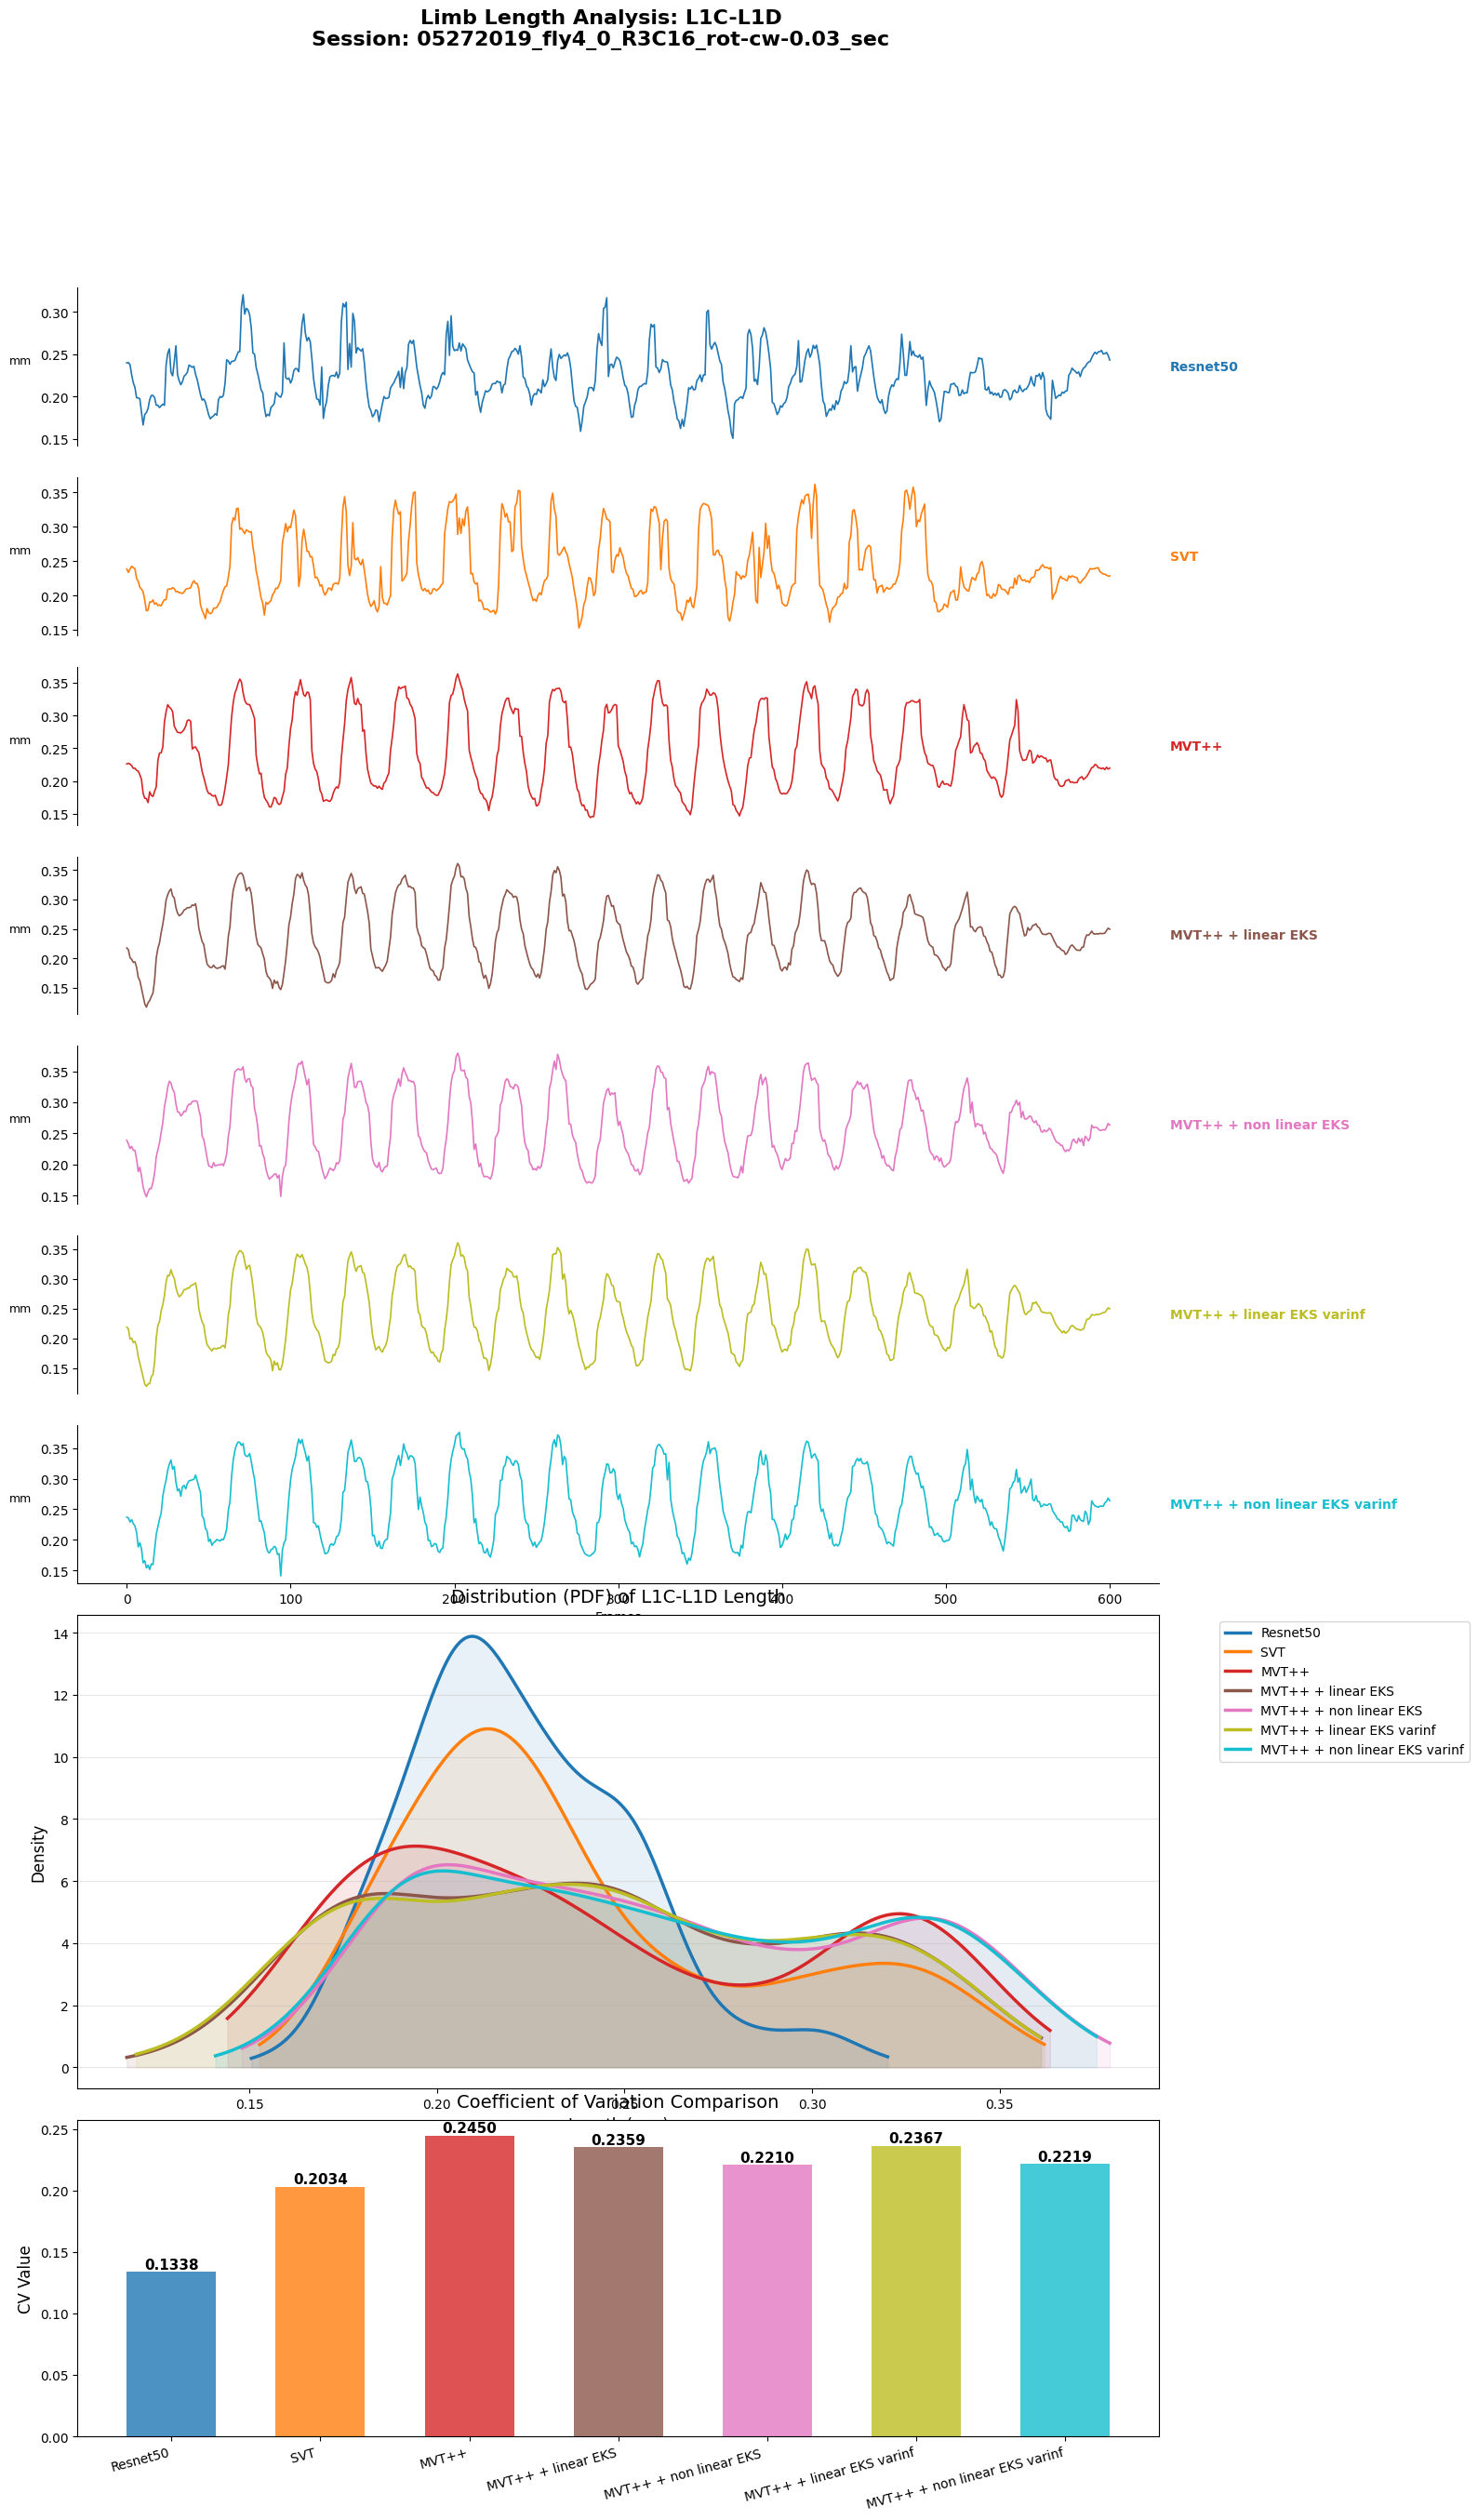

Trying to run bundle adjustment for the other sessions

# This is running the optimized BA

In [140]:
import subprocess
from pathlib import Path
import os

# Paths
FLY_DATA_DIR = "/teamspace/studios/data/fly-anipose"
FLY_CALIB_DIR = "/teamspace/studios/data/fly-anipose/calibrations"
OUTPUT_CALIB_DIR = "/teamspace/studios/this_studio/outputs/fly-anipose/calibrations_ba"
BA_SCRIPT = "/teamspace/studios/this_studio/bundle_adjust_simple.py"

# OOD CSV files (one per view)
FLY_OOD_CSV_FILES = [
    f"{FLY_DATA_DIR}/CollectedData_Cam-A_new.csv",
    f"{FLY_DATA_DIR}/CollectedData_Cam-B_new.csv",
    f"{FLY_DATA_DIR}/CollectedData_Cam-C_new.csv",
    f"{FLY_DATA_DIR}/CollectedData_Cam-D_new.csv",
    f"{FLY_DATA_DIR}/CollectedData_Cam-E_new.csv",
    f"{FLY_DATA_DIR}/CollectedData_Cam-F_new.csv",
]

FLY_VIEW_NAMES = ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E', 'Cam-F']


def get_ood_sessions_fly(csv_path: str, views: List[str]) -> List[str]:
    """Extract unique session names from OOD CSV file."""
    import pandas as pd
    import re
    
    df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
    sessions = set()
    
    for idx in df.index:
        # Extract session name from path like:
        # labeled-data/05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec/img00000014.png
        parts = idx.split('/')
        if len(parts) >= 2:
            folder = parts[1] if parts[0] == 'labeled-data' else parts[0]
            # Remove view name to get session ID
            session = folder
            for view in views:
                session = session.replace(f'_{view}', '').replace(f'{view}_', '')
            sessions.add(session)
    
    return sorted(list(sessions))


In [144]:
def load_2d_points_for_ba(session_name: str, views: List[str], ood_paths: Dict[str, str]) -> np.ndarray:
    """
    Load 2D points for bundle adjustment.
    Returns array of shape (n_views, n_points, 2) where n_points = n_frames * n_keypoints
    """
    view_data = {}
    
    for view in views:
        df = pd.read_csv(ood_paths[view], header=[0, 1, 2], index_col=0)
        
        # Filter to this session - FIXED: account for camera name in path
        # Session name: 05272019_fly4_0_R2C26_rot-ccw-0.18_sec
        # Index format: labeled-data/05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec/img...
        # Split session name and search for parts before and after camera
        parts = session_name.rsplit('_', 1)  # Split on last underscore to get action
        if len(parts) == 2:
            base_name = parts[0]  # e.g., 05272019_fly4_0_R2C26_rot-ccw-0.18
            # Actually we need a smarter split - find where the action starts
            # Pattern: YYMMDD_flyX_0_RXCYY_action_sec
            # Let's split on known action prefixes
            import re
            # Match pattern: everything before (rot|str) and everything from (rot|str) onwards
            match = re.match(r'(.+?)_((?:rot|str)-.+)', session_name)
            if match:
                prefix = match.group(1)  # e.g., 05272019_fly4_0_R2C26
                action = match.group(2)   # e.g., rot-ccw-0.18_sec
                # Build pattern that allows any camera name in between
                pattern = re.escape(prefix) + r'_Cam-[A-F]_' + re.escape(action)
                mask = df.index.str.contains(pattern, regex=True)
            else:
                # Fallback to simple contains
                mask = df.index.str.contains(session_name)
        else:
            mask = df.index.str.contains(session_name)
        
        df_session = df[mask]
        
        if len(df_session) == 0:
            return None
        
        # Get scorer name
        scorer = df_session.columns.get_level_values(0)[0]
        
        # Extract x, y columns
        xy_cols = [c for c in df_session.columns if c[2] in ('x', 'y')]
        data = df_session[xy_cols].values
        
        n_frames = len(df_session)
        n_keypoints = len(xy_cols) // 2
        
        # Reshape to (n_frames * n_keypoints, 2)
        data_reshaped = data.reshape(n_frames * n_keypoints, 2)
        view_data[view] = data_reshaped
    
    # Stack to (n_views, n_points, 2)
    p2ds = np.stack([view_data[v] for v in views])
    
    return p2ds

In [146]:
# ============================================================================
# DIAGNOSE CALIBRATION QUALITY FIRST
# ============================================================================

def diagnose_calibration_quality(
    session_name: str,
    views: List[str],
    ood_paths: Dict[str, str],
    calib_dir: str
):
    """
    Diagnose calibration quality for a session WITHOUT modifying it.
    """
    from aniposelib.cameras import CameraGroup
    
    print(f"\n{'='*60}")
    print(f"DIAGNOSIS: {session_name}")
    print(f"{'='*60}")
    
    # Load calibration
    calib_file = Path(calib_dir) / f"{session_name}.toml"
    if not calib_file.exists():
        print(f"  ❌ Calibration file not found!")
        return None
    
    cg = CameraGroup.load(str(calib_file))
    
    # Load 2D points
    p2ds = load_2d_points_for_ba(session_name, views, ood_paths)
    if p2ds is None:
        print(f"  ❌ No data found for this session")
        return None
    
    # Remove NaN
    nan_mask = np.any(np.isnan(p2ds), axis=(0, 2))
    p2ds_clean = p2ds[:, ~nan_mask, :]
    print(f"  Valid points: {p2ds_clean.shape[1]}")
    
    # Triangulate
    p3ds = cg.triangulate(p2ds_clean, fast=True)
    
    # Reprojection error
    reproj_error = cg.reprojection_error(p3ds, p2ds_clean)
    
    print(f"\n  Reprojection Error per Camera:")
    print(f"  {'Camera':<10} {'Mean':>10} {'Median':>10} {'Max':>10} {'Std':>10}")
    print(f"  {'-'*50}")
    
    for i, view in enumerate(views):
        err = np.linalg.norm(reproj_error[i], axis=1)
        print(f"  {view:<10} {np.mean(err):>10.2f} {np.median(err):>10.2f} {np.max(err):>10.2f} {np.std(err):>10.2f}")
    
    overall_mean = np.mean(np.linalg.norm(reproj_error, axis=2))
    print(f"\n  Overall mean reprojection error: {overall_mean:.2f} pixels")
    
    # Check 3D point validity
    valid_3d = ~np.any(np.isnan(p3ds), axis=1)
    print(f"  Valid 3D points: {np.sum(valid_3d)} / {len(p3ds)}")
    
    # Check 3D point scale
    if np.sum(valid_3d) > 0:
        p3ds_valid = p3ds[valid_3d]
        ranges = p3ds_valid.max(axis=0) - p3ds_valid.min(axis=0)
        print(f"\n  3D Bounding Box:")
        print(f"    X range: {ranges[0]:.2f}")
        print(f"    Y range: {ranges[1]:.2f}")
        print(f"    Z range: {ranges[2]:.2f}")
    
    # Assessment
    print(f"\n  ASSESSMENT:")
    if overall_mean < 2:
        print(f"    ✓ Reprojection error is GOOD (<2 pixels)")
    elif overall_mean < 5:
        print(f"    ⚠️ Reprojection error is MODERATE (2-5 pixels)")
        print(f"       Bundle adjustment may help slightly")
    elif overall_mean < 10:
        print(f"    ⚠️ Reprojection error is HIGH (5-10 pixels)")
        print(f"       Bundle adjustment recommended")
    else:
        print(f"    ❌ Reprojection error is VERY HIGH (>10 pixels)")
        print(f"       Check for labeling errors or bad initial calibration")
    
    return {
        'session': session_name,
        'mean_error': overall_mean,
        'error_per_cam': [np.mean(np.linalg.norm(reproj_error[i], axis=1)) for i in range(len(views))],
        'n_points': p2ds_clean.shape[1]
    }


# Diagnose all sessions first
print("="*80)
print("CALIBRATION QUALITY DIAGNOSIS")
print("="*80)

diagnosis_results = []
sessions = get_ood_sessions_fly(FLY_OOD_CSV_FILES[0], FLY_VIEW_NAMES)

for session in sessions:
    result = diagnose_calibration_quality(
        session, FLY_VIEW_NAMES, FLY_OOD_PATHS, FLY_CALIB_DIR
    )
    if result:
        diagnosis_results.append(result)

# Summary
print("\n" + "="*80)
print("DIAGNOSIS SUMMARY")
print("="*80)
print(f"\n{'Session':<50} {'Mean Error':>12} {'N Points':>10}")
print("-"*75)
for r in diagnosis_results:
    status = "✓" if r['mean_error'] < 5 else "⚠️" if r['mean_error'] < 10 else "❌"
    print(f"{r['session']:<50} {r['mean_error']:>10.2f} px {r['n_points']:>10} {status}")

CALIBRATION QUALITY DIAGNOSIS

DIAGNOSIS: 05272019_fly4_0_R1C24_rot-ccw-0.06_sec
  Valid points: 750

  Reprojection Error per Camera:
  Camera           Mean     Median        Max        Std
  --------------------------------------------------
  Cam-A            0.39       0.33       1.31       0.25
  Cam-B            0.24       0.19       1.62       0.22
  Cam-C            0.50       0.42       2.02       0.36
  Cam-D            0.19       0.12       1.90       0.19
  Cam-E            0.16       0.13       1.27       0.15
  Cam-F            0.48       0.38       3.93       0.42

  Overall mean reprojection error: 0.33 pixels
  Valid 3D points: 750 / 750

  3D Bounding Box:
    X range: 1.02
    Y range: 0.92
    Z range: 0.90

  ASSESSMENT:
    ✓ Reprojection error is GOOD (<2 pixels)

DIAGNOSIS: 05272019_fly4_0_R2C14_str-ccw-0.72_sec
  Valid points: 750

  Reprojection Error per Camera:
  Camera           Mean     Median        Max        Std
  --------------------------------------

In [156]:
import numpy as np
from scipy.optimize import minimize
from aniposelib.cameras import CameraGroup
from typing import List, Dict, Tuple
import re

def bundle_adjust_with_limb_regularization_fast(
    session_name: str,
    views: List[str],
    ood_paths: Dict[str, str],
    calib_file: str,
    skeleton: List[Tuple[str, str]],
    keypoint_names: List[str],
    lambda_limb: float = 1.0,
    optimize_intrinsics: bool = False,
    verbose: bool = True,
    max_iter: int = 50
) -> CameraGroup:
    """
    FAST bundle adjustment with limb length variance regularization.
    """
    from aniposelib.cameras import CameraGroup
    from scipy.optimize import minimize
    import copy
    
    # Load initial calibration
    cg = CameraGroup.load(calib_file)
    n_cams = len(cg.cameras)
    
    # Load 2D points: (n_cams, n_frames, n_kpts, 2)
    p2ds = load_2d_points_for_ba_structured(session_name, views, ood_paths, keypoint_names)
    if p2ds is None:
        print(f"No data found for {session_name}")
        return None
    
    n_frames = p2ds.shape[1]
    n_kpts = len(keypoint_names)
    n_points = n_frames * n_kpts
    
    if verbose:
        print(f"Loaded {n_frames} frames, {n_kpts} keypoints, {n_cams} cameras")
    
    # Build limb index pairs
    limb_indices = np.array([
        [keypoint_names.index(kp1), keypoint_names.index(kp2)]
        for kp1, kp2 in skeleton
        if kp1 in keypoint_names and kp2 in keypoint_names
    ])
    n_limbs = len(limb_indices)
    
    if verbose:
        print(f"Using {n_limbs} limbs for regularization")
    
    # Flatten 2D points for triangulation: (n_cams, n_points, 2)
    p2ds_flat = p2ds.reshape(n_cams, n_points, 2)
    
    iteration_count = [0]
    
    def objective(params):
        iteration_count[0] += 1
        
        # Update cameras from params (only extrinsics)
        cg_temp = copy.deepcopy(cg)
        for i, cam in enumerate(cg_temp.cameras):
            offset = i * 6
            cam.set_rotation(params[offset:offset+3])
            cam.set_translation(params[offset+3:offset+6])
        
        # Triangulate all valid points at once
        p3ds_flat = cg_temp.triangulate(p2ds_flat, fast=True)  # (n_points, 3)
        
        # Compute reprojection error (vectorized)
        reproj_error = 0.0
        n_valid_reproj = 0
        
        for c, cam in enumerate(cg_temp.cameras):
            # Project all 3D points
            p2d_proj = cam.project(p3ds_flat)
            
            # Force to shape (n_points, 2)
            p2d_proj = np.atleast_2d(p2d_proj)
            if p2d_proj.shape[-1] != 2:
                p2d_proj = p2d_proj.T
            p2d_proj = p2d_proj.reshape(-1, 2)
            
            p2d_obs = p2ds_flat[c]  # (n_points, 2)
            
            # Create masks for valid points
            valid_mask = np.ones(n_points, dtype=bool)
            
            # Check observations
            for i in range(n_points):
                if np.any(np.isnan(p2d_obs[i])) or np.any(np.isnan(p2d_proj[i])):
                    valid_mask[i] = False
            
            # Compute error for valid points only
            if np.any(valid_mask):
                diff = p2d_proj[valid_mask] - p2d_obs[valid_mask]  # (n_valid, 2)
                reproj_error += np.sum(diff**2)
                n_valid_reproj += np.sum(valid_mask)
        
        if n_valid_reproj > 0:
            reproj_error /= n_valid_reproj
        
        # Compute limb length variance (vectorized)
        p3ds = p3ds_flat.reshape(n_frames, n_kpts, 3)
        limb_variance_penalty = 0.0
        
        for idx1, idx2 in limb_indices:
            p1 = p3ds[:, idx1, :]  # (n_frames, 3)
            p2 = p3ds[:, idx2, :]  # (n_frames, 3)
            
            # Compute lengths for all frames at once
            lengths = np.linalg.norm(p1 - p2, axis=1)  # (n_frames,)
            
            # Filter valid lengths
            valid = (lengths > 0) & (lengths < 1e6) & ~np.isnan(lengths)
            if np.sum(valid) > 1:
                valid_lengths = lengths[valid]
                cv = np.std(valid_lengths) / np.mean(valid_lengths)
                limb_variance_penalty += cv**2
        
        total_loss = reproj_error + lambda_limb * limb_variance_penalty
        
        # Print progress every 10 iterations
        if verbose and iteration_count[0] % 10 == 0:
            print(f"  Iter {iteration_count[0]}: reproj={np.sqrt(reproj_error):.4f}px, limb_cv={limb_variance_penalty:.4f}")
        
        return total_loss
    
    # Get initial parameters (extrinsics only: 6 params per camera)
    params_init = []
    for cam in cg.cameras:
        params_init.extend(cam.get_rotation().flatten())
        params_init.extend(cam.get_translation().flatten())
    params_init = np.array(params_init)
    
    if verbose:
        init_loss = objective(params_init)
        print(f"\nInitial loss: {init_loss:.6f}")
        print(f"Optimizing with lambda_limb={lambda_limb}...")
        iteration_count[0] = 0
    
    # Run optimization
    result = minimize(
        objective,
        params_init,
        method='L-BFGS-B',
        options={'maxiter': max_iter, 'disp': False}
    )
    
    # Build optimized camera group
    cg_optimized = copy.deepcopy(cg)
    for i, cam in enumerate(cg_optimized.cameras):
        offset = i * 6
        cam.set_rotation(result.x[offset:offset+3])
        cam.set_translation(result.x[offset+3:offset+6])
    
    if verbose:
        final_loss = objective(result.x)
        print(f"\nFinal loss: {final_loss:.6f} after {iteration_count[0]} iterations")
    
    return cg_optimized


def load_2d_points_for_ba_structured(
    session_name: str, 
    views: List[str], 
    ood_paths: Dict[str, str],
    keypoint_names: List[str]
) -> np.ndarray:
    """
    Load 2D points structured as (n_cams, n_frames, n_keypoints, 2).
    """
    import re
    
    # Parse session name for matching
    match = re.match(r'(.+?)_((?:rot|str)-.+)', session_name)
    if match:
        prefix = match.group(1)
        action = match.group(2)
        pattern = re.escape(prefix) + r'_Cam-[A-F]_' + re.escape(action)
    else:
        pattern = re.escape(session_name)
    
    view_data = {}
    frame_indices = None
    
    for view in views:
        df = pd.read_csv(ood_paths[view], header=[0, 1, 2], index_col=0)
        
        # Filter to session
        mask = df.index.str.contains(pattern, regex=True)
        df_session = df[mask]
        
        if len(df_session) == 0:
            return None
        
        # Store frame indices for consistency check
        if frame_indices is None:
            frame_indices = df_session.index.tolist()
        
        # Get scorer
        scorer = df_session.columns.get_level_values(0)[0]
        
        # Extract data for each keypoint
        n_frames = len(df_session)
        n_kpts = len(keypoint_names)
        data = np.full((n_frames, n_kpts, 2), np.nan)
        
        for k, kp in enumerate(keypoint_names):
            try:
                x = df_session[(scorer, kp, 'x')].values
                y = df_session[(scorer, kp, 'y')].values
                data[:, k, 0] = x
                data[:, k, 1] = y
            except KeyError:
                pass  # Keypoint not found, leave as NaN
        
        view_data[view] = data
    
    # Stack: (n_cams, n_frames, n_keypoints, 2)
    p2ds = np.stack([view_data[v] for v in views])
    
    return p2ds


def cameras_to_params(cg: CameraGroup, include_intrinsics: bool = False) -> np.ndarray:
    """Convert CameraGroup to parameter vector."""
    params = []
    
    for cam in cg.cameras:
        # Extrinsics: rotation (3) + translation (3)
        rvec = cam.get_rotation()
        tvec = cam.get_translation()
        params.extend(rvec.flatten())
        params.extend(tvec.flatten())
        
        if include_intrinsics:
            # Intrinsics: fx, fy, cx, cy + distortion (5)
            mtx = cam.get_camera_matrix()
            params.extend([mtx[0, 0], mtx[1, 1], mtx[0, 2], mtx[1, 2]])
            dist = cam.get_distortions()
            params.extend(dist.flatten()[:5])
    
    return np.array(params)


def params_to_cameras(params: np.ndarray, cg_template: CameraGroup, include_intrinsics: bool = False) -> CameraGroup:
    """Convert parameter vector back to CameraGroup."""
    import copy
    
    cg_new = copy.deepcopy(cg_template)
    
    params_per_cam = 6 if not include_intrinsics else 15  # 6 extrinsic or 6 + 4 intrinsic + 5 distortion
    
    for i, cam in enumerate(cg_new.cameras):
        offset = i * params_per_cam
        
        # Extrinsics
        rvec = params[offset:offset+3]
        tvec = params[offset+3:offset+6]
        cam.set_rotation(rvec)
        cam.set_translation(tvec)
        
        if include_intrinsics:
            # Intrinsics
            fx, fy, cx, cy = params[offset+6:offset+10]
            mtx = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]])
            cam.set_camera_matrix(mtx)
            
            dist = params[offset+10:offset+15]
            cam.set_distortions(dist)
    
    return cg_new


# =============================================================================
# Run optimization for all sessions
# =============================================================================
def run_limb_regularized_ba(
    sessions: List[str],
    views: List[str],
    ood_paths: Dict[str, str],
    calib_dir: str,
    output_dir: str,
    skeleton: List[Tuple[str, str]],
    keypoint_names: List[str],
    lambda_limb: float = 1.0
):
    """Run limb-regularized BA for all sessions."""
    from pathlib import Path
    
    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)
    
    results = {}
    
    for session in sessions:
        print(f"\n{'='*70}")
        print(f"Processing: {session}")
        print(f"{'='*70}")
        
        calib_file = Path(calib_dir) / f"{session}.toml"
        if not calib_file.exists():
            print(f"  Calibration not found: {calib_file}")
            continue
        
        cg_optimized = bundle_adjust_with_limb_regularization_fast(
            session_name=session,
            views=views,
            ood_paths=ood_paths,
            calib_file=str(calib_file),
            skeleton=skeleton,
            keypoint_names=keypoint_names,
            lambda_limb=lambda_limb,
            optimize_intrinsics=False,
            verbose=True
        )
        
        if cg_optimized is not None:
            # Save optimized calibration
            output_file = output_path / f"{session}_limb_reg.toml"
            cg_optimized.dump(str(output_file))
            print(f"  Saved: {output_file}")
            results[session] = cg_optimized
    
    return results

In [ ]:
# ============================================================================
# COMPLETE BUNDLE ADJUSTMENT WITH FIXED INTRINSICS & LIMB REGULARIZATION
# ============================================================================

import numpy as np
import pandas as pd
from pathlib import Path
from typing import List, Dict, Tuple
from aniposelib.cameras import CameraGroup
from scipy.optimize import minimize
import copy
import re

# ============================================================================
# CONFIGURATION
# ============================================================================

# Sessions to process
SELECTED_SESSIONS = [
    "05272019_fly4_0_R1C24_rot-ccw-0.06_sec",
    "05272019_fly4_0_R2C14_str-ccw-0.72_sec"
]

# Paths
FLY_DATA_DIR = "/teamspace/studios/data/fly-anipose"
ORIGINAL_CALIB_DIR = "/teamspace/studios/data/fly-anipose/calibrations"
OUTPUT_CALIB_DIR = "/teamspace/studios/this_studio/outputs/fly-anipose/calibrations_ba_fixed_intrinsics"

# Views
VIEWS = ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E', 'Cam-F']

# OOD data paths
OOD_PATHS = {view: f"{FLY_DATA_DIR}/CollectedData_{view}_new.csv" for view in VIEWS}

# Keypoints
KEYPOINTS = [
    'L1A', 'L1B', 'L1C', 'L1D', 'L1E',
    'L2A', 'L2B', 'L2C', 'L2D', 'L2E',
    'L3A', 'L3B', 'L3C', 'L3D', 'L3E',
    'R1A', 'R1B', 'R1C', 'R1D', 'R1E',
    'R2A', 'R2B', 'R2C', 'R2D', 'R2E',
    'R3A', 'R3B', 'R3C', 'R3D', 'R3E',
]

# Skeleton
SKELETON = [
    ('L1A', 'L1B'), ('L1B', 'L1C'), ('L1C', 'L1D'), ('L1D', 'L1E'),
    ('L2A', 'L2B'), ('L2B', 'L2C'), ('L2C', 'L2D'), ('L2D', 'L2E'),
    ('L3A', 'L3B'), ('L3B', 'L3C'), ('L3C', 'L3D'), ('L3D', 'L3E'),
    ('R1A', 'R1B'), ('R1B', 'R1C'), ('R1C', 'R1D'), ('R1D', 'R1E'),
    ('R2A', 'R2B'), ('R2B', 'R2C'), ('R2C', 'R2D'), ('R2D', 'R2E'),
    ('R3A', 'R3B'), ('R3B', 'R3C'), ('R3C', 'R3D'), ('R3D', 'R3E'),
]

# ============================================================================
# STEP 1: CHECK INTRINSICS CONSISTENCY
# ============================================================================

def check_intrinsics_consistency(sessions: List[str], calib_dir: str):
    """Check if intrinsics are consistent across sessions."""
    print("="*70)
    print("STEP 1: CHECKING INTRINSICS CONSISTENCY ACROSS SESSIONS")
    print("="*70)
    
    all_intrinsics = {}
    
    for session in sessions:
        cg = CameraGroup.load(f"{calib_dir}/{session}.toml")
        all_intrinsics[session] = []
        
        for cam in cg.cameras:
            mtx = cam.get_camera_matrix()
            all_intrinsics[session].append({
                'fx': mtx[0, 0],
                'fy': mtx[1, 1],
                'cx': mtx[0, 2],
                'cy': mtx[1, 2]
            })
    
    # Compare
    print(f"\nComparing intrinsics for {len(sessions)} sessions:")
    
    for cam_idx in range(len(VIEWS)):
        print(f"\n  Camera {VIEWS[cam_idx]}:")
        fxs = [all_intrinsics[s][cam_idx]['fx'] for s in sessions]
        fys = [all_intrinsics[s][cam_idx]['fy'] for s in sessions]
        
        fx_diff = (max(fxs) - min(fxs)) / np.mean(fxs) * 100
        fy_diff = (max(fys) - min(fys)) / np.mean(fys) * 100
        
        print(f"    fx: {min(fxs):.1f} - {max(fxs):.1f} (diff: {fx_diff:.2f}%)")
        print(f"    fy: {min(fys):.1f} - {max(fys):.1f} (diff: {fy_diff:.2f}%)")
        
        if fx_diff > 1 or fy_diff > 1:
            print(f"    ⚠️  WARNING: >1% difference!")
    
    return all_intrinsics

# ============================================================================
# STEP 2: ENFORCE CONSISTENT INTRINSICS
# ============================================================================

def enforce_consistent_intrinsics(
    sessions: List[str],
    calib_dir: str,
    output_dir: str,
    reference_session: str = None
) -> str:
    """Copy intrinsics from reference session to all sessions."""
    print("\n" + "="*70)
    print("STEP 2: ENFORCING CONSISTENT INTRINSICS")
    print("="*70)
    
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    
    # Use first session as reference
    ref_session = reference_session or sessions[0]
    ref_cg = CameraGroup.load(f"{calib_dir}/{ref_session}.toml")
    
    print(f"\nReference session: {ref_session}")
    print("Reference intrinsics:")
    for i, cam in enumerate(ref_cg.cameras):
        mtx = cam.get_camera_matrix()
        print(f"  {VIEWS[i]}: fx={mtx[0,0]:.1f}, fy={mtx[1,1]:.1f}")
    
    # Apply to all sessions
    print(f"\nApplying to all sessions...")
    for session in sessions:
        cg = CameraGroup.load(f"{calib_dir}/{session}.toml")
        
        for i, (cam, ref_cam) in enumerate(zip(cg.cameras, ref_cg.cameras)):
            # Copy intrinsics only
            cam.set_camera_matrix(ref_cam.get_camera_matrix())
            cam.set_distortions(ref_cam.get_distortions())
            # Extrinsics stay as original
        
        output_file = f"{output_dir}/{session}.toml"
        cg.dump(output_file)
        print(f"  Saved: {session}.toml")
    
    return output_dir

# ============================================================================
# STEP 3: DATA LOADING FUNCTIONS
# ============================================================================

def load_2d_points_for_ba(
    session_name: str,
    views: List[str],
    ood_paths: Dict[str, str],
    keypoint_names: List[str]
) -> np.ndarray:
    """Load 2D points for bundle adjustment. Shape: (n_cams, n_frames, n_kpts, 2)"""
    
    # Parse session name for matching (handle Cam-X in path)
    match = re.match(r'(.+?)_((?:rot|str)-.+)', session_name)
    if match:
        prefix = match.group(1)
        action = match.group(2)
        pattern = re.escape(prefix) + r'_Cam-[A-F]_' + re.escape(action)
    else:
        pattern = re.escape(session_name)
    
    view_data = {}
    n_frames = None
    
    for view in views:
        df = pd.read_csv(ood_paths[view], header=[0, 1, 2], index_col=0)
        
        # Filter to session
        mask = df.index.str.contains(pattern, regex=True)
        df_session = df[mask]
        
        if len(df_session) == 0:
            return None
        
        if n_frames is None:
            n_frames = len(df_session)
        
        # Get scorer
        scorer = df_session.columns.get_level_values(0)[0]
        
        # Extract data
        n_kpts = len(keypoint_names)
        data = np.full((n_frames, n_kpts, 2), np.nan)
        
        for k, kp in enumerate(keypoint_names):
            try:
                data[:, k, 0] = df_session[(scorer, kp, 'x')].values
                data[:, k, 1] = df_session[(scorer, kp, 'y')].values
            except KeyError:
                pass
        
        view_data[view] = data
    
    # Stack: (n_cams, n_frames, n_kpts, 2)
    p2ds = np.stack([view_data[v] for v in views])
    
    return p2ds



In [176]:
def bundle_adjust_extrinsics_only_fast(
    session_name: str,
    views: List[str],
    ood_paths: Dict[str, str],
    calib_file: str,
    skeleton: List[Tuple[str, str]],
    keypoint_names: List[str],
    lambda_limb: float = 10.0,
    lambda_symmetry: float = 5.0,
    verbose: bool = True,
    max_iter: int = 100
) -> CameraGroup:
    """FAST bundle adjustment."""
    
    cg = CameraGroup.load(calib_file)
    n_cams = len(cg.cameras)
    
    p2ds = load_2d_points_for_ba(session_name, views, ood_paths, keypoint_names)
    if p2ds is None:
        print(f"  ❌ No data found for {session_name}")
        return None
    
    n_frames = p2ds.shape[1]
    n_kpts = len(keypoint_names)
    n_points = n_frames * n_kpts
    p2ds_flat = p2ds.reshape(n_cams, n_points, 2)
    
    if verbose:
        print(f"\n  Session: {session_name}")
        print(f"  Data: {n_frames} frames, {n_kpts} keypoints, {n_cams} cameras")
    
    # Build limb pairs
    limb_pairs = []
    for kp1, kp2 in skeleton:
        if kp1 in keypoint_names and kp2 in keypoint_names:
            idx1 = keypoint_names.index(kp1)
            idx2 = keypoint_names.index(kp2)
            limb_pairs.append((idx1, idx2))
    
    # Build symmetry pairs
    symmetry_pairs = []
    for i, (kp1, kp2) in enumerate(skeleton):
        if i >= len(limb_pairs):
            break
        name_l = f"{kp1}-{kp2}"
        if name_l.startswith('L'):
            name_r = 'R' + name_l[1:]
            for j, (kp1_r, kp2_r) in enumerate(skeleton):
                if j >= len(limb_pairs):
                    break
                if f"{kp1_r}-{kp2_r}" == name_r:
                    symmetry_pairs.append((i, j))
                    break
    
    cg_work = copy.deepcopy(cg)
    
    iter_count = [0]
    best_loss = [float('inf')]
    best_params = [None]
    
    def objective(params):
        iter_count[0] += 1
        
        # Update cameras
        for i, cam in enumerate(cg_work.cameras):
            offset = i * 6
            cam.set_rotation(params[offset:offset+3])
            cam.set_translation(params[offset+3:offset+6])
        
        # Triangulate
        p3ds_flat = cg_work.triangulate(p2ds_flat, fast=True)
        
        # 1. Reprojection error - SIMPLE LOOP VERSION (guaranteed to work)
        reproj_loss = 0.0
        n_valid = 0
        
        for c, cam in enumerate(cg_work.cameras):
            p2d_proj_raw = cam.project(p3ds_flat)
            
            # Force to numpy array and flatten/reshape as needed
            p2d_proj_raw = np.asarray(p2d_proj_raw)
            
            # Determine correct shape
            if p2d_proj_raw.size == n_points * 2:
                p2d_proj = p2d_proj_raw.reshape(n_points, 2)
            elif p2d_proj_raw.shape == (2, n_points):
                p2d_proj = p2d_proj_raw.T
            elif p2d_proj_raw.shape == (n_points, 2):
                p2d_proj = p2d_proj_raw
            else:
                # Fallback: try to reshape
                try:
                    p2d_proj = p2d_proj_raw.reshape(n_points, 2)
                except:
                    p2d_proj = p2d_proj_raw.T.reshape(n_points, 2)
            
            p2d_obs = p2ds_flat[c]  # (n_points, 2)
            
            # Check validity point by point
            for pt_idx in range(n_points):
                obs = p2d_obs[pt_idx]
                proj = p2d_proj[pt_idx]
                
                if not np.any(np.isnan(obs)) and not np.any(np.isnan(proj)):
                    reproj_loss += np.sum((obs - proj)**2)
                    n_valid += 1
        
        if n_valid > 0:
            reproj_loss /= n_valid
        
        # 2. Limb variance
        p3ds = p3ds_flat.reshape(n_frames, n_kpts, 3)
        limb_var_loss = 0.0
        limb_lengths = []
        
        for idx1, idx2 in limb_pairs:
            p1 = p3ds[:, idx1, :]
            p2 = p3ds[:, idx2, :]
            lengths = np.linalg.norm(p1 - p2, axis=1)
            limb_lengths.append(lengths)
            
            valid = (lengths > 0) & ~np.isnan(lengths)
            if np.sum(valid) > 1:
                cv = np.std(lengths[valid]) / np.mean(lengths[valid])
                limb_var_loss += cv**2
        
        # 3. Symmetry
        sym_loss = 0.0
        for i_l, i_r in symmetry_pairs:
            len_l = limb_lengths[i_l]
            len_r = limb_lengths[i_r]
            valid = ~np.isnan(len_l) & ~np.isnan(len_r) & (len_l > 0) & (len_r > 0)
            if np.any(valid):
                mean_l = np.mean(len_l[valid])
                mean_r = np.mean(len_r[valid])
                sym_loss += ((mean_l - mean_r) / (mean_l + mean_r + 1e-8))**2
        
        total = reproj_loss + lambda_limb * limb_var_loss + lambda_symmetry * sym_loss
        
        if total < best_loss[0]:
            best_loss[0] = total
            best_params[0] = params.copy()
        
        if verbose and iter_count[0] % 20 == 0:
            print(f"    Iter {iter_count[0]}: reproj={np.sqrt(reproj_loss):.3f}px, cv={limb_var_loss:.4f}")
        
        return total
    
    # Initial parameters
    params_init = []
    for cam in cg.cameras:
        params_init.extend(cam.get_rotation().flatten())
        params_init.extend(cam.get_translation().flatten())
    params_init = np.array(params_init)
    
    if verbose:
        init_loss = objective(params_init)
        print(f"  Initial loss: {init_loss:.4f}")
        iter_count[0] = 0
    
    # Optimize
    result = minimize(
        objective,
        params_init,
        method='L-BFGS-B',
        options={'maxiter': max_iter, 'disp': False, 'gtol': 1e-6}
    )
    
    # Build final
    final_params = best_params[0] if best_params[0] is not None else result.x
    cg_optimized = copy.deepcopy(cg)
    for i, cam in enumerate(cg_optimized.cameras):
        offset = i * 6
        cam.set_rotation(final_params[offset:offset+3])
        cam.set_translation(final_params[offset+3:offset+6])
    
    if verbose:
        final_loss = objective(final_params)
        print(f"  Final loss: {final_loss:.4f} ({iter_count[0]} iters)")
    
    return cg_optimized


# ============================================================================
# REPLACE THE MAIN LOOP WITH FASTER VERSION
# ============================================================================

print("="*80)
print("FAST BUNDLE ADJUSTMENT WITH FIXED INTRINSICS")
print("="*80)

# Step 1 & 2 stay the same (quick operations)
check_intrinsics_consistency(SELECTED_SESSIONS, ORIGINAL_CALIB_DIR)

fixed_intrinsics_dir = enforce_consistent_intrinsics(
    sessions=SELECTED_SESSIONS,
    calib_dir=ORIGINAL_CALIB_DIR,
    output_dir=OUTPUT_CALIB_DIR,
    reference_session=SELECTED_SESSIONS[0]
)

# Step 3: FAST BA
print("\n" + "="*70)
print("STEP 3: FAST BUNDLE ADJUSTMENT")
print("="*70)

results = {}
for session in SELECTED_SESSIONS:
    calib_file = f"{fixed_intrinsics_dir}/{session}.toml"
    
    cg_optimized = bundle_adjust_extrinsics_only_fast(
        session_name=session,
        views=VIEWS,
        ood_paths=OOD_PATHS,
        calib_file=calib_file,
        skeleton=SKELETON,
        keypoint_names=KEYPOINTS,
        lambda_limb=10.0,
        lambda_symmetry=5.0,
        verbose=True,
        max_iter=100  # Usually enough
    )
    
    if cg_optimized is not None:
        output_file = f"{OUTPUT_CALIB_DIR}/{session}_optimized.toml"
        cg_optimized.dump(output_file)
        print(f"  ✓ Saved")
        results[session] = cg_optimized

print("\n" + "="*70)
print("COMPLETE!")
print("="*70)

FAST BUNDLE ADJUSTMENT WITH FIXED INTRINSICS
STEP 1: CHECKING INTRINSICS CONSISTENCY ACROSS SESSIONS

Comparing intrinsics for 12 sessions:

  Camera Cam-A:
    fx: 15370.0 - 21608.2 (diff: 33.71%)
    fy: 15370.0 - 21608.2 (diff: 33.71%)
    ⚠️  WARNING: >1% difference!

  Camera Cam-B:
    fx: 17373.1 - 49419.6 (diff: 98.38%)
    fy: 17373.1 - 49419.6 (diff: 98.38%)
    ⚠️  WARNING: >1% difference!

  Camera Cam-C:
    fx: 100871.1 - 141036.5 (diff: 32.59%)
    fy: 100871.1 - 141036.5 (diff: 32.59%)
    ⚠️  WARNING: >1% difference!

  Camera Cam-D:
    fx: 192879.3 - 220993.0 (diff: 13.52%)
    fy: 192879.3 - 220993.0 (diff: 13.52%)
    ⚠️  WARNING: >1% difference!

  Camera Cam-E:
    fx: 32118.4 - 51462.0 (diff: 45.34%)
    fy: 32118.4 - 51462.0 (diff: 45.34%)
    ⚠️  WARNING: >1% difference!

  Camera Cam-F:
    fx: 10404.2 - 115386.8 (diff: 290.74%)
    fy: 10404.2 - 115386.8 (diff: 290.74%)
    ⚠️  WARNING: >1% difference!

STEP 2: ENFORCING CONSISTENT INTRINSICS

Reference sess

# The above is with the optimized camera parameters. Try to figure out how to make the plots now across sessions 

# Camera Analysis Code 

In [ ]:
# ============================================================================
# COMPREHENSIVE ANALYSIS: All Limbs + Camera Parameters
# ============================================================================

# # Define all skeleton limbs
ALL_LIMBS = [
    ('L1A', 'L1B'), ('L1B', 'L1C'), ('L1C', 'L1D'), ('L1D', 'L1E'),
    ('L2A', 'L2B'), ('L2B', 'L2C'), ('L2C', 'L2D'), ('L2D', 'L2E'),
    ('L3A', 'L3B'), ('L3B', 'L3C'), ('L3C', 'L3D'), ('L3D', 'L3E'),
    ('R1A', 'R1B'), ('R1B', 'R1C'), ('R1C', 'R1D'), ('R1D', 'R1E'),
    ('R2A', 'R2B'), ('R2B', 'R2C'), ('R2C', 'R2D'), ('R2D', 'R2E'),
    ('R3A', 'R3B'), ('R3B', 'R3C'), ('R3C', 'R3D'), ('R3D', 'R3E'),
]

LIMB_NAMES = [f"{l[0]}-{l[1]}" for l in ALL_LIMBS]



def load_all_camera_params(camera_params_dir: str, session_filter: List[str] = None) -> Dict[str, Dict]:
    """
    Load all camera calibration files with full parameter extraction.
    
    Args:
        camera_params_dir: Path to directory containing calibration .toml files
        session_filter: Optional list of session names to include. If None, loads all.
    """
    import toml
    from scipy.spatial.transform import Rotation
    
    calib_files = list(Path(camera_params_dir).glob("*.toml"))
    
    # Filter calibration files if session_filter is provided
    if session_filter is not None:
        # Use substring matching to handle prefixed filenames
        filtered_files = []
        for f in calib_files:
            for session_id in session_filter:
                if session_id in f.stem:
                    filtered_files.append(f)
                    break
        calib_files = filtered_files
        print(f"Filtered to {len(calib_files)} sessions from {len(session_filter)} requested")
    
    session_params = {}

    
    for calib_file in calib_files:
        session_name = calib_file.stem
        
        try:
            with open(calib_file, 'r') as f:
                data = toml.load(f)
            
            cameras = {}
            for key, value in data.items():
                if key.startswith('cam_'):
                    cam_name = value.get('name', key)
                    matrix = np.array(value['matrix'])
                    translation = np.array(value['translation'])
                    rotation_vec = np.array(value['rotation'])
                    distortions = np.array(value['distortions'])
                    
                    # Convert rotation vector to rotation matrix
                    rot = Rotation.from_rotvec(rotation_vec)
                    rotation_matrix = rot.as_matrix()
                    
                    # Camera position in world coordinates: C = -R^T * t
                    camera_position = -rotation_matrix.T @ translation
                    
                    cameras[cam_name] = {
                        'focal_length': matrix[0, 0],
                        'principal_point': (matrix[0, 2], matrix[1, 2]),
                        'translation': translation,
                        'rotation_vec': rotation_vec,
                        'rotation_matrix': rotation_matrix,
                        'distortions': distortions,
                        'camera_position': camera_position,
                        'distance_from_origin': np.linalg.norm(translation),
                    }
            
            session_params[session_name] = {
                'cameras': cameras,
                'n_cameras': len(cameras),
                'error': data.get('metadata', {}).get('error', np.nan),
            }
            
        except Exception as e:
            print(f"Error loading {calib_file}: {e}")
    
    return session_params

# def load_all_camera_params(camera_params_dir: str) -> Dict[str, Dict]:
#     """
#     Load all camera calibration files with full parameter extraction.
#     """
#     import toml
#     from scipy.spatial.transform import Rotation
    
#     calib_files = list(Path(camera_params_dir).glob("*.toml"))

        
#     session_params = {}
    
#     for calib_file in calib_files:
#         session_name = calib_file.stem
        
#         try:
#             with open(calib_file, 'r') as f:
#                 data = toml.load(f)
            
#             cameras = {}
#             for key, value in data.items():
#                 if key.startswith('cam_'):
#                     cam_name = value.get('name', key)
#                     matrix = np.array(value['matrix'])
#                     translation = np.array(value['translation'])
#                     rotation_vec = np.array(value['rotation'])
#                     distortions = np.array(value['distortions'])
                    
#                     # Convert rotation vector to rotation matrix
#                     rot = Rotation.from_rotvec(rotation_vec)
#                     rotation_matrix = rot.as_matrix()
                    
#                     # Camera position in world coordinates: C = -R^T * t
#                     camera_position = -rotation_matrix.T @ translation
                    
#                     cameras[cam_name] = {
#                         'focal_length': matrix[0, 0],
#                         'principal_point': (matrix[0, 2], matrix[1, 2]),
#                         'translation': translation,
#                         'rotation_vec': rotation_vec,
#                         'rotation_matrix': rotation_matrix,
#                         'distortions': distortions,
#                         'camera_position': camera_position,
#                         'distance_from_origin': np.linalg.norm(translation),
#                     }
            
#             session_params[session_name] = {
#                 'cameras': cameras,
#                 'n_cameras': len(cameras),
#                 'error': data.get('metadata', {}).get('error', np.nan),
#             }
            
#         except Exception as e:
#             print(f"Error loading {calib_file}: {e}")
    
#     return session_params


def plot_camera_parameters_analysis(
    camera_params_dir: str,
    session_filter: List[str] = None,
    figsize: Tuple[int, int] = (22, 20)
):
    """
    Comprehensive visualization of camera parameters across sessions.
    """
    from mpl_toolkits.mplot3d import Axes3D
    
    # session_params = load_all_camera_params(camera_params_dir)
    # sessions = sorted(session_params.keys())
    # n_sessions = len(sessions)

    session_params = load_all_camera_params(camera_params_dir, session_filter=session_filter)
    
    if not session_params:
        print("No sessions found! Check your session_filter list.")
        return None
    
    sessions = sorted(session_params.keys())
    n_sessions = len(sessions)
    
    # Get camera names
    camera_names = list(session_params[sessions[0]]['cameras'].keys())
    n_cameras = len(camera_names)
    
    # Colors for sessions (by fly)
    fly_ids = sorted(set(s.split('_')[1] for s in sessions))
    fly_colors = {fly: plt.cm.tab10(i / len(fly_ids)) for i, fly in enumerate(fly_ids)}
    session_colors = [fly_colors[s.split('_')[1]] for s in sessions]
    
    # Colors for cameras
    cam_colors = plt.cm.Set2(np.linspace(0, 1, n_cameras))
    
    fig = plt.figure(figsize=figsize)
    
    # ===== Plot 1: 3D Camera Positions (all sessions overlaid) =====
    ax1 = fig.add_subplot(3, 3, 1, projection='3d')
    
    for i, session in enumerate(sessions):
        cams = session_params[session]['cameras']
        for j, cam_name in enumerate(camera_names):
            if cam_name in cams:
                pos = cams[cam_name]['camera_position']
                ax1.scatter(pos[0], pos[1], pos[2], c=[cam_colors[j]], 
                           s=30, alpha=0.6, marker='o')
    
    ax1.set_xlabel('X')
    ax1.set_ylabel('Y')
    ax1.set_zlabel('Z')
    ax1.set_title('Camera Positions (all sessions)')
    
    # ===== Plot 2: Camera Positions - mean per camera =====
    ax2 = fig.add_subplot(3, 3, 2, projection='3d')
    
    for j, cam_name in enumerate(camera_names):
        positions = []
        for session in sessions:
            if cam_name in session_params[session]['cameras']:
                positions.append(session_params[session]['cameras'][cam_name]['camera_position'])
        
        if positions:
            positions = np.array(positions)
            mean_pos = positions.mean(axis=0)
            std_pos = positions.std(axis=0)
            
            ax2.scatter(mean_pos[0], mean_pos[1], mean_pos[2], c=[cam_colors[j]], 
                       s=200, marker='o', label=cam_name)
            
            # Draw error bars
            for dim in range(3):
                line = np.zeros((2, 3))
                line[:, :] = mean_pos
                line[0, dim] -= std_pos[dim]
                line[1, dim] += std_pos[dim]
                ax2.plot(line[:, 0], line[:, 1], line[:, 2], c=cam_colors[j], alpha=0.5)
    
    ax2.set_xlabel('X')
    ax2.set_ylabel('Y')
    ax2.set_zlabel('Z')
    ax2.set_title('Mean Camera Positions ± Std')
    ax2.legend(fontsize=8)
    
    # ===== Plot 3: Focal Length per Camera per Session =====
    ax3 = fig.add_subplot(3, 3, 3)
    
    focal_data = {cam: [] for cam in camera_names}
    for session in sessions:
        for cam_name in camera_names:
            if cam_name in session_params[session]['cameras']:
                focal_data[cam_name].append(session_params[session]['cameras'][cam_name]['focal_length'])
            else:
                focal_data[cam_name].append(np.nan)
    
    x = np.arange(n_sessions)
    width = 0.12
    
    for j, cam_name in enumerate(camera_names):
        ax3.bar(x + j * width, focal_data[cam_name], width, label=cam_name, 
               color=cam_colors[j], alpha=0.8)
    
    ax3.set_yscale('log')
    ax3.set_ylabel('Focal Length (log scale)')
    ax3.set_title('Focal Length per Camera')
    ax3.set_xticks(x + width * n_cameras / 2)
    ax3.set_xticklabels([s[:12] for s in sessions], rotation=45, ha='right', fontsize=6)
    ax3.legend(fontsize=7, ncol=2)
    ax3.grid(axis='y', alpha=0.3)
    
    # ===== Plot 4: Camera Distance from Origin =====
    ax4 = fig.add_subplot(3, 3, 4)
    
    dist_data = {cam: [] for cam in camera_names}
    for session in sessions:
        for cam_name in camera_names:
            if cam_name in session_params[session]['cameras']:
                dist_data[cam_name].append(session_params[session]['cameras'][cam_name]['distance_from_origin'])
            else:
                dist_data[cam_name].append(np.nan)
    
    for j, cam_name in enumerate(camera_names):
        ax4.plot(range(n_sessions), dist_data[cam_name], 'o-', label=cam_name, 
                color=cam_colors[j], alpha=0.7, markersize=4)
    
    ax4.set_ylabel('Distance from Origin')
    ax4.set_title('Camera Distance (Translation Norm)')
    ax4.set_xticks(range(n_sessions))
    ax4.set_xticklabels([s[:12] for s in sessions], rotation=45, ha='right', fontsize=6)
    ax4.legend(fontsize=7, ncol=2)
    ax4.grid(alpha=0.3)
    
    # ===== Plot 5: Calibration Error per Session =====
    ax5 = fig.add_subplot(3, 3, 5)
    
    errors = [session_params[s]['error'] for s in sessions]
    bars = ax5.bar(range(n_sessions), errors, color=session_colors, alpha=0.8)
    
    ax5.axhline(np.nanmean(errors), color='red', linestyle='--', 
               label=f'Mean: {np.nanmean(errors):.3f}')
    ax5.set_ylabel('Reprojection Error')
    ax5.set_title('Calibration Error per Session')
    ax5.set_xticks(range(n_sessions))
    ax5.set_xticklabels([s[:12] for s in sessions], rotation=45, ha='right', fontsize=6)
    ax5.legend()
    ax5.grid(axis='y', alpha=0.3)
    
    # ===== Plot 6: Focal Length Variability per Camera =====
    ax6 = fig.add_subplot(3, 3, 6)
    
    focal_stats = []
    for cam_name in camera_names:
        vals = [v for v in focal_data[cam_name] if not np.isnan(v)]
        if vals:
            focal_stats.append({
                'camera': cam_name,
                'mean': np.mean(vals),
                'std': np.std(vals),
                'cv': np.std(vals) / np.mean(vals),
                'range': (max(vals) - min(vals)) / np.mean(vals)
            })
    
    focal_df = pd.DataFrame(focal_stats)
    
    x = np.arange(len(focal_df))
    ax6.bar(x, focal_df['cv'], color=cam_colors[:len(focal_df)], alpha=0.8)
    ax6.set_ylabel('CV of Focal Length')
    ax6.set_title('Focal Length Variability per Camera\n(Lower = more consistent)')
    ax6.set_xticks(x)
    ax6.set_xticklabels(focal_df['camera'])
    ax6.grid(axis='y', alpha=0.3)
    
    # ===== Plot 7: Principal Point Consistency =====
    ax7 = fig.add_subplot(3, 3, 7)
    
    for j, cam_name in enumerate(camera_names):
        pp_x = []
        pp_y = []
        for session in sessions:
            if cam_name in session_params[session]['cameras']:
                pp = session_params[session]['cameras'][cam_name]['principal_point']
                pp_x.append(pp[0])
                pp_y.append(pp[1])
        
        if pp_x:
            ax7.scatter(pp_x, pp_y, c=[cam_colors[j]], label=cam_name, alpha=0.6, s=30)
    
    ax7.set_xlabel('Principal Point X')
    ax7.set_ylabel('Principal Point Y')
    ax7.set_title('Principal Point per Camera\n(Should be tightly clustered)')
    ax7.legend(fontsize=7)
    ax7.grid(alpha=0.3)
    
    # ===== Plot 8: Distortion Coefficients =====
    ax8 = fig.add_subplot(3, 3, 8)
    
    dist_k1 = {cam: [] for cam in camera_names}
    for session in sessions:
        for cam_name in camera_names:
            if cam_name in session_params[session]['cameras']:
                k1 = session_params[session]['cameras'][cam_name]['distortions'][0]
                dist_k1[cam_name].append(k1)
            else:
                dist_k1[cam_name].append(np.nan)
    
    for j, cam_name in enumerate(camera_names):
        vals = [v for v in dist_k1[cam_name] if not np.isnan(v)]
        if vals:
            ax8.boxplot([vals], positions=[j], widths=0.6, 
                       patch_artist=True,
                       boxprops=dict(facecolor=cam_colors[j], alpha=0.7))
    
    ax8.set_ylabel('Distortion k1')
    ax8.set_title('Distortion Coefficient k1 per Camera')
    ax8.set_xticks(range(n_cameras))
    ax8.set_xticklabels(camera_names)
    ax8.grid(axis='y', alpha=0.3)
    
    # ===== Plot 9: Summary Statistics Table =====
    ax9 = fig.add_subplot(3, 3, 9)
    ax9.axis('off')
    
    # Compute summary
    all_errors = [e for e in errors if not np.isnan(e)]
    all_focals = [f for cam in focal_data.values() for f in cam if not np.isnan(f)]
    
    summary = [
        ['Metric', 'Value'],
        ['N Sessions', f'{n_sessions}'],
        ['N Cameras', f'{n_cameras}'],
        ['Avg Calibration Error', f'{np.mean(all_errors):.4f}'],
        ['Error Range', f'{np.min(all_errors):.3f} - {np.max(all_errors):.3f}'],
        ['Focal Length Range', f'{np.min(all_focals):.0f} - {np.max(all_focals):.0f}'],
        ['Focal Length Ratio', f'{np.max(all_focals)/np.min(all_focals):.1f}x'],
    ]
    
    table = ax9.table(cellText=summary[1:], colLabels=summary[0],
                      loc='center', cellLoc='center', colColours=['lightgray']*2)
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.8)
    
    plt.suptitle('Camera Parameter Analysis Across Sessions', fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    
    return session_params


def plot_all_limbs_heatmap(
    ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
    figsize: Tuple[int, int] = (20, 14)
):
    """
    Heatmap of all limb lengths across all sessions.
    """
    # Get statistics for all limbs
    stats_df = analyze_ood_limb_lengths_per_session(ood_gt_limb_lengths, LIMB_NAMES)
    
    if stats_df.empty:
        print("No data available")
        return
    
    # Pivot tables
    pivot_mean = stats_df.pivot(index='session', columns='limb', values='mean')
    pivot_cv = stats_df.pivot(index='session', columns='limb', values='cv')
    
    # Sort sessions by overall mean
    session_means = pivot_mean.mean(axis=1).sort_values()
    pivot_mean = pivot_mean.loc[session_means.index]
    pivot_cv = pivot_cv.loc[session_means.index]
    
    # Normalize by limb mean
    pivot_normalized = pivot_mean / pivot_mean.mean()
    
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    
    # ===== Plot 1: Raw limb lengths =====
    ax1 = axes[0, 0]
    im1 = ax1.imshow(pivot_mean.values, cmap='viridis', aspect='auto')
    ax1.set_xticks(np.arange(len(pivot_mean.columns)))
    ax1.set_yticks(np.arange(len(pivot_mean.index)))
    ax1.set_xticklabels(pivot_mean.columns, rotation=90, fontsize=7)
    ax1.set_yticklabels([s[:25] for s in pivot_mean.index], fontsize=7)
    ax1.set_title('Mean Limb Length (Raw)', fontsize=12)
    plt.colorbar(im1, ax=ax1, label='Length')
    
    # ===== Plot 2: Normalized by limb mean =====
    ax2 = axes[0, 1]
    im2 = ax2.imshow(pivot_normalized.values, cmap='RdYlGn', aspect='auto', vmin=0.5, vmax=1.5)
    ax2.set_xticks(np.arange(len(pivot_normalized.columns)))
    ax2.set_yticks(np.arange(len(pivot_normalized.index)))
    ax2.set_xticklabels(pivot_normalized.columns, rotation=90, fontsize=7)
    ax2.set_yticklabels([s[:25] for s in pivot_normalized.index], fontsize=7)
    ax2.set_title('Normalized Limb Length\n(1.0 = average across sessions)', fontsize=12)
    plt.colorbar(im2, ax=ax2, label='Ratio to Mean')
    
    # ===== Plot 3: CV (variability) =====
    ax3 = axes[1, 0]
    im3 = ax3.imshow(pivot_cv.values, cmap='Reds', aspect='auto')
    ax3.set_xticks(np.arange(len(pivot_cv.columns)))
    ax3.set_yticks(np.arange(len(pivot_cv.index)))
    ax3.set_xticklabels(pivot_cv.columns, rotation=90, fontsize=7)
    ax3.set_yticklabels([s[:25] for s in pivot_cv.index], fontsize=7)
    ax3.set_title('Coefficient of Variation\n(Lower = more consistent)', fontsize=12)
    plt.colorbar(im3, ax=ax3, label='CV')
    
    # ===== Plot 4: Session-level statistics =====
    ax4 = axes[1, 1]
    
    session_stats = stats_df.groupby('session').agg({
        'mean': ['mean', 'std'],
        'cv': 'mean'
    }).reset_index()
    session_stats.columns = ['session', 'avg_length', 'length_std', 'avg_cv']
    session_stats = session_stats.set_index('session').loc[session_means.index].reset_index()
    
    x = np.arange(len(session_stats))
    ax4.bar(x, session_stats['avg_length'], yerr=session_stats['length_std'], 
           capsize=2, color='steelblue', alpha=0.7)
    ax4.set_ylabel('Average Limb Length')
    ax4.set_title('Average Across All Limbs per Session')
    ax4.set_xticks(x)
    ax4.set_xticklabels([s[:15] for s in session_stats['session']], rotation=45, ha='right', fontsize=7)
    ax4.grid(axis='y', alpha=0.3)
    
    # Add scale factor annotation
    scale_range = session_stats['avg_length'].max() / session_stats['avg_length'].min()
    ax4.text(0.02, 0.98, f'Scale Range: {scale_range:.2f}x', transform=ax4.transAxes,
             fontsize=11, verticalalignment='top', fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='yellow' if scale_range > 1.5 else 'lightgreen'))
    
    plt.suptitle('All Limbs Analysis (OOD Labeled Data)', fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    
    return pivot_mean, pivot_cv


def plot_limb_group_analysis(
    ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
    figsize: Tuple[int, int] = (18, 12)
):
    """
    Analyze limbs grouped by leg (L1, L2, L3, R1, R2, R3) and segment (A-B, B-C, C-D, D-E).
    """
    stats_df = analyze_ood_limb_lengths_per_session(ood_gt_limb_lengths, LIMB_NAMES)
    
    # Add leg and segment info
    def parse_limb(limb_name):
        parts = limb_name.split('-')
        leg = parts[0][:2]  # L1, L2, etc.
        segment = parts[0][2] + '-' + parts[1][2]  # A-B, B-C, etc.
        return leg, segment
    
    stats_df['leg'] = stats_df['limb'].apply(lambda x: parse_limb(x)[0])
    stats_df['segment'] = stats_df['limb'].apply(lambda x: parse_limb(x)[1])
    
    fig, axes = plt.subplots(2, 3, figsize=figsize)
    
    # ===== Plot 1: Mean length by leg =====
    ax1 = axes[0, 0]
    leg_means = stats_df.groupby('leg')['mean'].mean().sort_index()
    leg_stds = stats_df.groupby('leg')['mean'].std()
    
    colors = plt.cm.Set2(np.linspace(0, 1, len(leg_means)))
    ax1.bar(leg_means.index, leg_means.values, yerr=leg_stds.values, 
           capsize=5, color=colors, alpha=0.8)
    ax1.set_ylabel('Average Limb Length')
    ax1.set_title('Average Length by Leg')
    ax1.grid(axis='y', alpha=0.3)
    
    # ===== Plot 2: Mean length by segment =====
    ax2 = axes[0, 1]
    seg_means = stats_df.groupby('segment')['mean'].mean()
    seg_stds = stats_df.groupby('segment')['mean'].std()
    
    segment_order = ['A-B', 'B-C', 'C-D', 'D-E']
    seg_means = seg_means.loc[segment_order]
    seg_stds = seg_stds.loc[segment_order]
    
    colors = plt.cm.Blues(np.linspace(0.3, 0.9, len(seg_means)))
    ax2.bar(seg_means.index, seg_means.values, yerr=seg_stds.values,
           capsize=5, color=colors, alpha=0.8)
    ax2.set_ylabel('Average Limb Length')
    ax2.set_title('Average Length by Segment\n(A=body, E=foot)')
    ax2.grid(axis='y', alpha=0.3)
    
    # ===== Plot 3: CV by leg =====
    ax3 = axes[0, 2]
    leg_cvs = stats_df.groupby('leg')['cv'].mean().sort_index()
    
    ax3.bar(leg_cvs.index, leg_cvs.values, color=plt.cm.Set2(np.linspace(0, 1, len(leg_cvs))), alpha=0.8)
    ax3.axhline(leg_cvs.mean(), color='red', linestyle='--', label=f'Mean: {leg_cvs.mean():.4f}')
    ax3.set_ylabel('Average CV')
    ax3.set_title('Variability by Leg')
    ax3.legend()
    ax3.grid(axis='y', alpha=0.3)
    
    # ===== Plot 4: Left vs Right comparison =====
    ax4 = axes[1, 0]
    
    stats_df['side'] = stats_df['leg'].str[0]  # L or R
    side_means = stats_df.groupby(['session', 'side'])['mean'].mean().unstack()
    
    ax4.scatter(side_means['L'], side_means['R'], alpha=0.7, s=60)
    
    # Add diagonal line
    lims = [min(side_means.min().min(), side_means.min().min()),
            max(side_means.max().max(), side_means.max().max())]
    ax4.plot(lims, lims, 'k--', alpha=0.5, label='y=x')
    
    ax4.set_xlabel('Left Legs Average Length')
    ax4.set_ylabel('Right Legs Average Length')
    ax4.set_title('Left vs Right Symmetry')
    ax4.legend()
    ax4.grid(alpha=0.3)
    
    # ===== Plot 5: Session variation =====
    ax5 = axes[1, 1]
    
    # For each session, plot the pattern across all limbs
    sessions = stats_df['session'].unique()
    for i, session in enumerate(sessions[:8]):  # Limit to 8 for clarity
        session_data = stats_df[stats_df['session'] == session]
        session_data = session_data.sort_values('limb')
        # Normalize by session mean
        normalized = session_data['mean'] / session_data['mean'].mean()
        ax5.plot(range(len(normalized)), normalized.values, 'o-', alpha=0.5, 
                markersize=3, label=session[:15] if i < 4 else None)
    
    ax5.set_ylabel('Normalized Length (session mean = 1)')
    ax5.set_title('Limb Pattern Consistency\n(Parallel = same pattern)')
    ax5.set_xticks(range(len(LIMB_NAMES)))
    ax5.set_xticklabels(LIMB_NAMES, rotation=90, fontsize=6)
    ax5.legend(fontsize=7)
    ax5.grid(alpha=0.3)
    
    # ===== Plot 6: Summary =====
    ax6 = axes[1, 2]
    ax6.axis('off')
    
    # Compute symmetry ratio
    l_r_ratio = (side_means['L'] / side_means['R']).mean()
    
    summary = [
        ['Analysis', 'Result'],
        ['Total Limbs', f'{len(LIMB_NAMES)}'],
        ['Sessions', f'{len(sessions)}'],
        ['L/R Symmetry Ratio', f'{l_r_ratio:.4f}'],
        ['Longest Segment', seg_means.idxmax()],
        ['Most Variable Leg', leg_cvs.idxmax()],
        ['Least Variable Leg', leg_cvs.idxmin()],
    ]
    
    table = ax6.table(cellText=summary[1:], colLabels=summary[0],
                      loc='center', cellLoc='center', colColours=['lightgray']*2)
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.6)
    
    plt.suptitle('Limb Group Analysis (OOD Labeled Data)', fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    
    return stats_df

In [ ]:
# ===== 1. Camera Parameters Analysis =====
print("="*80)
print("CAMERA PARAMETERS ANALYSIS")
print("="*80)
# camera_params_dir = "/teamspace/studios/data/ibl-mouse/calibrations"
camera_params_dir = "/teamspace/studios/this_studio/outputs/fly-anipose/calibrations_ba_fixed_intrinsics"

session_params = plot_camera_parameters_analysis(
                    camera_params_dir,
                    #  valid_session_names
                )

# Below is not useful

# Stop here

In [29]:
# Cell: Fixed code to load OOD labeled data and compute limb length distributions per session

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple
from collections import defaultdict
import re

def load_labeled_data(csv_path: str) -> pd.DataFrame:
    """
    Load labeled data from a DeepLabCut-style CSV file.
    """
    df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
    return df

def extract_session_from_index(index_str: str, views: List[str]) -> str:
    """
    Extract session name from the image path in the index.
    E.g., 'labeled-data/05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec/img00000014.png'
    Returns: '05272019_fly4_0_R2C26_rot-ccw-0.18_sec'
    """
    parts = index_str.split('/')
    if len(parts) >= 2:
        folder_name = parts[1]  # e.g., '05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec'
        
        # Remove the camera view part (e.g., '_Cam-A')
        for view in views:
            folder_name = folder_name.replace(f'_{view}', '')
        
        return folder_name
    return None

def create_frame_key(index_str: str, views: List[str]) -> str:
    """
    Create a common key for matching frames across views.
    E.g., 'labeled-data/05272019_fly4_0_R2C26_Cam-A_rot-ccw-0.18_sec/img00000014.png'
    Returns: '05272019_fly4_0_R2C26_rot-ccw-0.18_sec/img00000014.png'
    """
    parts = index_str.split('/')
    if len(parts) >= 3:
        folder_name = parts[1]
        img_name = parts[2]
        
        # Remove the camera view part from folder name
        for view in views:
            folder_name = folder_name.replace(f'_{view}', '')
        
        return f"{folder_name}/{img_name}"
    return index_str

def organize_labeled_data_by_session(
    ood_paths: Dict[str, str],
    views: List[str]
) -> Dict[str, Dict[str, Tuple[pd.DataFrame, Dict[str, str]]]]:
    """
    Load OOD data and organize by session.
    
    Returns:
        Dict mapping session_name -> {view_name: (DataFrame, {frame_key: original_index})}
    """
    session_data = defaultdict(lambda: {view: None for view in views})
    
    # Load data for each view
    for view in views:
        csv_path = ood_paths[view]
        print(f"Loading {csv_path}")
        
        try:
            df = load_labeled_data(csv_path)
            
            # Group rows by session
            for idx in df.index:
                session_name = extract_session_from_index(idx, views)
                frame_key = create_frame_key(idx, views)
                
                if session_name:
                    if session_data[session_name][view] is None:
                        session_data[session_name][view] = {
                            'data': df.loc[[idx]],
                            'frame_keys': {frame_key: idx}
                        }
                    else:
                        session_data[session_name][view]['data'] = pd.concat([
                            session_data[session_name][view]['data'],
                            df.loc[[idx]]
                        ])
                        session_data[session_name][view]['frame_keys'][frame_key] = idx
                        
        except Exception as e:
            print(f"Error loading {csv_path}: {e}")
            continue
    
    return dict(session_data)

def prepare_multiview_tensor_from_labeled(
    session_views_data: Dict[str, dict],
    views: List[str]
) -> Tuple[torch.Tensor, List[str], int]:
    """
    Convert labeled data to tensor format for triangulation.
    Uses frame_keys to match frames across views.
    
    Returns:
        - data_tensor: shape (n_frames, n_keypoints * n_views, 2)
        - keypoint_names: list of keypoint names
        - n_frames: number of frames
    """
    # Get common frame keys across all views with data
    all_frame_keys = None
    valid_views = []
    
    for view in views:
        if session_views_data[view] is not None:
            view_frame_keys = set(session_views_data[view]['frame_keys'].keys())
            valid_views.append(view)
            if all_frame_keys is None:
                all_frame_keys = view_frame_keys
            else:
                all_frame_keys = all_frame_keys.intersection(view_frame_keys)
    
    if not all_frame_keys:
        print(f"    No common frames found across views")
        return None, None, 0
    
    all_frame_keys = sorted(list(all_frame_keys))
    n_frames = len(all_frame_keys)
    print(f"    Found {n_frames} common frames across {len(valid_views)} views")
    
    # Get keypoint names from first view with data
    keypoint_names = None
    for view in views:
        if session_views_data[view] is not None:
            # Get unique bodyparts from columns
            df = session_views_data[view]['data']
            keypoint_names = list(df.columns.get_level_values(1).unique())
            break
    
    if keypoint_names is None:
        return None, None, 0
    
    n_keypoints = len(keypoint_names)
    n_views = len(views)
    
    # Initialize output tensor
    output_tensor = torch.zeros((n_frames, n_keypoints * n_views, 2))
    
    # Fill tensor for each view
    for view_idx, view in enumerate(views):
        if session_views_data[view] is None:
            # Fill with NaN for missing views
            output_tensor[:, view_idx * n_keypoints:(view_idx + 1) * n_keypoints, :] = float('nan')
            continue
        
        df = session_views_data[view]['data']
        frame_key_to_idx = session_views_data[view]['frame_keys']
        
        for frame_idx, frame_key in enumerate(all_frame_keys):
            if frame_key in frame_key_to_idx:
                original_idx = frame_key_to_idx[frame_key]
                
                for kp_idx, kp_name in enumerate(keypoint_names):
                    try:
                        x_val = df.loc[original_idx].xs((kp_name, 'x'), level=(1, 2)).values[0]
                        y_val = df.loc[original_idx].xs((kp_name, 'y'), level=(1, 2)).values[0]
                        
                        col_idx = view_idx * n_keypoints + kp_idx
                        output_tensor[frame_idx, col_idx, 0] = float(x_val)
                        output_tensor[frame_idx, col_idx, 1] = float(y_val)
                    except Exception as e:
                        output_tensor[frame_idx, view_idx * n_keypoints + kp_idx, :] = float('nan')
            else:
                # Frame not in this view, fill with NaN
                output_tensor[frame_idx, view_idx * n_keypoints:(view_idx + 1) * n_keypoints, :] = float('nan')
    
    return output_tensor, keypoint_names, n_frames

def compute_ood_limb_lengths_per_session(
    ood_paths: Dict[str, str],
    views: List[str],
    camera_params_dir: str,
    skeleton: List[Tuple[str, str]]
) -> Dict[str, Dict[str, np.ndarray]]:
    """
    Compute 3D limb lengths for all OOD labeled data, organized by session.
    
    Returns:
        Dict mapping session_name -> {limb_name: np.array of lengths}
    """
    # Step 1: Organize labeled data by session
    print("Organizing labeled data by session...")
    session_data = organize_labeled_data_by_session(ood_paths, views)
    
    print(f"Found {len(session_data)} sessions in OOD data")
    
    # Step 2: Process each session
    all_limb_lengths = {}
    
    for session_name, views_data in session_data.items():
        print(f"\nProcessing session: {session_name}")
        
        # Check how many views have data
        valid_views = [v for v in views if views_data[v] is not None]
        print(f"  Views with data: {valid_views}")
        
        if len(valid_views) < 2:
            print(f"  Skipping - insufficient views ({len(valid_views)} < 2)")
            continue
        
        # Load camera parameters for this session
        camera_group = load_camera_parameters(session_name, camera_params_dir)
        if camera_group is None:
            print(f"  Skipping - could not load camera parameters")
            continue
        
        # Prepare tensor
        data_tensor, keypoint_names, n_frames = prepare_multiview_tensor_from_labeled(
            views_data, views
        )
        
        if data_tensor is None or n_frames == 0:
            print(f"  Skipping - no valid data after tensor preparation")
            continue
        
        print(f"  Frames: {n_frames}, Keypoints: {len(keypoint_names)}")
        
        # Triangulate
        try:
            points_3d = triangulate_keypoints(data_tensor, camera_group, keypoint_names, views)
        except Exception as e:
            print(f"  Triangulation failed: {e}")
            import traceback
            traceback.print_exc()
            continue
        
        # Calculate limb lengths
        limb_lengths = calculate_limb_lengths_3d(points_3d, keypoint_names, skeleton)
        
        # Store results
        all_limb_lengths[session_name] = limb_lengths
        
        # Print summary stats
        for limb_name, lengths in limb_lengths.items():
            valid = lengths[~np.isnan(lengths)]
            if len(valid) > 0:
                print(f"    {limb_name}: mean={np.mean(valid):.4f}, std={np.std(valid):.4f}, n={len(valid)}")
    
    return all_limb_lengths

# Run the analysis
print("=" * 80)
print("Computing OOD Labeled Data Limb Length Distributions")
print("=" * 80)

ood_limb_lengths_by_session = compute_ood_limb_lengths_per_session(
    Out_Dist_paths,
    views,
    # camera_params_dir,
    FLY_CALIB_DIR_OPTIMIZED,
    skeleton
)

print(f"\nSuccessfully processed {len(ood_limb_lengths_by_session)} sessions")

Computing OOD Labeled Data Limb Length Distributions
Organizing labeled data by session...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-A_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-B_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-C_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-D_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-E_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-F_new.csv


INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R2C26_rot-ccw-0.18_sec


Found 12 sessions in OOD data

Processing session: 05272019_fly4_0_R2C26_rot-ccw-0.18_sec
  Views with data: ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E', 'Cam-F']
    Found 25 common frames across 6 views


INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R2C18_rot-cw-0.09_sec


  Frames: 25, Keypoints: 30
    L1A-L1B: mean=0.3017, std=0.0018, n=25
    L1B-L1C: mean=0.3789, std=0.0035, n=25
    L1C-L1D: mean=0.4183, std=0.0007, n=25
    L1D-L1E: mean=0.2896, std=0.0045, n=25
    L2A-L2B: mean=0.2247, std=0.0010, n=25
    L2B-L2C: mean=0.3467, std=0.0013, n=25
    L2C-L2D: mean=0.5288, std=0.0009, n=25
    L2D-L2E: mean=0.2537, std=0.0037, n=25
    L3A-L3B: mean=0.1895, std=0.0033, n=25
    L3B-L3C: mean=0.5675, std=0.0047, n=25
    L3C-L3D: mean=0.5720, std=0.0058, n=25
    L3D-L3E: mean=0.1690, std=0.0049, n=25
    R1A-R1B: mean=0.3098, std=0.0019, n=25
    R1B-R1C: mean=0.3762, std=0.0040, n=25
    R1C-R1D: mean=0.5892, std=0.0031, n=25
    R1D-R1E: mean=0.5689, std=0.0018, n=25
    R2A-R2B: mean=0.1620, std=0.0025, n=25
    R2B-R2C: mean=0.2340, std=0.0011, n=25
    R2C-R2D: mean=0.4040, std=0.0016, n=25
    R2D-R2E: mean=0.1046, std=0.0017, n=25
    R3A-R3B: mean=0.1325, std=0.0013, n=25
    R3B-R3C: mean=0.4390, std=0.0015, n=25
    R3C-R3D: mean=0.4789, 

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C26_rot-ccw-0.18_sec


... (15 outputs left out)

INFO:__main__:Loaded camera parameters for session: 05272019_fly5_0_R1C5_str-cw-0.18_sec


  Frames: 25, Keypoints: 30
    L1A-L1B: mean=0.2120, std=0.1099, n=25
    L1B-L1C: mean=0.3557, std=0.0387, n=25
    L1C-L1D: mean=0.1762, std=0.0504, n=25
    L1D-L1E: mean=0.2450, std=0.0397, n=25
    L2A-L2B: mean=0.2534, std=0.0488, n=25
    L2B-L2C: mean=0.2509, std=0.0476, n=25
    L2C-L2D: mean=0.1984, std=0.0459, n=25
    L2D-L2E: mean=0.1324, std=0.0253, n=25
    L3A-L3B: mean=0.5424, std=0.0561, n=25
    L3B-L3C: mean=0.4950, std=0.0981, n=25
    L3C-L3D: mean=0.6191, std=0.1286, n=25
    L3D-L3E: mean=0.3678, std=0.0609, n=25
    R1A-R1B: mean=0.3891, std=0.0582, n=25
    R1B-R1C: mean=0.3733, std=0.0258, n=25
    R1C-R1D: mean=0.3212, std=0.0405, n=25
    R1D-R1E: mean=0.3119, std=0.0423, n=25
    R2A-R2B: mean=0.1384, std=0.0451, n=25
    R2B-R2C: mean=0.2428, std=0.0519, n=25
    R2C-R2D: mean=0.3201, std=0.0379, n=25
    R2D-R2E: mean=0.0824, std=0.0298, n=25
    R3A-R3B: mean=0.0706, std=0.0363, n=25
    R3B-R3C: mean=0.2055, std=0.0340, n=25
    R3C-R3D: mean=0.3366, 

INFO:__main__:Loaded camera parameters for session: 05272019_fly5_0_R3C19_rot-cw-0.18_sec


  Frames: 25, Keypoints: 30
    L1A-L1B: mean=0.3806, std=0.0695, n=25
    L1B-L1C: mean=0.3841, std=0.0511, n=25
    L1C-L1D: mean=0.3079, std=0.0656, n=25
    L1D-L1E: mean=0.2077, std=0.0632, n=25
    L2A-L2B: mean=0.3212, std=0.0863, n=25
    L2B-L2C: mean=0.3697, std=0.0352, n=25
    L2C-L2D: mean=0.3043, std=0.0826, n=25
    L2D-L2E: mean=0.1535, std=0.0707, n=25
    L3A-L3B: mean=0.2794, std=0.1071, n=25
    L3B-L3C: mean=0.4814, std=0.0579, n=25
    L3C-L3D: mean=0.4555, std=0.1216, n=25
    L3D-L3E: mean=0.3565, std=0.0763, n=25
    R1A-R1B: mean=0.5425, std=0.1065, n=25
    R1B-R1C: mean=0.5103, std=0.0315, n=25
    R1C-R1D: mean=0.4845, std=0.0936, n=25
    R1D-R1E: mean=0.5213, std=0.0741, n=25
    R2A-R2B: mean=0.3241, std=0.0481, n=25
    R2B-R2C: mean=0.2572, std=0.0302, n=25
    R2C-R2D: mean=0.3203, std=0.0377, n=25
    R2D-R2E: mean=0.1670, std=0.0215, n=25
    R3A-R3B: mean=0.0792, std=0.0707, n=25
    R3B-R3C: mean=0.3358, std=0.0671, n=25
    R3C-R3D: mean=0.3174, 

In [30]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np
import scipy.stats as stats

def plot_limb_length_analysis_dashboard_with_ood(
    all_file_paths, 
    cfg_lp, 
    views, 
    models_to_compare, 
    camera_params_dir,
    limb_to_analyze, 
    ood_limb_lengths_by_session=None,  # New: OOD data dictionary
    model_names_map=None,
    session_name=None, 
    figsize=(15, 35)
):
    """
    Enhanced dashboard with OOD labeled data distribution comparison.
    
    Parameters:
    -----------
    ood_limb_lengths_by_session : Dict[str, Dict[str, np.ndarray]]
        Pre-computed OOD limb lengths organized by session, from compute_ood_limb_lengths_per_session()
    """
    skeleton = cfg_lp.data.skeleton
    if session_name is None:
        session_name = next(iter(all_file_paths.keys()))
    
    session_data = all_file_paths[session_name]
    model_results = {}

    # 1. Process model data
    for model_id in models_to_compare:
        model_file_paths = {v: session_data[v][model_id] for v in views if v in session_data and model_id in session_data[v]}
        if len(model_file_paths) < 2: continue
        
        try:
            limb_lengths, _ = process_session(model_file_paths, session_name, camera_params_dir, skeleton, views)
            if limb_to_analyze in limb_lengths:
                stats_dict = analyze_limb_motion({limb_to_analyze: limb_lengths[limb_to_analyze]})
                display_name = model_names_map.get(model_id, model_id) if model_names_map else model_id
                model_results[model_id] = {
                    'lengths': limb_lengths[limb_to_analyze],
                    'cv': stats_dict[limb_to_analyze]['coefficient_of_variation'],
                    'display_name': display_name
                }
        except Exception as e:
            print(f"Error processing {model_id}: {e}")

    if not model_results:
        print(f"No data found for limb: {limb_to_analyze}")
        return

    # Check if OOD data is available for this session
    has_ood_data = (ood_limb_lengths_by_session is not None and 
                    session_name in ood_limb_lengths_by_session and
                    limb_to_analyze in ood_limb_lengths_by_session[session_name])
    
    if has_ood_data:
        ood_lengths = ood_limb_lengths_by_session[session_name][limb_to_analyze]
        ood_valid = ood_lengths[~np.isnan(ood_lengths)]
        has_ood_data = len(ood_valid) > 0
        print(f"OOD data for session {session_name}: {len(ood_valid)} valid frames")
    else:
        print(f"No OOD data available for session: {session_name}")

    # 2. Setup Figure with specific height ratios
    n_models = len(model_results)
    # Ratios: each trace gets 1, PDF gets 3, CV gets 2, OOD comparison gets 3
    if has_ood_data:
        height_ratios = [1] * n_models + [3, 2, 3]
        n_rows = n_models + 3
    else:
        height_ratios = [1] * n_models + [3, 2]
        n_rows = n_models + 2
    
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(n_rows, 1, figure=fig, hspace=0.2, height_ratios=height_ratios)
    
    colors = plt.cm.tab10(np.linspace(0, 1, n_models))
    model_ids = list(model_results.keys())

    # 3. Traces (Stacked tightly)
    for i, m_id in enumerate(model_ids):
        ax = fig.add_subplot(gs[i, 0])
        lengths = model_results[m_id]['lengths']
        frames = np.arange(len(lengths))
        valid_mask = ~np.isnan(lengths)
        
        ax.plot(frames[valid_mask], lengths[valid_mask], color=colors[i], linewidth=1.2)
        ax.set_ylabel('mm', rotation=0, labelpad=15, fontsize=9)
        
        ax.text(1.01, 0.5, model_results[m_id]['display_name'], 
                transform=ax.transAxes, va='center', fontweight='bold', color=colors[i])
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        if i < n_models - 1:
            ax.set_xticks([])
            ax.spines['bottom'].set_visible(False)
        else:
            ax.set_xlabel('Frames')

    # 4. PDF Plot (Model predictions)
    ax_pdf = fig.add_subplot(gs[n_models, 0])
    for i, m_id in enumerate(model_ids):
        lengths = model_results[m_id]['lengths']
        valid_lengths = lengths[~np.isnan(lengths)]
        if len(valid_lengths) > 1:
            kde = stats.gaussian_kde(valid_lengths)
            x_range = np.linspace(np.nanmin(valid_lengths), np.nanmax(valid_lengths), 300)
            ax_pdf.plot(x_range, kde(x_range), color=colors[i], 
                        label=model_results[m_id]['display_name'], linewidth=2.5)
            ax_pdf.fill_between(x_range, kde(x_range), alpha=0.1, color=colors[i])
    
    ax_pdf.set_title(f"Model Predictions - Distribution (PDF) of {limb_to_analyze} Length", fontsize=14, pad=10)
    ax_pdf.set_xlabel("Length (mm)", fontsize=12)
    ax_pdf.set_ylabel("Density", fontsize=12)
    ax_pdf.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
    ax_pdf.grid(axis='y', alpha=0.3)

    # 5. CV Histogram
    ax_cv = fig.add_subplot(gs[n_models + 1, 0])
    display_names = [model_results[m]['display_name'] for m in model_ids]
    cv_values = [model_results[m]['cv'] for m in model_ids]
    
    bars = ax_cv.bar(display_names, cv_values, color=colors, alpha=0.8, width=0.6)
    ax_cv.set_title(f"Coefficient of Variation Comparison", fontsize=14, pad=10)
    ax_cv.set_ylabel("CV Value", fontsize=12)
    plt.sca(ax_cv)
    plt.xticks(rotation=15, ha='right')
    
    for bar in bars:
        height = bar.get_height()
        ax_cv.text(bar.get_x() + bar.get_width()/2., height, f'{height:.4f}', 
                   ha='center', va='bottom', fontsize=11, fontweight='bold')

    # 6. OOD Labeled Data Distribution Comparison (NEW)
    if has_ood_data:
        ax_ood = fig.add_subplot(gs[n_models + 2, 0])
        
        # Get OOD data statistics
        ood_mean = np.mean(ood_valid)
        ood_std = np.std(ood_valid)
        ood_cv = ood_std / ood_mean if ood_mean > 0 else np.nan
        
        # Plot OOD distribution as reference (black)
        kde_ood = stats.gaussian_kde(ood_valid)
        x_min = min(np.min(ood_valid), min(np.nanmin(model_results[m]['lengths']) for m in model_ids))
        x_max = max(np.max(ood_valid), max(np.nanmax(model_results[m]['lengths']) for m in model_ids))
        x_range = np.linspace(x_min * 0.95, x_max * 1.05, 300)
        
        ax_ood.plot(x_range, kde_ood(x_range), color='black', linewidth=3, 
                    label=f'OOD Ground Truth (n={len(ood_valid)}, CV={ood_cv:.4f})', linestyle='--')
        ax_ood.fill_between(x_range, kde_ood(x_range), alpha=0.15, color='black')
        
        # Overlay model predictions for comparison
        for i, m_id in enumerate(model_ids):
            lengths = model_results[m_id]['lengths']
            valid_lengths = lengths[~np.isnan(lengths)]
            if len(valid_lengths) > 1:
                kde = stats.gaussian_kde(valid_lengths)
                ax_ood.plot(x_range, kde(x_range), color=colors[i], 
                           label=f"{model_results[m_id]['display_name']} (CV={model_results[m_id]['cv']:.4f})", 
                           linewidth=2, alpha=0.8)
        
        # Add vertical lines for means
        ax_ood.axvline(ood_mean, color='black', linestyle=':', linewidth=2, alpha=0.7)
        
        ax_ood.set_title(f"OOD Ground Truth vs Model Predictions - {limb_to_analyze}", fontsize=14, pad=10)
        ax_ood.set_xlabel("Length (mm)", fontsize=12)
        ax_ood.set_ylabel("Density", fontsize=12)
        ax_ood.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
        ax_ood.grid(axis='y', alpha=0.3)
        
        # Add text annotation with OOD stats
        stats_text = f"OOD Stats: μ={ood_mean:.3f}, σ={ood_std:.3f}, CV={ood_cv:.4f}"
        ax_ood.text(0.02, 0.95, stats_text, transform=ax_ood.transAxes, 
                   fontsize=10, verticalalignment='top', 
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.suptitle(f"Limb Length Analysis: {limb_to_analyze}\nSession: {session_name}", 
                 fontsize=16, y=0.99, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 0.85, 0.97])
    plt.show()
    
    return model_results



In [ ]:


def plot_limb_length_analysis_dashboard_with_ood(
    all_file_paths, 
    cfg_lp, 
    views, 
    models_to_compare, 
    camera_params_dir,
    limb_to_analyze, 
    ood_limb_lengths_by_session=None,
    model_names_map=None,
    session_name=None, 
    figsize=(15, 40)
):
    """
    Enhanced dashboard with OOD labeled data distribution comparison and metrics.
    """
    skeleton = cfg_lp.data.skeleton
    if session_name is None:
        session_name = next(iter(all_file_paths.keys()))
    
    session_data = all_file_paths[session_name]
    model_results = {}

    # 1. Process model data
    for model_id in models_to_compare:
        model_file_paths = {v: session_data[v][model_id] for v in views if v in session_data and model_id in session_data[v]}
        if len(model_file_paths) < 2: continue
        
        try:
            limb_lengths, _ = process_session(model_file_paths, session_name, camera_params_dir, skeleton, views)
            if limb_to_analyze in limb_lengths:
                stats_dict = analyze_limb_motion({limb_to_analyze: limb_lengths[limb_to_analyze]})
                display_name = model_names_map.get(model_id, model_id) if model_names_map else model_id
                model_results[model_id] = {
                    'lengths': limb_lengths[limb_to_analyze],
                    'cv': stats_dict[limb_to_analyze]['coefficient_of_variation'],
                    'display_name': display_name
                }
        except Exception as e:
            print(f"Error processing {model_id}: {e}")

    if not model_results:
        print(f"No data found for limb: {limb_to_analyze}")
        return

    # Check if OOD data is available
    has_ood_data = (ood_limb_lengths_by_session is not None and 
                    session_name in ood_limb_lengths_by_session and
                    limb_to_analyze in ood_limb_lengths_by_session[session_name])
    
    ood_valid = None
    if has_ood_data:
        ood_lengths = ood_limb_lengths_by_session[session_name][limb_to_analyze]
        ood_valid = ood_lengths[~np.isnan(ood_lengths)]
        has_ood_data = len(ood_valid) > 0
        
        if has_ood_data:
            # Compute distribution metrics for each model
            print(f"\n{'='*60}")
            print(f"Distribution Comparison Metrics (vs OOD Ground Truth)")
            print(f"Session: {session_name}, Limb: {limb_to_analyze}")
            print(f"OOD samples: {len(ood_valid)}")
            print(f"{'='*60}")
            
            for m_id in model_results:
                metrics = compute_distribution_metrics(
                    model_results[m_id]['lengths'], 
                    ood_lengths
                )
                model_results[m_id]['metrics'] = metrics
                
                print(f"\n{model_results[m_id]['display_name']}:")
                print(f"  Wasserstein Distance: {metrics['wasserstein']:.4f}")
                print(f"  KS Statistic: {metrics['ks_stat']:.4f} (p={metrics['ks_pval']:.4f})")
                print(f"  JS Divergence: {metrics['js_div']:.4f}")
                print(f"  |Δ Mean|: {metrics['mean_diff']:.4f}, |Δ Std|: {metrics['std_diff']:.4f}")
    else:
        print(f"No OOD data available for session: {session_name}")

    # 2. Setup Figure
    n_models = len(model_results)
    if has_ood_data:
        # Add row for metrics bar plot
        height_ratios = [1] * n_models + [3, 2, 3, 2.5]
        n_rows = n_models + 4
    else:
        height_ratios = [1] * n_models + [3, 2]
        n_rows = n_models + 2
    
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(n_rows, 1, figure=fig, hspace=0.25, height_ratios=height_ratios)
    
    colors = plt.cm.tab10(np.linspace(0, 1, n_models))
    model_ids = list(model_results.keys())

    # 3. Traces
    for i, m_id in enumerate(model_ids):
        ax = fig.add_subplot(gs[i, 0])
        lengths = model_results[m_id]['lengths']
        frames = np.arange(len(lengths))
        valid_mask = ~np.isnan(lengths)
        
        ax.plot(frames[valid_mask], lengths[valid_mask], color=colors[i], linewidth=1.2)
        ax.set_ylabel('mm', rotation=0, labelpad=15, fontsize=9)
        ax.text(1.01, 0.5, model_results[m_id]['display_name'], 
                transform=ax.transAxes, va='center', fontweight='bold', color=colors[i])
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        if i < n_models - 1:
            ax.set_xticks([])
            ax.spines['bottom'].set_visible(False)
        else:
            ax.set_xlabel('Frames')

    # 4. PDF Plot
    ax_pdf = fig.add_subplot(gs[n_models, 0])
    for i, m_id in enumerate(model_ids):
        lengths = model_results[m_id]['lengths']
        valid_lengths = lengths[~np.isnan(lengths)]
        if len(valid_lengths) > 1:
            kde = stats.gaussian_kde(valid_lengths)
            x_range = np.linspace(np.nanmin(valid_lengths), np.nanmax(valid_lengths), 300)
            ax_pdf.plot(x_range, kde(x_range), color=colors[i], 
                        label=model_results[m_id]['display_name'], linewidth=2.5)
            ax_pdf.fill_between(x_range, kde(x_range), alpha=0.1, color=colors[i])
    
    ax_pdf.set_title(f"Model Predictions - Distribution (PDF) of {limb_to_analyze} Length", fontsize=14, pad=10)
    ax_pdf.set_xlabel("Length (mm)", fontsize=12)
    ax_pdf.set_ylabel("Density", fontsize=12)
    ax_pdf.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
    ax_pdf.grid(axis='y', alpha=0.3)

    # 5. CV Histogram
    ax_cv = fig.add_subplot(gs[n_models + 1, 0])
    display_names = [model_results[m]['display_name'] for m in model_ids]
    cv_values = [model_results[m]['cv'] for m in model_ids]
    
    bars = ax_cv.bar(display_names, cv_values, color=colors, alpha=0.8, width=0.6)
    ax_cv.set_title(f"Coefficient of Variation Comparison", fontsize=14, pad=10)
    ax_cv.set_ylabel("CV Value", fontsize=12)
    plt.sca(ax_cv)
    plt.xticks(rotation=15, ha='right')
    
    for bar in bars:
        height = bar.get_height()
        ax_cv.text(bar.get_x() + bar.get_width()/2., height, f'{height:.4f}', 
                   ha='center', va='bottom', fontsize=11, fontweight='bold')

    # 6. OOD Comparison Plot
    if has_ood_data:
        ax_ood = fig.add_subplot(gs[n_models + 2, 0])
        
        ood_mean = np.mean(ood_valid)
        ood_std = np.std(ood_valid)
        ood_cv = ood_std / ood_mean if ood_mean > 0 else np.nan
        
        # Plot OOD distribution
        kde_ood = stats.gaussian_kde(ood_valid)
        x_min = min(np.min(ood_valid), min(np.nanmin(model_results[m]['lengths']) for m in model_ids))
        x_max = max(np.max(ood_valid), max(np.nanmax(model_results[m]['lengths']) for m in model_ids))
        x_range = np.linspace(x_min * 0.95, x_max * 1.05, 300)
        
        ax_ood.plot(x_range, kde_ood(x_range), color='black', linewidth=3, 
                    label=f'OOD Ground Truth (n={len(ood_valid)})', linestyle='--')
        ax_ood.fill_between(x_range, kde_ood(x_range), alpha=0.15, color='black')
        
        for i, m_id in enumerate(model_ids):
            lengths = model_results[m_id]['lengths']
            valid_lengths = lengths[~np.isnan(lengths)]
            if len(valid_lengths) > 1:
                kde = stats.gaussian_kde(valid_lengths)
                ax_ood.plot(x_range, kde(x_range), color=colors[i], 
                           label=model_results[m_id]['display_name'], linewidth=2, alpha=0.8)
        
        ax_ood.axvline(ood_mean, color='black', linestyle=':', linewidth=2, alpha=0.7)
        ax_ood.set_title(f"OOD Ground Truth vs Model Predictions - {limb_to_analyze}", fontsize=14, pad=10)
        ax_ood.set_xlabel("Length (mm)", fontsize=12)
        ax_ood.set_ylabel("Density", fontsize=12)
        ax_ood.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
        ax_ood.grid(axis='y', alpha=0.3)

        # 7. Distribution Metrics Bar Plot (NEW)
        ax_metrics = fig.add_subplot(gs[n_models + 3, 0])
        
        x = np.arange(n_models)
        width = 0.25
        
        # Extract metrics
        wass_vals = [model_results[m]['metrics']['wasserstein'] for m in model_ids]
        ks_vals = [model_results[m]['metrics']['ks_stat'] for m in model_ids]

        
        # Normalize Wasserstein for visualization (divide by max)
        wass_max = max(wass_vals) if max(wass_vals) > 0 else 1
        wass_normalized = [w / wass_max for w in wass_vals]
        
        # Plot grouped bars
        bars1 = ax_metrics.bar(x - width, wass_normalized, width, label=f'Wasserstein (÷{wass_max:.2f})', color='steelblue', alpha=0.8)
        bars2 = ax_metrics.bar(x, ks_vals, width, label='KS Statistic', color='coral', alpha=0.8)
        
        
        # Add value labels
        for bars, vals in [(bars1, wass_vals), (bars2, ks_vals)]:
            for bar, val in zip(bars, vals):
                height = bar.get_height()
                ax_metrics.text(bar.get_x() + bar.get_width()/2., height + 0.01, 
                               f'{val:.3f}', ha='center', va='bottom', fontsize=8, rotation=45)
        
        ax_metrics.set_ylabel('Metric Value (lower = better)', fontsize=12)
        ax_metrics.set_title('Distribution Similarity Metrics (vs OOD Ground Truth)', fontsize=14, pad=10)
        ax_metrics.set_xticks(x)
        ax_metrics.set_xticklabels([model_results[m]['display_name'] for m in model_ids], rotation=15, ha='right')
        ax_metrics.legend(loc='upper right', fontsize=9)
        ax_metrics.grid(axis='y', alpha=0.3)
        
        # Highlight best model (lowest Wasserstein)
        best_idx = np.argmin(wass_vals)
        best_model = model_results[model_ids[best_idx]]['display_name']
        ax_metrics.annotate(f'★ Best: {best_model}', 
                           xy=(0.02, 0.95), xycoords='axes fraction',
                           fontsize=11, fontweight='bold', color='darkgreen',
                           bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

    plt.suptitle(f"Limb Length Analysis: {limb_to_analyze}\nSession: {session_name}", 
                 fontsize=16, y=0.99, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 0.85, 0.97])
    plt.show()
    
    # Return results with metrics for further analysis
    return model_results

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec


Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    heatmap_tracker                                                  \
bodyparts             L1A                     L1B                     L1C   
coords                  x           y           x           y           x   
0              192.163498  159.607727  209.222961  198.956619  159.877899   
1              192.618958  159.649796  208.664093  198.841446  157.546570   
2              192.818390  159.314774  207.079269  199.412216  155.419464   
3              194.173080  159.709442  205.001068  200.642822  151.826416   
4              195.443039  160.341568  202.406662  201.862259  148.332458   
..                    ...         ...         ...         ...         ...   
596            192.135056  162.416306  207.782166  202.70509

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec


Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    heatmap_multiview_transformer_tracker                          \
bodyparts                                   L1A                     L1B   
coords                                        x           y           x   
0                                    194.659622  161.858521  208.931259   
1                                    194.364914  161.702637  207.243515   
2                                    194.021652  161.870987  204.975388   
3                                    194.010498  162.082169  203.052704   
4                                    194.123932  162.484924  200.381393   
..                                          ...         ...         ...   
596                                  192.571594  162.737610  206.961288   
597

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec
INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R3C16_rot-cw-0.03_sec


Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    ensemble-kalman_tracker                                      \
bodyparts                     L1A                     L1B               
coords                          x           y           x           y   
0                      195.903137  162.581848  209.359650  200.943787   
1                      195.547638  162.906647  208.582031  201.203629   
2                      195.582153  162.925079  206.810730  201.461823   
3                      195.431885  162.203857  204.115738  201.040939   
4                      194.764221  162.820816  202.105911  200.820404   
..                            ...         ...         ...         ...   
596                    193.202103  162.743469  208.241287  202.816269   
597                    

/tmp/ipykernel_18025/2644668328.py:291: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 0.97])


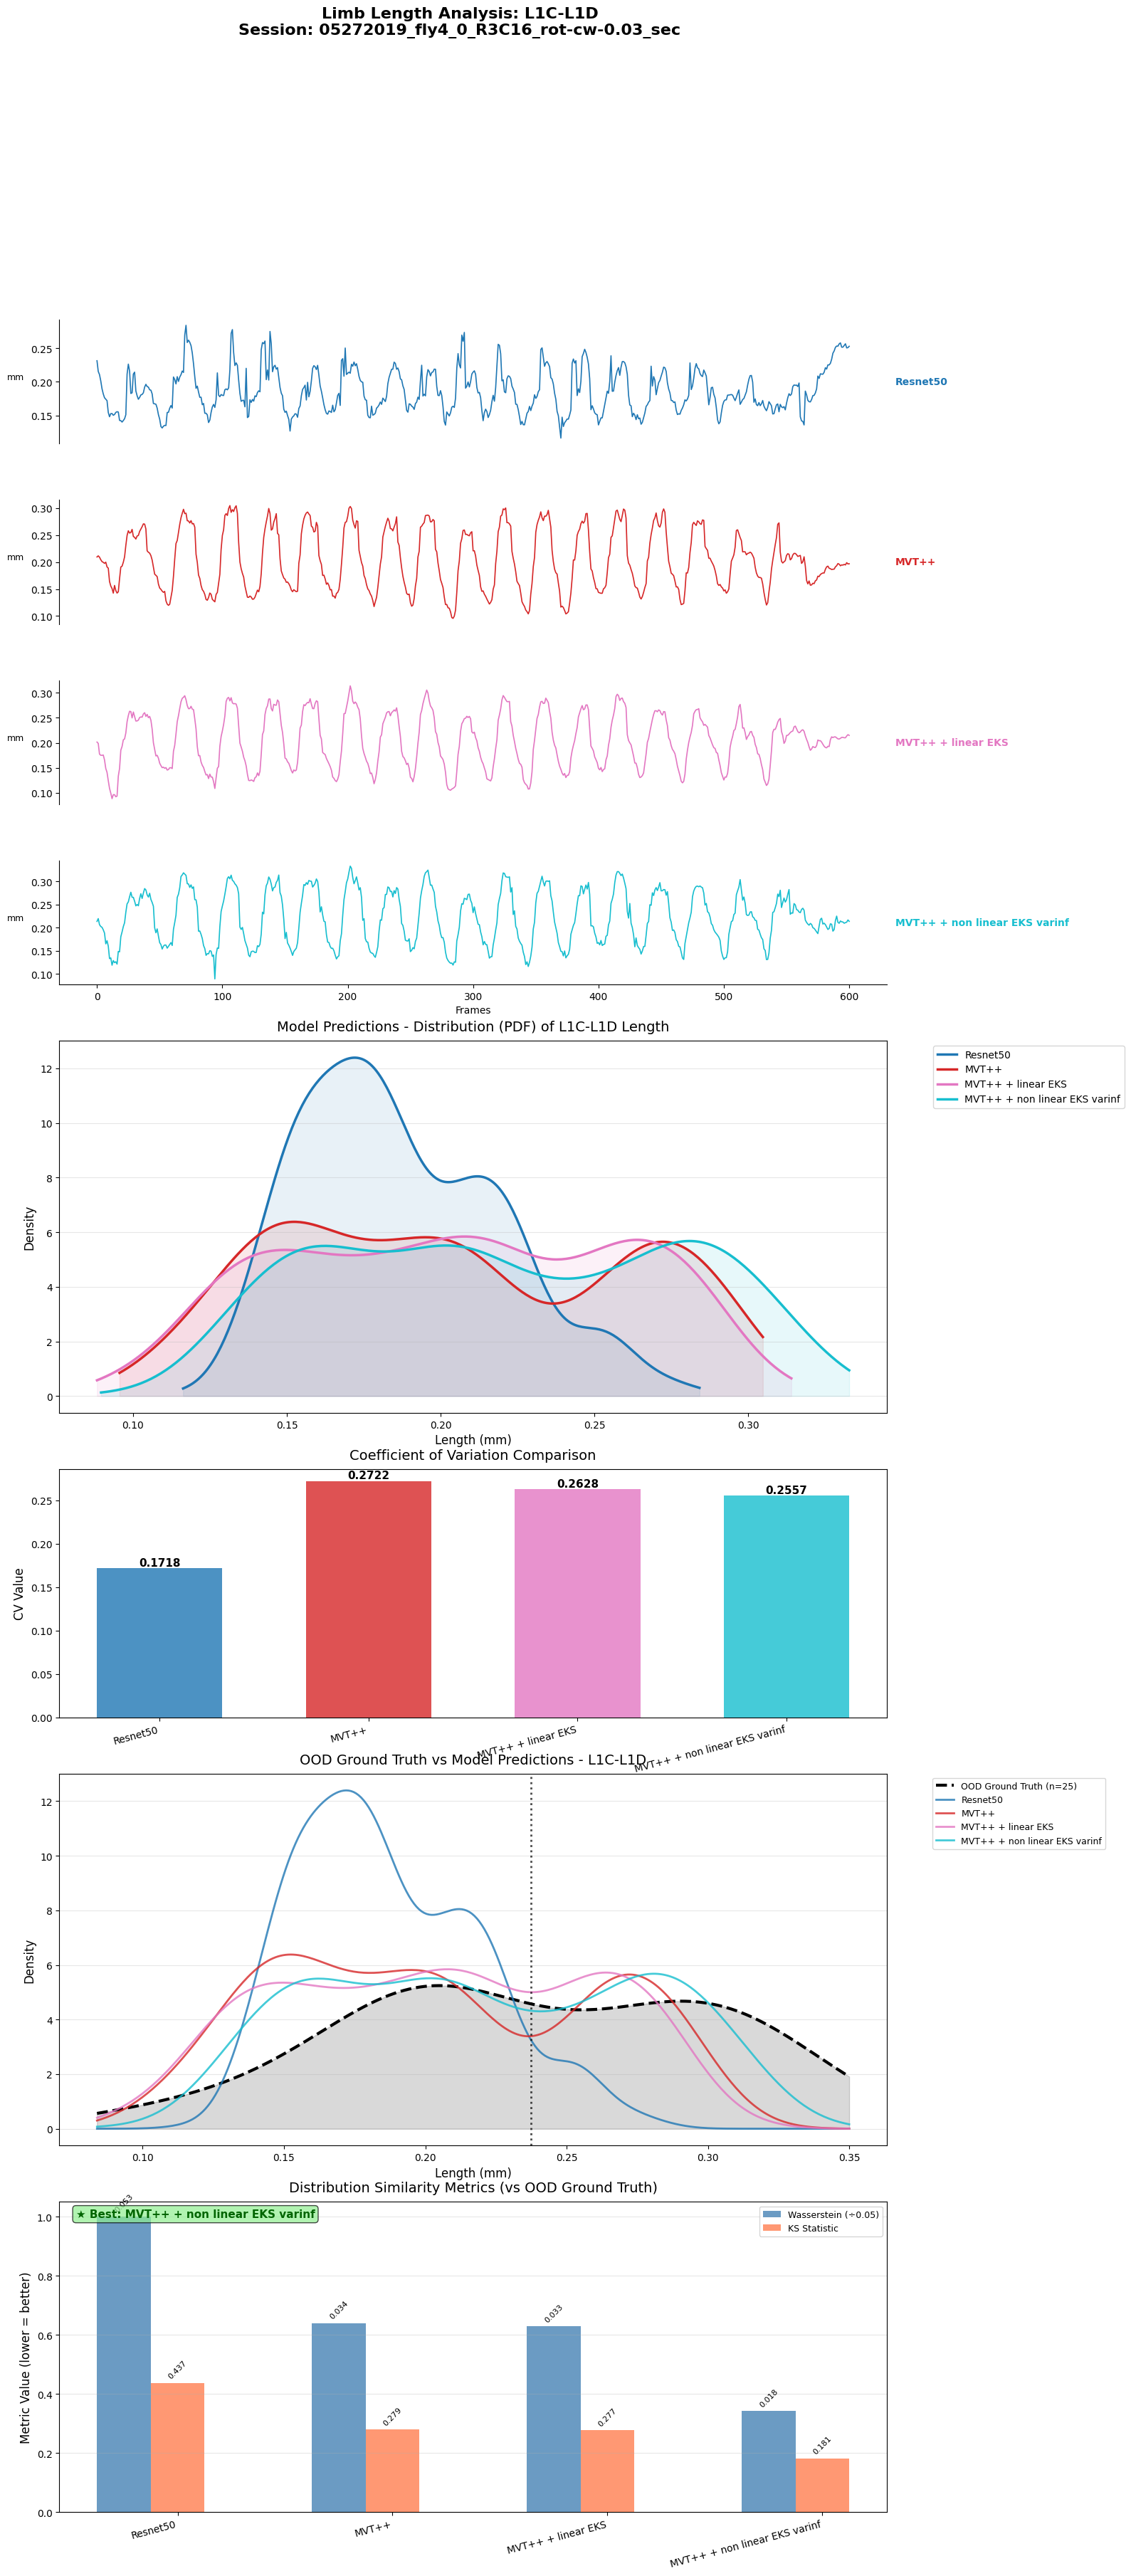

{'test_200_multiview_resnet50_ensemble_median': {'lengths': array([0.23144044, 0.21547981, 0.21077683, 0.20147261, 0.18975273,
         0.18205383, 0.17633519, 0.17415099, 0.1720056 , 0.15441856,
         0.14803487, 0.15268104, 0.15280221, 0.1502226 , 0.15142916,
         0.15445437, 0.15553371, 0.15501926, 0.14260918, 0.14224941,
         0.14011177, 0.14244645, 0.14507415, 0.15105251, 0.2112877 ,
         0.22637287, 0.21591858, 0.18266497, 0.18364036, 0.2115578 ,
         0.21442593, 0.18643621, 0.17932903, 0.17408376, 0.17684661,
         0.1805237 , 0.18122828, 0.18371185, 0.19215111, 0.19629405,
         0.19297766, 0.19213528, 0.18814377, 0.18754914, 0.18202381,
         0.16778641, 0.16729348, 0.16669142, 0.16088013, 0.15117037,
         0.14450541, 0.13348502, 0.13132683, 0.13398491, 0.13516149,
         0.13495706, 0.15436648, 0.15463828, 0.16064163, 0.1646995 ,
         0.16093354, 0.2072303 , 0.20347466, 0.19689608, 0.20772055,
         0.20057251, 0.20707365, 0.21061564, 

In [32]:
# 1. First, make sure you have computed the OOD limb lengths
# (Run this if you haven't already)
# ood_limb_lengths_by_session = compute_ood_limb_lengths_per_session(
#     Out_Dist_paths, views, camera_params_dir, skeleton
# )

# 2. Define your model names
model_names_map = {
    'test_200_multiview_resnet50_ensemble_median': 'Resnet50',
    # 'test_200_SV_vits_dino_ensemble_median': 'SVT ',
    'test_200_MVT_3d_loss_patch_masking_ensemble_median': 'MVT++',
    'test_200_MVT_3d_loss_patch_masking_eks_multiview': 'MVT++ + linear EKS',
    # 'test_200_MVT_3d_loss_patch_masking_non_linear_eks': 'MVT++ + non linear EKS ',
    # 'test_200_MVT_3d_loss_patch_masking_eks_multiview_varinf': 'MVT++ + linear EKS varinf',
    'test_200_MVT_3d_loss_patch_masking_non_linear_eks_varinf': 'MVT++ + non linear EKS varinf',
}

# 3. Run the enhanced analysis
limb_to_plot = 'L1C-L1D'
models = list(model_names_map.keys())
session_name = '05272019_fly4_0_R3C16_rot-cw-0.03_sec'

plot_limb_length_analysis_dashboard_with_ood(
    all_file_paths, 
    cfg_lp, 
    views, 
    models, 
    # camera_params_dir, 
    FLY_CALIB_DIR_OPTIMIZED,
    limb_to_plot,
    ood_limb_lengths_by_session=ood_limb_lengths_by_session,  # Pass OOD data here
    session_name=session_name,
    model_names_map=model_names_map
)

Try Working only with the OOD data

In [ ]:
# ============================================================================
# STEP 1: Function to load model predictions on OOD labeled frames
# ============================================================================

def get_ood_prediction_paths(
    dataset_name: str,
    results_configs: Dict[str, Dict],
    views: List[str],
    seed_dirs: List[str] = None,
    ensemble_seed: str = None,
    ensemble_methods: List[str] = None,
    base_path: str = "/teamspace/studios",
    studio_dir: str = "this_studio",
    output_dir: str = "outputs",
) -> Dict[str, Dict[str, str]]:
    """
    Get paths to model predictions on OOD labeled frames.
    
    Returns:
        Dict mapping model_name -> {view: prediction_file_path}
    """
    model_pred_paths = {}
    
    for results_dir, config in results_configs.items():
        model_type = config['model_type']
        n_labels = config['n_hand_labels']
        
        # Check ensemble methods
        if ensemble_methods and ensemble_seed:
            for method in ensemble_methods:
                pred_dir = os.path.join(
                    base_path, studio_dir, output_dir, dataset_name, results_dir,
                    f"{model_type}_{n_labels}_{ensemble_seed}", method, "videos-for-each-labeled-frame"
                )
                
                if os.path.exists(pred_dir):
                    model_name = f"{results_dir}_{method}"
                    view_paths = {}
                    
                    for view in views:
                        pred_file = os.path.join(pred_dir, f"predictions_{view}_new.csv")
                        if os.path.exists(pred_file):
                            view_paths[view] = pred_file
                    
                    if len(view_paths) >= 2:
                        model_pred_paths[model_name] = view_paths
                        print(f"Found predictions for {model_name}: {len(view_paths)} views")
        
        # Check individual seeds
        if seed_dirs:
            for seed in seed_dirs:
                pred_dir = os.path.join(
                    base_path, studio_dir, output_dir, dataset_name, results_dir,
                    f"{model_type}_{n_labels}_{seed}", "videos-for-each-labeled-frame"
                )
                
                if os.path.exists(pred_dir):
                    model_name = f"{results_dir}_seed_{seed}"
                    view_paths = {}
                    
                    for view in views:
                        pred_file = os.path.join(pred_dir, f"predictions_{view}_new.csv")
                        if os.path.exists(pred_file):
                            view_paths[view] = pred_file
                    
                    if len(view_paths) >= 2:
                        model_pred_paths[model_name] = view_paths
                        print(f"Found predictions for {model_name}: {len(view_paths)} views")
    
    return model_pred_paths

# ============================================================================
# OPTIMIZED: Fast loading of labeled data organized by session
# ============================================================================

def organize_labeled_data_by_session_fast(
    data_paths: Dict[str, str],
    views: List[str]
) -> Dict[str, Dict[str, pd.DataFrame]]:
    """
    FAST version: Load labeled data and organize by session using vectorized operations.
    """
    from collections import defaultdict
    
    session_data = defaultdict(lambda: {view: None for view in views})
    
    for view in views:
        csv_path = data_paths[view]
        print(f"Loading {csv_path}")
        
        try:
            df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
            
            # Extract session names from all indices at once (vectorized)
            indices = df.index.tolist()
            
            # Parse session names in one pass
            session_names = []
            for idx in indices:
                parts = idx.split('/')
                if len(parts) >= 2:
                    folder_name = parts[1]
                    for v in views:
                        folder_name = folder_name.replace(f'_{v}', '')
                    session_names.append(folder_name)
                else:
                    session_names.append(None)
            
            # Add session column temporarily
            df['_session'] = session_names
            
            # Group by session (FAST - uses pandas groupby)
            for session_name, group_df in df.groupby('_session'):
                if session_name is not None:
                    # Drop the temp column and store
                    group_df = group_df.drop(columns=['_session'])
                    session_data[session_name][view] = group_df
            
        except Exception as e:
            print(f"Error loading {csv_path}: {e}")
            continue
    
    return dict(session_data)


def prepare_multiview_tensor_fast(
    session_views_data: Dict[str, pd.DataFrame],
    views: List[str]
) -> Tuple[torch.Tensor, List[str], int]:
    """
    FAST version: Convert labeled data to tensor using vectorized operations.
    """
    
    # Helper to create frame key from index
    def make_frame_key(idx, views):
        parts = idx.split('/')
        if len(parts) >= 3:
            folder = parts[1]
            img = parts[2]
            for v in views:
                folder = folder.replace(f'_{v}', '')
            return f"{folder}/{img}"
        return idx
    
    # Build frame key mappings for each view
    view_frame_data = {}
    all_frame_keys = None
    
    for view in views:
        if session_views_data[view] is not None and len(session_views_data[view]) > 0:
            df = session_views_data[view]
            # Create frame keys for all rows at once
            frame_keys = [make_frame_key(idx, views) for idx in df.index]
            view_frame_data[view] = {
                'df': df,
                'frame_keys': frame_keys,
                'key_to_row': {k: i for i, k in enumerate(frame_keys)}
            }
            
            if all_frame_keys is None:
                all_frame_keys = set(frame_keys)
            else:
                all_frame_keys = all_frame_keys.intersection(frame_keys)
    
    if not all_frame_keys:
        return None, None, 0
    
    all_frame_keys = sorted(list(all_frame_keys))
    n_frames = len(all_frame_keys)
    
    # Get keypoint names
    first_view = next(v for v in views if v in view_frame_data)
    df = view_frame_data[first_view]['df']
    keypoint_names = list(df.columns.get_level_values(1).unique())
    
    n_keypoints = len(keypoint_names)
    n_views = len(views)
    
    # Pre-allocate tensor
    output_tensor = torch.full((n_frames, n_keypoints * n_views, 2), float('nan'))
    
    # Extract data using numpy for speed
    for view_idx, view in enumerate(views):
        if view not in view_frame_data:
            continue
        
        vd = view_frame_data[view]
        df = vd['df']
        key_to_row = vd['key_to_row']
        
        # Get row indices for common frames
        row_indices = [key_to_row[k] for k in all_frame_keys if k in key_to_row]
        
        if not row_indices:
            continue
        
        # Extract x and y columns for all keypoints at once
        for kp_idx, kp_name in enumerate(keypoint_names):
            try:
                # Get column indices for this keypoint's x and y
                x_col = df.xs((kp_name, 'x'), axis=1, level=(1, 2))
                y_col = df.xs((kp_name, 'y'), axis=1, level=(1, 2))
                
                # Extract values for the matching rows (using iloc for speed)
                x_vals = x_col.iloc[row_indices].values.flatten()
                y_vals = y_col.iloc[row_indices].values.flatten()
                
                col_idx = view_idx * n_keypoints + kp_idx
                output_tensor[:len(row_indices), col_idx, 0] = torch.tensor(x_vals, dtype=torch.float32)
                output_tensor[:len(row_indices), col_idx, 1] = torch.tensor(y_vals, dtype=torch.float32)
            except:
                continue
    
    return output_tensor, keypoint_names, n_frames


def compute_ood_limb_lengths_per_session_fast(
    ood_paths: Dict[str, str],
    views: List[str],
    camera_params_dir: str,
    skeleton: List[Tuple[str, str]]
) -> Dict[str, Dict[str, np.ndarray]]:
    """
    FAST version: Compute 3D limb lengths for OOD labeled data.
    """
    print("Organizing labeled data by session (fast)...")
    session_data = organize_labeled_data_by_session_fast(ood_paths, views)
    
    print(f"Found {len(session_data)} sessions")
    
    all_limb_lengths = {}
    
    for session_name, views_data in session_data.items():
        valid_views = [v for v in views if views_data[v] is not None and len(views_data[v]) > 0]
        
        if len(valid_views) < 2:
            continue
        
        camera_group = load_camera_parameters(session_name, camera_params_dir)
        if camera_group is None:
            continue
        
        data_tensor, keypoint_names, n_frames = prepare_multiview_tensor_fast(views_data, views)
        
        if data_tensor is None or n_frames == 0:
            continue
        
        print(f"  {session_name}: {n_frames} frames, {len(valid_views)} views")
        
        try:
            points_3d = triangulate_keypoints(data_tensor, camera_group, keypoint_names, views)
            limb_lengths = calculate_limb_lengths_3d(points_3d, keypoint_names, skeleton)
            all_limb_lengths[session_name] = limb_lengths
        except Exception as e:
            print(f"  {session_name}: Failed - {e}")
            continue
    
    return all_limb_lengths


def compute_model_ood_limb_lengths_fast(
    model_pred_paths: Dict[str, Dict[str, str]],
    views: List[str],
    camera_params_dir: str,
    skeleton: List[Tuple[str, str]]
) -> Dict[str, Dict[str, Dict[str, np.ndarray]]]:
    """
    FAST version: Compute limb lengths from model predictions.
    """
    all_model_results = {}
    
    for model_name, view_paths in model_pred_paths.items():
        print(f"\nProcessing: {model_name}")
        
        session_data = organize_labeled_data_by_session_fast(view_paths, views)
        model_limb_lengths = {}
        
        for session_name, views_data in session_data.items():
            valid_views = [v for v in views if views_data[v] is not None and len(views_data[v]) > 0]
            
            if len(valid_views) < 2:
                continue
            
            camera_group = load_camera_parameters(session_name, camera_params_dir)
            if camera_group is None:
                continue
            
            data_tensor, keypoint_names, n_frames = prepare_multiview_tensor_fast(views_data, views)
            
            if data_tensor is None or n_frames == 0:
                continue
            
            try:
                points_3d = triangulate_keypoints(data_tensor, camera_group, keypoint_names, views)
                limb_lengths = calculate_limb_lengths_3d(points_3d, keypoint_names, skeleton)
                model_limb_lengths[session_name] = limb_lengths
                print(f"  {session_name}: {n_frames} frames OK")
            except Exception as e:
                continue
        
        all_model_results[model_name] = model_limb_lengths
    
    return all_model_results

# Load OOD ground truth (FAST)
print("Loading OOD Ground Truth...")
ood_limb_lengths_by_session = compute_ood_limb_lengths_per_session_fast(
    Out_Dist_paths, views, camera_params_dir, skeleton
)

# Get model prediction paths
model_ood_pred_paths = get_ood_prediction_paths(
    dataset_name=dataset_name,
    results_configs=results_configs,
    views=views,
    seed_dirs=seed_dirs,
    ensemble_seed=ensemble_seed,
    ensemble_methods=ensemble_methods
)

# Load model predictions (FAST)
print("\nLoading Model Predictions...")
model_ood_limb_lengths = compute_model_ood_limb_lengths_fast(
    model_ood_pred_paths, views, camera_params_dir, skeleton
)


In [70]:
# Load OOD ground truth (FAST)
print("Loading OOD Ground Truth...")
ood_limb_lengths_by_session = compute_ood_limb_lengths_per_session_fast(
    Out_Dist_paths, views, camera_params_dir, skeleton
)

# Get model prediction paths
model_ood_pred_paths = get_ood_prediction_paths(
    dataset_name=dataset_name,
    results_configs=results_configs,
    views=views,
    seed_dirs=seed_dirs,
    ensemble_seed=ensemble_seed,
    ensemble_methods=ensemble_methods
)

# Load model predictions (FAST)
print("\nLoading Model Predictions...")
model_ood_limb_lengths = compute_model_ood_limb_lengths_fast(
    model_ood_pred_paths, views, camera_params_dir, skeleton
)

Loading OOD Ground Truth...
Organizing labeled data by session (fast)...
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-A_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-B_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-C_new.csv


Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-D_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-E_new.csv
Loading /teamspace/studios/data/fly-anipose/CollectedData_Cam-F_new.csv


INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R1C24_rot-ccw-0.06_sec


Found 12 sessions


INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R2C14_str-ccw-0.72_sec


  05272019_fly4_0_R1C24_rot-ccw-0.06_sec: 25 frames, 6 views


... (432 outputs left out)

INFO:__main__:Loaded camera parameters for session: 05272019_fly5_0_R3C15_rot-cw-0_sec


  05272019_fly5_0_R2C5_str-cw-0.18_sec: 25 frames OK


INFO:__main__:Loaded camera parameters for session: 05272019_fly5_0_R3C19_rot-cw-0.18_sec


  05272019_fly5_0_R3C15_rot-cw-0_sec: 25 frames OK
  05272019_fly5_0_R3C19_rot-cw-0.18_sec: 25 frames OK


/tmp/ipykernel_7331/3869098716.py:112: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(box_data, labels=box_labels, patch_artist=True)
/tmp/ipykernel_7331/3869098716.py:195: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 0.95])


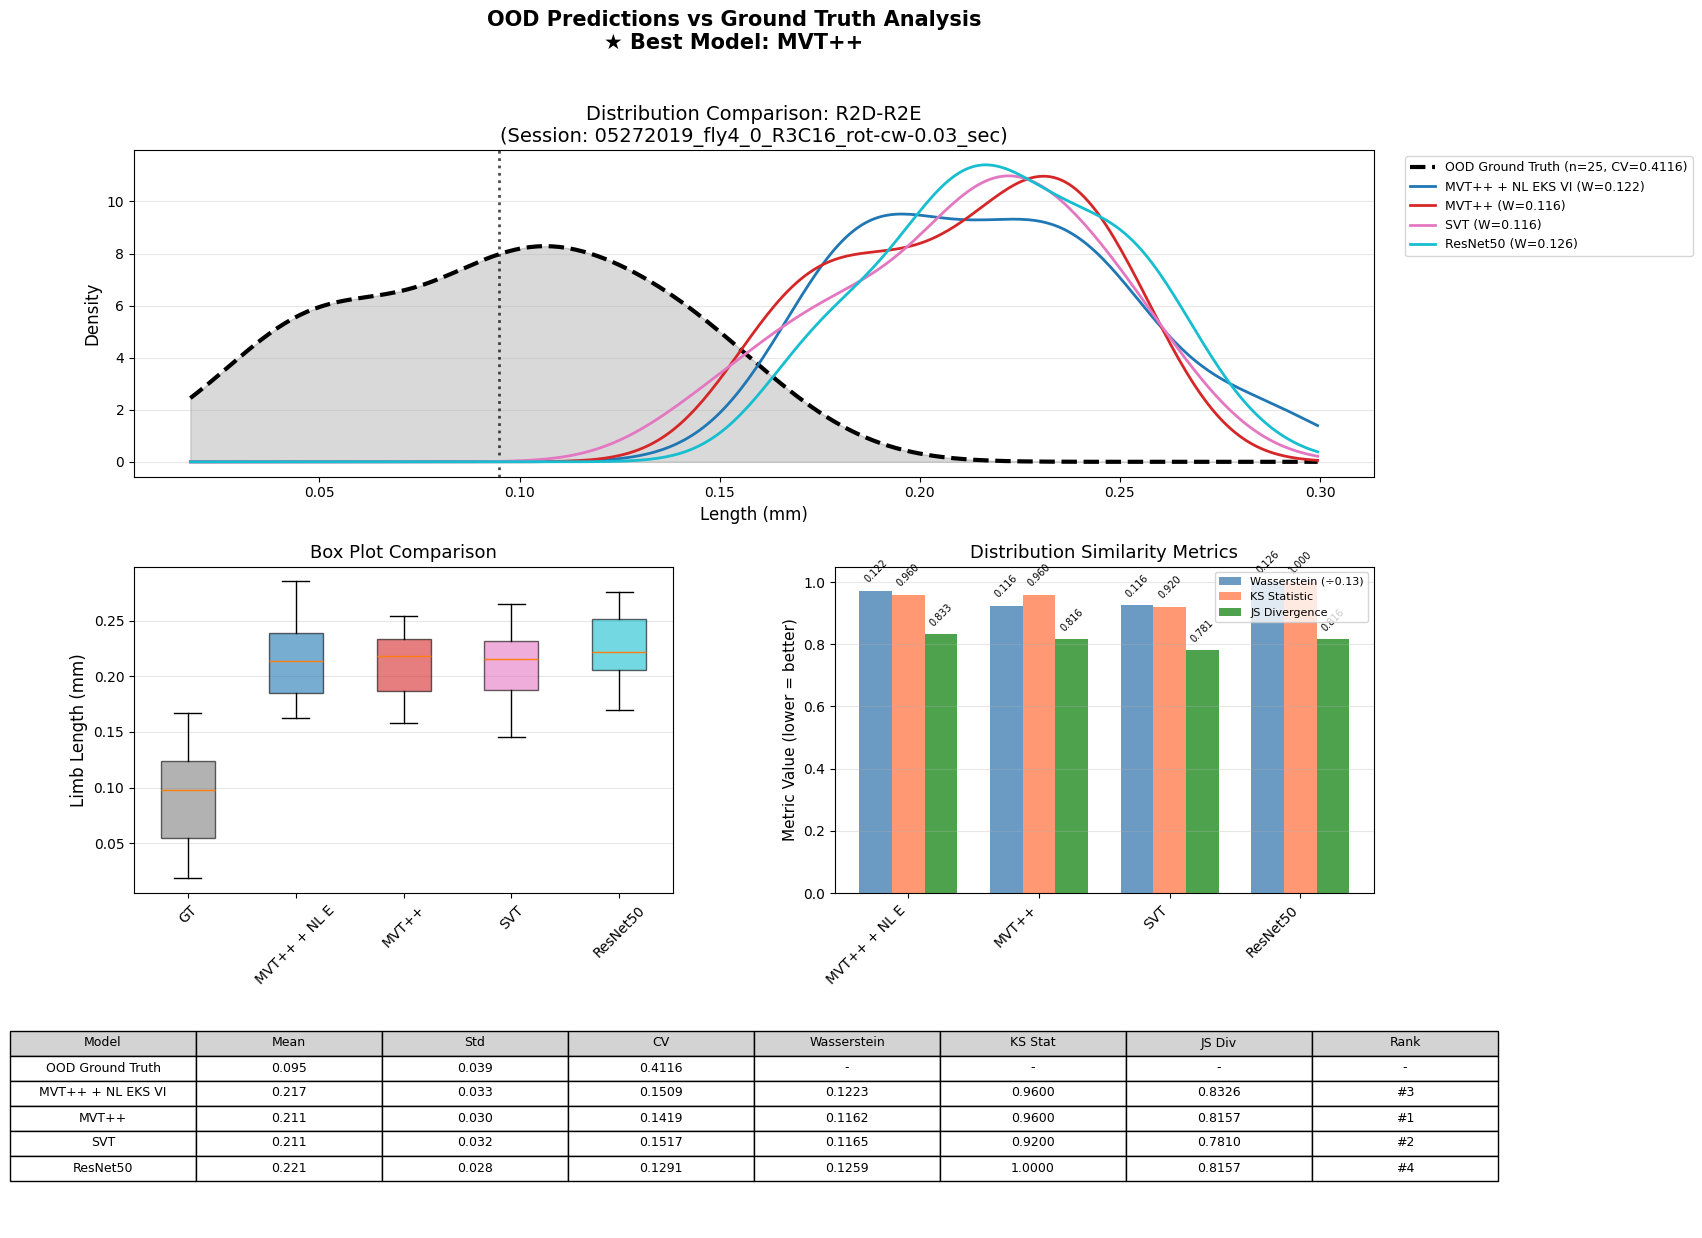

{'test_200_MVT_3d_loss_patch_masking_non_linear_eks_varinf': {'lengths': array([0.23688405, 0.23589641, 0.18772963, 0.18385884, 0.23982596,
         0.24598396, 0.23847596, 0.21721198, 0.19875061, 0.17749882,
         0.16263533, 0.21383291, 0.25168764, 0.28514613, 0.18270489,
         0.17938005, 0.18499845, 0.25835757, 0.22108611, 0.21354854,
         0.21279429, 0.19815123, 0.18539429, 0.23528876, 0.28462995]),
  'valid': array([0.23688405, 0.23589641, 0.18772963, 0.18385884, 0.23982596,
         0.24598396, 0.23847596, 0.21721198, 0.19875061, 0.17749882,
         0.16263533, 0.21383291, 0.25168764, 0.28514613, 0.18270489,
         0.17938005, 0.18499845, 0.25835757, 0.22108611, 0.21354854,
         0.21279429, 0.19815123, 0.18539429, 0.23528876, 0.28462995]),
  'display_name': 'MVT++ + NL EKS VI',
  'metrics': {'wasserstein': np.float64(0.12234454068713632),
   'ks_stat': np.float64(0.96),
   'ks_pval': np.float64(7.910728602448615e-13),
   'js_div': np.float64(0.8325546110200445),

In [71]:
# ============================================================================
# STEP 3: Enhanced plotting function with OOD predictions comparison
# ============================================================================

def plot_ood_comparison_dashboard(
    ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],  # Ground truth
    model_ood_limb_lengths: Dict[str, Dict[str, Dict[str, np.ndarray]]],  # Model predictions
    limb_to_analyze: str,
    session_name: str,
    model_names_map: Dict[str, str] = None,
    figsize: Tuple[int, int] = (16, 14)
):
    """
    Compare model predictions on OOD frames vs OOD ground truth.
    
    Parameters:
    -----------
    ood_gt_limb_lengths : Dict[str, Dict[str, np.ndarray]]
        Ground truth limb lengths by session (from compute_ood_limb_lengths_per_session)
    model_ood_limb_lengths : Dict[str, Dict[str, Dict[str, np.ndarray]]]
        Model predictions limb lengths: model_name -> session -> limb -> lengths
    limb_to_analyze : str
        Which limb to analyze (e.g., 'L1C-L1D')
    session_name : str
        Which session to analyze
    """
    
    # Check ground truth availability
    if session_name not in ood_gt_limb_lengths:
        print(f"No ground truth data for session: {session_name}")
        return
    
    if limb_to_analyze not in ood_gt_limb_lengths[session_name]:
        print(f"No ground truth data for limb: {limb_to_analyze}")
        return
    
    gt_lengths = ood_gt_limb_lengths[session_name][limb_to_analyze]
    gt_valid = gt_lengths[~np.isnan(gt_lengths)]
    
    if len(gt_valid) == 0:
        print("No valid ground truth data")
        return
    
    gt_mean = np.mean(gt_valid)
    gt_std = np.std(gt_valid)
    gt_cv = gt_std / gt_mean if gt_mean > 0 else np.nan
    
    # Collect model data
    model_data = {}
    for model_name, sessions in model_ood_limb_lengths.items():
        if session_name in sessions and limb_to_analyze in sessions[session_name]:
            lengths = sessions[session_name][limb_to_analyze]
            valid = lengths[~np.isnan(lengths)]
            if len(valid) > 0:
                display_name = model_names_map.get(model_name, model_name) if model_names_map else model_name
                metrics = compute_distribution_metrics(lengths, gt_lengths)
                model_data[model_name] = {
                    'lengths': lengths,
                    'valid': valid,
                    'display_name': display_name,
                    'metrics': metrics,
                    'cv': np.std(valid) / np.mean(valid) if np.mean(valid) > 0 else np.nan
                }
    
    if not model_data:
        print("No model predictions available for this session/limb")
        return
    
    n_models = len(model_data)
    colors = plt.cm.tab10(np.linspace(0, 1, n_models))
    model_ids = list(model_data.keys())
    
    # Create figure
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(3, 2, figure=fig, hspace=0.3, wspace=0.3, height_ratios=[2, 2, 1.5])
    
    # ===== Plot 1: Distribution comparison (PDF) =====
    ax1 = fig.add_subplot(gs[0, :])
    
    # Ground truth
    kde_gt = stats.gaussian_kde(gt_valid)
    x_min = min(np.min(gt_valid), min(np.min(model_data[m]['valid']) for m in model_ids))
    x_max = max(np.max(gt_valid), max(np.max(model_data[m]['valid']) for m in model_ids))
    x_range = np.linspace(x_min * 0.95, x_max * 1.05, 300)
    
    ax1.plot(x_range, kde_gt(x_range), color='black', linewidth=3, linestyle='--',
             label=f'OOD Ground Truth (n={len(gt_valid)}, CV={gt_cv:.4f})')
    ax1.fill_between(x_range, kde_gt(x_range), alpha=0.15, color='black')
    ax1.axvline(gt_mean, color='black', linestyle=':', linewidth=2, alpha=0.7)
    
    # Model predictions
    for i, m_id in enumerate(model_ids):
        valid = model_data[m_id]['valid']
        kde = stats.gaussian_kde(valid)
        wass = model_data[m_id]['metrics']['wasserstein']
        ax1.plot(x_range, kde(x_range), color=colors[i], linewidth=2,
                 label=f"{model_data[m_id]['display_name']} (W={wass:.3f})")
    
    ax1.set_title(f"Distribution Comparison: {limb_to_analyze}\n(Session: {session_name})", fontsize=14)
    ax1.set_xlabel("Length (mm)", fontsize=12)
    ax1.set_ylabel("Density", fontsize=12)
    ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
    ax1.grid(axis='y', alpha=0.3)
    
    # ===== Plot 2: Box plot comparison =====
    ax2 = fig.add_subplot(gs[1, 0])
    
    box_data = [gt_valid] + [model_data[m]['valid'] for m in model_ids]
    box_labels = ['GT'] + [model_data[m]['display_name'][:12] for m in model_ids]
    box_colors = ['gray'] + list(colors)
    
    bp = ax2.boxplot(box_data, labels=box_labels, patch_artist=True)
    for patch, color in zip(bp['boxes'], box_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    
    ax2.set_ylabel("Limb Length (mm)", fontsize=12)
    ax2.set_title("Box Plot Comparison", fontsize=13)
    ax2.tick_params(axis='x', rotation=45)
    ax2.grid(axis='y', alpha=0.3)
    
    # ===== Plot 3: Distribution metrics bar chart =====
    ax3 = fig.add_subplot(gs[1, 1])
    
    x = np.arange(n_models)
    width = 0.25
    
    wass_vals = [model_data[m]['metrics']['wasserstein'] for m in model_ids]
    ks_vals = [model_data[m]['metrics']['ks_stat'] for m in model_ids]
    js_vals = [model_data[m]['metrics']['js_div'] for m in model_ids]
    
    # Normalize Wasserstein for visualization
    wass_max = max(wass_vals) if max(wass_vals) > 0 else 1
    wass_norm = [w / wass_max for w in wass_vals]
    
    bars1 = ax3.bar(x - width, wass_norm, width, label=f'Wasserstein (÷{wass_max:.2f})', color='steelblue', alpha=0.8)
    bars2 = ax3.bar(x, ks_vals, width, label='KS Statistic', color='coral', alpha=0.8)
    bars3 = ax3.bar(x + width, js_vals, width, label='JS Divergence', color='forestgreen', alpha=0.8)
    
    # Add value labels
    for bars, vals in [(bars1, wass_vals), (bars2, ks_vals), (bars3, js_vals)]:
        for bar, val in zip(bars, vals):
            height = bar.get_height()
            ax3.text(bar.get_x() + bar.get_width()/2., height + 0.02, 
                    f'{val:.3f}', ha='center', va='bottom', fontsize=7, rotation=45)
    
    ax3.set_ylabel('Metric Value (lower = better)', fontsize=11)
    ax3.set_title('Distribution Similarity Metrics', fontsize=13)
    ax3.set_xticks(x)
    ax3.set_xticklabels([model_data[m]['display_name'][:12] for m in model_ids], rotation=45, ha='right')
    ax3.legend(loc='upper right', fontsize=8)
    ax3.grid(axis='y', alpha=0.3)
    
    # ===== Plot 4: Summary table =====
    ax4 = fig.add_subplot(gs[2, :])
    ax4.axis('off')
    
    # Create table data
    table_data = [['Model', 'Mean', 'Std', 'CV', 'Wasserstein', 'KS Stat', 'JS Div', 'Rank']]
    
    # Rank by Wasserstein distance
    ranked = sorted(enumerate(wass_vals), key=lambda x: x[1])
    ranks = {idx: rank+1 for rank, (idx, _) in enumerate(ranked)}
    
    # Add ground truth row
    table_data.append(['OOD Ground Truth', f'{gt_mean:.3f}', f'{gt_std:.3f}', f'{gt_cv:.4f}', '-', '-', '-', '-'])
    
    # Add model rows
    for i, m_id in enumerate(model_ids):
        m = model_data[m_id]
        table_data.append([
            m['display_name'][:25],
            f"{np.mean(m['valid']):.3f}",
            f"{np.std(m['valid']):.3f}",
            f"{m['cv']:.4f}",
            f"{m['metrics']['wasserstein']:.4f}",
            f"{m['metrics']['ks_stat']:.4f}",
            f"{m['metrics']['js_div']:.4f}",
            f"#{ranks[i]}"
        ])
    
    table = ax4.table(cellText=table_data[1:], colLabels=table_data[0],
                      loc='center', cellLoc='center',
                      colColours=['lightgray']*8)
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.5)
    
    # Highlight best model
    best_idx = np.argmin(wass_vals)
    best_model = model_data[model_ids[best_idx]]['display_name']
    
    plt.suptitle(f"OOD Predictions vs Ground Truth Analysis\n★ Best Model: {best_model}", 
                 fontsize=15, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 0.95, 0.95])
    plt.show()
    
    return model_data


# ============================================================================
# STEP 4: Run the full analysis
# ============================================================================

# First, make sure you have computed the OOD ground truth limb lengths
# (Run this if you haven't already)
# ood_limb_lengths_by_session = compute_ood_limb_lengths_per_session(
#     Out_Dist_paths, views, camera_params_dir, skeleton
# )

model_names_map = {
    'test_200_multiview_resnet50_ensemble_median': 'ResNet50',
    'test_200_SV_vits_dino_ensemble_median': 'SVT',
    'test_200_MVT_3d_loss_patch_masking_ensemble_median': 'MVT++',
    # 'test_200_MVT_3d_loss_patch_masking_eks_multiview': 'MVT++ + linear EKS',
    # 'test_200_MVT_3d_loss_patch_masking_non_linear_eks': 'MVT++ + NL EKS',
    # 'test_200_MVT_3d_loss_patch_masking_eks_multiview_varinf': 'MVT++ + linear EKS VI',
    'test_200_MVT_3d_loss_patch_masking_non_linear_eks_varinf': 'MVT++ + NL EKS VI',
}

# Only compare models that are in model_names_map
models_to_compare = list(model_names_map.keys())

# Filter the model results to only include selected models
filtered_model_ood_limb_lengths = {
    k: v for k, v in model_ood_limb_lengths.items() 
    if k in models_to_compare
}

# Choose session and limb
session_name = '05272019_fly4_0_R3C16_rot-cw-0.03_sec'  
limb_to_plot = 'R2D-R2E'

# Run the comparison with filtered models
plot_ood_comparison_dashboard(
    ood_gt_limb_lengths=ood_limb_lengths_by_session,
    model_ood_limb_lengths=filtered_model_ood_limb_lengths,  # Use filtered dict
    limb_to_analyze=limb_to_plot,
    session_name=session_name,
    model_names_map=model_names_map
)

# Across Sessions

# This is A great Plot!

/tmp/ipykernel_7331/2758432301.py:202: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(box_data, labels=box_labels, patch_artist=True)


/tmp/ipykernel_7331/2758432301.py:287: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 0.96])


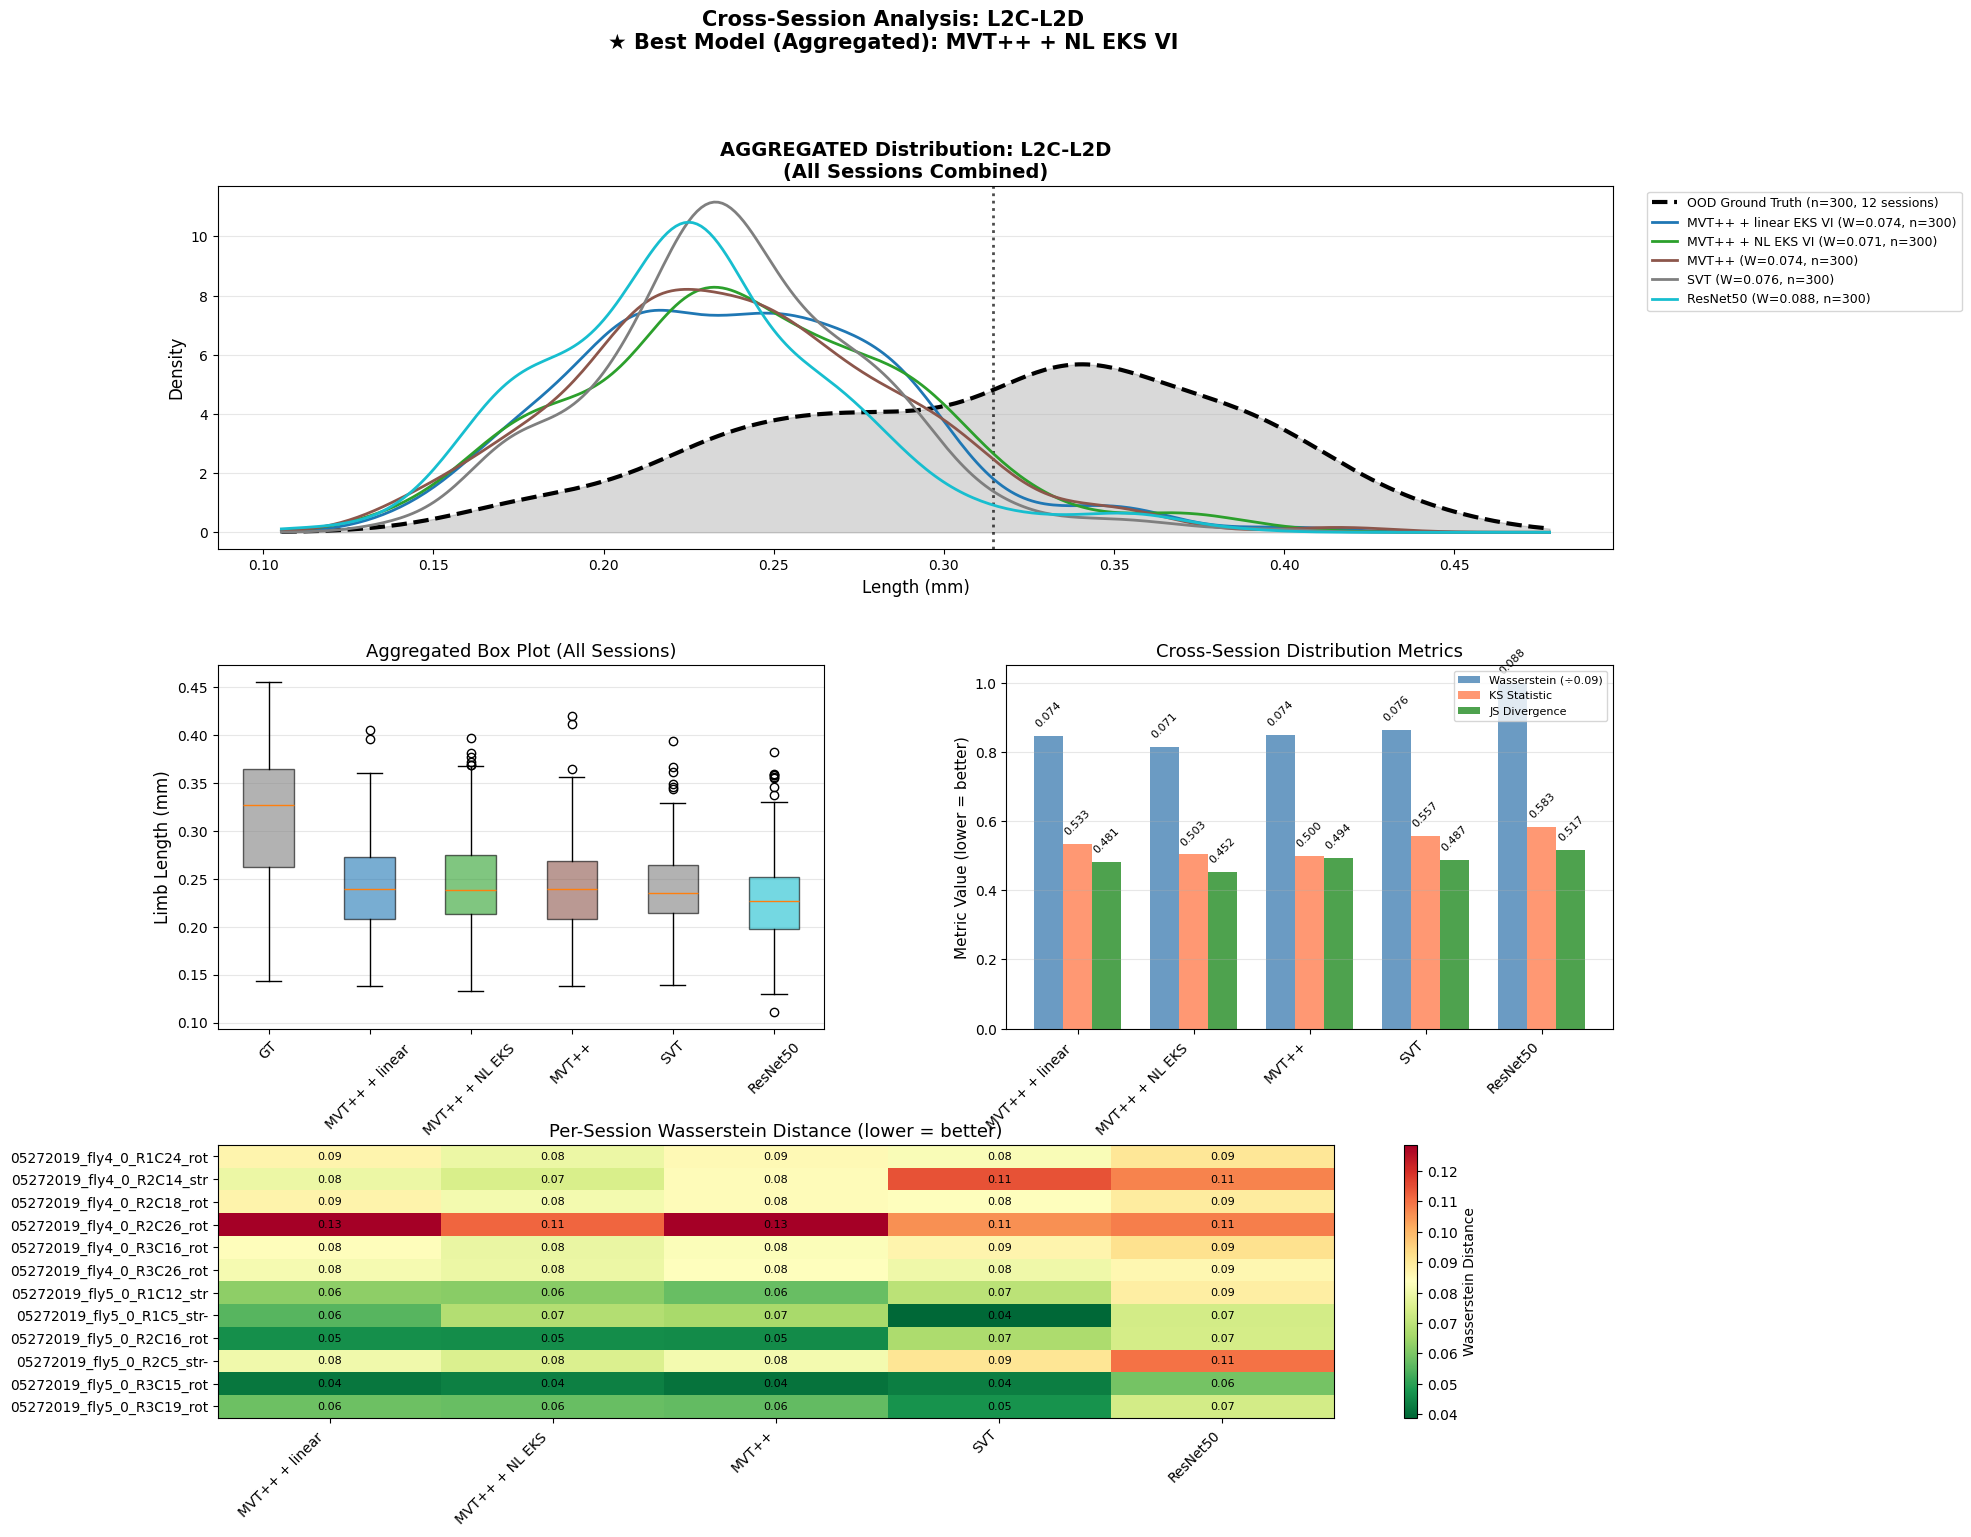


CROSS-SESSION METRICS SUMMARY


,Model,N_Sessions,N_Frames,Mean,Std,CV,Wasserstein,KS_Stat,JS_Div,Mean_Diff,Rank
0,OOD Ground Truth,12,300,0.314283,0.066529,0.211685,0.000000,0.000000,0.000000,0.000000,-
1,MVT++ + linear EKS VI,12,300,0.240071,0.047093,0.196164,0.074212,0.533333,0.480804,0.074212,2.0
2,MVT++ + NL EKS VI,12,300,0.243013,0.048864,0.201077,0.071270,0.503333,0.452191,0.071270,1.0
3,MVT++,12,300,0.239902,0.048337,0.201487,0.074381,0.500000,0.494158,0.074381,3.0
4,SVT,12,300,0.238606,0.040308,0.168933,0.075677,0.556667,0.486630,0.075677,4.0
5,ResNet50,12,300,0.226671,0.043697,0.192776,0.087612,0.583333,0.517312,0.087612,5.0


In [72]:
# ============================================================================
# Aggregate analysis across all sessions
# ============================================================================

def aggregate_limb_lengths_across_sessions(
    limb_lengths_by_session: Dict[str, Dict[str, np.ndarray]],
    limb_name: str
) -> Tuple[np.ndarray, Dict[str, np.ndarray]]:
    """
    Pool limb length data across all sessions.
    
    Returns:
        - all_lengths: concatenated array of all valid lengths
        - per_session: dict of session_name -> valid lengths (for reference)
    """
    all_lengths = []
    per_session = {}
    
    for session_name, limb_data in limb_lengths_by_session.items():
        if limb_name in limb_data:
            lengths = limb_data[limb_name]
            valid = lengths[~np.isnan(lengths)]
            if len(valid) > 0:
                all_lengths.extend(valid)
                per_session[session_name] = valid
    
    return np.array(all_lengths), per_session


def compute_cross_session_metrics(
    ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
    model_ood_limb_lengths: Dict[str, Dict[str, Dict[str, np.ndarray]]],
    limb_name: str,
    model_names_map: Dict[str, str] = None
) -> pd.DataFrame:
    """
    Compute metrics comparing each model to ground truth across ALL sessions.
    """
    # Aggregate ground truth
    gt_all, gt_per_session = aggregate_limb_lengths_across_sessions(
        ood_gt_limb_lengths, limb_name
    )
    
    if len(gt_all) == 0:
        print(f"No ground truth data for limb: {limb_name}")
        return None
    
    gt_mean = np.mean(gt_all)
    gt_std = np.std(gt_all)
    gt_cv = gt_std / gt_mean if gt_mean > 0 else np.nan
    
    results = []
    
    # Ground truth row
    results.append({
        'Model': 'OOD Ground Truth',
        'N_Sessions': len(gt_per_session),
        'N_Frames': len(gt_all),
        'Mean': gt_mean,
        'Std': gt_std,
        'CV': gt_cv,
        'Wasserstein': 0.0,
        'KS_Stat': 0.0,
        'JS_Div': 0.0,
        'Mean_Diff': 0.0,
    })
    
    # Each model
    for model_name, session_data in model_ood_limb_lengths.items():
        model_all, model_per_session = aggregate_limb_lengths_across_sessions(
            session_data, limb_name
        )
        
        if len(model_all) == 0:
            continue
        
        display_name = model_names_map.get(model_name, model_name) if model_names_map else model_name
        
        # Compute metrics vs ground truth
        metrics = compute_distribution_metrics(model_all, gt_all)
        
        results.append({
            'Model': display_name,
            'N_Sessions': len(model_per_session),
            'N_Frames': len(model_all),
            'Mean': np.mean(model_all),
            'Std': np.std(model_all),
            'CV': np.std(model_all) / np.mean(model_all) if np.mean(model_all) > 0 else np.nan,
            'Wasserstein': metrics['wasserstein'],
            'KS_Stat': metrics['ks_stat'],
            'JS_Div': metrics['js_div'],
            'Mean_Diff': metrics['mean_diff'],
        })
    
    df = pd.DataFrame(results)
    
    # Add ranking (exclude ground truth row)
    model_rows = df[df['Model'] != 'OOD Ground Truth'].copy()
    model_rows['Rank'] = model_rows['Wasserstein'].rank().astype(int)
    df = pd.concat([df[df['Model'] == 'OOD Ground Truth'], model_rows])
    df['Rank'] = df['Rank'].fillna('-')
    
    return df


def plot_cross_session_comparison(
    ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
    model_ood_limb_lengths: Dict[str, Dict[str, Dict[str, np.ndarray]]],
    limb_name: str,
    model_names_map: Dict[str, str] = None,
    models_to_compare: List[str] = None,
    figsize: Tuple[int, int] = (18, 16)
):
    """
    Compare models to ground truth across ALL sessions combined.
    """
    # Filter models if specified
    if models_to_compare:
        filtered_models = {k: v for k, v in model_ood_limb_lengths.items() if k in models_to_compare}
    else:
        filtered_models = model_ood_limb_lengths
    
    # Aggregate ground truth
    gt_all, gt_per_session = aggregate_limb_lengths_across_sessions(
        ood_gt_limb_lengths, limb_name
    )
    
    if len(gt_all) == 0:
        print(f"No ground truth data for limb: {limb_name}")
        return
    
    gt_mean = np.mean(gt_all)
    gt_std = np.std(gt_all)
    gt_cv = gt_std / gt_mean
    
    # Aggregate each model
    model_data = {}
    for model_name, session_data in filtered_models.items():
        model_all, model_per_session = aggregate_limb_lengths_across_sessions(
            session_data, limb_name
        )
        if len(model_all) > 0:
            display_name = model_names_map.get(model_name, model_name) if model_names_map else model_name
            metrics = compute_distribution_metrics(model_all, gt_all)
            model_data[model_name] = {
                'all': model_all,
                'per_session': model_per_session,
                'display_name': display_name,
                'metrics': metrics,
                'cv': np.std(model_all) / np.mean(model_all)
            }
    
    if not model_data:
        print("No model data available")
        return
    
    n_models = len(model_data)
    colors = plt.cm.tab10(np.linspace(0, 1, n_models))
    model_ids = list(model_data.keys())
    
    # Create figure
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(3, 2, figure=fig, hspace=0.35, wspace=0.3, height_ratios=[2, 2, 1.5])
    
    # ===== Plot 1: Aggregated PDF comparison =====
    ax1 = fig.add_subplot(gs[0, :])
    
    kde_gt = stats.gaussian_kde(gt_all)
    x_min = min(np.min(gt_all), min(np.min(model_data[m]['all']) for m in model_ids))
    x_max = max(np.max(gt_all), max(np.max(model_data[m]['all']) for m in model_ids))
    x_range = np.linspace(x_min * 0.95, x_max * 1.05, 300)
    
    ax1.plot(x_range, kde_gt(x_range), color='black', linewidth=3, linestyle='--',
             label=f'OOD Ground Truth (n={len(gt_all)}, {len(gt_per_session)} sessions)')
    ax1.fill_between(x_range, kde_gt(x_range), alpha=0.15, color='black')
    ax1.axvline(gt_mean, color='black', linestyle=':', linewidth=2, alpha=0.7)
    
    for i, m_id in enumerate(model_ids):
        m = model_data[m_id]
        kde = stats.gaussian_kde(m['all'])
        wass = m['metrics']['wasserstein']
        ax1.plot(x_range, kde(x_range), color=colors[i], linewidth=2,
                 label=f"{m['display_name']} (W={wass:.3f}, n={len(m['all'])})")
    
    ax1.set_title(f"AGGREGATED Distribution: {limb_name}\n(All Sessions Combined)", fontsize=14, fontweight='bold')
    ax1.set_xlabel("Length (mm)", fontsize=12)
    ax1.set_ylabel("Density", fontsize=12)
    ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
    ax1.grid(axis='y', alpha=0.3)
    
    # ===== Plot 2: Per-session box plots =====
    ax2 = fig.add_subplot(gs[1, 0])
    
    # Collect data for box plot: GT + each model, grouped by session
    all_sessions = sorted(gt_per_session.keys())
    
    # For simplicity, show aggregated box plot
    box_data = [gt_all] + [model_data[m]['all'] for m in model_ids]
    box_labels = ['GT'] + [model_data[m]['display_name'][:15] for m in model_ids]
    box_colors = ['gray'] + list(colors)
    
    bp = ax2.boxplot(box_data, labels=box_labels, patch_artist=True)
    for patch, color in zip(bp['boxes'], box_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    
    ax2.set_ylabel("Limb Length (mm)", fontsize=12)
    ax2.set_title("Aggregated Box Plot (All Sessions)", fontsize=13)
    ax2.tick_params(axis='x', rotation=45)
    ax2.grid(axis='y', alpha=0.3)
    
    # ===== Plot 3: Metrics comparison =====
    ax3 = fig.add_subplot(gs[1, 1])
    
    x = np.arange(n_models)
    width = 0.25
    
    wass_vals = [model_data[m]['metrics']['wasserstein'] for m in model_ids]
    ks_vals = [model_data[m]['metrics']['ks_stat'] for m in model_ids]
    js_vals = [model_data[m]['metrics']['js_div'] for m in model_ids]
    
    wass_max = max(wass_vals) if max(wass_vals) > 0 else 1
    wass_norm = [w / wass_max for w in wass_vals]
    
    bars1 = ax3.bar(x - width, wass_norm, width, label=f'Wasserstein (÷{wass_max:.2f})', color='steelblue', alpha=0.8)
    bars2 = ax3.bar(x, ks_vals, width, label='KS Statistic', color='coral', alpha=0.8)
    bars3 = ax3.bar(x + width, js_vals, width, label='JS Divergence', color='forestgreen', alpha=0.8)
    
    for bars, vals in [(bars1, wass_vals), (bars2, ks_vals), (bars3, js_vals)]:
        for bar, val in zip(bars, vals):
            height = bar.get_height()
            ax3.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=8, rotation=45)
    
    ax3.set_ylabel('Metric Value (lower = better)', fontsize=11)
    ax3.set_title('Cross-Session Distribution Metrics', fontsize=13)
    ax3.set_xticks(x)
    ax3.set_xticklabels([model_data[m]['display_name'][:15] for m in model_ids], rotation=45, ha='right')
    ax3.legend(loc='upper right', fontsize=8)
    ax3.grid(axis='y', alpha=0.3)
    
    # ===== Plot 4: Per-session Wasserstein heatmap =====
    ax4 = fig.add_subplot(gs[2, :])
    
    # Compute per-session metrics
    session_metrics = []
    for session in all_sessions:
        if session in gt_per_session:
            gt_sess = gt_per_session[session]
            row = {'Session': session[:25]}
            for m_id in model_ids:
                if session in model_data[m_id]['per_session']:
                    pred_sess = model_data[m_id]['per_session'][session]
                    wass = wasserstein_distance(pred_sess, gt_sess)
                    row[model_data[m_id]['display_name'][:15]] = wass
                else:
                    row[model_data[m_id]['display_name'][:15]] = np.nan
            session_metrics.append(row)
    
    if session_metrics:
        df_heatmap = pd.DataFrame(session_metrics).set_index('Session')
        
        # Create heatmap
        im = ax4.imshow(df_heatmap.values, cmap='RdYlGn_r', aspect='auto')
        
        ax4.set_xticks(np.arange(len(df_heatmap.columns)))
        ax4.set_yticks(np.arange(len(df_heatmap.index)))
        ax4.set_xticklabels(df_heatmap.columns, rotation=45, ha='right')
        ax4.set_yticklabels(df_heatmap.index)
        
        # Add values
        for i in range(len(df_heatmap.index)):
            for j in range(len(df_heatmap.columns)):
                val = df_heatmap.iloc[i, j]
                if not np.isnan(val):
                    ax4.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8)
        
        plt.colorbar(im, ax=ax4, label='Wasserstein Distance')
        ax4.set_title('Per-Session Wasserstein Distance (lower = better)', fontsize=13)
    
    # Best model
    best_idx = np.argmin(wass_vals)
    best_model = model_data[model_ids[best_idx]]['display_name']
    
    plt.suptitle(f"Cross-Session Analysis: {limb_name}\n★ Best Model (Aggregated): {best_model}", 
                 fontsize=15, fontweight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0, 0.95, 0.96])
    plt.show()
    
    # Return metrics dataframe
    return compute_cross_session_metrics(
        ood_gt_limb_lengths, filtered_models, limb_name, model_names_map
    )

# Define which models to compare
model_names_map = {
    'test_200_multiview_resnet50_ensemble_median': 'ResNet50',
    'test_200_SV_vits_dino_ensemble_median': 'SVT',
    'test_200_MVT_3d_loss_patch_masking_ensemble_median': 'MVT++',
    'test_200_MVT_3d_loss_patch_masking_non_linear_eks_varinf': 'MVT++ + NL EKS VI',
    'test_200_MVT_3d_loss_patch_masking_eks_multiview_varinf': 'MVT++ + linear EKS VI',
}

models_to_compare = list(model_names_map.keys())
limb_to_plot = 'L2C-L2D'

# Run cross-session comparison
metrics_df = plot_cross_session_comparison(
    ood_gt_limb_lengths=ood_limb_lengths_by_session,
    model_ood_limb_lengths=model_ood_limb_lengths,
    limb_name=limb_to_plot,
    model_names_map=model_names_map,
    models_to_compare=models_to_compare
)

# Display metrics table
print("\n" + "="*80)
print("CROSS-SESSION METRICS SUMMARY")
print("="*80)
display(metrics_df)

# the same as above but for full vidoes 

In [ ]:
# # ============================================================================
# # Compute limb lengths from FULL VIDEO predictions for each model
# # ============================================================================

# def compute_video_limb_lengths_all_sessions(
#     all_file_paths: Dict[str, Dict[str, Dict[str, str]]],
#     views: List[str],
#     camera_params_dir: str,
#     skeleton: List[Tuple[str, str]],
#     models_to_process: List[str] = None
# ) -> Dict[str, Dict[str, Dict[str, np.ndarray]]]:
#     """
#     Compute limb lengths from full video predictions for all sessions.
    
#     Parameters:
#     -----------
#     all_file_paths : Dict
#         Structure: session_name -> view -> model_name -> file_path
    
#     Returns:
#     --------
#     Dict: model_name -> session_name -> {limb_name: np.array of lengths}
#     """
#     # Get all model names from the data
#     all_models = set()
#     for session_data in all_file_paths.values():
#         for view_data in session_data.values():
#             all_models.update(view_data.keys())
    
#     # Filter if specified
#     if models_to_process:
#         all_models = [m for m in all_models if m in models_to_process]
#     else:
#         all_models = list(all_models)
    
#     print(f"Processing {len(all_models)} models across {len(all_file_paths)} sessions")
    
#     model_results = {model: {} for model in all_models}
    
#     for session_name, session_data in all_file_paths.items():
#         print(f"\nSession: {session_name}")
        
#         # Load camera parameters once per session
#         camera_group = load_camera_parameters(session_name, camera_params_dir)
#         if camera_group is None:
#             print(f"  Skipping - no camera params")
#             continue
        
#         for model_name in all_models:
#             # Get file paths for this model
#             model_file_paths = {}
#             for view in views:
#                 if view in session_data and model_name in session_data[view]:
#                     model_file_paths[view] = session_data[view][model_name]
            
#             if len(model_file_paths) < 2:
#                 continue
            
#             try:
#                 limb_lengths, _ = process_session(
#                     model_file_paths, session_name, camera_params_dir, skeleton, views
#                 )
#                 model_results[model_name][session_name] = limb_lengths
#                 n_frames = len(next(iter(limb_lengths.values())))
#                 print(f"  {model_name[:40]}: {n_frames} frames")
#             except Exception as e:
#                 print(f"  {model_name[:40]}: Failed - {e}")
#                 continue
    
#     return model_results


# def plot_video_vs_ood_comparison(
#     video_limb_lengths: Dict[str, Dict[str, Dict[str, np.ndarray]]],
#     ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
#     limb_name: str,
#     model_names_map: Dict[str, str] = None,
#     models_to_compare: List[str] = None,
#     figsize: Tuple[int, int] = (18, 18)
# ):
#     """
#     Compare full video predictions to OOD ground truth across all sessions.
#     """
#     # Filter models
#     if models_to_compare:
#         filtered_video = {k: v for k, v in video_limb_lengths.items() if k in models_to_compare}
#     else:
#         filtered_video = video_limb_lengths
    
#     # Aggregate OOD ground truth
#     gt_all, gt_per_session = aggregate_limb_lengths_across_sessions(
#         ood_gt_limb_lengths, limb_name
#     )
    
#     if len(gt_all) == 0:
#         print(f"No OOD ground truth data for limb: {limb_name}")
#         return
    
#     gt_mean = np.mean(gt_all)
#     gt_std = np.std(gt_all)
#     gt_cv = gt_std / gt_mean
    
#     # Aggregate video predictions for each model
#     model_data = {}
#     for model_name, session_data in filtered_video.items():
#         model_all, model_per_session = aggregate_limb_lengths_across_sessions(
#             session_data, limb_name
#         )
#         if len(model_all) > 0:
#             display_name = model_names_map.get(model_name, model_name) if model_names_map else model_name
#             metrics = compute_distribution_metrics(model_all, gt_all)
#             model_data[model_name] = {
#                 'all': model_all,
#                 'per_session': model_per_session,
#                 'display_name': display_name,
#                 'metrics': metrics,
#                 'cv': np.std(model_all) / np.mean(model_all),
#                 'n_sessions': len(model_per_session)
#             }
    
#     if not model_data:
#         print("No model data available")
#         return
    
#     n_models = len(model_data)
#     colors = plt.cm.tab10(np.linspace(0, 1, n_models))
#     model_ids = list(model_data.keys())
    
#     # Create figure
#     fig = plt.figure(figsize=figsize)
#     gs = GridSpec(4, 2, figure=fig, hspace=0.35, wspace=0.3, height_ratios=[2, 2, 1.5, 1.5])
    
#     # ===== Plot 1: Distribution comparison =====
#     ax1 = fig.add_subplot(gs[0, :])
    
#     kde_gt = stats.gaussian_kde(gt_all)
#     x_min = min(np.min(gt_all), min(np.min(model_data[m]['all']) for m in model_ids))
#     x_max = max(np.max(gt_all), max(np.max(model_data[m]['all']) for m in model_ids))
#     x_range = np.linspace(x_min * 0.9, x_max * 1.1, 300)
    
#     # OOD Ground Truth
#     ax1.plot(x_range, kde_gt(x_range), color='black', linewidth=3, linestyle='--',
#              label=f'OOD Ground Truth (n={len(gt_all)}, {len(gt_per_session)} sessions)')
#     ax1.fill_between(x_range, kde_gt(x_range), alpha=0.15, color='black')
#     ax1.axvline(gt_mean, color='black', linestyle=':', linewidth=2, alpha=0.7)
    
#     # Video predictions
#     for i, m_id in enumerate(model_ids):
#         m = model_data[m_id]
#         kde = stats.gaussian_kde(m['all'])
#         wass = m['metrics']['wasserstein']
#         ax1.plot(x_range, kde(x_range), color=colors[i], linewidth=2,
#                  label=f"{m['display_name']} (W={wass:.3f}, n={len(m['all'])})")
    
#     ax1.set_title(f"VIDEO Predictions vs OOD Ground Truth: {limb_name}\n(Aggregated Across Sessions)", 
#                   fontsize=14, fontweight='bold')
#     ax1.set_xlabel("Length (mm)", fontsize=12)
#     ax1.set_ylabel("Density", fontsize=12)
#     ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
#     ax1.grid(axis='y', alpha=0.3)
    
#     # ===== Plot 2: Box plot =====
#     ax2 = fig.add_subplot(gs[1, 0])
    
#     box_data = [gt_all] + [model_data[m]['all'] for m in model_ids]
#     box_labels = ['OOD GT'] + [model_data[m]['display_name'][:12] for m in model_ids]
#     box_colors = ['gray'] + list(colors)
    
#     bp = ax2.boxplot(box_data, labels=box_labels, patch_artist=True)
#     for patch, color in zip(bp['boxes'], box_colors):
#         patch.set_facecolor(color)
#         patch.set_alpha(0.6)
    
#     ax2.set_ylabel("Limb Length (mm)", fontsize=12)
#     ax2.set_title("Distribution Comparison", fontsize=13)
#     ax2.tick_params(axis='x', rotation=45)
#     ax2.grid(axis='y', alpha=0.3)
    
#     # ===== Plot 3: Metrics =====
#     ax3 = fig.add_subplot(gs[1, 1])
    
#     x = np.arange(n_models)
#     width = 0.25
    
#     wass_vals = [model_data[m]['metrics']['wasserstein'] for m in model_ids]
#     ks_vals = [model_data[m]['metrics']['ks_stat'] for m in model_ids]
#     js_vals = [model_data[m]['metrics']['js_div'] for m in model_ids]
    
#     wass_max = max(wass_vals) if max(wass_vals) > 0 else 1
#     wass_norm = [w / wass_max for w in wass_vals]
    
#     bars1 = ax3.bar(x - width, wass_norm, width, label=f'Wasserstein (÷{wass_max:.2f})', color='steelblue', alpha=0.8)
#     bars2 = ax3.bar(x, ks_vals, width, label='KS Statistic', color='coral', alpha=0.8)
#     bars3 = ax3.bar(x + width, js_vals, width, label='JS Divergence', color='forestgreen', alpha=0.8)
    
#     for bars, vals in [(bars1, wass_vals), (bars2, ks_vals), (bars3, js_vals)]:
#         for bar, val in zip(bars, vals):
#             ax3.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
#                     f'{val:.3f}', ha='center', va='bottom', fontsize=8, rotation=45)
    
#     ax3.set_ylabel('Metric (lower = better)', fontsize=11)
#     ax3.set_title('Distribution Similarity to OOD GT', fontsize=13)
#     ax3.set_xticks(x)
#     ax3.set_xticklabels([model_data[m]['display_name'][:12] for m in model_ids], rotation=45, ha='right')
#     ax3.legend(loc='upper right', fontsize=8)
#     ax3.grid(axis='y', alpha=0.3)
    
#     # ===== Plot 4: CV comparison =====
#     ax4 = fig.add_subplot(gs[2, 0])
    
#     cv_vals = [gt_cv] + [model_data[m]['cv'] for m in model_ids]
#     cv_labels = ['OOD GT'] + [model_data[m]['display_name'][:12] for m in model_ids]
#     cv_colors = ['gray'] + list(colors)
    
#     bars = ax4.bar(cv_labels, cv_vals, color=cv_colors, alpha=0.8)
#     for bar, val in zip(bars, cv_vals):
#         ax4.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.001,
#                 f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
#     ax4.set_ylabel("CV", fontsize=12)
#     ax4.set_title("Coefficient of Variation Comparison", fontsize=13)
#     ax4.tick_params(axis='x', rotation=45)
#     ax4.grid(axis='y', alpha=0.3)
    
#     # ===== Plot 5: Sample size comparison =====
#     ax5 = fig.add_subplot(gs[2, 1])
    
#     n_frames = [len(gt_all)] + [len(model_data[m]['all']) for m in model_ids]
#     n_sessions = [len(gt_per_session)] + [model_data[m]['n_sessions'] for m in model_ids]
    
#     x = np.arange(len(cv_labels))
#     width = 0.35
    
#     bars1 = ax5.bar(x - width/2, n_frames, width, label='N Frames', color='steelblue', alpha=0.8)
#     ax5_twin = ax5.twinx()
#     bars2 = ax5_twin.bar(x + width/2, n_sessions, width, label='N Sessions', color='coral', alpha=0.8)
    
#     ax5.set_ylabel("N Frames", fontsize=11, color='steelblue')
#     ax5_twin.set_ylabel("N Sessions", fontsize=11, color='coral')
#     ax5.set_xticks(x)
#     ax5.set_xticklabels(cv_labels, rotation=45, ha='right')
#     ax5.set_title("Sample Size Comparison", fontsize=13)
#     ax5.legend(loc='upper left', fontsize=8)
#     ax5_twin.legend(loc='upper right', fontsize=8)
    
#     # ===== Plot 6: Summary table =====
#     ax6 = fig.add_subplot(gs[3, :])
#     ax6.axis('off')
    
#     # Rank by Wasserstein
#     ranked = sorted(enumerate(wass_vals), key=lambda x: x[1])
#     ranks = {idx: rank+1 for rank, (idx, _) in enumerate(ranked)}
    
#     table_data = [['Model', 'N Frames', 'N Sessions', 'Mean', 'Std', 'CV', 'Wasserstein', 'KS Stat', 'JS Div', 'Rank']]
    
#     # Ground truth
#     table_data.append(['OOD Ground Truth', f'{len(gt_all)}', f'{len(gt_per_session)}', 
#                        f'{gt_mean:.3f}', f'{gt_std:.3f}', f'{gt_cv:.4f}', '-', '-', '-', '-'])
    
#     # Models
#     for i, m_id in enumerate(model_ids):
#         m = model_data[m_id]
#         table_data.append([
#             m['display_name'][:20],
#             f"{len(m['all'])}",
#             f"{m['n_sessions']}",
#             f"{np.mean(m['all']):.3f}",
#             f"{np.std(m['all']):.3f}",
#             f"{m['cv']:.4f}",
#             f"{m['metrics']['wasserstein']:.4f}",
#             f"{m['metrics']['ks_stat']:.4f}",
#             f"{m['metrics']['js_div']:.4f}",
#             f"#{ranks[i]}"
#         ])
    
#     table = ax6.table(cellText=table_data[1:], colLabels=table_data[0],
#                       loc='center', cellLoc='center', colColours=['lightgray']*10)
#     table.auto_set_font_size(False)
#     table.set_fontsize(8)
#     table.scale(1.2, 1.4)
    
#     # Title with best model
#     best_idx = np.argmin(wass_vals)
#     best_model = model_data[model_ids[best_idx]]['display_name']
    
#     plt.suptitle(f"VIDEO Predictions vs OOD Ground Truth: {limb_name}\n★ Best Model: {best_model}", 
#                  fontsize=15, fontweight='bold', y=0.99)
#     plt.tight_layout(rect=[0, 0, 0.95, 0.96])
#     plt.show()
    
#     return model_data

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R1C24_rot-ccw-0.06_sec


Computing video limb lengths...
Processing 4 models across 12 sessions

Session: 05272019_fly4_0_R1C24_rot-ccw-0.06_sec
Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    heatmap_tracker                                                  \
bodyparts             L1A                     L1B                     L1C   
coords                  x           y           x           y           x   
0              195.440063  162.275574  213.499420  197.817093  160.626602   
1              195.431732  162.233902  213.870911  197.933334  160.723114   
2              195.283539  162.319046  213.890656  198.037262  161.036224   
3              195.185394  162.351486  213.636566  198.025650  161.511444   
4              195.219269  162.381088  213.463318  197.722427  161.022247   
..               

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R1C24_rot-ccw-0.06_sec


  test_200_SV_vits_dino_ensemble_median: 601 frames
Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    ensemble-kalman_tracker                                      \
bodyparts                     L1A                     L1B               
coords                          x           y           x           y   
0                      189.876694  163.414246  210.473297  199.931305   
1                      190.620316  162.361923  209.726334  200.060211   
2                      192.308105  162.120529  209.768967  199.874130   
3                      190.295441  163.832291  209.732407  200.050125   
4                      191.803940  162.455978  211.099442  199.683853   
..                            ...         ...         ...         ...   
596                    193.756943  163.26721

INFO:__main__:Loaded camera parameters for session: 05272019_fly4_0_R1C24_rot-ccw-0.06_sec


Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    ensemble-kalman_tracker                                      \
bodyparts                     L1A                     L1B               
coords                          x           y           x           y   
0                      256.060425  141.793915  250.624390  171.691132   
1                      256.824585  141.439804  250.224899  171.480453   
2                      256.588379  141.485901  250.309006  171.380463   
3                      255.596436  142.008118  250.431534  171.559265   
4                      256.590302  141.647400  251.472656  171.972763   
..                            ...         ...         ...         ...   
596                    257.236389  142.920425  251.432175  173.063004   
597                    

... (95 outputs left out)

  test_200_MVT_3d_loss_patch_masking_non_l: 601 frames
Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    heatmap_multiview_transformer_tracker                          \
bodyparts                                   L1A                     L1B   
coords                                        x           y           x   
0                                    175.847397  150.731812  194.407547   
1                                    175.518112  150.527496  193.579895   
2                                    175.925385  150.483261  192.901184   
3                                    176.019135  150.478821  192.763519   
4                                    176.139847  150.459946  192.713730   
..                                          ...         ...         ...   
596                    

INFO:__main__:Loaded camera parameters for session: 05272019_fly5_0_R3C19_rot-cw-0.18_sec


  test_200_MVT_3d_loss_patch_masking_ensem: 601 frames
Keypoint names are ['L1A', 'L1B', 'L1C', 'L1D', 'L1E', 'L2A', 'L2B', 'L2C', 'L2D', 'L2E', 'L3A', 'L3B', 'L3C', 'L3D', 'L3E', 'R1A', 'R1B', 'R1C', 'R1D', 'R1E', 'R2A', 'R2B', 'R2C', 'R2D', 'R2E', 'R3A', 'R3B', 'R3C', 'R3D', 'R3E']
numeric_cols are scorer    heatmap_tracker                                                  \
bodyparts             L1A                     L1B                     L1C   
coords                  x           y           x           y           x   
0              174.684372  152.993515  198.058746  185.526871  143.929886   
1              174.065186  152.314560  197.813889  185.730911  143.192154   
2              174.119904  152.073547  197.674545  185.632294  142.420334   
3              174.198792  151.974960  197.895279  185.668198  142.494064   
4              174.211761  151.675659  197.721954  185.575638  141.889984   
..                    ...         ...         ...         ...         ...   
596  

/tmp/ipykernel_7331/1596493283.py:169: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(box_data, labels=box_labels, patch_artist=True)
/tmp/ipykernel_7331/1596493283.py:288: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 0.96])


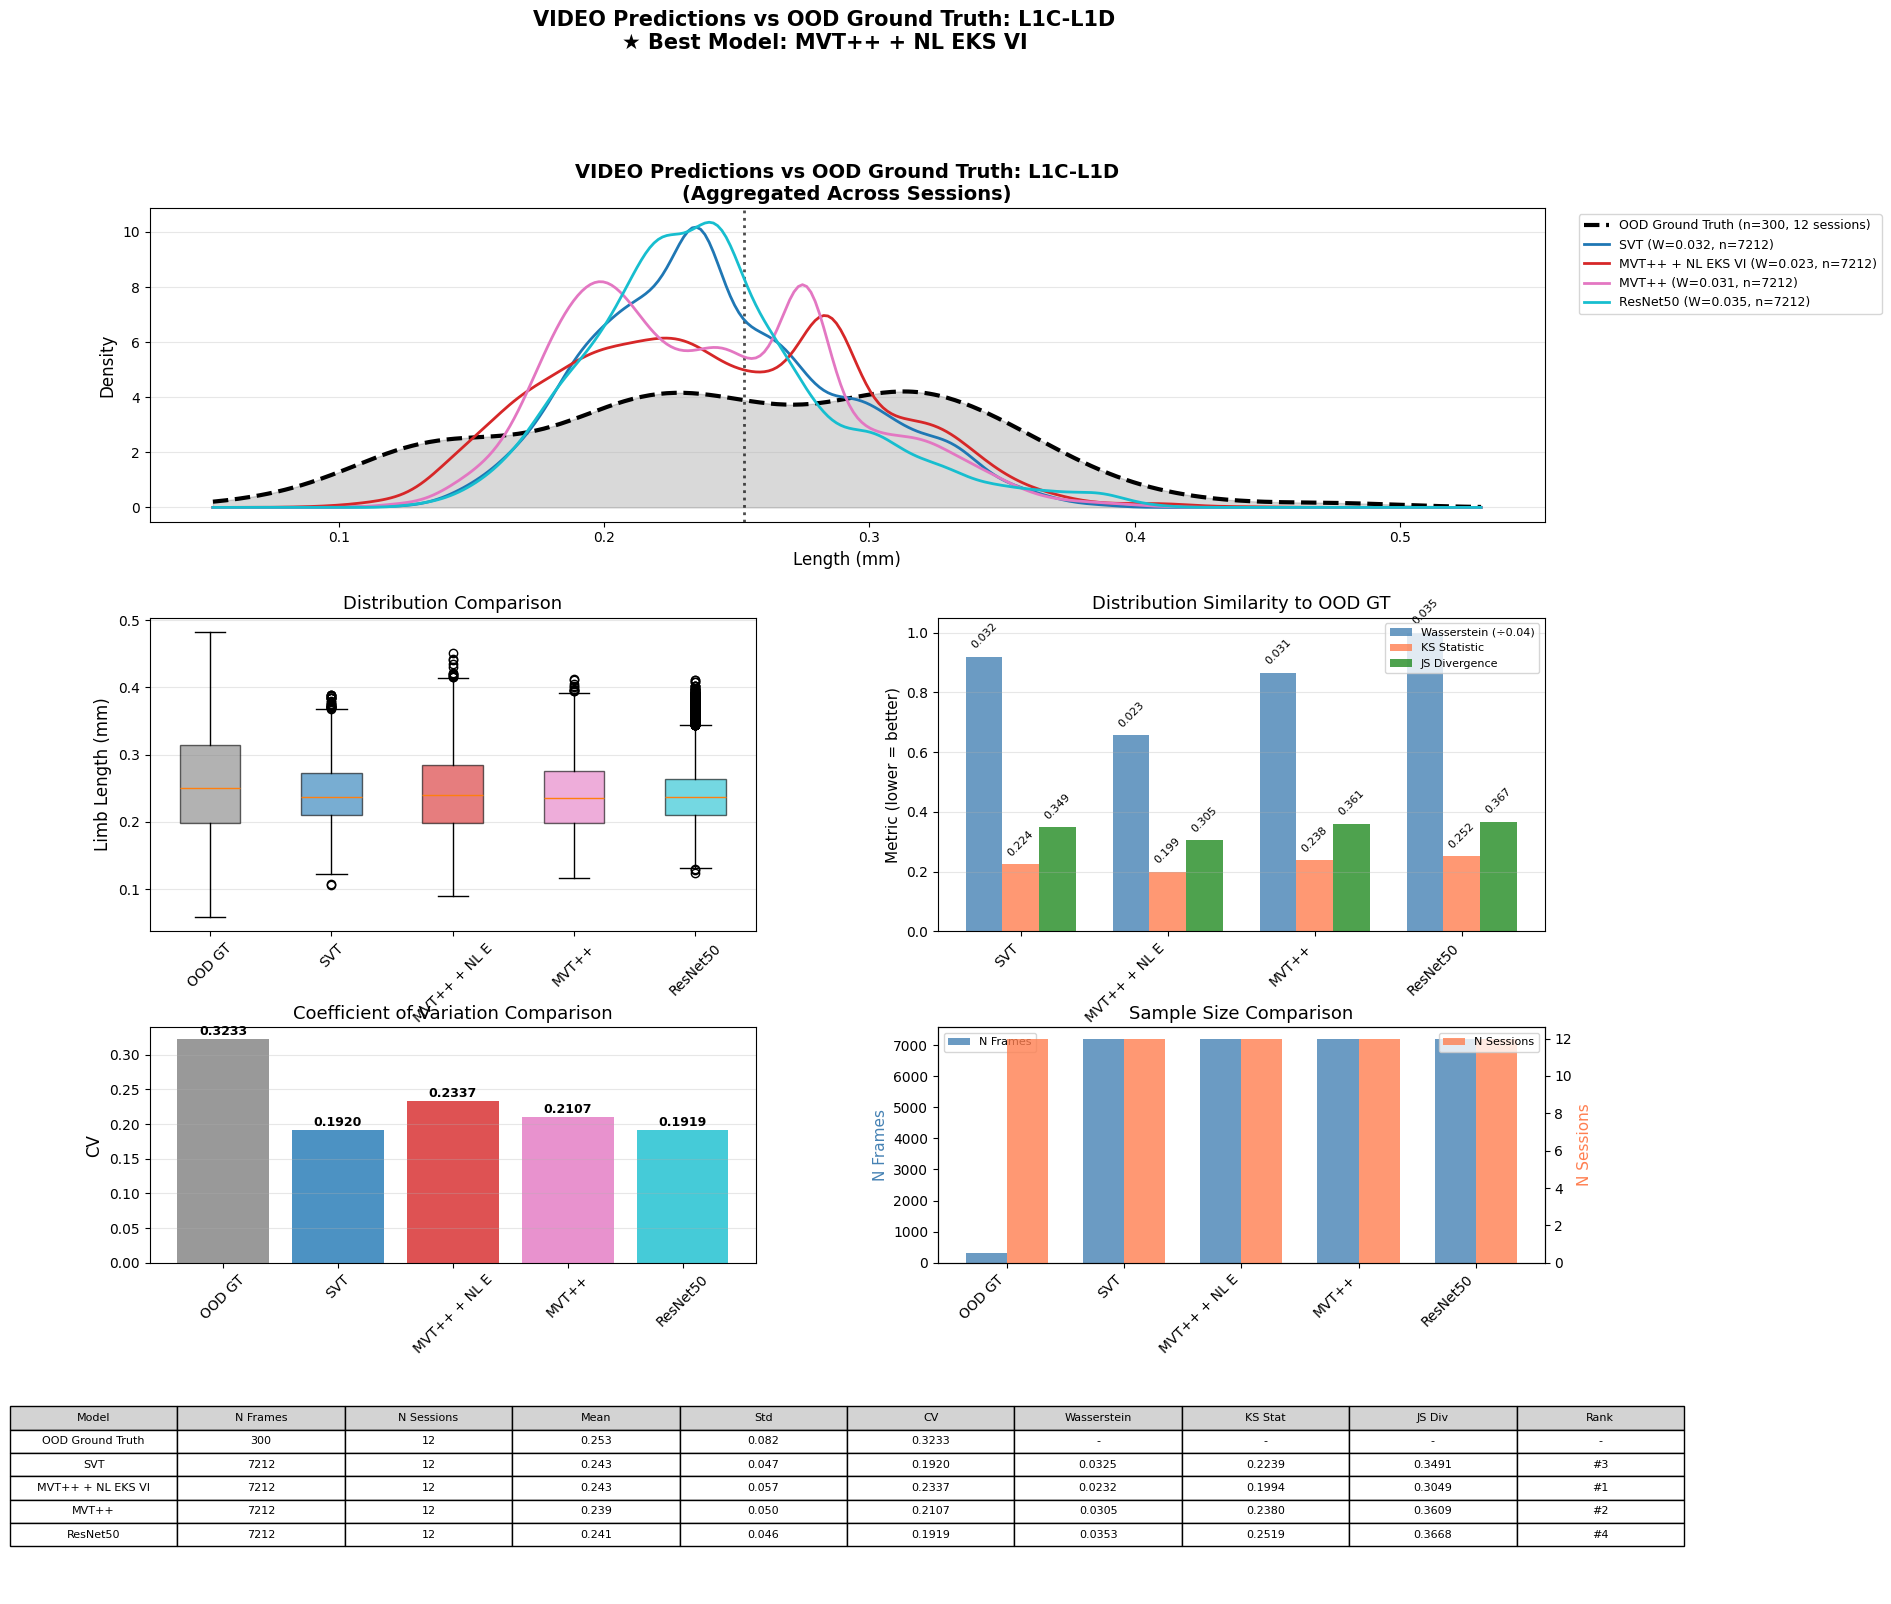

In [ ]:
# # ============================================================================
# # Step 1: Compute limb lengths from video predictions (if not already done)
# # ============================================================================

# # Define which models to process
# model_names_map = {
#     'test_200_multiview_resnet50_ensemble_median': 'ResNet50',
#     'test_200_SV_vits_dino_ensemble_median': 'SVT',
#     'test_200_MVT_3d_loss_patch_masking_ensemble_median': 'MVT++',
#     'test_200_MVT_3d_loss_patch_masking_non_linear_eks_varinf': 'MVT++ + NL EKS VI',
# }

# models_to_compare = list(model_names_map.keys())

# # Compute video limb lengths for selected models
# print("Computing video limb lengths...")
# video_limb_lengths = compute_video_limb_lengths_all_sessions(
#     all_file_paths=all_file_paths,
#     views=views,
#     camera_params_dir=camera_params_dir,
#     skeleton=skeleton,
#     models_to_process=models_to_compare
# )

# # ============================================================================
# # Step 2: Compare VIDEO predictions to OOD ground truth
# # ============================================================================

# limb_to_plot = 'L1C-L1D'

# model_data = plot_video_vs_ood_comparison(
#     video_limb_lengths=video_limb_lengths,
#     ood_gt_limb_lengths=ood_limb_lengths_by_session,  # OOD GT computed earlier
#     limb_name=limb_to_plot,
#     model_names_map=model_names_map,
#     models_to_compare=models_to_compare
# )

This can be a decent plot

In [ ]:
# # ============================================================================
# # Analyze 3D limb lengths across sessions for OOD labeled data
# # Check for order of magnitude differences and camera parameter clusters
# # ============================================================================

# import toml
# from pathlib import Path

# def load_camera_params_for_analysis(camera_params_dir: str) -> Dict[str, Dict]:
#     """
#     Load all camera calibration files and extract key parameters.
#     """
#     calib_files = list(Path(camera_params_dir).glob("*.toml"))
    
#     session_params = {}
    
#     for calib_file in calib_files:
#         session_name = calib_file.stem
        
#         try:
#             with open(calib_file, 'r') as f:
#                 data = toml.load(f)
            
#             # Extract camera parameters
#             cameras = {}
#             for key, value in data.items():
#                 if key.startswith('cam_'):
#                     cam_name = value.get('name', key)
#                     matrix = np.array(value['matrix'])
#                     focal_length = matrix[0, 0]  # fx (assuming fx = fy)
#                     translation = np.array(value['translation'])
#                     rotation = np.array(value['rotation'])
                    
#                     cameras[cam_name] = {
#                         'focal_length': focal_length,
#                         'translation': translation,
#                         'rotation': rotation,
#                         'distance': np.linalg.norm(translation),  # Distance from origin
#                     }
            
#             # Get average parameters across cameras
#             focal_lengths = [c['focal_length'] for c in cameras.values()]
#             distances = [c['distance'] for c in cameras.values()]
            
#             session_params[session_name] = {
#                 'cameras': cameras,
#                 'avg_focal_length': np.mean(focal_lengths),
#                 'std_focal_length': np.std(focal_lengths),
#                 'avg_distance': np.mean(distances),
#                 'error': data.get('metadata', {}).get('error', np.nan)
#             }
            
#         except Exception as e:
#             print(f"Error loading {calib_file}: {e}")
    
#     return session_params


# def analyze_ood_limb_lengths_per_session(
#     ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
#     limbs_to_analyze: List[str] = None
# ) -> pd.DataFrame:
#     """
#     Compute statistics for each limb in each session.
#     """
#     rows = []
    
#     for session_name, limb_data in ood_gt_limb_lengths.items():
#         # Extract fly ID from session name
#         parts = session_name.split('_')
#         fly_id = parts[1] if len(parts) > 1 else 'unknown'
        
#         limbs = limbs_to_analyze if limbs_to_analyze else list(limb_data.keys())
        
#         for limb_name in limbs:
#             if limb_name not in limb_data:
#                 continue
            
#             lengths = limb_data[limb_name]
#             valid = lengths[~np.isnan(lengths)]
            
#             if len(valid) > 0:
#                 rows.append({
#                     'session': session_name,
#                     'fly_id': fly_id,
#                     'limb': limb_name,
#                     'n_frames': len(valid),
#                     'mean': np.mean(valid),
#                     'std': np.std(valid),
#                     'cv': np.std(valid) / np.mean(valid) if np.mean(valid) > 0 else np.nan,
#                     'min': np.min(valid),
#                     'max': np.max(valid),
#                     'median': np.median(valid),
#                 })
    
#     return pd.DataFrame(rows)


# def plot_session_comparison_dashboard(
#     ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
#     camera_params_dir: str,
#     limb_to_analyze: str,
#     figsize: Tuple[int, int] = (20, 18)
# ):
#     """
#     Compare limb lengths and camera parameters across sessions.
#     """
#     # Load camera parameters
#     session_params = load_camera_params_for_analysis(camera_params_dir)
    
#     # Get limb length statistics
#     stats_df = analyze_ood_limb_lengths_per_session(ood_gt_limb_lengths, [limb_to_analyze])
    
#     if stats_df.empty:
#         print("No data available")
#         return
    
#     # Sort by mean limb length for visualization
#     stats_df = stats_df.sort_values('mean')
    
#     sessions = stats_df['session'].tolist()
#     n_sessions = len(sessions)
    
#     # Assign colors by fly
#     fly_ids = stats_df['fly_id'].unique()
#     fly_colors = {fly: plt.cm.Set1(i / len(fly_ids)) for i, fly in enumerate(fly_ids)}
#     colors = [fly_colors[fly] for fly in stats_df['fly_id']]
    
#     # Create figure
#     fig = plt.figure(figsize=figsize)
#     gs = GridSpec(4, 2, figure=fig, hspace=0.4, wspace=0.3, height_ratios=[2, 1.5, 1.5, 1.5])
    
#     # ===== Plot 1: Limb length distributions per session =====
#     ax1 = fig.add_subplot(gs[0, :])
    
#     # Collect data for box plots
#     box_data = []
#     for session in sessions:
#         if session in ood_gt_limb_lengths and limb_to_analyze in ood_gt_limb_lengths[session]:
#             lengths = ood_gt_limb_lengths[session][limb_to_analyze]
#             valid = lengths[~np.isnan(lengths)]
#             box_data.append(valid)
#         else:
#             box_data.append(np.array([]))
    
#     bp = ax1.boxplot(box_data, labels=[s[:20] for s in sessions], patch_artist=True)
    
#     for patch, color in zip(bp['boxes'], colors):
#         patch.set_facecolor(color)
#         patch.set_alpha(0.7)
    
#     ax1.set_ylabel(f'{limb_to_analyze} Length (mm)', fontsize=12)
#     ax1.set_title(f'OOD Labeled Data: {limb_to_analyze} Length per Session\n(Colored by Fly ID)', fontsize=14)
#     ax1.tick_params(axis='x', rotation=45)
#     ax1.grid(axis='y', alpha=0.3)
    
#     # Add legend for flies
#     handles = [plt.Rectangle((0,0),1,1, facecolor=fly_colors[fly], alpha=0.7) for fly in fly_ids]
#     ax1.legend(handles, fly_ids, loc='upper left', title='Fly ID')
    
#     # ===== Plot 2: Mean ± Std bar chart =====
#     ax2 = fig.add_subplot(gs[1, 0])
    
#     x = np.arange(n_sessions)
#     means = stats_df['mean'].values
#     stds = stats_df['std'].values
    
#     bars = ax2.bar(x, means, yerr=stds, capsize=3, color=colors, alpha=0.8)
    
#     ax2.set_ylabel('Mean Length (mm)')
#     ax2.set_title('Mean ± Std per Session')
#     ax2.set_xticks(x)
#     ax2.set_xticklabels([s[:15] for s in sessions], rotation=45, ha='right', fontsize=8)
#     ax2.grid(axis='y', alpha=0.3)
    
#     # Check for order of magnitude differences
#     mean_range = means.max() / means.min() if means.min() > 0 else np.inf
#     ax2.text(0.02, 0.98, f'Range: {mean_range:.2f}x', transform=ax2.transAxes, 
#              fontsize=10, verticalalignment='top',
#              bbox=dict(boxstyle='round', facecolor='wheat'))
    
#     # ===== Plot 3: CV comparison =====
#     ax3 = fig.add_subplot(gs[1, 1])
    
#     cvs = stats_df['cv'].values
#     bars = ax3.bar(x, cvs, color=colors, alpha=0.8)
    
#     ax3.axhline(np.mean(cvs), color='red', linestyle='--', label=f'Mean CV: {np.mean(cvs):.4f}')
#     ax3.set_ylabel('Coefficient of Variation')
#     ax3.set_title('CV per Session (lower = more consistent)')
#     ax3.set_xticks(x)
#     ax3.set_xticklabels([s[:15] for s in sessions], rotation=45, ha='right', fontsize=8)
#     ax3.legend()
#     ax3.grid(axis='y', alpha=0.3)
    
#     # ===== Plot 4: Camera focal lengths per session =====
#     ax4 = fig.add_subplot(gs[2, 0])
    
#     focal_lengths = []
#     session_names_with_calib = []
    
#     for session in sessions:
#         if session in session_params:
#             focal_lengths.append(session_params[session]['avg_focal_length'])
#             session_names_with_calib.append(session)
    
#     if focal_lengths:
#         x_calib = np.arange(len(focal_lengths))
#         ax4.bar(x_calib, focal_lengths, color='steelblue', alpha=0.8)
#         ax4.set_ylabel('Avg Focal Length')
#         ax4.set_title('Camera Focal Length per Session')
#         ax4.set_xticks(x_calib)
#         ax4.set_xticklabels([s[:15] for s in session_names_with_calib], rotation=45, ha='right', fontsize=8)
#         ax4.set_yscale('log')  # Log scale to see variations
#         ax4.grid(axis='y', alpha=0.3)
    
#     # ===== Plot 5: Calibration error per session =====
#     ax5 = fig.add_subplot(gs[2, 1])
    
#     calib_errors = []
#     for session in sessions:
#         if session in session_params:
#             calib_errors.append(session_params[session]['error'])
#         else:
#             calib_errors.append(np.nan)
    
#     valid_mask = ~np.isnan(calib_errors)
#     if np.any(valid_mask):
#         ax5.bar(np.arange(n_sessions)[valid_mask], np.array(calib_errors)[valid_mask], 
#                 color=[colors[i] for i in range(n_sessions) if valid_mask[i]], alpha=0.8)
#         ax5.set_ylabel('Calibration Error')
#         ax5.set_title('Calibration Reprojection Error per Session')
#         ax5.set_xticks(np.arange(n_sessions))
#         ax5.set_xticklabels([s[:15] for s in sessions], rotation=45, ha='right', fontsize=8)
#         ax5.grid(axis='y', alpha=0.3)
    
#     # ===== Plot 6: Correlation: Limb length vs Calibration =====
#     ax6 = fig.add_subplot(gs[3, 0])
    
#     # Plot mean limb length vs calibration error
#     valid_sessions = [(means[i], calib_errors[i], sessions[i], colors[i]) 
#                       for i in range(n_sessions) if not np.isnan(calib_errors[i])]
    
#     if valid_sessions:
#         mean_vals = [v[0] for v in valid_sessions]
#         error_vals = [v[1] for v in valid_sessions]
#         scatter_colors = [v[3] for v in valid_sessions]
        
#         ax6.scatter(error_vals, mean_vals, c=scatter_colors, s=100, alpha=0.7)
        
#         # Add correlation coefficient
#         if len(mean_vals) > 2:
#             corr = np.corrcoef(error_vals, mean_vals)[0, 1]
#             ax6.text(0.02, 0.98, f'Correlation: {corr:.3f}', transform=ax6.transAxes,
#                     fontsize=10, verticalalignment='top',
#                     bbox=dict(boxstyle='round', facecolor='wheat'))
        
#         ax6.set_xlabel('Calibration Error')
#         ax6.set_ylabel(f'Mean {limb_to_analyze} Length')
#         ax6.set_title('Limb Length vs Calibration Error')
#         ax6.grid(alpha=0.3)
    
#     # ===== Plot 7: Summary statistics =====
#     ax7 = fig.add_subplot(gs[3, 1])
#     ax7.axis('off')
    
#     # Summary table
#     summary_data = [
#         ['Metric', 'Value'],
#         ['N Sessions', f'{n_sessions}'],
#         ['N Flies', f'{len(fly_ids)}'],
#         ['Overall Mean', f'{means.mean():.4f}'],
#         ['Mean Range (max/min)', f'{mean_range:.2f}x'],
#         ['Avg CV', f'{cvs.mean():.4f}'],
#         ['CV Range', f'{cvs.min():.4f} - {cvs.max():.4f}'],
#     ]
    
#     table = ax7.table(cellText=summary_data[1:], colLabels=summary_data[0],
#                       loc='center', cellLoc='center', colColours=['lightgray']*2)
#     table.auto_set_font_size(False)
#     table.set_fontsize(11)
#     table.scale(1.2, 1.8)
    
#     plt.suptitle(f'Cross-Session Analysis: {limb_to_analyze} (OOD Labeled Data)', 
#                  fontsize=16, fontweight='bold', y=0.99)
#     plt.tight_layout(rect=[0, 0, 1, 0.97])
#     plt.show()
    
#     # Print detailed statistics
#     print("\n" + "="*80)
#     print(f"DETAILED SESSION STATISTICS: {limb_to_analyze}")
#     print("="*80)
#     print(stats_df.to_string(index=False))
    
#     # Check for outlier sessions
#     print("\n" + "="*80)
#     print("OUTLIER ANALYSIS:")
#     print("="*80)
    
#     mean_overall = means.mean()
#     std_overall = means.std()
    
#     outliers = stats_df[np.abs(stats_df['mean'] - mean_overall) > 2 * std_overall]
#     if not outliers.empty:
#         print("\nSessions with mean > 2σ from overall mean:")
#         print(outliers[['session', 'fly_id', 'mean', 'std', 'cv']].to_string(index=False))
#     else:
#         print("\nNo sessions with mean > 2σ from overall mean")
    
#     return stats_df


# def plot_all_limbs_session_comparison(
#     ood_gt_limb_lengths: Dict[str, Dict[str, np.ndarray]],
#     figsize: Tuple[int, int] = (20, 12)
# ):
#     """
#     Compare all limbs across sessions to check for systematic scale differences.
#     """
#     # Get all limb names
#     all_limbs = set()
#     for session_data in ood_gt_limb_lengths.values():
#         all_limbs.update(session_data.keys())
#     all_limbs = sorted(list(all_limbs))
    
#     # Get statistics for all limbs
#     stats_df = analyze_ood_limb_lengths_per_session(ood_gt_limb_lengths, all_limbs)
    
#     # Compute mean per session (average across limbs) - to check for scale
#     session_scale = stats_df.groupby('session').agg({
#         'mean': 'mean',
#         'cv': 'mean',
#         'fly_id': 'first'
#     }).reset_index()
    
#     session_scale = session_scale.sort_values('mean')
    
#     n_sessions = len(session_scale)
    
#     fly_ids = session_scale['fly_id'].unique()
#     fly_colors = {fly: plt.cm.Set1(i / len(fly_ids)) for i, fly in enumerate(fly_ids)}
#     colors = [fly_colors[fly] for fly in session_scale['fly_id']]
    
#     # Create figure
#     fig, axes = plt.subplots(2, 2, figsize=figsize)
    
#     # ===== Plot 1: Average limb length per session (scale check) =====
#     ax1 = axes[0, 0]
    
#     x = np.arange(n_sessions)
#     bars = ax1.bar(x, session_scale['mean'].values, color=colors, alpha=0.8)
    
#     # Calculate range
#     mean_range = session_scale['mean'].max() / session_scale['mean'].min()
#     ax1.text(0.02, 0.98, f'Scale Range: {mean_range:.2f}x', transform=ax1.transAxes,
#              fontsize=11, verticalalignment='top', fontweight='bold',
#              bbox=dict(boxstyle='round', facecolor='yellow' if mean_range > 1.5 else 'lightgreen'))
    
#     ax1.set_ylabel('Average Limb Length (all limbs)')
#     ax1.set_title('Average 3D Scale per Session\n(Should be similar if calibrations are consistent)')
#     ax1.set_xticks(x)
#     ax1.set_xticklabels([s[:15] for s in session_scale['session']], rotation=45, ha='right', fontsize=8)
#     ax1.grid(axis='y', alpha=0.3)
    
#     # ===== Plot 2: Heatmap of limb lengths per session =====
#     ax2 = axes[0, 1]
    
#     # Pivot the data
#     pivot_df = stats_df.pivot(index='session', columns='limb', values='mean')
#     pivot_df = pivot_df.loc[session_scale['session']]  # Sort by average
    
#     # Normalize each limb to its mean (to see relative differences)
#     normalized = pivot_df / pivot_df.mean()
    
#     im = ax2.imshow(normalized.values, cmap='RdYlGn', aspect='auto', vmin=0.5, vmax=1.5)
#     ax2.set_xticks(np.arange(len(pivot_df.columns)))
#     ax2.set_yticks(np.arange(len(pivot_df.index)))
#     ax2.set_xticklabels(pivot_df.columns, rotation=45, ha='right', fontsize=7)
#     ax2.set_yticklabels([s[:20] for s in pivot_df.index], fontsize=7)
#     ax2.set_title('Normalized Limb Lengths\n(1.0 = average, red < avg, green > avg)')
#     plt.colorbar(im, ax=ax2, label='Normalized Length')
    
#     # ===== Plot 3: Limb length correlation across sessions =====
#     ax3 = axes[1, 0]
    
#     # Select a few representative limbs
#     sample_limbs = all_limbs[:min(6, len(all_limbs))]
    
#     for limb in sample_limbs:
#         limb_means = []
#         for session in session_scale['session']:
#             row = stats_df[(stats_df['session'] == session) & (stats_df['limb'] == limb)]
#             if not row.empty:
#                 limb_means.append(row['mean'].values[0])
#             else:
#                 limb_means.append(np.nan)
#         ax3.plot(range(n_sessions), limb_means, 'o-', label=limb, alpha=0.7)
    
#     ax3.set_ylabel('Mean Length')
#     ax3.set_title('Limb Lengths Across Sessions\n(Parallel lines = consistent scale)')
#     ax3.set_xticks(range(n_sessions))
#     ax3.set_xticklabels([s[:12] for s in session_scale['session']], rotation=45, ha='right', fontsize=7)
#     ax3.legend(fontsize=8, ncol=2)
#     ax3.grid(alpha=0.3)
    
#     # ===== Plot 4: Per-fly statistics =====
#     ax4 = axes[1, 1]
    
#     fly_stats = stats_df.groupby('fly_id').agg({
#         'mean': ['mean', 'std'],
#         'session': 'count'
#     }).reset_index()
#     fly_stats.columns = ['fly_id', 'mean', 'std', 'n_sessions']
    
#     x = np.arange(len(fly_stats))
#     fly_bar_colors = [fly_colors[fly] for fly in fly_stats['fly_id']]
    
#     ax4.bar(x, fly_stats['mean'], yerr=fly_stats['std'], capsize=5, 
#             color=fly_bar_colors, alpha=0.8)
    
#     ax4.set_ylabel('Average Limb Length')
#     ax4.set_title('Average Limb Length per Fly\n(Different flies may have different sizes)')
#     ax4.set_xticks(x)
#     ax4.set_xticklabels(fly_stats['fly_id'])
#     ax4.grid(axis='y', alpha=0.3)
    
#     plt.suptitle('Cross-Session Scale Analysis (OOD Labeled Data)', fontsize=15, fontweight='bold')
#     plt.tight_layout(rect=[0, 0, 1, 0.96])
#     plt.show()
    
#     return stats_df, session_scale

In [ ]:
# # Analyze a specific limb across sessions
# limb_to_analyze = 'L1C-L1D'

# stats_df = plot_session_comparison_dashboard(
#     ood_gt_limb_lengths=ood_limb_lengths_by_session,
#     # camera_params_dir=camera_params_dir,
#     camera_params_dir=FLY_CALIB_DIR_OPTIMIZED,
#     limb_to_analyze=limb_to_analyze
# )

# # Analyze ALL limbs to check for systematic scale differences
# all_stats_df, session_scale_df = plot_all_limbs_session_comparison(
#     ood_gt_limb_lengths=ood_limb_lengths_by_session
# )

# print("\nSession scale summary:")
# print(session_scale_df.to_string(index=False))

NameError: name 'ood_limb_lengths_by_session' is not defined

# Camera parameters Analysis iBL Mouse

IBL MOUSE: Triangulating All Sessions
Loading /teamspace/studios/data/ibl-mouse/CollectedData_leftCamera_new.csv...
Loading /teamspace/studios/data/ibl-mouse/CollectedData_rightCamera_new.csv...

Found 7 sessions

Processing session: 15b69921-d471-4ded-8814-2adad954bcd8
  Found 40 common frames across views
  Camera order in calibration: ['rightCamera', 'leftCamera']
  View order in data: ['leftCamera', 'rightCamera']
  View mapping: {0: 1, 1: 0}
  Triangulated: 40/40 valid frames

Processing session: 15763234-d21e-491f-a01b-1238eb96d389
  Found 40 common frames across views
  Camera order in calibration: ['rightCamera', 'leftCamera']
  View order in data: ['leftCamera', 'rightCamera']
  View mapping: {0: 1, 1: 0}
  Triangulated: 40/40 valid frames

Processing session: aad23144-0e52-4eac-80c5-c4ee2decb198
  Found 40 common frames across views
  Camera order in calibration: ['rightCamera', 'leftCamera']
  View order in data: ['leftCamera', 'rightCamera']
  View mapping: {0: 1, 1: 0}
  T

/teamspace/studios/this_studio/lightning-pose/lightning_pose/data/cameras.py:209: All-NaN slice encountered


  Triangulated: 40/40 valid frames

Processing session: f312aaec-3b6f-44b3-86b4-3a0c119c0438
  Found 40 common frames across views
  Camera order in calibration: ['rightCamera', 'leftCamera']
  View order in data: ['leftCamera', 'rightCamera']
  View mapping: {0: 1, 1: 0}
  Triangulated: 40/40 valid frames

Processing session: 0841d188-8ef2-4f20-9828-76a94d5343a4
  Found 40 common frames across views
  Camera order in calibration: ['rightCamera', 'leftCamera']
  View order in data: ['leftCamera', 'rightCamera']
  View mapping: {0: 1, 1: 0}
  Triangulated: 40/40 valid frames

Processing session: 4b00df29-3769-43be-bb40-128b1cba6d35
  Found 40 common frames across views
  Camera order in calibration: ['rightCamera', 'leftCamera']
  View order in data: ['leftCamera', 'rightCamera']
  View mapping: {0: 1, 1: 0}
  Triangulated: 40/40 valid frames

Successfully processed 7 sessions
CROSS-SESSION 3D POSE VARIABILITY ANALYSIS


/tmp/ipykernel_7331/2747956514.py:631: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


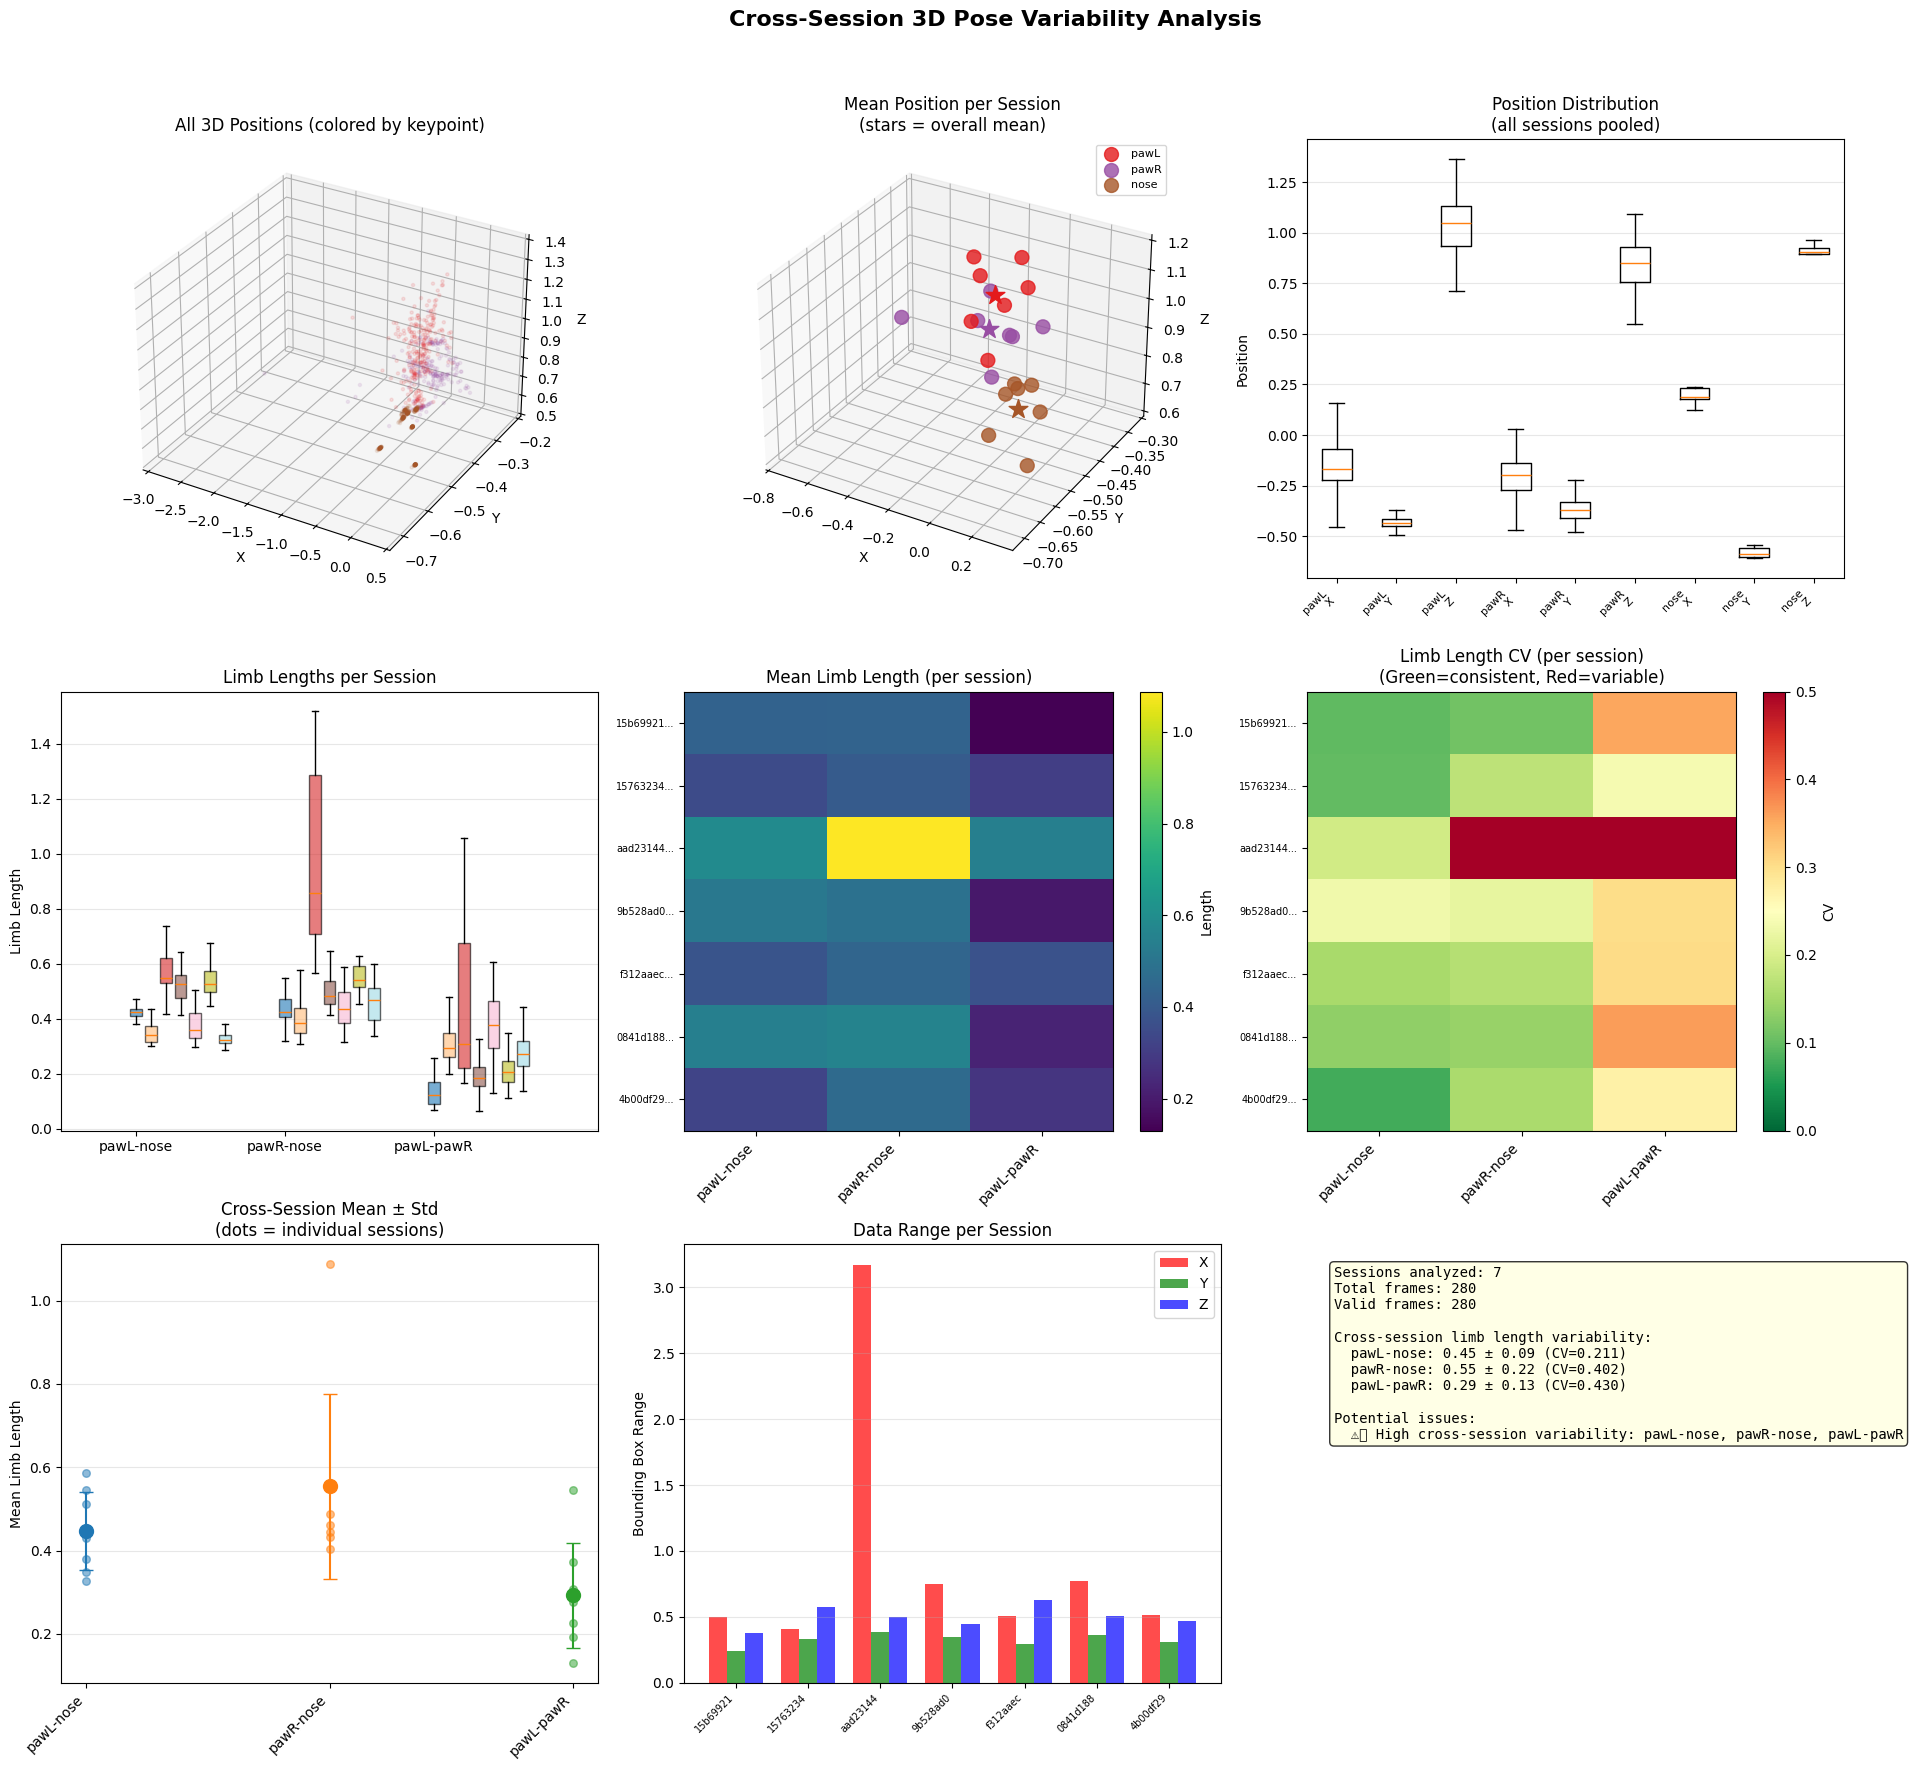


DETAILED SESSION COMPARISON

Session                                    Frames    Valid
------------------------------------------------------------
15b69921-d471-4ded-8814-2adad954bcd8           40       40
15763234-d21e-491f-a01b-1238eb96d389           40       40
aad23144-0e52-4eac-80c5-c4ee2decb198           40       40
9b528ad0-4599-4a55-9148-96cc1d93fb24           40       40
f312aaec-3b6f-44b3-86b4-3a0c119c0438           40       40
0841d188-8ef2-4f20-9828-76a94d5343a4           40       40
4b00df29-3769-43be-bb40-128b1cba6d35           40       40


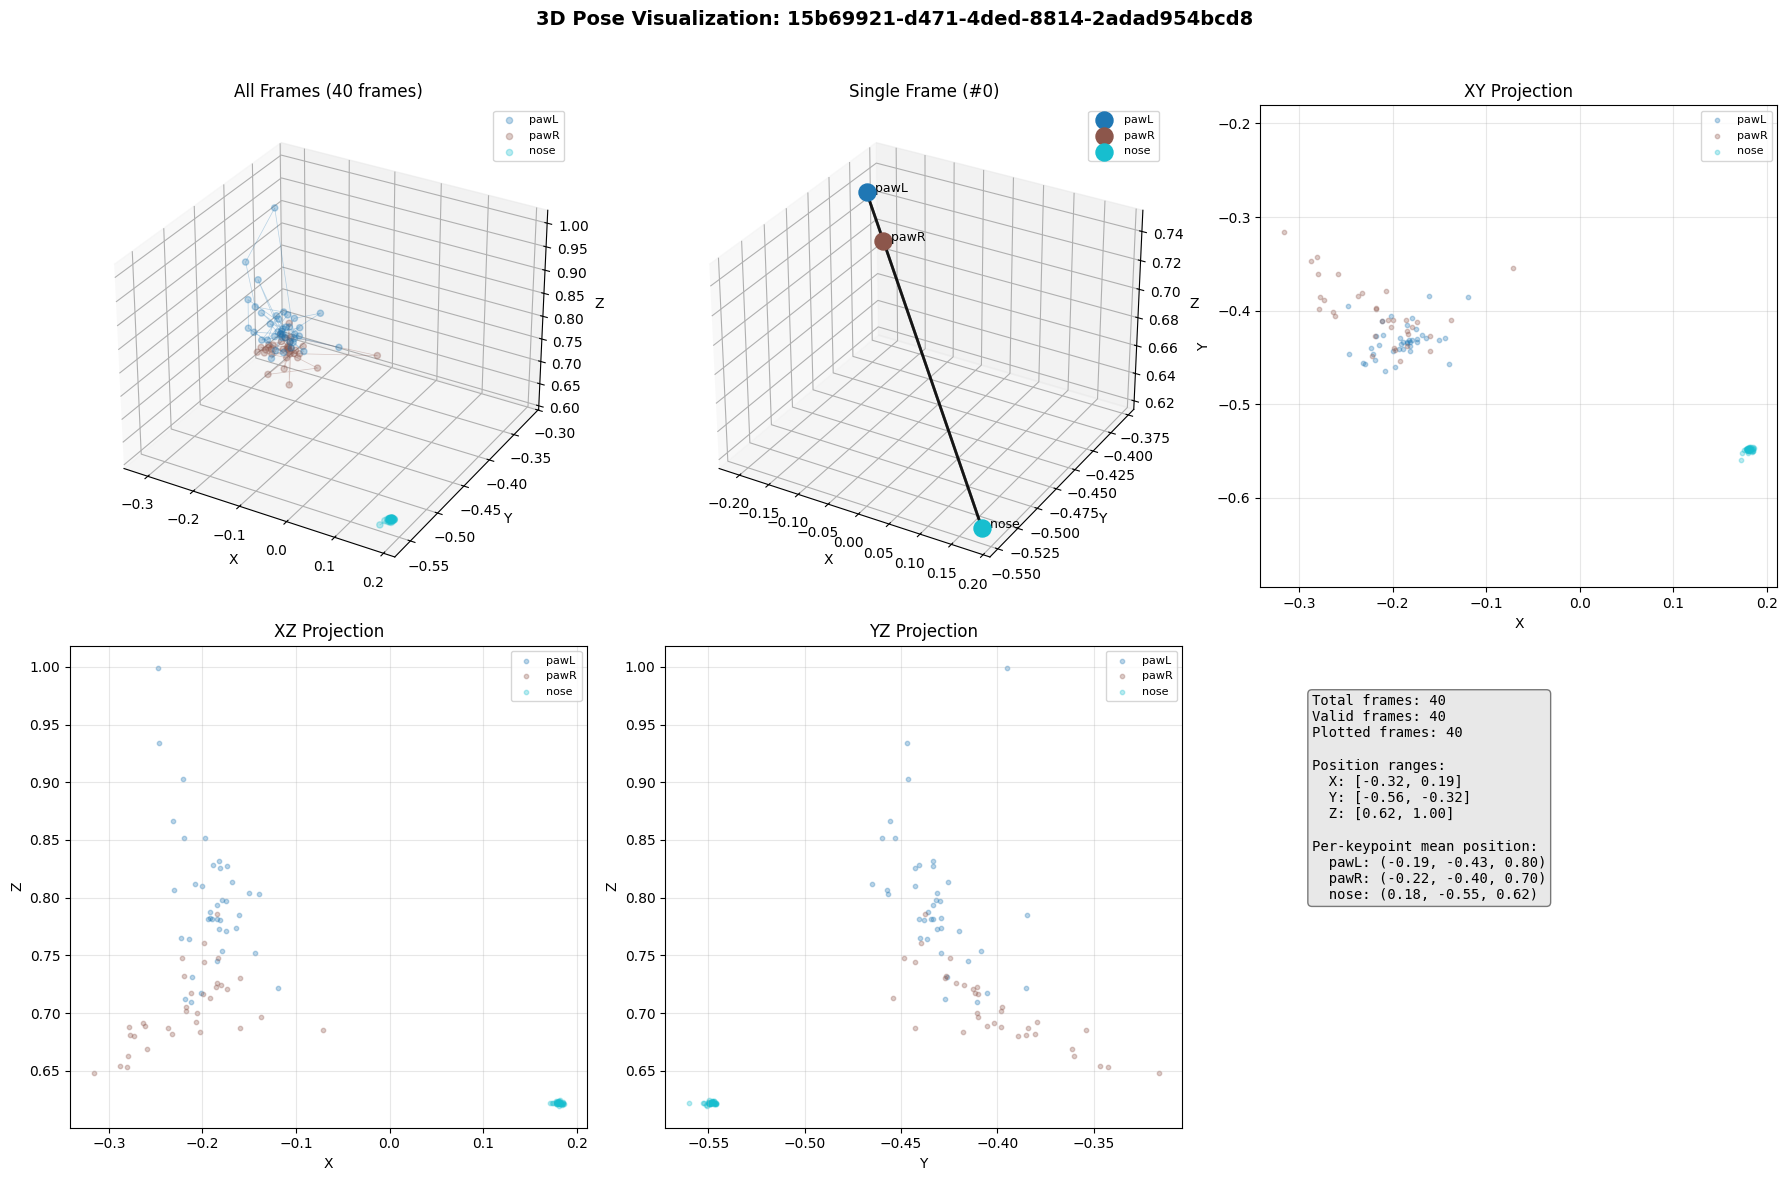

In [106]:
# ============================================================================
# IBL MOUSE: 3D POSE TRIANGULATION AND CROSS-SESSION VARIABILITY ANALYSIS
# ============================================================================

import pandas as pd
import numpy as np
import torch
import re
from pathlib import Path
from typing import Dict, List, Tuple, Optional
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from lightning_pose.data.cameras import CameraGroup

# ============================================================================
# IBL Dataset Configuration
# ============================================================================

IBL_VIEWS = ['leftCamera', 'rightCamera']
IBL_KEYPOINTS = ['pawL', 'pawR', 'nose']
IBL_SKELETON = [('pawL', 'nose'), ('pawR', 'nose'), ('pawL', 'pawR')]

# Data paths
IBL_DATA_DIR = "/teamspace/studios/data/ibl-mouse"
IBL_CALIB_DIR = "/teamspace/studios/data/ibl-mouse/calibrations"

# In-distribution and OOD labeled data
IBL_ID_PATHS = {
    'leftCamera': f"{IBL_DATA_DIR}/CollectedData_leftCamera.csv",
    'rightCamera': f"{IBL_DATA_DIR}/CollectedData_rightCamera.csv"
}
IBL_OOD_PATHS = {
    'leftCamera': f"{IBL_DATA_DIR}/CollectedData_leftCamera_new.csv",
    'rightCamera': f"{IBL_DATA_DIR}/CollectedData_rightCamera_new.csv"
}

# Sessions to analyze (filter list - set to None for all)
VALID_SESSIONS = [
    "aad23144-0e52-4eac-80c5-c4ee2decb198",
    "15b69921-d471-4ded-8814-2adad954bcd8",
    "15763234-d21e-491f-a01b-1238eb96d389",
    "9b528ad0-4599-4a55-9148-96cc1d93fb24",
    "4b00df29-3769-43be-bb40-128b1cba6d35",
    "0841d188-8ef2-4f20-9828-76a94d5343a4",
    "f312aaec-3b6f-44b3-86b4-3a0c119c0438"
]


# ============================================================================
# Data Loading Functions
# ============================================================================

def extract_session_id_ibl(index_str: str) -> str:
    """
    Extract session UUID from IBL image path.
    E.g., 'labeled_data/_iblrig_leftCamera.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c/img00014526.jpg'
    Returns: '0802ced5-33a3-405e-8336-b65ebc5cb07c'
    """
    # Look for UUID pattern (8-4-4-4-12 hex digits)
    match = re.search(r'([a-f0-9]{8}-[a-f0-9]{4}-[a-f0-9]{4}-[a-f0-9]{4}-[a-f0-9]{12})', index_str)
    if match:
        return match.group(1)
    return None


def extract_frame_id_ibl(index_str: str) -> str:
    """
    Extract frame identifier from IBL image path.
    E.g., 'labeled_data/_iblrig_leftCamera.downsampled.UUID/img00014526.jpg'
    Returns: 'img00014526' (common across views)
    """
    match = re.search(r'(img\d+)\.', index_str)
    if match:
        return match.group(1)
    return None


def load_ibl_labeled_data(
    data_paths: Dict[str, str],
    views: List[str],
    session_filter: List[str] = None
) -> Dict[str, Dict[str, pd.DataFrame]]:
    """
    Load IBL labeled data and organize by session.
    
    Returns:
    --------
    Dict[session_id, Dict[view, DataFrame]]
        Data organized by session, then by view
    """
    session_data = {}
    
    for view in views:
        csv_path = data_paths.get(view)
        if not csv_path or not Path(csv_path).exists():
            print(f"Warning: {csv_path} not found")
            continue
        
        print(f"Loading {csv_path}...")
        df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
        
        for idx in df.index:
            session_id = extract_session_id_ibl(idx)
            if session_id is None:
                continue
            
            # Filter by session if specified
            if session_filter is not None and session_id not in session_filter:
                continue
            
            if session_id not in session_data:
                session_data[session_id] = {}
            
            if view not in session_data[session_id]:
                session_data[session_id][view] = {'indices': [], 'frame_ids': []}
            
            frame_id = extract_frame_id_ibl(idx)
            session_data[session_id][view]['indices'].append(idx)
            session_data[session_id][view]['frame_ids'].append(frame_id)
        
        # Convert to DataFrames per session
        for session_id in list(session_data.keys()):
            if view in session_data[session_id]:
                indices = session_data[session_id][view]['indices']
                session_data[session_id][view] = {
                    'df': df.loc[indices],
                    'frame_ids': session_data[session_id][view]['frame_ids']
                }
    
    print(f"\nFound {len(session_data)} sessions")
    return session_data


def load_camera_params_ibl(session_id: str, calib_dir: str) -> Optional[CameraGroup]:
    """
    Load camera calibration for an IBL session.
    """
    # Find calibration file (has prefix _iblrig.downsampled.)
    calib_pattern = f"_iblrig.downsampled.{session_id}.toml"
    calib_file = Path(calib_dir) / calib_pattern
    
    if not calib_file.exists():
        # Try direct match
        calib_file = Path(calib_dir) / f"{session_id}.toml"
    
    if not calib_file.exists():
        print(f"  Calibration not found for session: {session_id}")
        return None
    
    try:
        camera_group = CameraGroup.load(str(calib_file))
        return camera_group
    except Exception as e:
        print(f"  Error loading calibration for {session_id}: {e}")
        return None


def prepare_multiview_tensor_ibl(
    session_view_data: Dict[str, Dict],
    views: List[str],
    keypoints: List[str]
) -> Tuple[np.ndarray, List[str]]:
    """
    Prepare multiview tensor for triangulation from IBL session data.
    
    Returns:
    --------
    tensor : np.ndarray of shape (n_frames, n_keypoints, n_views, 2)
    common_frame_ids : List[str] of matched frame IDs
    """
    # Find common frames across all views
    common_frames = None
    for view in views:
        if view not in session_view_data:
            return None, []
        frame_ids = set(session_view_data[view]['frame_ids'])
        if common_frames is None:
            common_frames = frame_ids
        else:
            common_frames = common_frames.intersection(frame_ids)
    
    if not common_frames:
        return None, []
    
    common_frames = sorted(list(common_frames))
    n_frames = len(common_frames)
    n_keypoints = len(keypoints)
    n_views = len(views)
    
    # Create tensor: (n_frames, n_keypoints, n_views, 2)
    tensor = np.full((n_frames, n_keypoints, n_views, 2), np.nan)
    
    for view_idx, view in enumerate(views):
        df = session_view_data[view]['df']
        frame_ids = session_view_data[view]['frame_ids']
        
        # Create frame_id -> row index mapping
        frame_to_idx = {fid: i for i, fid in enumerate(frame_ids)}
        
        for frame_out_idx, frame_id in enumerate(common_frames):
            if frame_id not in frame_to_idx:
                continue
            
            row_idx = frame_to_idx[frame_id]
            row = df.iloc[row_idx]
            
            for kp_idx, kp in enumerate(keypoints):
                try:
                    x = row[('scorer', kp, 'x')]
                    y = row[('scorer', kp, 'y')]
                    if not np.isnan(x) and not np.isnan(y):
                        tensor[frame_out_idx, kp_idx, view_idx, 0] = x
                        tensor[frame_out_idx, kp_idx, view_idx, 1] = y
                except:
                    pass
    
    return tensor, common_frames


def triangulate_session_ibl(
    tensor: np.ndarray,
    camera_group: CameraGroup,
    keypoints: List[str],
    views: List[str]
) -> np.ndarray:
    """
    Triangulate 2D points to 3D for IBL session.
    
    Parameters:
    -----------
    tensor : np.ndarray of shape (n_frames, n_keypoints, n_views, 2)
    
    Returns:
    --------
    points_3d : np.ndarray of shape (n_frames, n_keypoints, 3)
    """
    n_frames, n_keypoints, n_views, _ = tensor.shape
    points_3d = np.full((n_frames, n_keypoints, 3), np.nan)
    
    # Get camera names from the camera group to ensure correct ordering
    camera_names_in_calib = [cam.name for cam in camera_group.cameras]
    print(f"  Camera order in calibration: {camera_names_in_calib}")
    print(f"  View order in data: {views}")
    
    # Create mapping from our view order to calibration camera order
    view_to_calib_idx = {}
    for v_idx, view in enumerate(views):
        if view in camera_names_in_calib:
            view_to_calib_idx[v_idx] = camera_names_in_calib.index(view)
        else:
            print(f"  WARNING: View '{view}' not found in calibration!")
            return points_3d
    
    print(f"  View mapping: {view_to_calib_idx}")
    
    n_cams = len(camera_group.cameras)
    
    for frame_idx in range(n_frames):
        # Get 2D points for this frame: (n_keypoints, n_views, 2)
        frame_2d = tensor[frame_idx]
        
        # Reorder to match calibration camera order: (n_cameras, n_keypoints, 2)
        # triangulate_fast expects shape (C, N, 2) where C=cameras, N=keypoints
        points_for_triang = np.full((n_cams, n_keypoints, 2), np.nan)
        
        for v_idx, calib_idx in view_to_calib_idx.items():
            points_for_triang[calib_idx] = frame_2d[:, v_idx, :]
        
        # Check if we have valid data in at least 2 cameras for some keypoints
        valid_per_cam = ~np.all(np.isnan(points_for_triang), axis=(1, 2))  # (n_cams,)
        if np.sum(valid_per_cam) < 2:
            continue
        
        try:
            # Triangulate: expects (n_cameras, n_keypoints, 2), returns (n_keypoints, 3)
            keypoints_3d = camera_group.triangulate_fast(points_for_triang, undistort=True)
            points_3d[frame_idx] = keypoints_3d
            
        except Exception as e:
            if frame_idx == 0:  # Only print first error
                print(f"  Triangulation error (frame {frame_idx}): {e}")
            continue
    
    return points_3d


# ============================================================================
# Main Pipeline: Triangulate All Sessions
# ============================================================================

def triangulate_all_sessions_ibl(
    data_paths: Dict[str, str],
    calib_dir: str,
    views: List[str] = IBL_VIEWS,
    keypoints: List[str] = IBL_KEYPOINTS,
    session_filter: List[str] = None
) -> Dict[str, Dict]:
    """
    Triangulate 3D poses for all IBL sessions.
    """
    print("="*80)
    print("IBL MOUSE: Triangulating All Sessions")
    print("="*80)
    
    # Load labeled data
    session_data = load_ibl_labeled_data(data_paths, views, session_filter)
    
    results = {}
    
    for session_id, view_data in session_data.items():
        print(f"\nProcessing session: {session_id}")
        
        # Check all views present
        if not all(v in view_data for v in views):
            print(f"  Skipping - missing views")
            continue
        
        # Load camera parameters
        camera_group = load_camera_params_ibl(session_id, calib_dir)
        if camera_group is None:
            continue
        
        # Prepare multiview tensor
        tensor, frame_ids = prepare_multiview_tensor_ibl(view_data, views, keypoints)
        if tensor is None or len(frame_ids) == 0:
            print(f"  Skipping - no common frames")
            continue
        
        print(f"  Found {len(frame_ids)} common frames across views")
        
        # Triangulate - pass views to ensure correct camera ordering
        points_3d = triangulate_session_ibl(tensor, camera_group, keypoints, views)
        
        # Count valid frames
        valid_frames = ~np.all(np.isnan(points_3d), axis=(1, 2))
        n_valid = np.sum(valid_frames)
        
        print(f"  Triangulated: {n_valid}/{len(frame_ids)} valid frames")
        
        results[session_id] = {
            'points_3d': points_3d,
            'n_frames': len(frame_ids),
            'n_valid_frames': n_valid,
            'frame_ids': frame_ids
        }
    
    print(f"\n{'='*80}")
    print(f"Successfully processed {len(results)} sessions")
    print("="*80)
    
    return results


# ============================================================================
# Cross-Session Variability Analysis
# ============================================================================

def analyze_cross_session_variability(
    all_session_3d: Dict[str, Dict],
    keypoints: List[str] = IBL_KEYPOINTS,
    skeleton: List[Tuple[str, str]] = IBL_SKELETON,
    figsize: Tuple[int, int] = (20, 18)
):
    """
    Analyze 3D pose variability across all sessions.
    """
    sessions = list(all_session_3d.keys())
    n_sessions = len(sessions)
    
    if n_sessions == 0:
        print("No sessions to analyze!")
        return None
    
    print("="*80)
    print("CROSS-SESSION 3D POSE VARIABILITY ANALYSIS")
    print("="*80)
    
    # ===== Collect statistics per session =====
    session_stats = {}
    all_positions = {kp: [] for kp in keypoints}
    all_limb_lengths = {f"{l[0]}-{l[1]}": [] for l in skeleton}
    
    for session_id, data in all_session_3d.items():
        points_3d = data['points_3d']  # (n_frames, n_keypoints, 3)
        
        stats = {'n_frames': data['n_frames'], 'n_valid': data['n_valid_frames']}
        
        # Per-keypoint statistics
        for kp_idx, kp in enumerate(keypoints):
            kp_data = points_3d[:, kp_idx, :]  # (n_frames, 3)
            valid_data = kp_data[~np.any(np.isnan(kp_data), axis=1)]
            
            if len(valid_data) > 0:
                stats[kp] = {
                    'mean': valid_data.mean(axis=0),
                    'std': valid_data.std(axis=0),
                    'min': valid_data.min(axis=0),
                    'max': valid_data.max(axis=0),
                    'n_valid': len(valid_data)
                }
                all_positions[kp].append({
                    'session': session_id,
                    'data': valid_data,
                    'mean': valid_data.mean(axis=0)
                })
        
        # Limb lengths
        for (kp1, kp2) in skeleton:
            limb_name = f"{kp1}-{kp2}"
            idx1, idx2 = keypoints.index(kp1), keypoints.index(kp2)
            
            diff = points_3d[:, idx1, :] - points_3d[:, idx2, :]
            lengths = np.linalg.norm(diff, axis=1)
            valid_lengths = lengths[~np.isnan(lengths)]
            
            if len(valid_lengths) > 0:
                stats[limb_name] = {
                    'mean': np.mean(valid_lengths),
                    'std': np.std(valid_lengths),
                    'cv': np.std(valid_lengths) / np.mean(valid_lengths),
                    'n_valid': len(valid_lengths)
                }
                all_limb_lengths[limb_name].append({
                    'session': session_id,
                    'lengths': valid_lengths,
                    'mean': np.mean(valid_lengths),
                    'std': np.std(valid_lengths)
                })
        
        session_stats[session_id] = stats
    
    # ===== Plotting =====
    fig = plt.figure(figsize=figsize)
    colors = plt.cm.tab20(np.linspace(0, 1, n_sessions))
    session_colors = {s: colors[i] for i, s in enumerate(sessions)}
    
    # Plot 1: 3D positions - all sessions overlaid
    ax1 = fig.add_subplot(3, 3, 1, projection='3d')
    for kp_idx, kp in enumerate(keypoints):
        kp_color = plt.cm.Set1(kp_idx / len(keypoints))
        for sess_data in all_positions[kp]:
            ax1.scatter(
                sess_data['data'][:, 0],
                sess_data['data'][:, 1],
                sess_data['data'][:, 2],
                c=[kp_color], alpha=0.1, s=5
            )
    ax1.set_xlabel('X')
    ax1.set_ylabel('Y')
    ax1.set_zlabel('Z')
    ax1.set_title('All 3D Positions (colored by keypoint)')
    
    # Plot 2: Mean positions per session per keypoint
    ax2 = fig.add_subplot(3, 3, 2, projection='3d')
    for kp_idx, kp in enumerate(keypoints):
        kp_color = plt.cm.Set1(kp_idx / len(keypoints))
        means = []
        for sess_data in all_positions[kp]:
            means.append(sess_data['mean'])
        if means:
            means = np.array(means)
            ax2.scatter(means[:, 0], means[:, 1], means[:, 2],
                       c=[kp_color], s=100, marker='o', label=kp, alpha=0.8)
            # Draw spread ellipse/lines
            if len(means) > 1:
                center = means.mean(axis=0)
                ax2.scatter(*center, c=[kp_color], s=200, marker='*', alpha=1.0)
    ax2.set_xlabel('X')
    ax2.set_ylabel('Y')
    ax2.set_zlabel('Z')
    ax2.set_title('Mean Position per Session\n(stars = overall mean)')
    ax2.legend(fontsize=8)
    
    # Plot 3: Position spread per keypoint (box plots)
    ax3 = fig.add_subplot(3, 3, 3)
    bp_data = []
    bp_labels = []
    for kp in keypoints:
        for dim, dim_name in enumerate(['X', 'Y', 'Z']):
            vals = []
            for sess_data in all_positions[kp]:
                vals.extend(sess_data['data'][:, dim].tolist())
            if vals:
                bp_data.append(vals)
                bp_labels.append(f"{kp}\n{dim_name}")
    
    if bp_data:
        ax3.boxplot(bp_data, showfliers=False)
        ax3.set_xticklabels(bp_labels, rotation=45, ha='right', fontsize=8)
        ax3.set_ylabel('Position')
        ax3.set_title('Position Distribution\n(all sessions pooled)')
        ax3.grid(axis='y', alpha=0.3)
    
    # Plot 4: Limb lengths - box plot per session
    ax4 = fig.add_subplot(3, 3, 4)
    for limb_idx, limb_name in enumerate(all_limb_lengths.keys()):
        limb_data = all_limb_lengths[limb_name]
        positions = []
        data_for_bp = []
        for i, sess_data in enumerate(limb_data):
            positions.append(limb_idx + i * 0.1)
            data_for_bp.append(sess_data['lengths'])
        
        if data_for_bp:
            bp = ax4.boxplot(data_for_bp, positions=positions, widths=0.08,
                           patch_artist=True, showfliers=False)
            for patch, sess_data in zip(bp['boxes'], limb_data):
                patch.set_facecolor(session_colors[sess_data['session']])
                patch.set_alpha(0.6)
    
    ax4.set_xticks([i for i in range(len(all_limb_lengths))])
    ax4.set_xticklabels(list(all_limb_lengths.keys()))
    ax4.set_ylabel('Limb Length')
    ax4.set_title('Limb Lengths per Session')
    ax4.grid(axis='y', alpha=0.3)
    
    # Plot 5: Mean limb length per session (heatmap-style)
    ax5 = fig.add_subplot(3, 3, 5)
    limb_names = list(all_limb_lengths.keys())
    heatmap_data = np.full((len(sessions), len(limb_names)), np.nan)
    
    for sess_idx, session_id in enumerate(sessions):
        for limb_idx, limb_name in enumerate(limb_names):
            if limb_name in session_stats[session_id]:
                heatmap_data[sess_idx, limb_idx] = session_stats[session_id][limb_name]['mean']
    
    im = ax5.imshow(heatmap_data, aspect='auto', cmap='viridis')
    ax5.set_xticks(range(len(limb_names)))
    ax5.set_xticklabels(limb_names, rotation=45, ha='right')
    ax5.set_yticks(range(len(sessions)))
    ax5.set_yticklabels([s[:8] + '...' for s in sessions], fontsize=7)
    ax5.set_title('Mean Limb Length (per session)')
    plt.colorbar(im, ax=ax5, label='Length')
    
    # Plot 6: CV of limb length per session
    ax6 = fig.add_subplot(3, 3, 6)
    cv_data = np.full((len(sessions), len(limb_names)), np.nan)
    
    for sess_idx, session_id in enumerate(sessions):
        for limb_idx, limb_name in enumerate(limb_names):
            if limb_name in session_stats[session_id]:
                cv_data[sess_idx, limb_idx] = session_stats[session_id][limb_name]['cv']
    
    im2 = ax6.imshow(cv_data, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=0.5)
    ax6.set_xticks(range(len(limb_names)))
    ax6.set_xticklabels(limb_names, rotation=45, ha='right')
    ax6.set_yticks(range(len(sessions)))
    ax6.set_yticklabels([s[:8] + '...' for s in sessions], fontsize=7)
    ax6.set_title('Limb Length CV (per session)\n(Green=consistent, Red=variable)')
    plt.colorbar(im2, ax=ax6, label='CV')
    
    # Plot 7: Cross-session mean comparison
    ax7 = fig.add_subplot(3, 3, 7)
    for limb_idx, limb_name in enumerate(limb_names):
        means = [s['mean'] for s in all_limb_lengths[limb_name]]
        if means:
            ax7.errorbar(limb_idx, np.mean(means), yerr=np.std(means), 
                        fmt='o', capsize=5, markersize=10, label=limb_name)
            # Show individual session points
            ax7.scatter([limb_idx] * len(means), means, alpha=0.5, s=30)
    
    ax7.set_xticks(range(len(limb_names)))
    ax7.set_xticklabels(limb_names, rotation=45, ha='right')
    ax7.set_ylabel('Mean Limb Length')
    ax7.set_title('Cross-Session Mean ± Std\n(dots = individual sessions)')
    ax7.grid(axis='y', alpha=0.3)
    
    # Plot 8: Order of magnitude check - bounding box per session
    ax8 = fig.add_subplot(3, 3, 8)
    
    bb_ranges = []
    for session_id, data in all_session_3d.items():
        points_3d = data['points_3d']
        valid_points = points_3d[~np.any(np.isnan(points_3d), axis=(1,2))].reshape(-1, 3)
        if len(valid_points) > 0:
            ranges = valid_points.max(axis=0) - valid_points.min(axis=0)
            bb_ranges.append({'session': session_id[:8], 'ranges': ranges})
    
    if bb_ranges:
        x = np.arange(len(bb_ranges))
        width = 0.25
        for dim, (dim_name, color) in enumerate(zip(['X', 'Y', 'Z'], ['r', 'g', 'b'])):
            vals = [b['ranges'][dim] for b in bb_ranges]
            ax8.bar(x + dim * width, vals, width, label=dim_name, color=color, alpha=0.7)
        
        ax8.set_xticks(x + width)
        ax8.set_xticklabels([b['session'] for b in bb_ranges], rotation=45, ha='right', fontsize=7)
        ax8.set_ylabel('Bounding Box Range')
        ax8.set_title('Data Range per Session')
        ax8.legend()
        ax8.grid(axis='y', alpha=0.3)
    
    # Plot 9: Summary statistics
    ax9 = fig.add_subplot(3, 3, 9)
    ax9.axis('off')
    
    # Compute overall statistics
    summary = []
    summary.append(f"Sessions analyzed: {n_sessions}")
    summary.append(f"Total frames: {sum(d['n_frames'] for d in all_session_3d.values())}")
    summary.append(f"Valid frames: {sum(d['n_valid_frames'] for d in all_session_3d.values())}")
    summary.append("")
    summary.append("Cross-session limb length variability:")
    
    for limb_name in limb_names:
        means = [s['mean'] for s in all_limb_lengths[limb_name]]
        if means:
            overall_mean = np.mean(means)
            overall_std = np.std(means)
            cv = overall_std / overall_mean if overall_mean > 0 else np.nan
            summary.append(f"  {limb_name}: {overall_mean:.2f} ± {overall_std:.2f} (CV={cv:.3f})")
    
    # Flag issues
    summary.append("")
    summary.append("Potential issues:")
    high_cv_limbs = [ln for ln in limb_names 
                    if len(all_limb_lengths[ln]) > 0 and
                    np.std([s['mean'] for s in all_limb_lengths[ln]]) / 
                    np.mean([s['mean'] for s in all_limb_lengths[ln]]) > 0.2]
    
    if high_cv_limbs:
        summary.append(f"  ⚠️ High cross-session variability: {', '.join(high_cv_limbs)}")
    else:
        summary.append(f"  ✓ Limb lengths consistent across sessions")
    
    ax9.text(0.05, 0.95, '\n'.join(summary), transform=ax9.transAxes,
            fontsize=10, verticalalignment='top', family='monospace',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    
    plt.suptitle('Cross-Session 3D Pose Variability Analysis', fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
    
    # Print detailed summary
    print("\n" + "="*60)
    print("DETAILED SESSION COMPARISON")
    print("="*60)
    
    print(f"\n{'Session':<40} {'Frames':>8} {'Valid':>8}")
    print("-"*60)
    for session_id, stats in session_stats.items():
        print(f"{session_id:<40} {stats['n_frames']:>8} {stats['n_valid']:>8}")
    
    return session_stats, all_limb_lengths


# ============================================================================
# RUN THE ANALYSIS
# ============================================================================

# Step 1: Triangulate all sessions (OOD data)
all_session_3d = triangulate_all_sessions_ibl(
    data_paths=IBL_OOD_PATHS,  # Use IBL_ID_PATHS for in-distribution
    calib_dir=IBL_CALIB_DIR,
    views=IBL_VIEWS,
    keypoints=IBL_KEYPOINTS,
    session_filter=VALID_SESSIONS  # Set to None for all sessions
)

# Step 2: Analyze cross-session variability
session_stats, limb_stats = analyze_cross_session_variability(
    all_session_3d,
    keypoints=IBL_KEYPOINTS,
    skeleton=IBL_SKELETON
)

# Step 3: Visualize 3D poses for a specific session (optional)
# Pick one session to visualize in detail
if all_session_3d:
    first_session = list(all_session_3d.keys())[0]
    plot_3d_poses(
        points_3d=all_session_3d[first_session]['points_3d'],
        keypoint_names=IBL_KEYPOINTS,
        skeleton=IBL_SKELETON,
        session_name=first_session,
        n_frames_to_plot=100
    )

In [107]:
def print_3d_scale_analysis(
    all_session_3d: Dict[str, Dict],
    keypoints: List[str] = IBL_KEYPOINTS,
    skeleton: List[Tuple[str, str]] = IBL_SKELETON
):
    """
    Print detailed scale analysis of 3D triangulated data.
    """
    print("="*80)
    print("3D DATA SCALE ANALYSIS")
    print("="*80)
    
    # Collect all valid 3D points across all sessions
    all_points = []
    session_scales = []
    
    for session_id, data in all_session_3d.items():
        points_3d = data['points_3d']
        valid_mask = ~np.any(np.isnan(points_3d), axis=(1, 2))
        valid_points = points_3d[valid_mask]
        
        if len(valid_points) > 0:
            all_points.append(valid_points.reshape(-1, 3))
            
            # Per-session bounding box
            flat_points = valid_points.reshape(-1, 3)
            bb_min = flat_points.min(axis=0)
            bb_max = flat_points.max(axis=0)
            bb_range = bb_max - bb_min
            bb_center = (bb_min + bb_max) / 2
            
            session_scales.append({
                'session': session_id,
                'n_valid': len(valid_points),
                'min': bb_min,
                'max': bb_max,
                'range': bb_range,
                'center': bb_center,
                'max_extent': bb_range.max()
            })
    
    if not all_points:
        print("No valid 3D data to analyze!")
        return
    
    # Overall statistics
    all_points = np.vstack(all_points)
    
    print(f"\n{'─'*60}")
    print("OVERALL 3D COORDINATE STATISTICS")
    print(f"{'─'*60}")
    print(f"Total valid 3D points: {len(all_points)}")
    print(f"\n  Dimension    Min           Max           Range         Mean")
    print(f"  {'─'*56}")
    
    for dim, dim_name in enumerate(['X', 'Y', 'Z']):
        vals = all_points[:, dim]
        print(f"  {dim_name:10}  {vals.min():12.4f}  {vals.max():12.4f}  "
              f"{vals.max()-vals.min():12.4f}  {vals.mean():12.4f}")
    
    # Order of magnitude
    print(f"\n{'─'*60}")
    print("ORDER OF MAGNITUDE")
    print(f"{'─'*60}")
    
    overall_range = all_points.max(axis=0) - all_points.min(axis=0)
    max_range = overall_range.max()
    
    if max_range < 0.01:
        print(f"  Scale: ~{max_range:.6f} units (very small - possibly meters?)")
    elif max_range < 1:
        print(f"  Scale: ~{max_range:.4f} units (small - possibly meters?)")
    elif max_range < 10:
        print(f"  Scale: ~{max_range:.2f} units (moderate - possibly cm or normalized?)")
    elif max_range < 100:
        print(f"  Scale: ~{max_range:.1f} units (moderate - possibly mm or cm?)")
    elif max_range < 1000:
        print(f"  Scale: ~{max_range:.0f} units (large - possibly mm?)")
    else:
        print(f"  Scale: ~{max_range:.0f} units (very large - possibly pixels or µm?)")
    
    print(f"\n  Bounding box diagonal: {np.linalg.norm(overall_range):.4f} units")
    
    # Limb length analysis
    print(f"\n{'─'*60}")
    print("LIMB LENGTH SCALE")
    print(f"{'─'*60}")
    
    all_limb_lengths = {}
    for session_id, data in all_session_3d.items():
        points_3d = data['points_3d']
        
        for (kp1, kp2) in skeleton:
            limb_name = f"{kp1}-{kp2}"
            idx1 = keypoints.index(kp1) if kp1 in keypoints else None
            idx2 = keypoints.index(kp2) if kp2 in keypoints else None
            
            if idx1 is None or idx2 is None:
                continue
            
            diff = points_3d[:, idx1, :] - points_3d[:, idx2, :]
            lengths = np.linalg.norm(diff, axis=1)
            valid_lengths = lengths[~np.isnan(lengths)]
            
            if limb_name not in all_limb_lengths:
                all_limb_lengths[limb_name] = []
            all_limb_lengths[limb_name].extend(valid_lengths.tolist())
    
    print(f"\n  {'Limb':<15} {'Mean':>12} {'Std':>12} {'Min':>12} {'Max':>12}")
    print(f"  {'─'*55}")
    
    for limb_name, lengths in all_limb_lengths.items():
        if lengths:
            lengths = np.array(lengths)
            print(f"  {limb_name:<15} {np.mean(lengths):12.4f} {np.std(lengths):12.4f} "
                  f"{np.min(lengths):12.4f} {np.max(lengths):12.4f}")
    
    # Per-session scale comparison
    print(f"\n{'─'*60}")
    print("PER-SESSION SCALE COMPARISON")
    print(f"{'─'*60}")
    print(f"\n  {'Session':<40} {'N Valid':>8} {'Max Extent':>12}")
    print(f"  {'─'*62}")
    
    for s in session_scales:
        print(f"  {s['session']:<40} {s['n_valid']:>8} {s['max_extent']:>12.4f}")
    
    # Check for scale inconsistencies
    extents = [s['max_extent'] for s in session_scales]
    if len(extents) > 1:
        extent_cv = np.std(extents) / np.mean(extents)
        print(f"\n  Cross-session extent CV: {extent_cv:.4f}")
        
        if extent_cv > 0.3:
            print(f"  ⚠️  WARNING: High variability in spatial extent across sessions!")
            print(f"       This may indicate calibration or scale issues.")
        else:
            print(f"  ✓  Sessions have consistent spatial extent.")
    
    # Centroid comparison
    print(f"\n{'─'*60}")
    print("CENTROID (CENTER) PER SESSION")
    print(f"{'─'*60}")
    print(f"\n  {'Session':<25} {'X':>12} {'Y':>12} {'Z':>12}")
    print(f"  {'─'*55}")
    
    for s in session_scales:
        print(f"  {s['session'][:24]:<25} {s['center'][0]:>12.4f} "
              f"{s['center'][1]:>12.4f} {s['center'][2]:>12.4f}")
    
    centers = np.array([s['center'] for s in session_scales])
    if len(centers) > 1:
        center_spread = centers.std(axis=0)
        print(f"\n  Center spread (std): X={center_spread[0]:.4f}, "
              f"Y={center_spread[1]:.4f}, Z={center_spread[2]:.4f}")
        
        if np.max(center_spread) > np.mean(extents) * 0.5:
            print(f"  ⚠️  WARNING: Centroids vary significantly across sessions!")
            print(f"       Sessions may be in different coordinate frames.")
    
    print(f"\n{'='*80}")
    
    return session_scales


# Run the scale analysis after triangulation
print_3d_scale_analysis(all_session_3d, IBL_KEYPOINTS, IBL_SKELETON)

3D DATA SCALE ANALYSIS

────────────────────────────────────────────────────────────
OVERALL 3D COORDINATE STATISTICS
────────────────────────────────────────────────────────────
Total valid 3D points: 630

  Dimension    Min           Max           Range         Mean
  ────────────────────────────────────────────────────────
  X                -2.8500        0.3181        3.1680       -0.0681
  Y                -0.7170       -0.2241        0.4929       -0.4663
  Z                 0.5479        1.3637        0.8158        0.9195

────────────────────────────────────────────────────────────
ORDER OF MAGNITUDE
────────────────────────────────────────────────────────────
  Scale: ~3.17 units (moderate - possibly cm or normalized?)

  Bounding box diagonal: 3.3083 units

────────────────────────────────────────────────────────────
LIMB LENGTH SCALE
────────────────────────────────────────────────────────────

  Limb                    Mean          Std          Min          Max
  ─────────

[{'session': '15b69921-d471-4ded-8814-2adad954bcd8',
  'n_valid': 33,
  'min': array([-0.316374  , -0.56020568,  0.61965507]),
  'max': array([ 0.18622046, -0.31622695,  0.99933136]),
  'range': array([0.50259446, 0.24397873, 0.37967629]),
  'center': array([-0.06507677, -0.43821631,  0.80949322]),
  'max_extent': np.float64(0.5025944604480379)},
 {'session': '15763234-d21e-491f-a01b-1238eb96d389',
  'n_valid': 22,
  'min': array([-0.19546874, -0.5644236 ,  0.59911195]),
  'max': array([ 0.21100432, -0.23194804,  1.17782066]),
  'range': array([0.40647306, 0.33247556, 0.57870871]),
  'center': array([ 0.00776779, -0.39818582,  0.8884663 ]),
  'max_extent': np.float64(0.5787087077725097)},
 {'session': 'aad23144-0e52-4eac-80c5-c4ee2decb198',
  'n_valid': 14,
  'min': array([-2.84997405, -0.60763221,  0.54788161]),
  'max': array([ 0.31805699, -0.22413229,  1.04852241]),
  'range': array([3.16803104, 0.38349992, 0.5006408 ]),
  'center': array([-1.26595853, -0.41588225,  0.79820201]),
  